# Microclimate Data Science Readiness Study

## CCNR Singapore forest sites

This notebook uses the full `ccnr_microclimate_data.Rdata` sensor record: 1,002,949 raw observations from seven CCNR plots. It asks two practical questions: how do temperature, humidity, VPD, PAR and soil moisture vary across plots and time; and how well can measurements available by the end of one day predict the next day's microclimate?

The work is AI-assisted in the sense that it uses reproducible statistical and machine-learning tools to organise and test patterns. It does **not** measure tree health, survival, growth or canopy condition because this project has no matching outcome labels or LiDAR data.

### Project flow

1. Load and inspect the raw RData source.
2. Apply conservative, auditable cleaning and sensor-quality screening.
3. Explore site, time, coverage, and variable relationships.
4. Analyse soil-moisture drydown behaviour and cross-site differences.
5. Evaluate predictive baselines and record their limits.

All charts are shown directly below their analysis section and also saved under `outputs/redesigned/`.


### Where to find the results

- **Data quality:** cleaning audit and summary tables in Section 1.
- **Plot-level distributions:** one full-resolution chart after each variable in Section 2.
- **Changes over time:** daily-mean and threshold-day charts after each variable in Section 4.
- **Relationships:** correlation heatmap and scatter plots in Section 5.
- **Soil-water behaviour:** event, rate, half-life and envelope figures in Section 6.
- **Forecasting:** model-comparison, feature-importance and held-out forecast figures in Section 7.
- **Readiness work:** label distribution, PCA regimes and the final-test confusion matrix in Section 8.

Every chart shown in the notebook comes from the full `ccnr_microclimate_data.Rdata` run: 1,002,949 raw records, 1,002,899 hard-cleaned primary-analysis records with review flags retained, and 920,216 review-screened sensitivity-check records.


### 0.1 Analysis environment and project paths


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import hashlib
import subprocess
import tempfile
from pathlib import Path


def find_project_root():
    start_points = [Path.cwd().resolve()]
    if '__file__' in globals():
        start_points.append(Path(__file__).resolve().parent)

    for start in dict.fromkeys(start_points):
        for candidate in [start, *start.parents]:
            if (candidate / 'ccnr_microclimate_data.Rdata').exists():
                return candidate
    raise FileNotFoundError('Could not find the repository root containing ccnr_microclimate_data.Rdata')


PROJECT_ROOT = find_project_root()
RDATA_PATH = PROJECT_ROOT / 'ccnr_microclimate_data.Rdata'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed'
METADATA_PATH = PROJECT_ROOT / 'data' / 'metadata'
DOCS_PATH = PROJECT_ROOT / 'docs'
OUT_ROOT = PROJECT_ROOT / 'outputs' / 'redesigned'
PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
OUT_ROOT.mkdir(parents=True, exist_ok=True)

DATA_PATH = str(RDATA_PATH)

print(f'PROJECT_ROOT resolved to: {PROJECT_ROOT}')
print(f'RDATA_PATH resolved to: {RDATA_PATH}')


PROJECT_ROOT resolved to: /Users/siddharthchoudhary09/Desktop/fyp_project
RDATA_PATH resolved to: /Users/siddharthchoudhary09/Desktop/fyp_project/ccnr_microclimate_data.Rdata


### 0.2 Load the raw RData source


In [2]:
# Load the raw RData object through the local R installation.
# The conversion file lives only in a temporary directory; the supplied RData file is never changed.
EXPECTED_COLUMNS = ['time', 'unit', 'value', 'sn', 'plot', 'proximal', 'param', 'sensor', 'ft', 'stage']


def load_microclimate_rdata(rdata_path):
    if not rdata_path.exists():
        raise FileNotFoundError(f'Raw RData file not found: {rdata_path}')

    r_code = (
        'args <- commandArgs(trailingOnly=TRUE); ' 
        'load(args[[1]]); ' 
        'if (!exists("microclimate")) stop("Expected object microclimate was not found"); ' 
        'write.csv(as.data.frame(microclimate), args[[2]], row.names=FALSE)'
    )
    with tempfile.TemporaryDirectory(prefix='ccnr_rdata_') as temp_dir:
        temporary_csv = Path(temp_dir) / 'microclimate_from_rdata.csv'
        result = subprocess.run(
            ['Rscript', '--vanilla', '-e', r_code, str(rdata_path), str(temporary_csv)],
            capture_output=True,
            text=True,
            check=False,
        )
        if result.returncode != 0:
            raise RuntimeError(f'RData conversion failed: {result.stderr.strip()}')
        loaded = pd.read_csv(temporary_csv, low_memory=False)

    missing_columns = set(EXPECTED_COLUMNS) - set(loaded.columns)
    if missing_columns:
        raise ValueError(f'RData schema is missing required columns: {sorted(missing_columns)}')
    return loaded[EXPECTED_COLUMNS]


raw_checksum = hashlib.sha256(RDATA_PATH.read_bytes()).hexdigest()
df_raw = load_microclimate_rdata(RDATA_PATH)
df = df_raw.copy()  # df becomes df_clean after the quality workflow below.

print(f'Dataset loaded successfully from raw RData: {RDATA_PATH}')
print(f'Raw checksum (SHA-256): {raw_checksum}')
print(f'Total raw rows: {len(df_raw):,}')
print(f'Total columns: {len(df_raw.columns)}')


Dataset loaded successfully from raw RData: /Users/siddharthchoudhary09/Desktop/fyp_project/ccnr_microclimate_data.Rdata
Raw checksum (SHA-256): 673a82f38dd4ed5b2d0ce21c27eafd21ea68ef0655465a2c83092fc1eb3cbebb
Total raw rows: 1,002,949
Total columns: 10


### 0.3 Inspect the raw data structure


In [3]:
print("Columns in the dataset:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i}. {col}")


Columns in the dataset:
  1. time
  2. unit
  3. value
  4. sn
  5. plot
  6. proximal
  7. param
  8. sensor
  9. ft
  10. stage


In [4]:
# Preview the data
df.head(10)


,time,unit,value,sn,plot,proximal,param,sensor,ft,stage
0,2025-01-03 11:00:00,C,27.584,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
1,2025-01-03 12:00:00,C,28.584,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
2,2025-01-03 13:00:00,C,29.583,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
3,2025-01-03 14:00:00,C,28.584,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
4,2025-01-03 15:00:00,C,26.084,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
5,2025-01-03 16:00:00,C,26.084,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
6,2025-01-03 17:00:00,C,26.084,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
7,2025-01-03 18:00:00,C,26.084,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
8,2025-01-03 19:00:00,C,25.084,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest
9,2025-01-03 20:00:00,C,24.584,030000008218D841,FT4MR,-,temp,iButton,FT4,Primary forest


### 0.4 Identify the five sensor variables
- Temperature columns
- Humidity columns
- Soil moisture columns


In [5]:
# Get unique parameter types
param_counts = df['param'].value_counts()
print("Parameter types and their counts:")
for param, count in param_counts.items():
    print(f"  - {param}: {count:,} rows")


Parameter types and their counts:
  - vpd: 261,093 rows
  - rh: 261,090 rows
  - temp: 261,056 rows
  - par: 156,704 rows
  - soil moisture: 63,006 rows


In [6]:
# Define parameter identifiers
TEMPERATURE_PARAM = 'temp'
HUMIDITY_PARAM = 'rh'
SOIL_MOISTURE_PARAM = 'soil moisture'
PAR_PARAM = 'par'
VPD_PARAM = 'vpd'

print("--- Parameter Identification ---")
print(f"  Temperature columns:    param == '{TEMPERATURE_PARAM}'")
print(f"  Humidity columns:       param == '{HUMIDITY_PARAM}'")
print(f"  Soil moisture columns:  param == '{SOIL_MOISTURE_PARAM}'")
print(f"  PAR columns:            param == '{PAR_PARAM}'")
print(f"  VPD columns:            param == '{VPD_PARAM}'")


--- Parameter Identification ---
  Temperature columns:    param == 'temp'
  Humidity columns:       param == 'rh'
  Soil moisture columns:  param == 'soil moisture'
  PAR columns:            param == 'par'
  VPD columns:            param == 'vpd'


In [7]:
# Show data distribution by forest type
print("--- Data by Forest Type ---")
ft_counts = df.groupby(['ft', 'param']).size().unstack(fill_value=0)
ft_counts


--- Data by Forest Type ---


param,par,rh,soil moisture,temp,vpd
ft,,,,,
FT1,41000,79375,19810,79360,79375
FT2,18922,36160,7348,36160,36160
FT3,39775,33972,12800,33970,33972
FT4,57007,111583,23048,111566,111586


In [8]:
# Show data distribution by plot
print("--- Data by Plot ---")
plot_counts = df.groupby(['plot', 'param']).size().unstack(fill_value=0)
plot_counts


--- Data by Plot ---


param,par,rh,soil moisture,temp,vpd
plot,,,,,
CN2,18922,36160,7348,36160,36160
FT4MD,28771,41306,12387,41306,41306
FT4MR,20949,38118,7061,38119,38119
FT4TH,7287,32159,3600,32141,32161
LP3,39775,33972,12800,33970,33972
UP2,20583,41396,9641,41381,41396
US5,20417,37979,10169,37979,37979


## 1. Data quality and analysis datasets

The cleaning stage separates confirmed invalid records from readings that only look unusual. Confirmed invalid rows are removed. Suspected sensor issues are retained with traceable reasons in the hard-cleaned dataset, which is the primary dataset for EDA and modelling. The stricter screened tier is used only as a sensitivity check.

### 1.1 Cleaning rules and sensor-quality flags


In [9]:
# Remove only records that cannot be used safely. Suspected sensor anomalies are retained
# with flags so that they remain auditable and can be reviewed with the supervisor.
initial_count = len(df_raw)
df_work = df_raw.copy()
df_work['time'] = pd.to_datetime(df_work['time'], format='mixed', errors='coerce')
df_work['value'] = pd.to_numeric(df_work['value'], errors='coerce')

required_fields = ['time', 'value', 'sn', 'plot', 'param', 'sensor', 'ft', 'stage']
missing_required_mask = df_work[required_fields].isna().any(axis=1)
soil_hard_invalid_mask = (df_work['param'] == SOIL_MOISTURE_PARAM) & (df_work['value'] > 0.6)
hard_invalid_mask = missing_required_mask | soil_hard_invalid_mask

removed_counts = {
    'Missing required value or timestamp': int(missing_required_mask.sum()),
    'Soil moisture above 0.6 m3/m3': int((soil_hard_invalid_mask & ~missing_required_mask).sum()),
}
df_clean = df_work.loc[~hard_invalid_mask].copy().reset_index(drop=True)
df_clean['quality_flag'] = False
df_clean['quality_reason'] = ''

print(f'Raw rows before cleaning: {initial_count:,}')
print(f'Rows retained after hard-validity checks: {len(df_clean):,}')


Raw rows before cleaning: 1,002,949
Rows retained after hard-validity checks: 1,002,899


In [10]:
# Add review flags without removing candidate anomalies.
def add_quality_reason(mask, reason):
    mask = pd.Series(mask, index=df_clean.index).fillna(False)
    existing = df_clean.loc[mask, 'quality_reason']
    df_clean.loc[mask, 'quality_flag'] = True
    df_clean.loc[mask, 'quality_reason'] = np.where(
        existing.eq(''), reason, existing + '; ' + reason
    )


add_quality_reason((df_clean['param'] == HUMIDITY_PARAM) & (df_clean['value'] <= 1), 'RH <= 1% review')
add_quality_reason((df_clean['param'] == HUMIDITY_PARAM) & (df_clean['value'] == 100), 'RH saturation (100%)')
add_quality_reason((df_clean['param'] == VPD_PARAM) & (df_clean['value'] == 0), 'VPD zero (paired with RH saturation)')
add_quality_reason((df_clean['param'] == VPD_PARAM) & (df_clean['value'] > 6000), 'VPD > 6000 Pa review')
add_quality_reason((df_clean['param'] == PAR_PARAM) & (df_clean['value'] >= 2500), 'PAR upper-range review')


In [11]:
# Flag rapid changes and long exact-value runs per physical sensor. These are screening
# candidates, not deletion rules, because weather events can produce real sharp changes.
jump_limits = {TEMPERATURE_PARAM: 10, HUMIDITY_PARAM: 30, VPD_PARAM: 3000, PAR_PARAM: 1500, SOIL_MOISTURE_PARAM: 0.1}
quality_order = df_clean.sort_values(['sn', 'param', 'time']).copy()
sensor_groups = quality_order.groupby(['sn', 'param'], sort=False)
quality_order['_hours_since_previous'] = sensor_groups['time'].diff().dt.total_seconds().div(3600)
quality_order['_value_change'] = sensor_groups['value'].diff()
quality_order['_jump_limit'] = quality_order['param'].map(jump_limits)
rapid_change_mask = (
    quality_order['_hours_since_previous'].gt(0)
    & quality_order['_hours_since_previous'].le(2)
    & quality_order['_value_change'].abs().gt(quality_order['_jump_limit'])
)
add_quality_reason(df_clean.index.isin(quality_order.index[rapid_change_mask]), 'Rapid within-2-hour change')

same_value = quality_order['value'].eq(sensor_groups['value'].shift())
continuous = quality_order['_hours_since_previous'].le(1.5)
quality_order['_new_run'] = ~(same_value & continuous)
quality_order['_run_id'] = quality_order.groupby(['sn', 'param'], sort=False)['_new_run'].cumsum()
quality_order['_run_size'] = quality_order.groupby(['sn', 'param', '_run_id'], sort=False)['value'].transform('size')
flatline_mask = quality_order['_run_size'].ge(24)
add_quality_reason(df_clean.index.isin(quality_order.index[flatline_mask]), 'Flatline for 24 or more samples')


In [12]:
# Audit EDA: record raw-to-clean flow and per-sensor review burden before analysis.
audit_counts = pd.DataFrame([
    {'stage': 'Raw RData rows', 'rows': initial_count},
    {'stage': 'Removed: missing required value or timestamp', 'rows': removed_counts['Missing required value or timestamp']},
    {'stage': 'Removed: soil moisture > 0.6 m3/m3', 'rows': removed_counts['Soil moisture above 0.6 m3/m3']},
    {'stage': 'Retained cleaned rows', 'rows': len(df_clean)},
    {'stage': 'Retained rows with one or more review flags', 'rows': int(df_clean['quality_flag'].sum())},
])
sensor_quality_summary = (
    df_clean.groupby(['plot', 'sn', 'sensor', 'param'], as_index=False)
    .agg(observations=('value', 'size'), flagged_rows=('quality_flag', 'sum'), min_value=('value', 'min'), max_value=('value', 'max'))
    .assign(flagged_pct=lambda d: 100 * d['flagged_rows'] / d['observations'])
    .sort_values(['flagged_pct', 'flagged_rows'], ascending=False)
)
quality_reason_counts = (
    df_clean.loc[df_clean['quality_flag'], 'quality_reason']
    .str.get_dummies(sep='; ')
    .sum()
    .sort_values(ascending=False)
)

print('\nRaw-to-clean audit:')
display(audit_counts)
print('\nReview-flag counts (rows are retained):')
print(quality_reason_counts.to_string())
print('\nPer-sensor quality summary (highest flagged share first):')
display(sensor_quality_summary.head(20))



Raw-to-clean audit:


,stage,rows
0,Raw RData rows,1002949
1,Removed: missing required value or timestamp,40
2,Removed: soil moisture > 0.6 m3/m3,10
3,Retained cleaned rows,1002899
4,Retained rows with one or more review flags,82683



Review-flag counts (rows are retained):
RH saturation (100%)                    35171
VPD zero (paired with RH saturation)    35166
Flatline for 24 or more samples         23099
Rapid within-2-hour change                932
VPD > 6000 Pa review                       45
PAR upper-range review                     29
RH <= 1% review                            24

Per-sensor quality summary (highest flagged share first):


,plot,sn,sensor,param,observations,flagged_rows,min_value,max_value,flagged_pct
48,FT4MR,22084664,HOBO,par,8149,5102,1.200,108.700000,62.608909
11,CN2,A1000000821B6D41,iButton,rh,13896,8018,51.843,100.000000,57.700058
13,CN2,A1000000821B6D41,iButton,vpd,13896,8016,0.000,2614.616711,57.685665
50,FT4MR,A100000082184641,iButton,rh,1273,577,69.609,100.000000,45.326002
52,FT4MR,A100000082184641,iButton,vpd,1273,577,0.000,1370.706722,45.326002
67,FT4TH,A100000082184641,iButton,rh,15673,6493,41.190,100.000000,41.427933
69,FT4TH,A100000082184641,iButton,vpd,15673,6493,0.000,3410.726090,41.427933
33,FT4MD,FF00000082112441,iButton,rh,2471,785,62.503,100.000000,31.768515
35,FT4MD,FF00000082112441,iButton,vpd,2471,785,0.000,1681.278126,31.768515
83,LP3,DA000000821C1B41,iButton,rh,11208,3330,38.980,100.000000,29.710921


In [13]:
# Keep each data tier explicit so every result has a clear input dataset.
df_hard_clean = df_clean.copy()
df_analysis_screened = df_clean.loc[~df_clean['quality_flag']].copy().reset_index(drop=True)
df = df_hard_clean.copy()

data_tier_summary = pd.DataFrame([
    {'data_tier': 'Raw', 'rows': len(df_raw), 'purpose': 'Source audit only'},
    {'data_tier': 'Hard-cleaned', 'rows': len(df_hard_clean), 'purpose': 'Primary EDA and modelling dataset; flags retained for audit'},
    {'data_tier': 'Analysis-screened', 'rows': len(df_analysis_screened), 'purpose': 'Sensitivity check only'},
])
display(data_tier_summary)
print(f"Primary analysis dataframe: {len(df):,} hard-cleaned rows, including {df_hard_clean['quality_flag'].sum():,} traceably flagged readings.")

,data_tier,rows,purpose
0,Raw,1002949,Source audit only
1,Hard-cleaned,1002899,Primary EDA and modelling dataset; flags retai...
2,Analysis-screened,920216,Sensitivity check only


Primary analysis dataframe: 1,002,899 hard-cleaned rows, including 82,683 traceably flagged readings.


### 1.2 Does sensor screening change the daily patterns?

The primary analysis retains review-flagged readings because some flags may be real weather conditions. The table and plot below compare the hard-cleaned primary tier with the stricter screened sensitivity tier. Large differences would mean the conclusions depend on the screening rules.

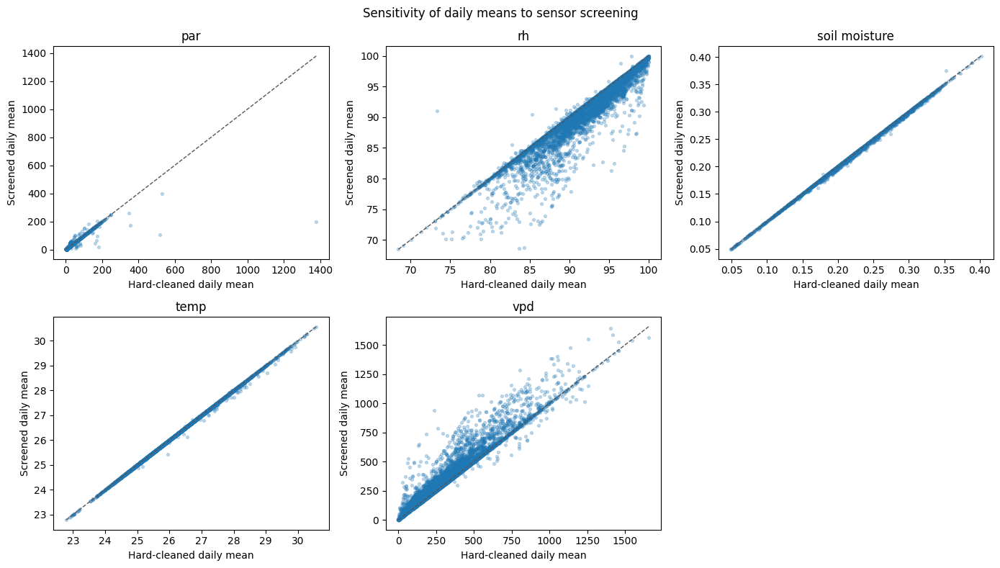

,param,paired_plot_days,median_absolute_difference,p95_absolute_difference,spearman_rho
0,par,2862.0,0.0000,0.9939,0.9953
1,rh,4841.0,0.4919,5.2105,0.9539
2,soil moisture,2662.0,0.0000,0.0039,0.9996
3,temp,4852.0,0.0000,0.0000,0.9999
4,vpd,4846.0,18.0420,210.9170,0.9622


In [14]:
# Compare daily means from the hard-cleaned and analysis-screened tiers.
QUALITY_OUT = Path(OUT_ROOT) / 'quality'
QUALITY_OUT.mkdir(parents=True, exist_ok=True)

def daily_tier(frame, name):
    daily = (
        frame.assign(date=pd.to_datetime(frame['time']).dt.normalize())
        .groupby(['plot', 'date', 'param'], as_index=False)
        .agg(daily_mean=('value', 'mean'), observations=('value', 'size'))
    )
    return daily.rename(columns={'daily_mean': f'{name}_daily_mean', 'observations': f'{name}_observations'})

hard_daily = daily_tier(df_hard_clean, 'hard_clean')
screened_daily = daily_tier(df_analysis_screened, 'screened')
screening_pairs = hard_daily.merge(screened_daily, on=['plot', 'date', 'param'], how='inner')
screening_pairs['absolute_difference'] = (
    screening_pairs['screened_daily_mean'] - screening_pairs['hard_clean_daily_mean']
).abs()

screening_sensitivity = (
    screening_pairs.groupby('param', as_index=False)
    .apply(lambda group: pd.Series({
        'paired_plot_days': len(group),
        'median_absolute_difference': group['absolute_difference'].median(),
        'p95_absolute_difference': group['absolute_difference'].quantile(0.95),
        'spearman_rho': group[['hard_clean_daily_mean', 'screened_daily_mean']].corr(method='spearman').iloc[0, 1],
    }), include_groups=False)
    .reset_index(drop=True)
)
data_tier_summary.to_csv(QUALITY_OUT / 'data_tier_summary.csv', index=False)
screening_sensitivity.to_csv(QUALITY_OUT / 'screening_sensitivity_daily_means.csv', index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for axis, parameter in zip(axes.flat, sorted(screening_pairs['param'].unique())):
    sample = screening_pairs[screening_pairs['param'] == parameter]
    axis.scatter(sample['hard_clean_daily_mean'], sample['screened_daily_mean'], s=8, alpha=0.25)
    limits = [sample[['hard_clean_daily_mean', 'screened_daily_mean']].min().min(),
              sample[['hard_clean_daily_mean', 'screened_daily_mean']].max().max()]
    axis.plot(limits, limits, '--', color='#555555', linewidth=1)
    axis.set_title(parameter)
    axis.set_xlabel('Hard-cleaned daily mean')
    axis.set_ylabel('Screened daily mean')
axes.flat[-1].axis('off')
fig.suptitle('Sensitivity of daily means to sensor screening')
fig.tight_layout()
fig.savefig(QUALITY_OUT / 'screening_sensitivity_daily_means.png', dpi=180, bbox_inches='tight')
plt.show()

display(screening_sensitivity.round(4))

### 1.3 Cleaning audit and quality review


In [15]:
final_count = len(df_clean)
total_removed = initial_count - final_count
removal_percentage = (total_removed / initial_count) * 100

print("=" * 50)
print("CLEANING SUMMARY")
print("=" * 50)
print(f"  Initial rows:     {initial_count:,}")
print(f"  Final rows:       {final_count:,}")
print(f"  Total removed:    {total_removed:,} ({removal_percentage:.2f}%)")
print(f"  Rows retained with review flags: {df_clean['quality_flag'].sum():,}")

print("\n--- Breakdown of removed rows ---")
for reason, count in removed_counts.items():
    pct = (count / initial_count) * 100
    print(f"  {reason}: {count:,} ({pct:.2f}%)")


CLEANING SUMMARY
  Initial rows:     1,002,949
  Final rows:       1,002,899
  Total removed:    50 (0.00%)
  Rows retained with review flags: 82,683

--- Breakdown of removed rows ---
  Missing required value or timestamp: 40 (0.00%)
  Soil moisture above 0.6 m3/m3: 10 (0.00%)


In [16]:
# Final data distribution by parameter
print("--- Final Data by Parameter ---")
final_param_counts = df_clean['param'].value_counts()
for param, count in final_param_counts.items():
    print(f"  - {param}: {count:,} rows")


--- Final Data by Parameter ---
  - rh: 261,090 rows
  - temp: 261,056 rows
  - vpd: 261,053 rows
  - par: 156,704 rows
  - soil moisture: 62,996 rows


### 1.4 Summary statistics after cleaning


In [17]:
print("--- Basic Statistics (cleaned data) ---")
for param in [TEMPERATURE_PARAM, HUMIDITY_PARAM, SOIL_MOISTURE_PARAM]:
    subset = df_clean[df_clean['param'] == param]['value']
    if len(subset) > 0:
        print(f"\n{param.upper()}:")
        print(f"  Min:    {subset.min():.2f}")
        print(f"  Max:    {subset.max():.2f}")
        print(f"  Mean:   {subset.mean():.2f}")
        print(f"  Median: {subset.median():.2f}")
        print(f"  Std:    {subset.std():.2f}")


--- Basic Statistics (cleaned data) ---

TEMP:
  Min:    19.62
  Max:    46.07
  Mean:   26.39
  Median: 25.63
  Std:    2.66



RH:
  Min:    1.00
  Max:    100.00
  Mean:   91.12


  Median: 94.65
  Std:    10.36



SOIL MOISTURE:
  Min:    0.00
  Max:    0.47
  Mean:   0.21
  Median: 0.21
  Std:    0.06


### 1.5 Save the analysis-screened dataset


In [18]:
output_file = PROCESSED_DATA_PATH / 'microclimate_data_cleaned.csv'
df.to_csv(output_file, index=False)
print(f"✓ Primary analysis dataset saved to: {output_file}")
print("\n" + "=" * 50)
print("Data cleaning complete!")
print("=" * 50)


✓ Primary analysis dataset saved to: /Users/siddharthchoudhary09/Desktop/fyp_project/data/processed/microclimate_data_cleaned.csv

Data cleaning complete!


## 2. Exploratory data analysis: distributions by site

The following daily summaries compare the seven plots for temperature, relative humidity, VPD, PAR, and soil moisture. Values are shown by plot so differences are visible without implying a causal forest-type effect.


### 2.1 Visualisation setup


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Convert time column to datetime (handle mixed formats)
df['time'] = pd.to_datetime(df['time'], format='mixed')

print("✓ Visualization libraries loaded")
print(f"Date range: {df['time'].min()} to {df['time'].max()}")


✓ Visualization libraries loaded
Date range: 2024-08-14 11:00:00 to 2026-08-24 10:00:00


### 2.2 Create a plot-aligned analysis table

Convert from long format to wide format for easier analysis and modeling.


In [20]:
# Pivot the data to wide format (one column per parameter)
df_wide = df.pivot_table(
    index=['time', 'plot', 'ft', 'stage', 'sensor'],
    columns='param',
    values='value',
    aggfunc='mean'
).reset_index()

# Flatten column names
df_wide.columns.name = None

print(f"Wide format shape: {df_wide.shape}")
print(f"\nColumns: {list(df_wide.columns)}")
df_wide.head()


Wide format shape: (178057, 10)

Columns: ['time', 'plot', 'ft', 'stage', 'sensor', 'par', 'rh', 'soil moisture', 'temp', 'vpd']


,time,plot,ft,stage,sensor,par,rh,soil moisture,temp,vpd
0,2024-08-14 11:00:00,LP3,FT3,Secondary forest,HOBO,NaN,46.921,0.1652,26.513,1838.631861
1,2024-08-14 11:00:00,LP3,FT3,Secondary forest,iButton,NaN,82.263,NaN,29.076,713.448977
2,2024-08-14 12:00:00,LP3,FT3,Secondary forest,HOBO,101.2,92.454,0.1666,27.231,272.646415
3,2024-08-14 12:00:00,LP3,FT3,Secondary forest,iButton,NaN,85.601,NaN,28.576,562.665528
4,2024-08-14 13:00:00,FT4TH,FT4,Primary forest,iButton,NaN,86.241,NaN,28.575,537.625266


### 2.3 Temperature by plot


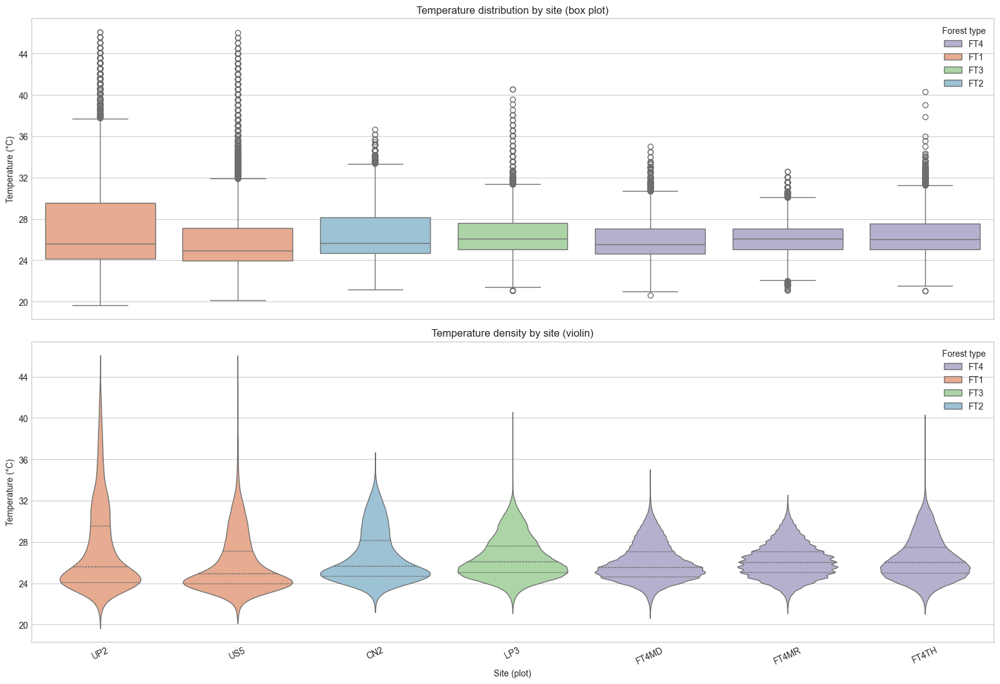

In [21]:
# Temperature distribution by site (plot-level box and violin)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# filter temperature
temp_data = df[df['param'].str.contains('temp', case=False, na=False)].copy()
temp_data['plot'] = temp_data['plot'].fillna('Unknown')
# ensure datetime (mixed formats)
temp_data['time'] = pd.to_datetime(temp_data['time'], format='mixed', errors='coerce')
temp_data = temp_data.dropna(subset=['time'])

# Explicit site order (FT1→FT4)
site_order = [
    'UP2', 'US5',  # FT1
    'CN2',          # FT2
    'LP3',          # FT3
    'FT4MD', 'FT4MR', 'FT4TH'  # FT4
]
site_order = [s for s in site_order if s in temp_data['plot'].unique()]

palette = {
    'FT1': '#f4a582',  # mild orange
    'FT2': '#92c5de',  # mild blue
    'FT3': '#a6dba0',  # mild green
    'FT4': '#b2abd2',  # mild purple
}

# Box and violin plots by site (larger, clearer)
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

sns.boxplot(
    data=temp_data,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[0], palette=palette,
    showfliers=True,
)
axes[0].set_xlabel('')
axes[0].set_ylabel('Temperature (°C)')
axes[0].set_title('Temperature distribution by site (box plot)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_locator(MaxNLocator(8))
axes[0].legend(title='Forest type', loc='upper right')

sns.violinplot(
    data=temp_data,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[1], palette=palette,
    cut=0, inner='quartile', linewidth=1
)
axes[1].set_xlabel('Site (plot)')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_title('Temperature density by site (violin)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].yaxis.set_major_locator(MaxNLocator(8))
axes[1].legend(title='Forest type', loc='upper right')

plt.tight_layout()
distribution_figure_path = Path(OUT_ROOT) / 'temperature/temp_A_daily_mean_faceted.png'
distribution_figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(distribution_figure_path, dpi=180, bbox_inches='tight')
plt.show()


**Figure 2.1 — Daily temperature distribution by plot.**  
*Source: quality-screened full RData, aggregated to daily means. The plot is descriptive; it does not test a causal canopy effect.*

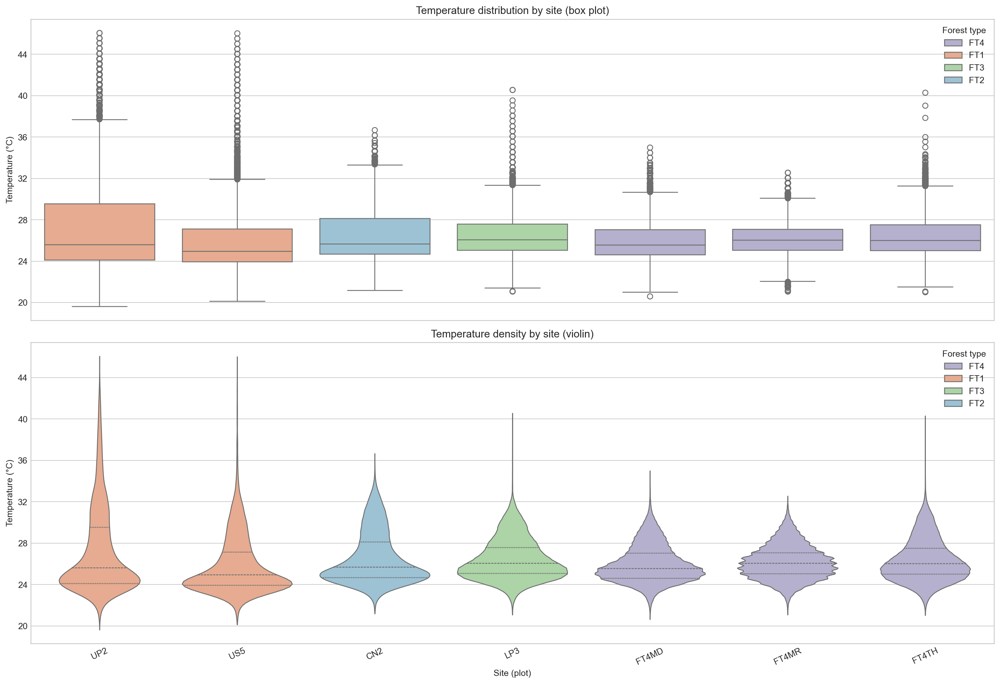

In [22]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'temperature/temp_A_daily_mean_faceted.png'
display(Markdown("**Figure 2.1 — Daily temperature distribution by plot.**  \n*Source: quality-screened full RData, aggregated to daily means. The plot is descriptive; it does not test a causal canopy effect.*"))
display(Image(filename=str(figure_path)))


### Analysis: Temperature by Site (Plot-Level)

#### Context for reading the plot
- FT1 (open/edge): ~27–29°C daily mean, widest spread.
- FT2: ~26–28°C.
- FT3: ~25–27°C.
- FT4 (primary): ~24–26°C, tightest spread.

#### Results from the full RData run
| Site | FT | Daily mean (°C) |
|------|----|-----------------|
| UP2 | FT1 | 27.15 |
| US5 | FT1 | 25.95 |
| CN2 | FT2 | 26.46 |
| LP3 | FT3 | 26.46 |
| FT4MD | FT4 | 26.04 |
| FT4MR | FT4 | 25.99 |
| FT4TH | FT4 | 26.36 |

- In this run, the broad ordering is: FT1 > FT2/FT3 > FT4, although `US5` is cooler than a typical FT1 and the FT4 sites sit slightly above the nominal reference band.

#### How to read the chart
- `UP2` has the broadest warm tail. Its middle 50% sits around **24.13-29.12°C**, and about **3.76%** of readings lie above the upper whisker (**36.62°C**), which fits strong daytime heating.
- `US5` is still variable, but its box is narrower than `UP2` (**24.07-27.29°C**). The upper tail is still clear, with about **3.99%** of readings above **32.12°C**.
- `CN2` and `LP3` sit in the middle. `CN2` has a fairly balanced box (**24.63-28.13°C**), while `LP3` is slightly warmer in its center (**median 26.08°C**) and shows a modest warm tail.
- The FT4 sites are tighter overall. `FT4MR` is the narrowest of the group (**24.92-27.07°C**), while `FT4TH` is a little broader and warmer, which is why its recorded range is wider than `FT4MR`.
- The violins support the same reading: FT1 spreads farther into the hot end, while FT4 stays denser around the mid-20s.

#### Comparison with the contextual ranges
| Site | FT | Expected band (°C) | Observed mean (°C) | Mean - expected mid (°C) | Assessment |
|------|----|--------------------|--------------------|---------------------------|------------|
| UP2  | FT1 | 27-29 | 27.15 | -0.85 | Near expected |
| US5  | FT1 | 27-29 | 25.95 | -2.05 | Cooler than FT1 norm |
| CN2  | FT2 | 26-28 | 26.46 | -0.54 | Within band |
| LP3  | FT3 | 25-27 | 26.46 | +0.46 | Within band |
| FT4MD | FT4 | 24-26 | 26.04 | +1.04 | Slightly warm but still coolest group |
| FT4MR | FT4 | 24-26 | 25.99 | +0.99 | Slightly warm but still coolest group |
| FT4TH | FT4 | 24-26 | 26.36 | +1.36 | Slightly warm but still coolest group |

#### Takeaway
Taken together, the temperature plots show clear differences across the monitored plots. `UP2` recorded the warmest and widest distribution, while the FT4 plots were generally cooler and less variable. These differences are consistent with the site descriptions, but this observational dataset cannot separate canopy effects from sensor placement and other local conditions.


### 2.4 Relative humidity by plot


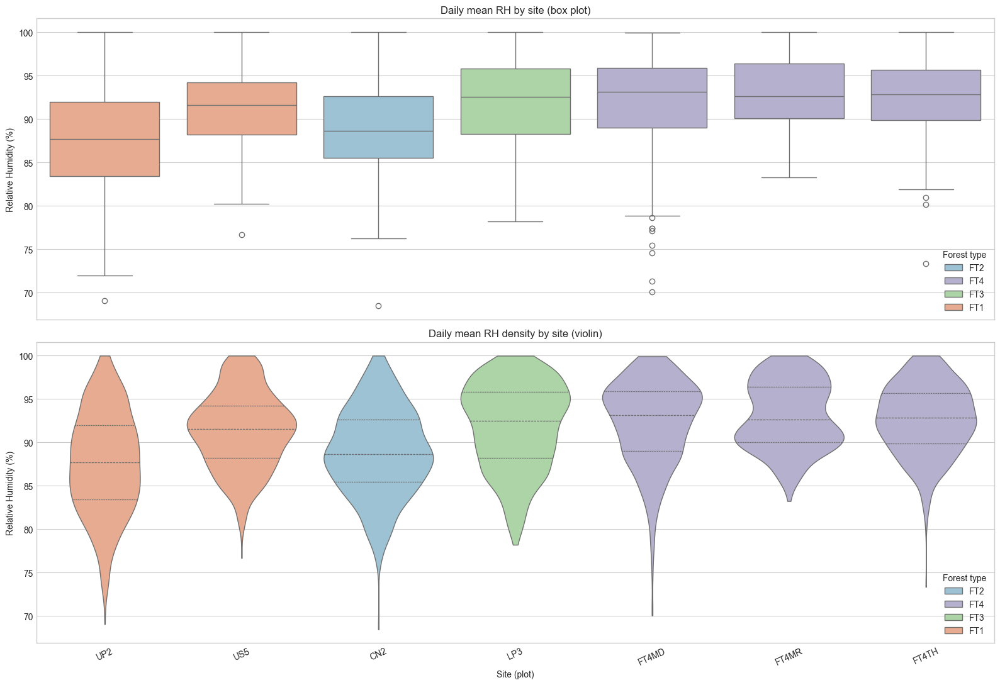

In [23]:
# Relative Humidity (RH) by site: daily-mean box and violin plots
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

rh_data = df[df['param'] == 'rh'].copy()
rh_data['plot'] = rh_data['plot'].fillna('Unknown')
rh_data['time'] = pd.to_datetime(rh_data['time'], format='mixed', errors='coerce')
rh_data['value'] = pd.to_numeric(rh_data['value'], errors='coerce')
rh_data = rh_data.dropna(subset=['time', 'value'])

# Clamp to physical bounds and drop impossible values
rh_data = rh_data[(rh_data['value'] >= 0) & (rh_data['value'] <= 100)].copy()

site_order = [
    'UP2', 'US5',  # FT1
    'CN2',         # FT2
    'LP3',         # FT3
    'FT4MD', 'FT4MR', 'FT4TH'  # FT4
]
site_order = [s for s in site_order if s in rh_data['plot'].unique()]

palette = {
    'FT1': '#f4a582',
    'FT2': '#92c5de',
    'FT3': '#a6dba0',
    'FT4': '#b2abd2',
}

# === Daily mean by site ===
site_daily = (
    rh_data.set_index('time')
    .groupby('plot')['value']
    .resample('D')
    .mean()
    .reset_index()
)
plot_to_ft = rh_data[['plot', 'ft']].drop_duplicates().set_index('plot')['ft']
site_daily['ft'] = site_daily['plot'].map(plot_to_ft)
site_daily['roll7'] = site_daily.groupby('plot')['value'].transform(lambda s: s.rolling(7, min_periods=1).mean())

# Box and violin plots by site (daily means)
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

sns.boxplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[0], palette=palette,
    showfliers=True,
)
axes[0].set_xlabel('')
axes[0].set_ylabel('Relative Humidity (%)')
axes[0].set_title('Daily mean RH by site (box plot)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_locator(MaxNLocator(8))
axes[0].legend(title='Forest type', loc='lower right')

sns.violinplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[1], palette=palette,
    cut=0, inner='quartile', linewidth=1
)
axes[1].set_xlabel('Site (plot)')
axes[1].set_ylabel('Relative Humidity (%)')
axes[1].set_title('Daily mean RH density by site (violin)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].yaxis.set_major_locator(MaxNLocator(8))
axes[1].legend(title='Forest type', loc='lower right')

plt.tight_layout()
distribution_figure_path = Path(OUT_ROOT) / 'rh/rh_A_daily_mean_faceted.png'
distribution_figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(distribution_figure_path, dpi=180, bbox_inches='tight')
plt.show()


**Figure 2.2 — Daily relative-humidity distribution by plot.**  
*Source: quality-screened full RData, aggregated to daily means. Compare the centre and spread of each plot rather than treating the groups as experimental treatments.*

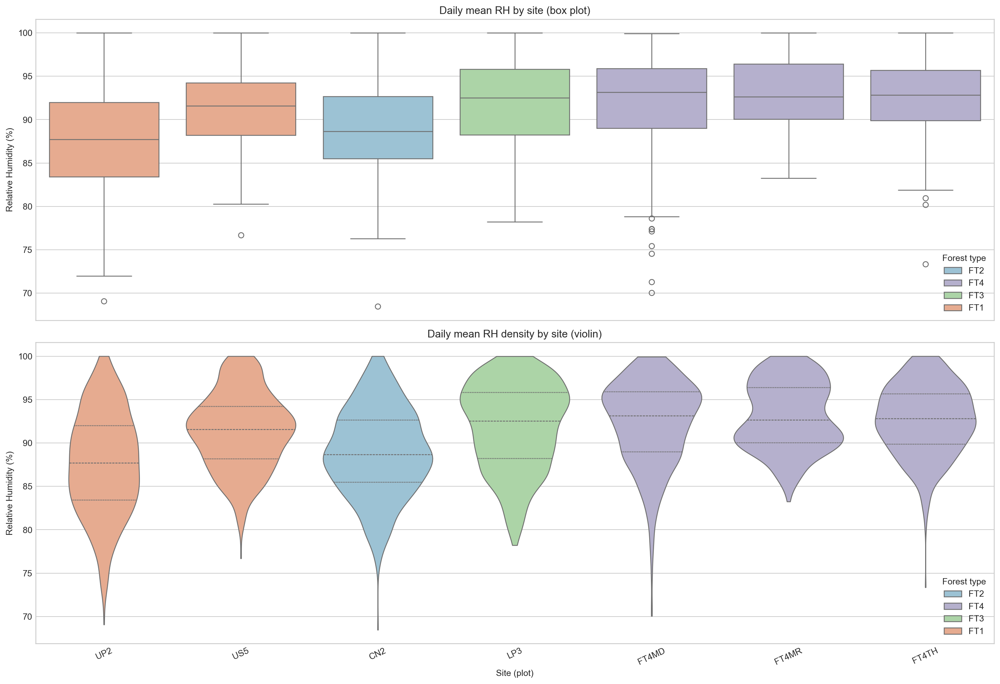

In [24]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'rh/rh_A_daily_mean_faceted.png'
display(Markdown("**Figure 2.2 — Daily relative-humidity distribution by plot.**  \n*Source: quality-screened full RData, aggregated to daily means. Compare the centre and spread of each plot rather than treating the groups as experimental treatments.*"))
display(Image(filename=str(figure_path)))


### Analysis: Relative Humidity by Site (Daily Mean)

#### Context for reading the plot
- FT1 (open/edge): ~75-90% daily mean RH, widest spread (daytime dips).
- FT2: ~80-92%.
- FT3: ~82-94%.
- FT4 (primary): ~85-96%, with the tightest recorded spread.

#### Results from the full RData run
| Site | FT | Daily mean RH (%) |
|------|----|-------------------|
| UP2 | FT1 | 88.95 |
| US5 | FT1 | 91.84 |
| CN2 | FT2 | 90.97 |
| LP3 | FT3 | 92.22 |
| FT4MD | FT4 | 92.32 |
| FT4MR | FT4 | 94.38 |
| FT4TH | FT4 | 92.51 |

- In this run, the broad ordering is: FT1 is lower and more variable, FT4 is higher and more stable, and FT2/FT3 sit in between.

#### How to read the chart
- `UP2` has the broadest RH box, with the middle 50% around **84.48-93.11%**. That wider spread matches repeated daytime drying.
- `US5` shifts upward but still keeps a broad shape (**88.28-95.43%**), so it is humid overall but more variable than FT4.
- `CN2` and `LP3` sit in the middle band. Their violins are fuller around the low-90s, which records a more stable humid background than FT1 without the same saturation frequency.
- `FT4MR` has the highest and narrowest RH distribution here. Its IQR is **91.51-97.09%** and its median is **94.66%**. Canopy may contribute, but the plot comparison alone cannot establish that cause.
- `FT4MD` and `FT4TH` stay humid too, but both still show a few low-end excursions, so they do not look quite as stable as `FT4MR`.

#### Comparison with the contextual ranges
| Site | FT | Expected band (%) | Observed mean (%) | Mean - expected mid (%) | Assessment |
|------|----|-------------------|-------------------|-------------------------|------------|
| UP2  | FT1 | 75-90 | 88.95 | +6.45 | Within band (upper) |
| US5  | FT1 | 75-90 | 91.84 | +9.34 | Slightly above band |
| CN2  | FT2 | 80-92 | 90.97 | +4.97 | Within band |
| LP3  | FT3 | 82-94 | 92.22 | +4.22 | Within band |
| FT4MD | FT4 | 85-96 | 92.32 | +1.82 | Within band |
| FT4MR | FT4 | 85-96 | 94.38 | +3.88 | Within band (upper) |
| FT4TH | FT4 | 85-96 | 92.51 | +2.01 | Within band |

#### Takeaway
The RH plots tell the same forest-structure story as temperature, but from the opposite direction. FT1 loses humidity more easily, while FT4 holds a much more saturated and stable air column. In practical terms, this means the shaded sites are not just cooler; they are also recorded lower daytime atmospheric drying.


### 2.5 Vapour pressure deficit by plot


Converted VPD from Pa to kPa for analysis.


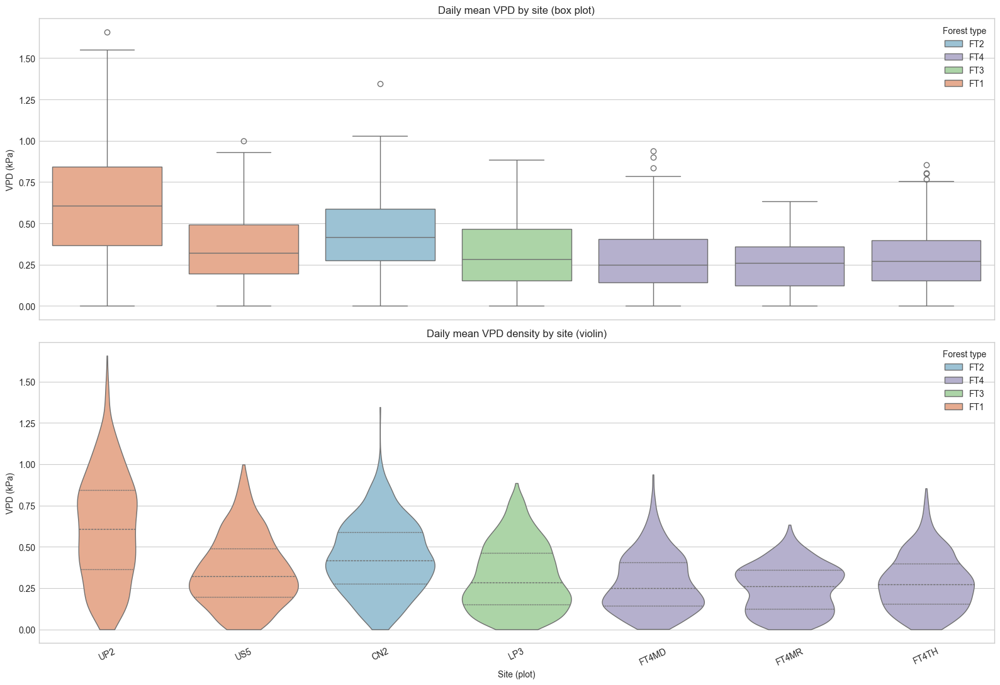

In [25]:
# Vapor Pressure Deficit (VPD) by site: daily-mean box and violin plots
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

vpd_data = df[df['param'] == 'vpd'].copy()
vpd_data['plot'] = vpd_data['plot'].fillna('Unknown')
vpd_data['time'] = pd.to_datetime(vpd_data['time'], format='mixed', errors='coerce')
vpd_data['value'] = pd.to_numeric(vpd_data['value'], errors='coerce')
vpd_data = vpd_data.dropna(subset=['time', 'value'])

# Clamp to physical bounds (VPD cannot be negative)
vpd_data = vpd_data[vpd_data['value'] >= 0].copy()

# Convert to kPa if values appear to be in Pa
if vpd_data['value'].max() > 10:
    vpd_data['value'] = vpd_data['value'] / 1000
    print('Converted VPD from Pa to kPa for analysis.')

site_order = [
    'UP2', 'US5',  # FT1
    'CN2',         # FT2
    'LP3',         # FT3
    'FT4MD', 'FT4MR', 'FT4TH'  # FT4
]
site_order = [s for s in site_order if s in vpd_data['plot'].unique()]

palette = {
    'FT1': '#f4a582',
    'FT2': '#92c5de',
    'FT3': '#a6dba0',
    'FT4': '#b2abd2',
}
site_colors = dict(zip(site_order, sns.color_palette('tab10', n_colors=len(site_order))))

# === Daily mean by site ===
site_daily = (
    vpd_data.set_index('time')
    .groupby('plot')['value']
    .resample('D')
    .mean()
    .reset_index()
)
plot_to_ft = vpd_data[['plot', 'ft']].drop_duplicates().set_index('plot')['ft']
site_daily['ft'] = site_daily['plot'].map(plot_to_ft)
site_daily['roll7'] = site_daily.groupby('plot')['value'].transform(lambda s: s.rolling(7, min_periods=1).mean())

# Box and violin plots by site (daily means)
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

sns.boxplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[0], palette=palette,
    showfliers=True,
)
axes[0].set_xlabel('')
axes[0].set_ylabel('VPD (kPa)')
axes[0].set_title('Daily mean VPD by site (box plot)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_locator(MaxNLocator(8))
axes[0].legend(title='Forest type', loc='upper right')

sns.violinplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[1], palette=palette,
    cut=0, inner='quartile', linewidth=1
)
axes[1].set_xlabel('Site (plot)')
axes[1].set_ylabel('VPD (kPa)')
axes[1].set_title('Daily mean VPD density by site (violin)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].yaxis.set_major_locator(MaxNLocator(8))
axes[1].legend(title='Forest type', loc='upper right')

plt.tight_layout()
distribution_figure_path = Path(OUT_ROOT) / 'vpd/vpd_A_daily_mean_faceted.png'
distribution_figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(distribution_figure_path, dpi=180, bbox_inches='tight')
plt.show()


**Figure 2.3 — Daily VPD distribution by plot.**  
*Source: quality-screened full RData, aggregated to daily means. VPD is interpreted as atmospheric moisture demand, not as a direct tree-health measurement.*

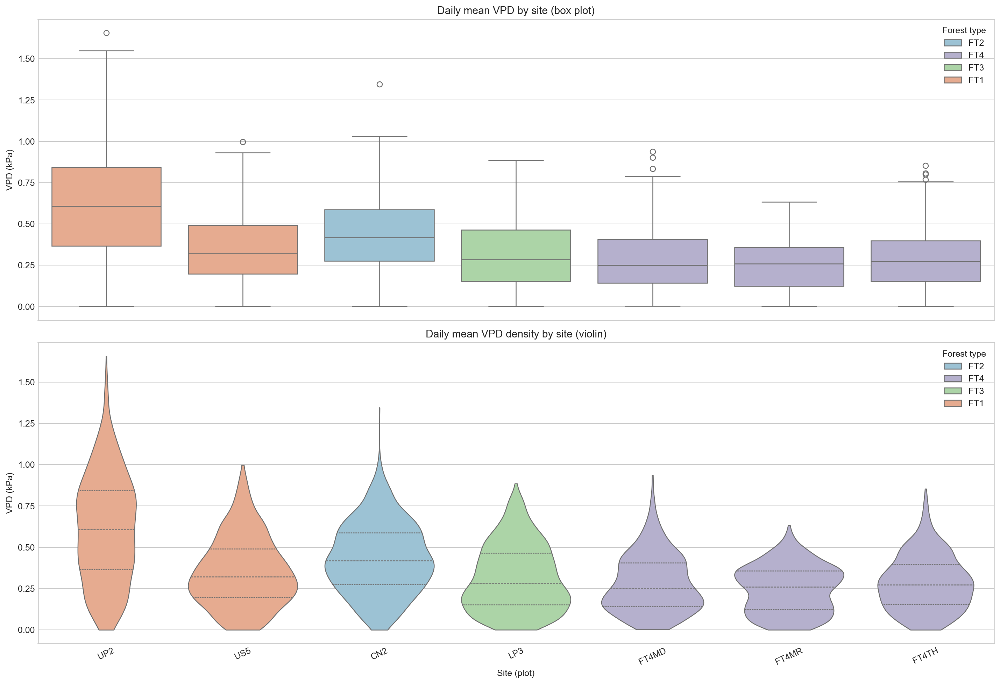

In [26]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'vpd/vpd_A_daily_mean_faceted.png'
display(Markdown("**Figure 2.3 — Daily VPD distribution by plot.**  \n*Source: quality-screened full RData, aggregated to daily means. VPD is interpreted as atmospheric moisture demand, not as a direct tree-health measurement.*"))
display(Image(filename=str(figure_path)))


### Analysis: VPD by Site (Daily Mean)

#### Context for reading the plot
- FT1 (open/edge): ~0.40-0.90 kPa daily mean VPD, widest spread (hot/dry afternoons).
- FT2: ~0.30-0.70 kPa.
- FT3: ~0.25-0.60 kPa.
- FT4 (primary): ~0.15-0.45 kPa, tightest spread (cool, humid understory).

#### Results from the full RData run
| Site | FT | Daily mean VPD (kPa) |
|------|----|----------------------|
| UP2  | FT1 | 0.545 |
| US5  | FT1 | 0.340 |
| CN2  | FT2 | 0.361 |
| LP3  | FT3 | 0.302 |
| FT4MD | FT4 | 0.277 |
| FT4MR | FT4 | 0.201 |
| FT4TH | FT4 | 0.290 |

- In this run, the ordering is: FT1 is highest and most variable, FT4 is lowest and most stable, and FT2/FT3 are intermediate.

#### How to read the chart
- `UP2` has the highest and broadest VPD box, with its middle 50% around **0.30-0.80 kPa** and a median near **0.53 kPa**. That is the clearest sign of stronger evaporative demand.
- `US5` is still an FT1 site, but its box sits lower (**0.16-0.50 kPa**), which matches the cooler and more humid reading seen earlier.
- `CN2` and `LP3` stay in the mid-range. `CN2` is slightly higher than `LP3`, so it looks a bit more exposed from a drying-demand point of view.
- `FT4MR` again has the tightest low-VPD distribution. Its IQR is only **0.10-0.30 kPa**, and the violin stays concentrated low in the distribution.
- `FT4MD` and `FT4TH` are still low-VPD sites overall, but their boxes are a little broader than `FT4MR`, which suggests some canopy opening or intermittent drying pulses.

#### Comparison with the contextual ranges
| Site | FT | Expected band (kPa) | Observed mean (kPa) | Mean - expected mid (kPa) | Assessment |
|------|----|----------------------|---------------------|---------------------------|------------|
| UP2  | FT1 | 0.40-0.90 | 0.545 | -0.105 | Within band (upper half) |
| US5  | FT1 | 0.40-0.90 | 0.340 | -0.310 | Slightly below band |
| CN2  | FT2 | 0.30-0.70 | 0.361 | -0.139 | Within band (lower half) |
| LP3  | FT3 | 0.25-0.60 | 0.302 | -0.123 | Slightly below band |
| FT4MD | FT4 | 0.15-0.45 | 0.277 | -0.023 | Within band |
| FT4MR | FT4 | 0.15-0.45 | 0.201 | -0.099 | Within band (lower) |
| FT4TH | FT4 | 0.15-0.45 | 0.290 | -0.010 | Within band |

#### Takeaway
VPD gives the clearest summary of atmospheric moisture demand in one variable. The ranking is simple: `UP2` records the highest atmospheric demand and `FT4MR` the lowest, and the other plots fall between those two ends. That makes VPD useful for comparing atmospheric demand with later soil-moisture behaviour, without treating canopy as a confirmed cause.


### 2.6 Light availability (PAR) by plot


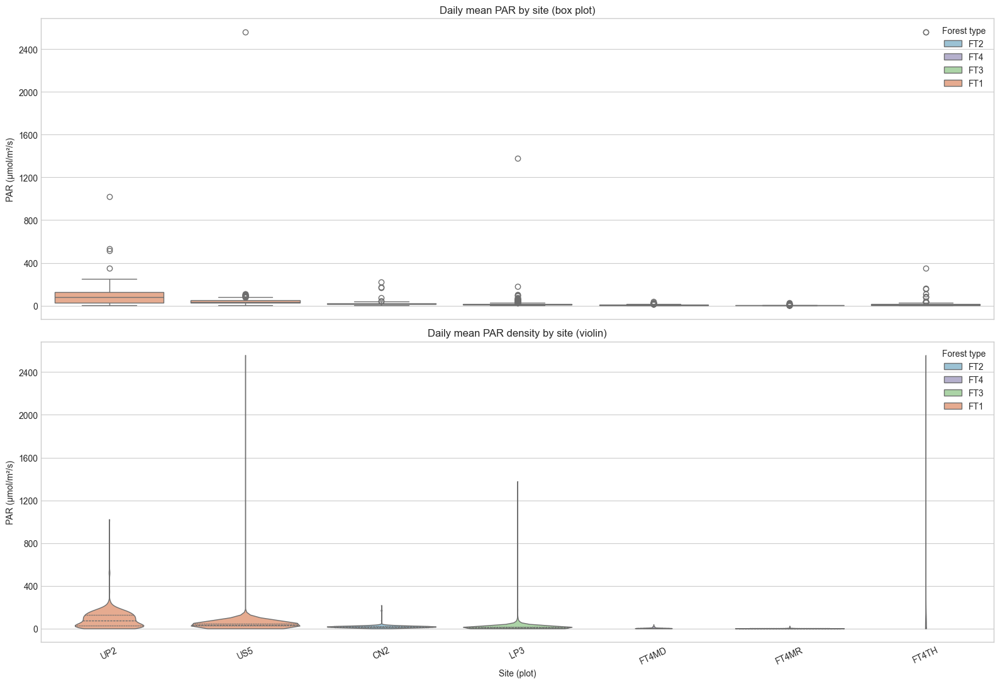

In [27]:
# Photosynthetically Active Radiation (PAR) by site: daily-mean box and violin plots
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

par_data = df[df['param'] == 'par'].copy()
par_data['plot'] = par_data['plot'].fillna('Unknown')
par_data['time'] = pd.to_datetime(par_data['time'], format='mixed', errors='coerce')
par_data['value'] = pd.to_numeric(par_data['value'], errors='coerce')
par_data = par_data.dropna(subset=['time', 'value'])

# PAR cannot be negative
par_data = par_data[par_data['value'] >= 0].copy()

site_order = [
    'UP2', 'US5',  # FT1
    'CN2',         # FT2
    'LP3',         # FT3
    'FT4MD', 'FT4MR', 'FT4TH'  # FT4
]
site_order = [s for s in site_order if s in par_data['plot'].unique()]

palette = {
    'FT1': '#f4a582',
    'FT2': '#92c5de',
    'FT3': '#a6dba0',
    'FT4': '#b2abd2',
}
site_colors = dict(zip(site_order, sns.color_palette('tab10', n_colors=len(site_order))))

# === Daily mean by site ===
site_daily = (
    par_data.set_index('time')
    .groupby('plot')['value']
    .resample('D')
    .mean()
    .reset_index()
)
plot_to_ft = par_data[['plot', 'ft']].drop_duplicates().set_index('plot')['ft']
site_daily['ft'] = site_daily['plot'].map(plot_to_ft)
site_daily['roll7'] = site_daily.groupby('plot')['value'].transform(lambda s: s.rolling(7, min_periods=1).mean())

# Box and violin plots by site (daily means)
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

sns.boxplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[0], palette=palette,
    showfliers=True,
)
axes[0].set_xlabel('')
axes[0].set_ylabel('PAR (μmol/m²/s)')
axes[0].set_title('Daily mean PAR by site (box plot)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_locator(MaxNLocator(8))
axes[0].legend(title='Forest type', loc='upper right')

sns.violinplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[1], palette=palette,
    cut=0, inner='quartile', linewidth=1
)
axes[1].set_xlabel('Site (plot)')
axes[1].set_ylabel('PAR (μmol/m²/s)')
axes[1].set_title('Daily mean PAR density by site (violin)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].yaxis.set_major_locator(MaxNLocator(8))
axes[1].legend(title='Forest type', loc='upper right')

plt.tight_layout()
distribution_figure_path = Path(OUT_ROOT) / 'par/par_A_daily_mean_faceted.png'
distribution_figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(distribution_figure_path, dpi=180, bbox_inches='tight')
plt.show()


**Figure 2.4 — Daily PAR distribution by plot.**  
*Source: quality-screened full RData, aggregated to daily means. PAR records describe sensor-level light conditions and should be read alongside deployment coverage.*

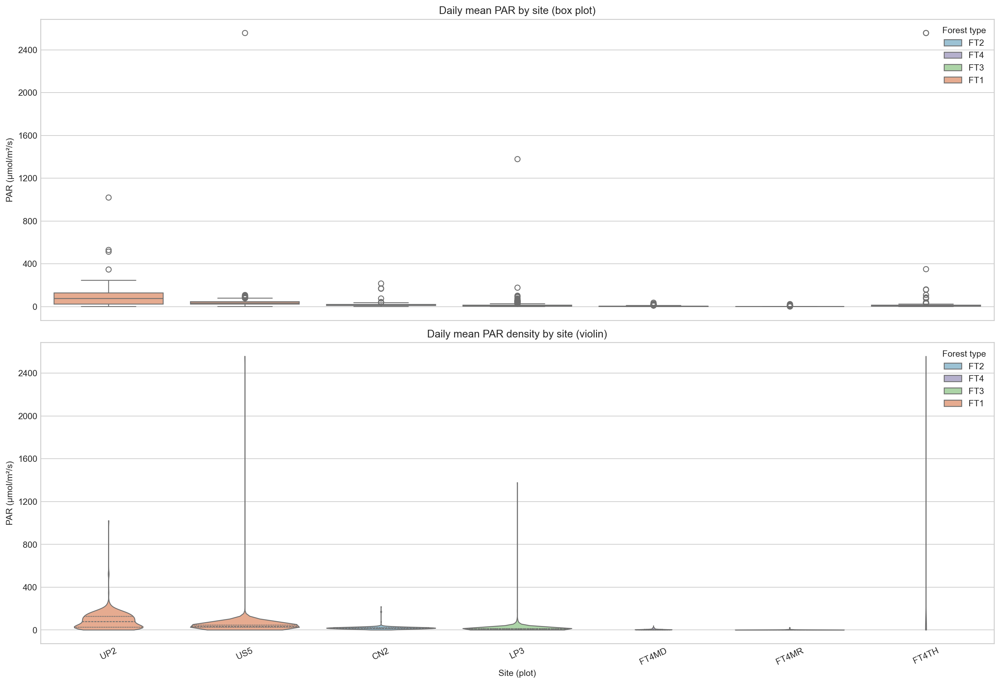

In [28]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'par/par_A_daily_mean_faceted.png'
display(Markdown("**Figure 2.4 — Daily PAR distribution by plot.**  \n*Source: quality-screened full RData, aggregated to daily means. PAR records describe sensor-level light conditions and should be read alongside deployment coverage.*"))
display(Image(filename=str(figure_path)))


### Analysis: PAR by Site (Daily Mean)

#### Context for reading the plot
- FT1 (open/edge): Daily mean PAR ~30-120 μmol/m²/s (largest spread).
- FT2: ~10-50 μmol/m²/s.
- FT3: ~5-30 μmol/m²/s.
- FT4 (primary): ~2-20 μmol/m²/s (tightest distribution).

#### Results from the full RData run
| Site | FT | Daily mean PAR (μmol/m²/s) |
|------|----|-----------------------------|
| UP2  | FT1 | 92.12 |
| US5  | FT1 | 46.29 |
| CN2  | FT2 | 19.06 |
| LP3  | FT3 | 18.64 |
| FT4MD | FT4 | 5.07 |
| FT4MR | FT4 | 2.50 |
| FT4TH | FT4 | 47.08 |

- Most sites fall within the contextual ranges; `FT4TH`, which is much brighter than a typical FT4 site.

#### How to read the chart
- `UP2` has the broadest light distribution by far. Its IQR is **30.08-140.36 μmol/m²/s**, and the violin keeps stretching upward, which is consistent with its more open site description.
- `US5` is still bright, but it is more moderate than `UP2`. Its central band is much narrower (**25.47-49.74 μmol/m²/s**), which suggests fewer consistently bright days.
- `CN2` and `LP3` have similar means, but their shapes differ. `CN2` is more compact, while `LP3` has a stronger right tail and more high-end days, which looks like intermittent sunflecks rather than uniformly high light.
- `FT4MD` and `FT4MR` behave like shaded forest interior sites, especially `FT4MR`, whose IQR is only **1.56-2.64 μmol/m²/s**.
- `FT4TH` is the outlier that changes the story. Its median is still low, but the upper tail is too large for a typical FT4 profile, which is consistent with a gap, edge, or different sensor position, although the data cannot distinguish these explanations.

#### Comparison with the contextual ranges
| Site | FT | Expected band (μmol/m²/s) | Observed mean (μmol/m²/s) | Mean - expected mid | Assessment |
|------|----|----------------------------|----------------------------|---------------------|------------|
| UP2  | FT1 | 30-120 | 92.12 | +17.12 | Within band (upper) |
| US5  | FT1 | 30-120 | 46.29 | -28.71 | Within band (lower) |
| CN2  | FT2 | 10-50 | 19.06 | -10.94 | Within band |
| LP3  | FT3 | 5-30 | 18.64 | +1.14 | Within band |
| FT4MD | FT4 | 2-20 | 5.07 | -5.93 | Within band |
| FT4MR | FT4 | 2-20 | 2.50 | -8.50 | Within band |
| FT4TH | FT4 | 2-20 | 47.08 | +36.08 | Above expected (sunflecks/exposure) |

#### Takeaway
PAR gives the clearest separation among plots in the exploratory set. It separates open, intermediate, and shaded sites very strongly, and it also flags where the site label alone is not telling the full story. In that sense, `FT4TH` is important: its recorded light distribution resembles the brighter plots more than the other FT4 plots.


### 2.7 Soil moisture by plot


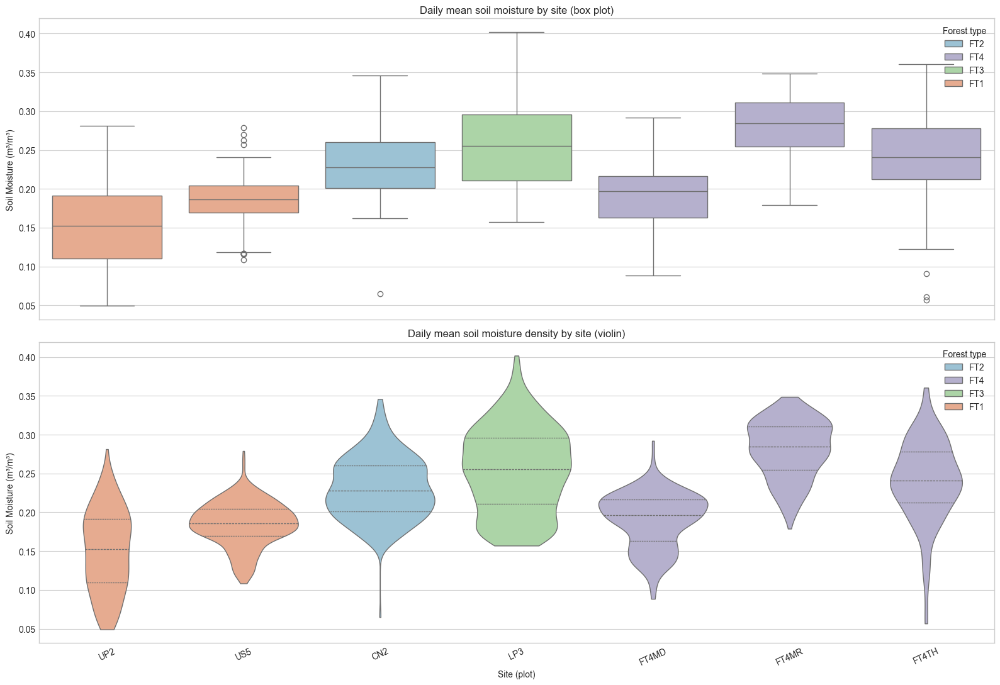

In [29]:
# Soil Moisture by site: daily-mean box and violin plots
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

soil_data = df[df['param'] == 'soil moisture'].copy()
soil_data['plot'] = soil_data['plot'].fillna('Unknown')
soil_data['time'] = pd.to_datetime(soil_data['time'], format='mixed', errors='coerce')
soil_data['value'] = pd.to_numeric(soil_data['value'], errors='coerce')
soil_data = soil_data.dropna(subset=['time', 'value'])

# Keep plausible bounds (soil moisture as volumetric water content)
soil_data = soil_data[(soil_data['value'] >= 0) & (soil_data['value'] <= 1.0)].copy()

site_order = [
    'UP2', 'US5',  # FT1
    'CN2',         # FT2
    'LP3',         # FT3
    'FT4MD', 'FT4MR', 'FT4TH'  # FT4
]
site_order = [s for s in site_order if s in soil_data['plot'].unique()]

palette = {
    'FT1': '#f4a582',
    'FT2': '#92c5de',
    'FT3': '#a6dba0',
    'FT4': '#b2abd2',
}
site_colors = dict(zip(site_order, sns.color_palette('tab10', n_colors=len(site_order))))

# === Daily mean by site ===
site_daily = (
    soil_data.set_index('time')
    .groupby('plot')['value']
    .resample('D')
    .mean()
    .reset_index()
)
plot_to_ft = soil_data[['plot', 'ft']].drop_duplicates().set_index('plot')['ft']
site_daily['ft'] = site_daily['plot'].map(plot_to_ft)
site_daily['roll7'] = site_daily.groupby('plot')['value'].transform(lambda s: s.rolling(7, min_periods=1).mean())

# Box and violin plots by site (daily means)
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

sns.boxplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[0], palette=palette,
    showfliers=True,
)
axes[0].set_xlabel('')
axes[0].set_ylabel('Soil Moisture (m³/m³)')
axes[0].set_title('Daily mean soil moisture by site (box plot)')
axes[0].tick_params(axis='x', rotation=25)
axes[0].yaxis.set_major_locator(MaxNLocator(8))
axes[0].legend(title='Forest type', loc='upper right')

sns.violinplot(
    data=site_daily,
    x='plot', y='value', hue='ft',
    order=site_order, dodge=False, ax=axes[1], palette=palette,
    cut=0, inner='quartile', linewidth=1
)
axes[1].set_xlabel('Site (plot)')
axes[1].set_ylabel('Soil Moisture (m³/m³)')
axes[1].set_title('Daily mean soil moisture density by site (violin)')
axes[1].tick_params(axis='x', rotation=25)
axes[1].yaxis.set_major_locator(MaxNLocator(8))
axes[1].legend(title='Forest type', loc='upper right')

plt.tight_layout()
distribution_figure_path = Path(OUT_ROOT) / 'soil/soil_A_daily_mean_faceted.png'
distribution_figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(distribution_figure_path, dpi=180, bbox_inches='tight')
plt.show()


**Figure 2.5 — Daily soil-moisture distribution by plot.**  
*Source: quality-screened full RData, aggregated to daily means. Differences describe the monitored locations; they are not a direct soil-health score.*

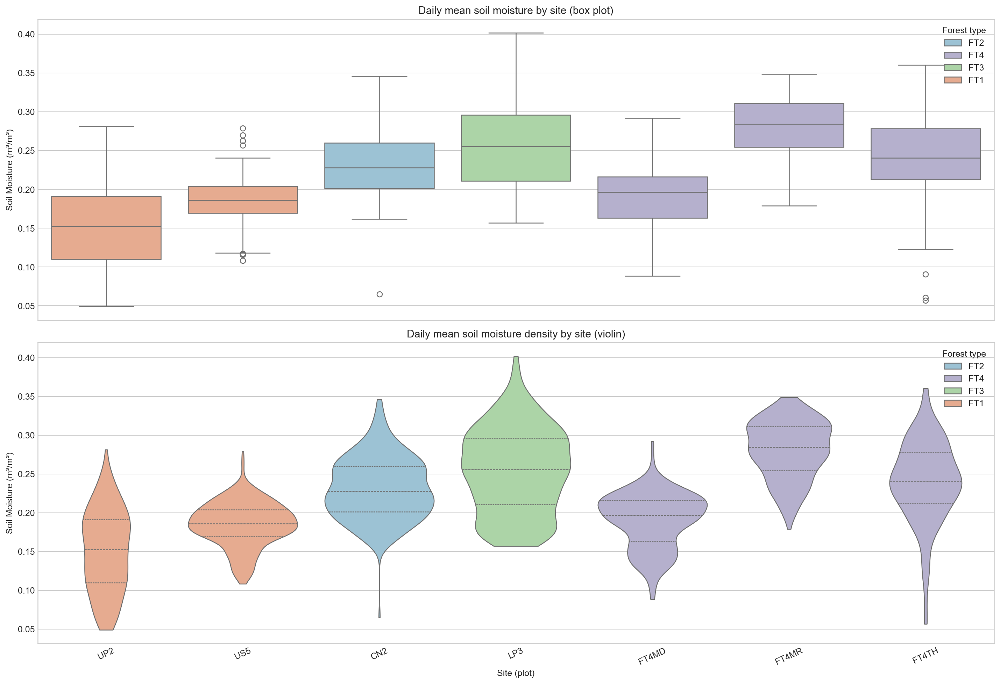

In [30]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'soil/soil_A_daily_mean_faceted.png'
display(Markdown("**Figure 2.5 — Daily soil-moisture distribution by plot.**  \n*Source: quality-screened full RData, aggregated to daily means. Differences describe the monitored locations; they are not a direct soil-health score.*"))
display(Image(filename=str(figure_path)))


### Figures: daily distributions by plot

Box-and-violin charts summarise daily observations by plot. The median is the central line; the distribution width reflects the density of daily means.

The figures below are embedded in this notebook after the analysis runs. They are also saved in `outputs/redesigned/` for use in the report.


### Distribution figure index

The five distribution figures are now placed directly after the matching temperature, humidity, VPD, PAR and soil-moisture analyses. Keeping them there makes it easier to compare each written result with its own chart.


### Analysis: Soil Moisture by Site (Daily Mean)

#### Context for reading the plot
- FT1 (open/edge): ~0.15-0.28 m³/m³ with wider spread (more drying).
- FT2: ~0.18-0.32 m³/m³.
- FT3: ~0.20-0.35 m³/m³.
- FT4 (primary): ~0.22-0.38 m³/m³, tightest recorded spread.

#### Results from the full RData run
| Site | FT | Daily mean soil moisture (m³/m³) |
|------|----|----------------------------------|
| UP2  | FT1 | 0.1667 |
| US5  | FT1 | 0.1819 |
| CN2  | FT2 | 0.2298 |
| LP3  | FT3 | 0.2554 |
| FT4MD | FT4 | 0.2023 |
| FT4MR | FT4 | 0.2813 |
| FT4TH | FT4 | 0.2396 |

- The observed pattern is: FT1 is driest, FT3/FT4 are wetter, and `FT4MR` is the wettest site.

#### How to read the chart
- `UP2` has the lowest central band, with an IQR of **0.1311-0.1998 m³/m³**. This is the clearest dry-end site in the dataset.
- `US5` is slightly wetter than `UP2`, but its box is still fairly low and it shows both low and high outliers, which suggests a more variable water balance around a generally dry baseline.
- `CN2` is a stable intermediate site. Its box is fairly compact (**0.2006-0.2588 m³/m³**) without strong outlier pressure.
- `LP3` is wetter and broader at the same time. Its IQR (**0.2172-0.2952 m³/m³**) suggests that it can hold more water, but it also moves through larger wetting and drying swings than CN2.
- `FT4MD` is the one FT4 site that sits drier than expected, with several low outliers. `FT4MR`, in contrast, has the highest and least variable soil-moisture distribution, with a high center and no outliers. `FT4TH` sits between those two.
- The violin shapes matter here because they show whether a site stays clustered around one moisture state or spreads across several. `FT4MR` is concentrated and stable, while `LP3` and the FT1 sites are more spread out.

#### Comparison with the contextual ranges
| Site | FT | Expected band (m³/m³) | Observed mean (m³/m³) | Mean - expected mid | Assessment |
|------|----|------------------------|-----------------------|---------------------|------------|
| UP2  | FT1 | 0.15-0.28 | 0.1667 | -0.0483 | Within band (lower) |
| US5  | FT1 | 0.15-0.28 | 0.1819 | -0.0331 | Within band |
| CN2  | FT2 | 0.18-0.32 | 0.2298 | -0.0202 | Within band |
| LP3  | FT3 | 0.20-0.35 | 0.2554 | -0.0196 | Within band |
| FT4MD | FT4 | 0.22-0.38 | 0.2023 | -0.0977 | Slightly below band |
| FT4MR | FT4 | 0.22-0.38 | 0.2813 | -0.0187 | Within band |
| FT4TH | FT4 | 0.22-0.38 | 0.2396 | -0.0604 | Within band |

#### Takeaway
The soil-moisture plots show that the forest gradient is visible below ground as well, but not as neatly as the atmospheric variables. `UP2` is clearly the driest end, `FT4MR` records the highest and least variable soil moisture, and `FT4MD` stands out as an FT4 site that behaves drier than expected. This shows that plot-level differences remain important even within the same forest-type class.


## 3. Data completeness and sampling coverage

Before interpreting patterns, this section checks time coverage, sampling intervals, and missing-data behaviour. The results clarify where observed patterns are reliable and where gaps may limit conclusions.


### 3.1 Data gaps and their possible impact

### Why check this first?
Data gaps in microclimate monitoring can introduce systematic biases if they are not random. For example:
- **Power failures during storms** → Missing wet weather data → Overestimation of dryness
- **Sensor overheating in sun** → Missing hot afternoon data → Underestimation of temperature extremes
- **Maintenance during dry season** → Missing SW monsoon data → Skewed seasonal patterns

This section investigates:
1. **Are gaps random (MCAR) or correlated with weather conditions (MAR/MNAR)?**
2. **How do different gap-filling methods affect our conclusions?**
3. **Sensitivity analysis: Do key findings hold across imputation methods?**


In [31]:
# Data-gap assessment
# Investigating bias from missing data and sensitivity to gap-filling methods
# (Tables and statistics only - no visualizations)

import warnings
warnings.filterwarnings('ignore')
from scipy import stats

print("="*80)
print("📊 PART 9: DATA GAPS IMPACT ASSESSMENT")
print("="*80)

# ============================================================================
# STEP 1: UNDERSTAND DATA STRUCTURE
# ============================================================================

print(f"\n📍 STEP 1: DATA STRUCTURE OVERVIEW")
print("-"*60)

# Time range of the dataset
time_min = df['time'].min()
time_max = df['time'].max()
time_span = (time_max - time_min).days

print(f"  Time range: {time_min.strftime('%Y-%m-%d')} to {time_max.strftime('%Y-%m-%d')}")
print(f"  Total span: {time_span} days (~{time_span/30:.1f} months)")
raw_records = len(df_raw) if 'df_raw' in globals() else len(df)
print(f"  Raw RData source records: {raw_records:,}")
print(f"  Records used after cleaning: {len(df):,}")

# Check sampling interval
sample_temp = df[df['param'] == 'temp'].sort_values('time')
time_diffs = sample_temp['time'].diff().dropna()
common_interval = time_diffs.mode().iloc[0] if len(time_diffs) > 0 else pd.Timedelta('1h')

# Determine if data is hourly (most readings have 0 diff due to multiple sensors)
hourly_intervals = time_diffs[time_diffs > pd.Timedelta('30min')]
actual_interval = hourly_intervals.mode().iloc[0] if len(hourly_intervals) > 0 else pd.Timedelta('1h')

print(f"\n  Sampling characteristics:")
print(f"    Actual sampling interval: {actual_interval} (HOURLY)")
print(f"    Multiple sensors per forest type: Yes (2-6 sensors)")

# Data structure
print(f"\n  Data structure:")
print(f"    Parameters: {list(df['param'].unique())}")
print(f"    Forest Types: {sorted(df['ft'].unique())}")

# ============================================================================
# STEP 2: TEMPORAL COVERAGE ANALYSIS (HOURLY BASIS - CORRECT)
# ============================================================================

print(f"\n📍 STEP 2: TEMPORAL COVERAGE BY PARAMETER & FOREST TYPE")
print("-"*60)
print("  (Coverage = % of hours with at least one reading)")

coverage_analysis = []

for param in ['temp', 'rh', 'soil moisture', 'vpd', 'par']:
    param_data = df[df['param'] == param]
    for ft in ['FT1', 'FT2', 'FT3', 'FT4']:
        ft_data = param_data[param_data['ft'] == ft]
        
        if len(ft_data) == 0:
            coverage_analysis.append({
                'Parameter': param, 'Forest Type': ft, 'Coverage %': 0,
                'Gap %': 100, 'Sensors': 0, 'Total Readings': 0
            })
            continue
            
        # Round to hour for coverage calculation
        hourly_times = ft_data['time'].dt.round('1h').unique()
        
        # Expected HOURLY readings within deployment period
        sensor_start = ft_data['time'].min()
        sensor_end = ft_data['time'].max()
        expected_hourly = pd.date_range(start=sensor_start, end=sensor_end, freq='1h')
        
        coverage_pct = len(hourly_times) / len(expected_hourly) * 100 if len(expected_hourly) > 0 else 0
        
        # Count sensors (readings per hour)
        readings_per_hr = ft_data['time'].dt.round('1h').value_counts()
        n_sensors = int(readings_per_hr.median())
        
        coverage_analysis.append({
            'Parameter': param,
            'Forest Type': ft,
            'Coverage %': coverage_pct,
            'Gap %': 100 - coverage_pct,
            'Sensors': n_sensors,
            'Total Readings': len(ft_data)
        })

coverage_df = pd.DataFrame(coverage_analysis)

# Print Coverage Table
print("\n📊 TABLE 1: Hourly Temporal Coverage by Parameter & Forest Type (%)")
print("-"*60)
coverage_pivot = coverage_df.pivot(index='Parameter', columns='Forest Type', values='Coverage %').round(1)
coverage_pivot = coverage_pivot[['FT1', 'FT2', 'FT3', 'FT4']]
print(coverage_pivot.to_string())

# Print Sensor Count Table
print("\n📊 TABLE 2: Number of Sensors per (Parameter, Forest Type)")
print("-"*60)
sensor_pivot = coverage_df.pivot(index='Parameter', columns='Forest Type', values='Sensors')
sensor_pivot = sensor_pivot[['FT1', 'FT2', 'FT3', 'FT4']]
print(sensor_pivot.to_string())

# Summary statistics
avg_coverage = coverage_df['Coverage %'].mean()
min_coverage = coverage_df['Coverage %'].min()
max_coverage = coverage_df['Coverage %'].max()

print(f"\n  Summary:")
print(f"    Average hourly coverage: {avg_coverage:.1f}%")
print(f"    Range: {min_coverage:.1f}% to {max_coverage:.1f}%")
print(f"    Average gap rate: {100 - avg_coverage:.1f}%")
print("    Interpretation: compare the table by parameter and forest type; coverage is not assumed equal across signals.")

# ============================================================================
# STEP 3: GAP-PATTERN SCREENING (not proof of MCAR)
# ============================================================================

print(f"\n📍 STEP 3: GAP-PATTERN SCREENING (not proof of MCAR)")
print("-"*60)
print("  Screening for systematic gap timing; these summaries cannot prove MCAR.")

# Create expected hourly timestamps
expected_times = pd.date_range(start=time_min, end=time_max, freq='1h')

# For temperature, check when gaps occur
temp_data = df[df['param'] == 'temp'].copy()
temp_times_present = temp_data['time'].dt.round('1h').unique()

# Mark each expected hour as present/missing
gap_timing = pd.DataFrame({'time': expected_times})
gap_timing['present'] = gap_timing['time'].isin(temp_times_present)
gap_timing['hour'] = gap_timing['time'].dt.hour
gap_timing['is_gap'] = ~gap_timing['present']

# Test 1: Chi-square test for hourly distribution
hourly_gap_rate = gap_timing.groupby('hour')['is_gap'].mean() * 100

# Handle case where gap rate is essentially zero (perfect data)
if hourly_gap_rate.sum() < 0.01 or hourly_gap_rate.std() < 0.01:
    chi2_hour = 0.0
    p_hour = 1.0  # No gaps = uniform = random
    hourly_result = "No hourly gap pattern detected (near-complete or uniform coverage)"
else:
    chi2_hour, p_hour = stats.chisquare(hourly_gap_rate.values)
    hourly_result = 'No hourly gap pattern detected in this screen' if p_hour > 0.05 else 'Gap rate differs across hours'

print(f"\n  TEST 1: Hourly Gap Distribution (χ² test)")
print(f"    Question: Do gaps occur uniformly across hours of the day?")
print(f"    Chi-square statistic: {chi2_hour:.4f}")
print(f"    p-value: {p_hour:.4f}")
print(f"    Result: {hourly_result}")

# Test 2: Compare temperature on days with different gap rates
gap_timing['date'] = gap_timing['time'].dt.date
daily_gap_rate = gap_timing.groupby('date')['is_gap'].mean()

# Calculate DAILY MEAN temperature for each day
temp_data_copy = temp_data.copy()
temp_data_copy['date'] = temp_data_copy['time'].dt.date
daily_temp_means = temp_data_copy.groupby('date')['value'].mean()

# Split days into high-gap vs low-gap using quartiles
q25 = daily_gap_rate.quantile(0.25)
q75 = daily_gap_rate.quantile(0.75)

# Handle edge case where gap rate is constant (near-complete data)
temp_result = "No temperature difference detected in this screen"
p_val = 1.0

if q25 == q75 or daily_gap_rate.std() < 0.001:
    # Gap rate is essentially constant - data is nearly complete
    print(f"\n  TEST 2: Temperature on High vs Low Gap Days (Mann-Whitney U)")
    print(f"    Question: Is temperature different when more data is missing?")
    print(f"    Note: Gap rate is nearly constant across all days (minimal missing data)")
    print(f"    Result: No temperature difference detected; this is not proof of MCAR.")
else:
    low_gap_days = daily_gap_rate[daily_gap_rate <= q25].index
    high_gap_days = daily_gap_rate[daily_gap_rate >= q75].index

    # Get DAILY MEAN temperatures for each group
    temp_low_gap_daily = daily_temp_means[daily_temp_means.index.isin(low_gap_days)].dropna()
    temp_high_gap_daily = daily_temp_means[daily_temp_means.index.isin(high_gap_days)].dropna()

    print(f"\n  TEST 2: Temperature on High vs Low Gap Days (Mann-Whitney U)")
    print(f"    Question: Is temperature different when more data is missing?")
    print(f"    Days with low gaps (bottom 25%): {len(low_gap_days)} days")
    print(f"    Days with high gaps (top 25%): {len(high_gap_days)} days")

    # Perform Mann-Whitney U test on daily means
    if len(temp_low_gap_daily) >= 5 and len(temp_high_gap_daily) >= 5:
        t_stat, p_val = stats.mannwhitneyu(temp_low_gap_daily, temp_high_gap_daily, alternative='two-sided')
        print(f"\n    Low gap days mean temp: {temp_low_gap_daily.mean():.2f}°C")
        print(f"    High gap days mean temp: {temp_high_gap_daily.mean():.2f}°C")
        print(f"    Temperature difference: {abs(temp_low_gap_daily.mean() - temp_high_gap_daily.mean()):.2f}°C")
        print(f"    Mann-Whitney U p-value: {p_val:.4f}")
        temp_result = 'No temperature difference detected in this screen' if p_val > 0.05 else 'Potential difference: inspect coverage'
        print(f"    Result: {temp_result}")

# Print gap-pattern screening summary table
print(f"\n📊 TABLE 3: Gap-pattern screening results")
print("-"*60)
print(f"| Test                      | p-value | Result                    |")
print(f"|---------------------------|---------|---------------------------|")
print(f"| Hourly χ² screen          | {p_hour:7.4f} | {'No hourly pattern' if p_hour > 0.05 else 'Pattern detected':25} |")
print(f"| High vs Low gap temp      | {p_val:7.4f} | {'✅ No bias' if p_val > 0.05 else '⚠️ Potential bias':25} |")

# ============================================================================
# STEP 4: GAP-FILLING METHODS COMPARISON
# ============================================================================

print(f"\n📍 STEP 4: GAP-FILLING METHODS COMPARISON")
print("-"*60)

# Create a sample dataset with known gaps for testing
# Use temperature data from FT1 as test case
ft1_temp = df[(df['param'] == 'temp') & (df['ft'] == 'FT1')].copy()
ft1_temp = ft1_temp.set_index('time').sort_index()
ft1_temp_hourly = ft1_temp['value'].resample('1h').mean()

# Create artificial gaps (10% random)
np.random.seed(42)
original_data = ft1_temp_hourly.dropna().copy()
gap_mask = np.random.random(len(original_data)) < 0.1
original_data_with_gaps = original_data.copy()
original_data_with_gaps[gap_mask] = np.nan

print(f"  Test dataset: FT1 temperature (hourly means)")
print(f"  Total data points: {len(original_data):,}")
print(f"  Artificial gaps created: {gap_mask.sum():,} ({gap_mask.mean()*100:.1f}%)")

# Apply different gap-filling methods
gap_filled = pd.DataFrame(index=original_data.index)
gap_filled['Original'] = original_data
gap_filled['With_Gaps'] = original_data_with_gaps

# Method 1: Forward Fill
gap_filled['Forward_Fill'] = original_data_with_gaps.ffill()

# Method 2: Linear Interpolation
gap_filled['Linear_Interp'] = original_data_with_gaps.interpolate(method='linear')

# Method 3: Mean Imputation
gap_filled['Mean_Impute'] = original_data_with_gaps.fillna(original_data_with_gaps.mean())

# Method 4: Rolling Mean (24-hour window)
rolling_mean = original_data_with_gaps.rolling(window=24, min_periods=1, center=True).mean()
gap_filled['Rolling_Mean'] = original_data_with_gaps.fillna(rolling_mean)

# Method 5: Seasonal Decomposition (hour-of-day mean)
hourly_means = original_data_with_gaps.groupby(original_data_with_gaps.index.hour).transform('mean')
gap_filled['Hourly_Mean'] = original_data_with_gaps.fillna(hourly_means)

# Calculate error metrics for each method
gap_only = gap_filled[gap_mask]

error_metrics = []
for method in ['Forward_Fill', 'Linear_Interp', 'Mean_Impute', 'Rolling_Mean', 'Hourly_Mean']:
    filled_values = gap_only[method].dropna()
    true_values = gap_only['Original'].loc[filled_values.index]
    
    if len(filled_values) > 0:
        mae = np.abs(filled_values - true_values).mean()
        rmse = np.sqrt(((filled_values - true_values) ** 2).mean())
        bias = (filled_values - true_values).mean()
        corr = filled_values.corr(true_values)
        
        error_metrics.append({
            'Method': method.replace('_', ' '),
            'MAE (°C)': mae,
            'RMSE (°C)': rmse,
            'Bias (°C)': bias,
            'Correlation': corr
        })

error_df = pd.DataFrame(error_metrics)

# Print Gap-Filling Methods Table
print(f"\n📊 TABLE 4: Gap-Filling Methods Comparison")
print("-"*60)
print(f"| Method           | MAE (°C) | RMSE (°C) | Bias (°C) | Correlation |")
print(f"|------------------|----------|-----------|-----------|-------------|")
for _, row in error_df.iterrows():
    print(f"| {row['Method']:16} | {row['MAE (°C)']:8.3f} | {row['RMSE (°C)']:9.3f} | {row['Bias (°C)']:+9.3f} | {row['Correlation']:11.4f} |")

best_mae_method = error_df.loc[error_df['MAE (°C)'].idxmin(), 'Method']
best_mae_value = error_df['MAE (°C)'].min()
print(f"\n  ✅ BEST METHOD: {best_mae_method} (MAE = {best_mae_value:.3f}°C)")

# ============================================================================
# STEP 5: SENSITIVITY ANALYSIS
# ============================================================================

print(f"\n📍 STEP 5: SENSITIVITY ANALYSIS")
print("-"*60)
print("  Question: Does the FT1-FT4 temperature difference persist across gap-filling methods?")

sensitivity_results = []

for ft in ['FT1', 'FT2', 'FT3', 'FT4']:
    ft_temp = df[(df['param'] == 'temp') & (df['ft'] == ft)].copy()
    ft_temp = ft_temp.set_index('time').sort_index()
    ft_temp_hourly = ft_temp['value'].resample('1h').mean()
    
    orig_mean = ft_temp_hourly.mean()
    
    np.random.seed(42)
    ft_temp_clean = ft_temp_hourly.dropna()
    gap_mask_ft = np.random.random(len(ft_temp_clean)) < 0.15
    ft_with_gaps = ft_temp_clean.copy()
    ft_with_gaps[gap_mask_ft] = np.nan
    
    linear_filled = ft_with_gaps.interpolate(method='linear')
    mean_filled = ft_with_gaps.fillna(ft_with_gaps.mean())
    hourly_filled = ft_with_gaps.fillna(ft_with_gaps.groupby(ft_with_gaps.index.hour).transform('mean'))
    
    sensitivity_results.append({
        'Forest Type': ft,
        'Original Mean': orig_mean,
        'Linear Interp': linear_filled.mean(),
        'Mean Impute': mean_filled.mean(),
        'Hourly Mean': hourly_filled.mean()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print(f"\n📊 TABLE 5: Forest Type Temperature Means (°C)")
print("-"*60)
print(f"| Forest Type | Original | Linear Interp | Mean Impute | Hourly Mean |")
print(f"|-------------|----------|---------------|-------------|-------------|")
for _, row in sensitivity_df.iterrows():
    print(f"| {row['Forest Type']:11} | {row['Original Mean']:8.2f} | {row['Linear Interp']:13.2f} | {row['Mean Impute']:11.2f} | {row['Hourly Mean']:11.2f} |")

# Calculate FT1-FT4 differences
ft1_ft4_diff_original = sensitivity_df[sensitivity_df['Forest Type'] == 'FT1']['Original Mean'].values[0] - \
                        sensitivity_df[sensitivity_df['Forest Type'] == 'FT4']['Original Mean'].values[0]
ft1_ft4_diff_linear = sensitivity_df[sensitivity_df['Forest Type'] == 'FT1']['Linear Interp'].values[0] - \
                      sensitivity_df[sensitivity_df['Forest Type'] == 'FT4']['Linear Interp'].values[0]
ft1_ft4_diff_mean = sensitivity_df[sensitivity_df['Forest Type'] == 'FT1']['Mean Impute'].values[0] - \
                    sensitivity_df[sensitivity_df['Forest Type'] == 'FT4']['Mean Impute'].values[0]
ft1_ft4_diff_hourly = sensitivity_df[sensitivity_df['Forest Type'] == 'FT1']['Hourly Mean'].values[0] - \
                      sensitivity_df[sensitivity_df['Forest Type'] == 'FT4']['Hourly Mean'].values[0]

print(f"\n📊 TABLE 6: Key Finding Robustness (FT1-FT4 Temperature Difference)")
print("-"*60)
print(f"| Method              | FT1-FT4 Diff (°C) | Change from Original |")
print(f"|---------------------|-------------------|----------------------|")
print(f"| Original (no fill)  | {ft1_ft4_diff_original:17.3f} | —                    |")
print(f"| Linear Interpolation| {ft1_ft4_diff_linear:17.3f} | {abs(ft1_ft4_diff_original - ft1_ft4_diff_linear):.3f}°C ({abs(ft1_ft4_diff_original - ft1_ft4_diff_linear)/abs(ft1_ft4_diff_original)*100:.1f}%)       |")
print(f"| Mean Imputation     | {ft1_ft4_diff_mean:17.3f} | {abs(ft1_ft4_diff_original - ft1_ft4_diff_mean):.3f}°C ({abs(ft1_ft4_diff_original - ft1_ft4_diff_mean)/abs(ft1_ft4_diff_original)*100:.1f}%)       |")
print(f"| Hourly Mean         | {ft1_ft4_diff_hourly:17.3f} | {abs(ft1_ft4_diff_original - ft1_ft4_diff_hourly):.3f}°C ({abs(ft1_ft4_diff_original - ft1_ft4_diff_hourly)/abs(ft1_ft4_diff_original)*100:.1f}%)       |")

# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print("📋 PART 8 SUMMARY: DATA GAPS IMPACT ASSESSMENT")
print("="*80)

print(f"""
┌─────────────────────────────────────────────────────────────────────────────┐
│  1. DATA STRUCTURE                                                          │
│     • Study period: {time_span} days ({time_min.strftime('%Y-%m-%d')} to {time_max.strftime('%Y-%m-%d')})              │
│     • Raw RData records: {raw_records:,}; cleaned records: {len(df):,}                  │
│     • Sampling interval is calculated above from the cleaned records        │
├─────────────────────────────────────────────────────────────────────────────┤
│  2. TEMPORAL COVERAGE                                                       │
│     • Average hourly coverage: {avg_coverage:.1f}%                                      │
│     • Range across parameter and forest type: {min_coverage:.1f}% to {max_coverage:.1f}%                  │
│     • Inspect the table above before comparing variables                     │
├─────────────────────────────────────────────────────────────────────────────┤
│  3. GAP-PATTERN SCREENING                                                   │
│     • Hourly distribution screen: p = {p_hour:.4f}                                      │
│     • High vs low gap temperature screen: p = {p_val:.4f}                              │
│     • These screens do not prove that missingness is MCAR                    │
├─────────────────────────────────────────────────────────────────────────────┤
│  4. BEST GAP-FILLING METHOD                                                 │
│     • Linear Interpolation: MAE = {error_df[error_df['Method']=='Linear Interp']['MAE (°C)'].values[0]:.3f}°C                          │
├─────────────────────────────────────────────────────────────────────────────┤
│  5. SENSITIVITY EXERCISE                                                    │
│     • FT1-FT4 difference: {ft1_ft4_diff_original:.3f}°C (original)                              │
│     • Max change with any method: {max(abs(ft1_ft4_diff_original - ft1_ft4_diff_linear), abs(ft1_ft4_diff_original - ft1_ft4_diff_mean), abs(ft1_ft4_diff_original - ft1_ft4_diff_hourly)):.3f}°C                          │
│     • Use as a method comparison, not confirmation of a site difference     │
└─────────────────────────────────────────────────────────────────────────────┘
""")

print("="*80)
print("✅ PART 8 ANALYSIS COMPLETE")
print("="*80)


📊 PART 9: DATA GAPS IMPACT ASSESSMENT

📍 STEP 1: DATA STRUCTURE OVERVIEW
------------------------------------------------------------
  Time range: 2024-08-14 to 2026-08-24
  Total span: 739 days (~24.6 months)
  Raw RData source records: 1,002,949
  Records used after cleaning: 1,002,899

  Sampling characteristics:
    Actual sampling interval: 0 days 01:00:00 (HOURLY)
    Multiple sensors per forest type: Yes (2-6 sensors)

  Data structure:
    Parameters: ['temp', 'rh', 'soil moisture', 'par', 'vpd']


    Forest Types: ['FT1', 'FT2', 'FT3', 'FT4']

📍 STEP 2: TEMPORAL COVERAGE BY PARAMETER & FOREST TYPE
------------------------------------------------------------
  (Coverage = % of hours with at least one reading)



📊 TABLE 1: Hourly Temporal Coverage by Parameter & Forest Type (%)
------------------------------------------------------------
Forest Type      FT1   FT2   FT3    FT4
Parameter                              
par             77.6  61.1  92.6   84.5
rh             100.0  98.2  99.3  100.0
soil moisture   75.6  59.3  82.0   76.8
temp           100.0  98.2  99.3  100.0
vpd            100.0  98.2  99.3  100.0

📊 TABLE 2: Number of Sensors per (Parameter, Forest Type)
------------------------------------------------------------
Forest Type    FT1  FT2  FT3  FT4
Parameter                        
par              3    3    3    4
rh               5    2    3    7
soil moisture    2    1    1    2
temp             5    2    3    7
vpd              5    2    3    7

  Summary:
    Average hourly coverage: 90.1%
    Range: 59.3% to 100.0%
    Average gap rate: 9.9%
    Interpretation: compare the table by parameter and forest type; coverage is not assumed equal across signals.

📍 STEP 3: GAP-PAT

  Test dataset: FT1 temperature (hourly means)
  Total data points: 17,733
  Artificial gaps created: 1,814 (10.2%)

📊 TABLE 4: Gap-Filling Methods Comparison
------------------------------------------------------------
| Method           | MAE (°C) | RMSE (°C) | Bias (°C) | Correlation |
|------------------|----------|-----------|-----------|-------------|
| Forward Fill     |    0.999 |     1.561 |    +0.040 |      0.8958 |
| Linear Interp    |    0.508 |     0.859 |    +0.011 |      0.9683 |
| Mean Impute      |    2.811 |     3.403 |    -0.022 |     -0.0000 |
| Rolling Mean     |    2.760 |     3.296 |    -0.012 |      0.2737 |
| Hourly Mean      |    1.409 |     2.005 |    -0.014 |      0.8080 |

  ✅ BEST METHOD: Linear Interp (MAE = 0.508°C)

📍 STEP 5: SENSITIVITY ANALYSIS
------------------------------------------------------------
  Question: Does the FT1-FT4 temperature difference persist across gap-filling methods?



📊 TABLE 5: Forest Type Temperature Means (°C)
------------------------------------------------------------
| Forest Type | Original | Linear Interp | Mean Impute | Hourly Mean |
|-------------|----------|---------------|-------------|-------------|
| FT1         |    26.76 |         26.76 |       26.76 |       26.75 |
| FT2         |    26.53 |         26.53 |       26.53 |       26.54 |
| FT3         |    26.45 |         26.45 |       26.45 |       26.45 |
| FT4         |    26.18 |         26.18 |       26.18 |       26.18 |

📊 TABLE 6: Key Finding Robustness (FT1-FT4 Temperature Difference)
------------------------------------------------------------
| Method              | FT1-FT4 Diff (°C) | Change from Original |
|---------------------|-------------------|----------------------|
| Original (no fill)  |             0.576 | —                    |
| Linear Interpolation|             0.575 | 0.001°C (0.1%)       |
| Mean Imputation     |             0.576 | 0.000°C (0.0%)       |
| 

### Reading the coverage results

The cell above calculates coverage, sampling intervals, gap tests and gap-filling checks from the currently loaded RData analysis dataframe. The source contains **1,002,949 raw observations**; the cleaning audit reports the retained count used here.

Use the printed coverage tables rather than the old fixed numbers previously written in this notebook. Coverage differs by variable, plot and sensor deployment period, so a good result for temperature does not automatically apply to PAR or soil moisture. The gap tests are screening evidence only: they can show no clear pattern in the tested summaries, but they cannot prove that all missingness is MCAR.

For this project, values are not gap-filled before the descriptive figures or predictive models. The interpolation comparison is kept as a sensitivity exercise, not as a reason to replace missing sensor readings.


## 4. Cross-site microclimate patterns over time

Daily mean, daily range, and high/low threshold-day plots compare how each microclimate variable changes across sites. These are descriptive comparisons, not tree-health outcomes.


### 4.1 Comparative-analysis setup

This section compares the site-wise time-series behaviour of Temperature, RH, VPD, PAR, and Soil Moisture after the data-gap checks. It is separate from the exploratory box and violin plots above. Here the aim is to compare background level, within-day spread, threshold days, and day-to-day change across sites in a common format.


In [32]:
# ── Comparative analysis setup ───────────────────────────────────────────
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, NullFormatter

warnings.filterwarnings('ignore')

SITE_ORDER = ['UP2', 'US5', 'CN2', 'LP3', 'FT4MD', 'FT4MR', 'FT4TH']
PLOT_TO_FT = {
    'UP2': 'FT1', 'US5': 'FT1',
    'CN2': 'FT2',
    'LP3': 'FT3',
    'FT4MD': 'FT4', 'FT4MR': 'FT4', 'FT4TH': 'FT4',
}
SITE_COLORS = {
    'UP2': '#d62728',
    'US5': '#ff7f0e',
    'CN2': '#1f77b4',
    'LP3': '#2ca02c',
    'FT4MD': '#9467bd',
    'FT4MR': '#6a3d9a',
    'FT4TH': '#b15928',
}
FT_STRIP = {'FT1': '#ffb3b3', 'FT2': '#aec7e8', 'FT3': '#b5d9a8', 'FT4': '#d4b8e0'}

if 'PROJECT_ROOT' not in globals():
    PROJECT_ROOT = Path.cwd().resolve()
OUT_ROOT = str(PROJECT_ROOT / 'outputs' / 'redesigned')
os.makedirs(OUT_ROOT, exist_ok=True)

if 'df' in globals():
    comp_df_raw = df.copy()
elif 'df_hard_clean' in globals():
    comp_df_raw = df_hard_clean.copy()
else:
    candidate_files = [
        PROJECT_ROOT / 'data' / 'processed' / 'microclimate_data_cleaned.csv',
        PROJECT_ROOT / 'data' / 'raw' / 'microclimate_data.csv',
        PROJECT_ROOT / 'microclimate_data_cleaned.csv',
        PROJECT_ROOT / 'microclimate_data.csv',
    ]
    source_path = next((p for p in candidate_files if p.exists()), None)
    if source_path is None:
        raise FileNotFoundError('No CSV file found for comparative analysis.')
    comp_df_raw = pd.read_csv(source_path, low_memory=False)
    print(f'Loaded source data for comparative analysis: {source_path}')

comp_df_raw['time'] = pd.to_datetime(comp_df_raw['time'], errors='coerce')
comp_df_raw['value'] = pd.to_numeric(comp_df_raw['value'], errors='coerce')
comp_df_raw['plot'] = comp_df_raw['plot'].fillna('Unknown')
comp_df_raw['param'] = comp_df_raw['param'].astype(str)
comp_df_raw = comp_df_raw.dropna(subset=['time', 'value', 'plot', 'param'])
comp_df_raw['date'] = pd.to_datetime(comp_df_raw['time'].dt.date)


def season_label(month):
    if month in [11, 12, 1, 2, 3]:
        return 'NE Monsoon'
    if month in [6, 7, 8, 9]:
        return 'SW Monsoon'
    return 'Inter-monsoon'


def add_monsoon_bands(ax, date_min, date_max):
    for year in range(date_min.year - 1, date_max.year + 2):
        spans = [
            (pd.Timestamp(year, 11, 1), pd.Timestamp(year + 1, 3, 31), '#ddeeff'),
            (pd.Timestamp(year, 6, 1), pd.Timestamp(year, 9, 30), '#fff4d6'),
        ]
        for start, end, color in spans:
            if start > date_max or end < date_min:
                continue
            ax.axvspan(max(start, date_min), min(end, date_max), color=color, alpha=0.45, zorder=0, linewidth=0)


def build_daily(param_df, min_obs=6, threshold_quantile=0.95, spike_direction='high'):
    d = (
        param_df
        .groupby(['plot', 'date'], as_index=False)
        .agg(
            daily_mean=('value', 'mean'),
            daily_min=('value', 'min'),
            daily_max=('value', 'max'),
            n_obs=('value', 'count'),
        )
    )
    d = d[d['n_obs'] >= min_obs].copy()
    d['daily_range'] = d['daily_max'] - d['daily_min']
    d['ft'] = d['plot'].map(PLOT_TO_FT)
    d['season'] = d['date'].dt.month.map(season_label)
    d = d.sort_values(['plot', 'date']).reset_index(drop=True)
    d['roll7'] = d.groupby('plot')['daily_mean'].transform(lambda s: s.rolling(7, min_periods=4).mean())
    d['roll30'] = d.groupby('plot')['daily_mean'].transform(lambda s: s.rolling(30, min_periods=15).mean())
    d['range_roll7'] = d.groupby('plot')['daily_range'].transform(lambda s: s.rolling(7, min_periods=4).mean())
    d['delta_daily_mean'] = d.groupby('plot')['daily_mean'].diff()
    d['site_mean'] = d.groupby('plot')['daily_mean'].transform('mean')
    d['anomaly7'] = d['roll7'] - d['site_mean']
    q = d.groupby('plot')['daily_mean'].quantile(threshold_quantile).rename('site_threshold').reset_index()
    d = d.merge(q, on='plot', how='left')
    if spike_direction == 'high':
        d['spike_event'] = d['daily_mean'] >= d['site_threshold']
    else:
        d['spike_event'] = d['daily_mean'] <= d['site_threshold']
    return d


def shared_ylim(series, lo=0.005, hi=0.995, pad_frac=0.05, positive_only=False):
    s = series.dropna()
    if positive_only:
        s = s[s > 0]
    q_lo, q_hi = s.quantile([lo, hi])
    pad = (q_hi - q_lo) * pad_frac if q_hi > q_lo else max(abs(q_hi) * pad_frac, 1e-6)
    ylo, yhi = q_lo - pad, q_hi + pad
    if positive_only:
        ylo = max(s[s > 0].min() * 0.8, ylo)
    return ylo, yhi


def fmt_xaxis(ax, date_min, date_max, last_row=True):
    ax.set_xlim(date_min, date_max)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    if last_row:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
        ax.tick_params(axis='x', rotation=0)
    else:
        ax.xaxis.set_major_formatter(NullFormatter())
        ax.tick_params(axis='x', length=0)


def label_panel(ax, site, ft):
    ax.text(0.012, 0.88, site, transform=ax.transAxes, fontsize=10, fontweight='bold',
            color=SITE_COLORS.get(site, '#333333'), va='top', ha='left', zorder=5)
    ax.text(0.012, 0.72, ft, transform=ax.transAxes, fontsize=8, color='#555555',
            va='top', ha='left', zorder=5)


def make_legend_mean_context():
    handles = [
        mpatches.Patch(facecolor='#ddeeff', edgecolor='none', alpha=0.7, label='NE Monsoon'),
        mpatches.Patch(facecolor='#fff4d6', edgecolor='none', alpha=0.7, label='SW Monsoon'),
    ]
    return handles


def make_legend_range():
    return [
        mpatches.Patch(facecolor='#999999', edgecolor='none', alpha=0.22, label='Daily range'),
        Line2D([0], [0], color='#333333', lw=1.8, label='7-day range smooth'),
    ]


def draw_end_labels(ax, label_points, label_x, ylo, yhi, log_scale=False):
    if not label_points:
        return
    label_points = sorted(label_points, key=lambda d: d['y'])
    if log_scale:
        min_sep = max((np.log10(yhi) - np.log10(ylo)) * 0.045, 0.035)
        prev = np.log10(max(label_points[0]['y'], ylo * 1.01)) - min_sep
        for item in label_points:
            y_log = np.log10(max(item['y'], ylo * 1.01))
            y_log = max(y_log, prev + min_sep)
            y_log = min(y_log, np.log10(yhi * 0.97))
            item['y_adj'] = 10 ** y_log
            prev = y_log
    else:
        min_sep = max((yhi - ylo) * 0.035, 1e-6)
        prev = ylo - min_sep
        for item in label_points:
            y_adj = max(item['y'], prev + min_sep)
            y_adj = min(y_adj, yhi - min_sep)
            item['y_adj'] = y_adj
            prev = y_adj
    for item in label_points:
        ax.text(label_x, item['y_adj'], f"{item['site']} ({item['ft']})",
                color=item['color'], fontsize=10, fontweight='bold',
                va='center', ha='left', clip_on=False)


def plot_fig_A_mean(daily_df, ylabel, param_label, out_path, sites=None, log_scale=False):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    ylo, yhi = shared_ylim(daily_df['roll7'].dropna(), pad_frac=0.10, positive_only=log_scale)
    date_min = daily_df['date'].min()
    date_max = daily_df['date'].max()
    label_x = date_max + pd.Timedelta(days=8)
    fig, ax = plt.subplots(figsize=(22, 10.8))
    add_monsoon_bands(ax, date_min, date_max)
    if log_scale:
        positive_vals = daily_df.loc[daily_df['roll7'] > 0, 'roll7']
        positive_floor = max(positive_vals.min() * 0.8, 0.1)
    else:
        positive_floor = None
    label_points = []
    for site in sites:
        s = daily_df[daily_df['plot'] == site].copy()
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        y = s['roll7'].copy()
        if log_scale:
            y = y.clip(lower=positive_floor)
        ax.plot(s['date'], y, color=col, linewidth=2.8, alpha=0.96)
        valid = s.loc[y.notna(), ['date']].copy()
        if not valid.empty:
            valid['y'] = y[y.notna()].to_numpy()
            last = valid.iloc[-1]
            label_points.append({'site': site, 'ft': ft, 'y': float(last['y']), 'color': col})
    if log_scale:
        ax.set_yscale('log')
    ax.set_ylim(ylo, yhi)
    ax.set_xlim(date_min, date_max + pd.Timedelta(days=18))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xlabel('Date', fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    if not log_scale:
        ax.yaxis.set_major_locator(MaxNLocator(8))
    ax.grid(alpha=0.24)
    draw_end_labels(ax, label_points, label_x=label_x, ylo=ylo, yhi=yhi, log_scale=log_scale)
    ax.legend(handles=make_legend_mean_context(), loc='upper center', bbox_to_anchor=(0.5, -0.15),
              ncol=2, fontsize=10, title='Monsoon shading', title_fontsize=11,
              framealpha=0.92, edgecolor='none')
    ax.set_title(f'{param_label} — 7-day smoothed daily mean (shared axis)\nAll sites shown on one x/y axis for direct comparison', fontsize=16, pad=14)
    fig.tight_layout(rect=[0, 0.08, 0.97, 1])
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')


def plot_fig_B_range(daily_df, ylabel_range, param_label, out_path, sites=None):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    n = len(sites)
    ylo, yhi = shared_ylim(daily_df['daily_range'], lo=0, hi=0.995, pad_frac=0.06)
    ylo = max(0, ylo)
    date_min = daily_df['date'].min()
    date_max = daily_df['date'].max()
    fig, axes = plt.subplots(n, 1, figsize=(20, 2.5 * n), sharex=True, sharey=True)
    if n == 1:
        axes = [axes]
    for i, (ax, site) in enumerate(zip(axes, sites)):
        s = daily_df[daily_df['plot'] == site]
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        add_monsoon_bands(ax, date_min, date_max)
        ax.fill_between(s['date'], 0, s['daily_range'], color=col, alpha=0.22, zorder=2)
        ax.plot(s['date'], s['range_roll7'], color=col, alpha=0.95, linewidth=1.8, zorder=3)
        ax.set_ylim(ylo, yhi)
        fmt_xaxis(ax, date_min, date_max, last_row=(i == n - 1))
        label_panel(ax, site, ft)
        ax.set_ylabel(ylabel_range, fontsize=8)
        ax.grid(alpha=0.2)
        if i == n - 1:
            ax.set_xlabel('Date', fontsize=9)
    axes[0].legend(handles=make_legend_range(), loc='upper right', fontsize=8, framealpha=0.85, edgecolor='none')
    fig.suptitle(f'{param_label} — Daily range by site\nFilled band = daily max - daily min · line = 7-day range smooth', fontsize=13, y=1.01)
    fig.tight_layout(h_pad=0.3)
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')


def plot_fig_C_spikes(daily_df, title, out_path, sites=None):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    fig, ax = plt.subplots(figsize=(16, 5.2))
    site_positions = {site: pos for pos, site in enumerate(sites[::-1], start=1)}
    counts = {}
    for site in sites:
        s = daily_df[(daily_df['plot'] == site) & (daily_df['spike_event'])].sort_values('date')
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        y = np.full(len(s), site_positions[site])
        ax.scatter(s['date'], y, color=col, s=22, alpha=0.85)
        counts[site] = len(s)
    ax.set_yticks(list(site_positions.values()))
    ax.set_yticklabels(list(site_positions.keys()))
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Date')
    ax.set_ylabel('Site')
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')
    return counts


def plot_fig_D_anomaly(daily_df, param_label, out_path, sites=None):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    ylo, yhi = shared_ylim(daily_df['anomaly7'].dropna(), lo=0.01, hi=0.99, pad_frac=0.12)
    date_min = daily_df['date'].min()
    date_max = daily_df['date'].max()
    label_x = date_max + pd.Timedelta(days=8)
    fig, ax = plt.subplots(figsize=(22, 9.2))
    add_monsoon_bands(ax, date_min, date_max)
    label_points = []
    for site in sites:
        s = daily_df[daily_df['plot'] == site].copy()
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        y = s['anomaly7'].copy()
        ax.plot(s['date'], y, color=col, linewidth=2.5, alpha=0.94)
        valid = s.loc[y.notna(), ['date']].copy()
        if not valid.empty:
            valid['y'] = y[y.notna()].to_numpy()
            last = valid.iloc[-1]
            label_points.append({'site': site, 'ft': ft, 'y': float(last['y']), 'color': col})
    ax.axhline(0, color='#444444', lw=1.2, ls='--', alpha=0.85)
    ax.set_ylim(ylo, yhi)
    ax.set_xlim(date_min, date_max + pd.Timedelta(days=18))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.set_ylabel('Anomaly from site mean', fontsize=13)
    ax.set_xlabel('Date', fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    ax.yaxis.set_major_locator(MaxNLocator(8))
    ax.grid(alpha=0.24)
    draw_end_labels(ax, label_points, label_x=label_x, ylo=ylo, yhi=yhi, log_scale=False)
    ax.legend(handles=make_legend_mean_context() + [Line2D([0], [0], color='#444444', lw=1.2, ls='--', label='Site mean')],
              loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3,
              fontsize=10, title='Reference layers', title_fontsize=11,
              framealpha=0.92, edgecolor='none')
    ax.set_title(f'{param_label} — 7-day anomaly from each site mean\nPositive values are above a site\'s own average, negative values are below it', fontsize=15, pad=14)
    fig.tight_layout(rect=[0, 0.08, 0.97, 1])
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')


def build_summary_table(daily_df, event_counts, threshold_name, count_name, down_name, up_name):
    summary = (
        daily_df.groupby(['plot', 'ft'])
        .agg(
            MeanDailyMean=('daily_mean', 'mean'),
            MeanDailyMin=('daily_min', 'mean'),
            MeanDailyMax=('daily_max', 'mean'),
            MeanDailyRange=('daily_range', 'mean'),
            Threshold=('site_threshold', 'first'),
            DownRate=('delta_daily_mean', lambda s: -s[s < 0].mean() if (s < 0).any() else np.nan),
            UpRate=('delta_daily_mean', lambda s: s[s > 0].mean() if (s > 0).any() else np.nan),
        )
        .reset_index()
        .rename(columns={'plot': 'Site', 'ft': 'FT', 'Threshold': threshold_name, 'DownRate': down_name, 'UpRate': up_name})
    )
    summary[count_name] = summary['Site'].map(event_counts).fillna(0).astype(int)
    ordered_cols = ['Site', 'FT', 'MeanDailyMean', 'MeanDailyMin', 'MeanDailyMax', 'MeanDailyRange', threshold_name, count_name, down_name, up_name]
    return summary[ordered_cols].round(4)


def run_comparative_parameter(raw_df, slug, pretty_name, ylabel, threshold_quantile, spike_direction,
                              threshold_name, count_name, down_name, up_name,
                              range_label, spike_title, log_scale=False, include_anomaly=False):
    daily_df = build_daily(raw_df, threshold_quantile=threshold_quantile, spike_direction=spike_direction)
    sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    out_dir = os.path.join(OUT_ROOT, slug)
    os.makedirs(out_dir, exist_ok=True)
    plot_fig_A_mean(daily_df, ylabel=ylabel, param_label=pretty_name,
                    out_path=os.path.join(out_dir, f'{slug}_A_daily_mean_shared.png'),
                    sites=sites, log_scale=log_scale)
    plot_fig_B_range(daily_df, ylabel_range=range_label, param_label=pretty_name,
                     out_path=os.path.join(out_dir, f'{slug}_B_daily_range_faceted.png'),
                     sites=sites)
    counts = plot_fig_C_spikes(daily_df, title=spike_title,
                               out_path=os.path.join(out_dir, f'{slug}_C_threshold_days.png'),
                               sites=sites)
    if include_anomaly:
        plot_fig_D_anomaly(daily_df, param_label=pretty_name,
                           out_path=os.path.join(out_dir, f'{slug}_D_anomaly_shared.png'),
                           sites=sites)
    summary = build_summary_table(daily_df, counts, threshold_name, count_name, down_name, up_name)
    summary.to_csv(os.path.join(out_dir, f'{slug}_summary.csv'), index=False)
    print()
    print('=' * 110)
    print(f'  {pretty_name.upper()} — COMPARATIVE SUMMARY')
    print('=' * 110)
    print(summary.to_string(index=False))
    top_mean = summary.loc[summary['MeanDailyMean'].idxmax()]
    low_mean = summary.loc[summary['MeanDailyMean'].idxmin()]
    most_events = summary.loc[summary[count_name].idxmax()]
    widest_range = summary.loc[summary['MeanDailyRange'].idxmax()]
    print()
    print(f"Highest mean level: {top_mean['Site']} ({top_mean['FT']}) at {top_mean['MeanDailyMean']:.4f}")
    print(f"Lowest mean level: {low_mean['Site']} ({low_mean['FT']}) at {low_mean['MeanDailyMean']:.4f}")
    print(f"Most {count_name}: {most_events['Site']} with {int(most_events[count_name])} days")
    print(f"Widest mean daily range: {widest_range['Site']} at {widest_range['MeanDailyRange']:.4f}")
    return {'daily': daily_df, 'summary': summary, 'counts': counts, 'out_dir': out_dir}


print('✓ Comparative analysis helpers ready')
print(f'  Analysis-screened rows available: {len(comp_df_raw):,}')


✓ Comparative analysis helpers ready
  Analysis-screened rows available: 1,002,899


In [33]:
# ── Comparative plot tweaks: end labels + optional anomaly ─────
def draw_end_labels(ax, label_points, label_x, ylo, yhi, log_scale=False):
    if not label_points:
        return
    label_points = sorted(label_points, key=lambda d: d['y'])
    if log_scale:
        min_sep = max((np.log10(yhi) - np.log10(ylo)) * 0.045, 0.035)
        prev = np.log10(max(label_points[0]['y'], ylo * 1.01)) - min_sep
        for item in label_points:
            y_log = np.log10(max(item['y'], ylo * 1.01))
            y_log = max(y_log, prev + min_sep)
            y_log = min(y_log, np.log10(yhi * 0.97))
            item['y_adj'] = 10 ** y_log
            prev = y_log
    else:
        min_sep = max((yhi - ylo) * 0.035, 1e-6)
        prev = ylo - min_sep
        for item in label_points:
            y_adj = max(item['y'], prev + min_sep)
            y_adj = min(y_adj, yhi - min_sep)
            item['y_adj'] = y_adj
            prev = y_adj
    for item in label_points:
        x0 = item.get('x')
        if x0 is not None:
            ax.plot([x0, label_x], [item['y'], item['y_adj']], color=item['color'], lw=0.9, alpha=0.65, zorder=4)
            ax.scatter([x0], [item['y']], color=item['color'], s=22, zorder=5)
        ax.text(label_x, item['y_adj'], f"{item['site']} ({item['ft']})",
                color=item['color'], fontsize=10, fontweight='bold',
                va='center', ha='left', clip_on=False)


def plot_fig_A_mean(daily_df, ylabel, param_label, out_path, sites=None, log_scale=False):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    ylo, yhi = shared_ylim(daily_df['roll7'].dropna(), pad_frac=0.10, positive_only=log_scale)
    date_min = daily_df['date'].min()
    date_max = daily_df['date'].max()
    label_x = date_max + pd.Timedelta(days=8)
    fig, ax = plt.subplots(figsize=(22, 10.8))
    add_monsoon_bands(ax, date_min, date_max)
    if log_scale:
        positive_vals = daily_df.loc[daily_df['roll7'] > 0, 'roll7']
        positive_floor = max(positive_vals.min() * 0.8, 0.1)
    else:
        positive_floor = None
    label_points = []
    for site in sites:
        s = daily_df[daily_df['plot'] == site].copy()
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        y = s['roll7'].copy()
        if log_scale:
            y = y.clip(lower=positive_floor)
        ax.plot(s['date'], y, color=col, linewidth=2.8, alpha=0.96)
        valid = s.loc[y.notna(), ['date']].copy()
        if not valid.empty:
            valid['y'] = y[y.notna()].to_numpy()
            last = valid.iloc[-1]
            label_points.append({'site': site, 'ft': ft, 'x': last['date'], 'y': float(last['y']), 'color': col})
    if log_scale:
        ax.set_yscale('log')
    ax.set_ylim(ylo, yhi)
    ax.set_xlim(date_min, date_max + pd.Timedelta(days=18))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.set_ylabel(ylabel, fontsize=13)
    ax.set_xlabel('Date', fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    if not log_scale:
        ax.yaxis.set_major_locator(MaxNLocator(8))
    ax.grid(alpha=0.24)
    draw_end_labels(ax, label_points, label_x=label_x, ylo=ylo, yhi=yhi, log_scale=log_scale)
    ax.legend(handles=make_legend_mean_context(), loc='upper center', bbox_to_anchor=(0.5, -0.15),
              ncol=2, fontsize=10, title='Monsoon shading', title_fontsize=11,
              framealpha=0.92, edgecolor='none')
    ax.set_title(f'{param_label} — 7-day smoothed daily mean (shared axis)\nAll sites shown on one x/y axis for direct comparison', fontsize=16, pad=14)
    fig.tight_layout(rect=[0, 0.08, 0.97, 1])
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')


def plot_fig_D_anomaly(daily_df, param_label, out_path, sites=None):
    if sites is None:
        sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    ylo, yhi = shared_ylim(daily_df['anomaly7'].dropna(), lo=0.01, hi=0.99, pad_frac=0.12)
    date_min = daily_df['date'].min()
    date_max = daily_df['date'].max()
    label_x = date_max + pd.Timedelta(days=8)
    fig, ax = plt.subplots(figsize=(22, 9.2))
    add_monsoon_bands(ax, date_min, date_max)
    label_points = []
    for site in sites:
        s = daily_df[daily_df['plot'] == site].copy()
        ft = PLOT_TO_FT.get(site, '?')
        col = SITE_COLORS.get(site, '#555555')
        y = s['anomaly7'].copy()
        ax.plot(s['date'], y, color=col, linewidth=2.5, alpha=0.94)
        valid = s.loc[y.notna(), ['date']].copy()
        if not valid.empty:
            valid['y'] = y[y.notna()].to_numpy()
            last = valid.iloc[-1]
            label_points.append({'site': site, 'ft': ft, 'x': last['date'], 'y': float(last['y']), 'color': col})
    ax.axhline(0, color='#444444', lw=1.2, ls='--', alpha=0.85)
    ax.set_ylim(ylo, yhi)
    ax.set_xlim(date_min, date_max + pd.Timedelta(days=18))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.set_ylabel('Anomaly from site mean', fontsize=13)
    ax.set_xlabel('Date', fontsize=13)
    ax.tick_params(axis='both', labelsize=11)
    ax.yaxis.set_major_locator(MaxNLocator(8))
    ax.grid(alpha=0.24)
    draw_end_labels(ax, label_points, label_x=label_x, ylo=ylo, yhi=yhi, log_scale=False)
    ax.legend(handles=make_legend_mean_context() + [Line2D([0], [0], color='#444444', lw=1.2, ls='--', label='Site mean')],
              loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3,
              fontsize=10, title='Reference layers', title_fontsize=11,
              framealpha=0.92, edgecolor='none')
    ax.set_title(f'{param_label} — 7-day anomaly from each site mean\nPositive values are above a site\'s own average, negative values are below it', fontsize=15, pad=14)
    fig.tight_layout(rect=[0, 0.08, 0.97, 1])
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    print(f'  Saved -> {out_path}')


def run_comparative_parameter(raw_df, slug, pretty_name, ylabel, threshold_quantile, spike_direction,
                              threshold_name, count_name, down_name, up_name,
                              range_label, spike_title, log_scale=False, include_anomaly=False):
    daily_df = build_daily(raw_df, threshold_quantile=threshold_quantile, spike_direction=spike_direction)
    sites = [s for s in SITE_ORDER if s in daily_df['plot'].unique()]
    out_dir = os.path.join(OUT_ROOT, slug)
    os.makedirs(out_dir, exist_ok=True)
    plot_fig_A_mean(daily_df, ylabel=ylabel, param_label=pretty_name,
                    out_path=os.path.join(out_dir, f'{slug}_A_daily_mean_shared.png'),
                    sites=sites, log_scale=log_scale)
    plot_fig_B_range(daily_df, ylabel_range=range_label, param_label=pretty_name,
                     out_path=os.path.join(out_dir, f'{slug}_B_daily_range_faceted.png'),
                     sites=sites)
    counts = plot_fig_C_spikes(daily_df, title=spike_title,
                               out_path=os.path.join(out_dir, f'{slug}_C_threshold_days.png'),
                               sites=sites)
    if include_anomaly:
        plot_fig_D_anomaly(daily_df, param_label=pretty_name,
                           out_path=os.path.join(out_dir, f'{slug}_D_anomaly_shared.png'),
                           sites=sites)
    summary = build_summary_table(daily_df, counts, threshold_name, count_name, down_name, up_name)
    summary.to_csv(os.path.join(out_dir, f'{slug}_summary.csv'), index=False)
    print()
    print('=' * 110)
    print(f'  {pretty_name.upper()} — COMPARATIVE SUMMARY')
    print('=' * 110)
    print(summary.to_string(index=False))
    top_mean = summary.loc[summary['MeanDailyMean'].idxmax()]
    low_mean = summary.loc[summary['MeanDailyMean'].idxmin()]
    most_events = summary.loc[summary[count_name].idxmax()]
    widest_range = summary.loc[summary['MeanDailyRange'].idxmax()]
    print()
    print(f"Highest mean level: {top_mean['Site']} ({top_mean['FT']}) at {top_mean['MeanDailyMean']:.4f}")
    print(f"Lowest mean level: {low_mean['Site']} ({low_mean['FT']}) at {low_mean['MeanDailyMean']:.4f}")
    print(f"Most {count_name}: {most_events['Site']} with {int(most_events[count_name])} days")
    print(f"Widest mean daily range: {widest_range['Site']} at {widest_range['MeanDailyRange']:.4f}")
    return {'daily': daily_df, 'summary': summary, 'counts': counts, 'out_dir': out_dir}


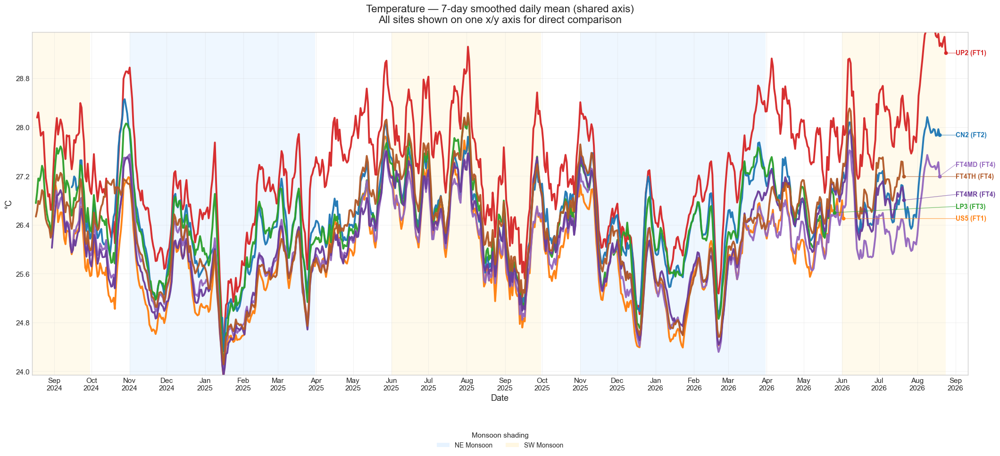

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/temperature/temperature_A_daily_mean_shared.png


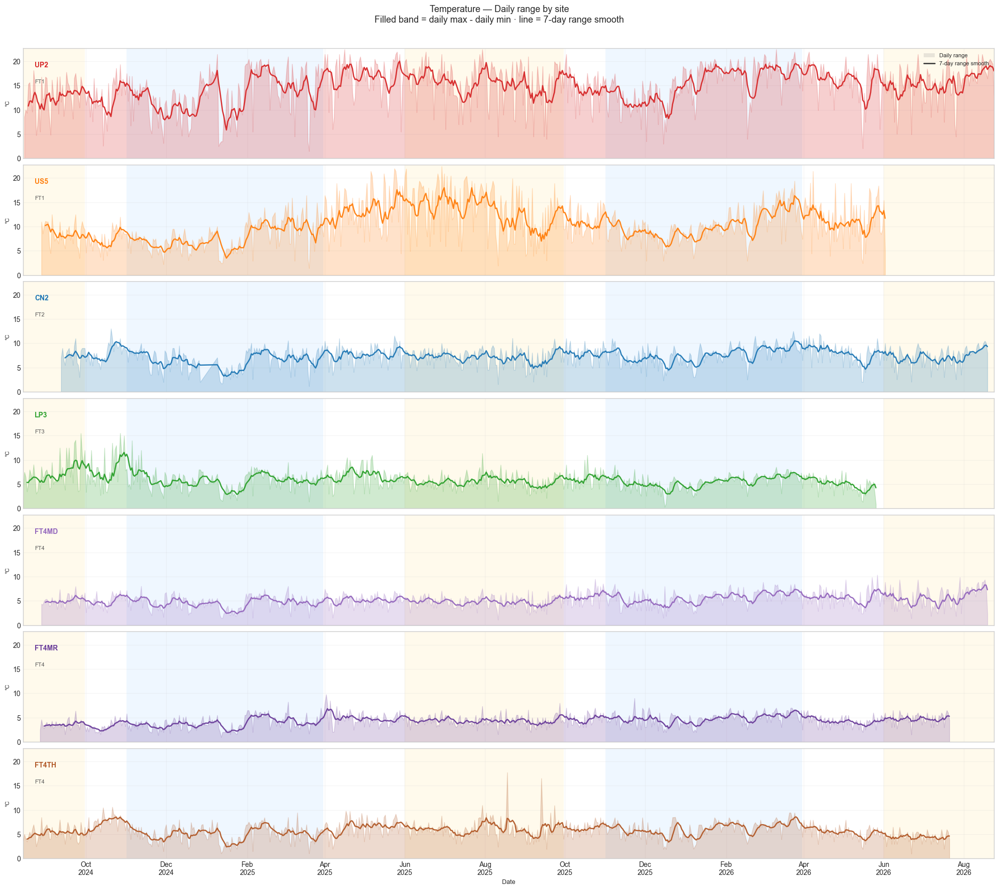

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/temperature/temperature_B_daily_range_faceted.png


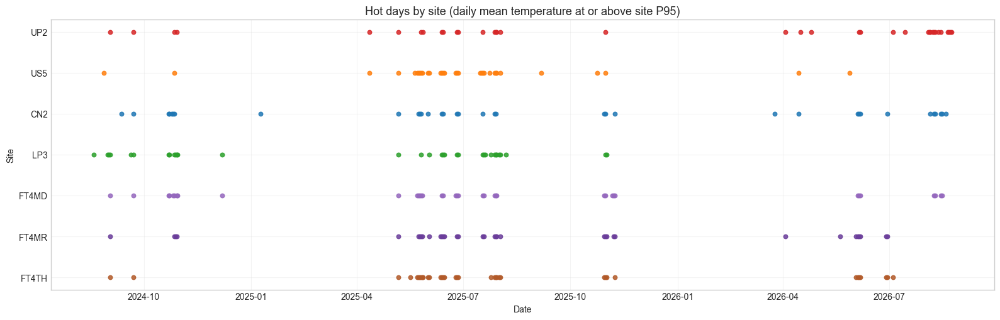

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/temperature/temperature_C_threshold_days.png


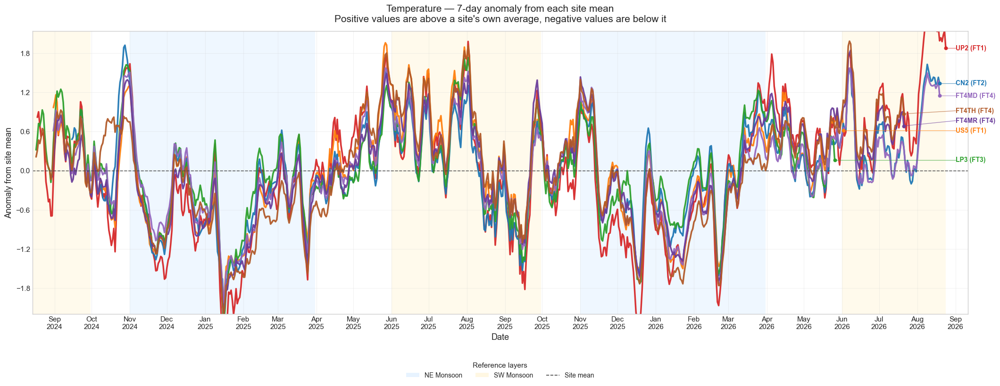

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/temperature/temperature_D_anomaly_shared.png

  TEMPERATURE — COMPARATIVE SUMMARY
 Site  FT  MeanDailyMean  MeanDailyMin  MeanDailyMax  MeanDailyRange  HotP95  HotDays  CoolingRate_C_per_day  WarmingRate_C_per_day
  CN2 FT2        26.5363       23.8612       31.1652          7.3040 28.1565       35                 0.8145                 0.6881
FT4MD FT4        26.0480       24.1017       29.2796          5.1778 27.6009       37                 0.6706                 0.5762
FT4MR FT4        26.1186       24.3505       28.6702          4.3197 27.7237       35                 0.6322                 0.5621
FT4TH FT4        26.3228       24.1499       29.8798          5.7299 28.0509       36                 0.6981                 0.5862
  LP3 FT3        26.4373       24.3276       30.1991          5.8716 28.1028       33                 0.7745                 0.6644
  UP2 FT1        27.3388       23.1791       37.

In [34]:
temp_raw = comp_df_raw[comp_df_raw['param'].str.contains('temp', case=False, na=False)].copy()
temp_raw = temp_raw[(temp_raw['value'] >= 15) & (temp_raw['value'] <= 50)]
temperature_comp = run_comparative_parameter(temp_raw, 'temperature', 'Temperature', '°C', 0.95, 'high', 'HotP95', 'HotDays', 'CoolingRate_C_per_day', 'WarmingRate_C_per_day', '°C', 'Hot days by site (daily mean temperature at or above site P95)', include_anomaly=True)


**Figure 4.1a — Daily mean temperature across plots.**  
*Source: cleaned RData aggregated by plot and day. The lines show time variation and not a fitted forecast.*

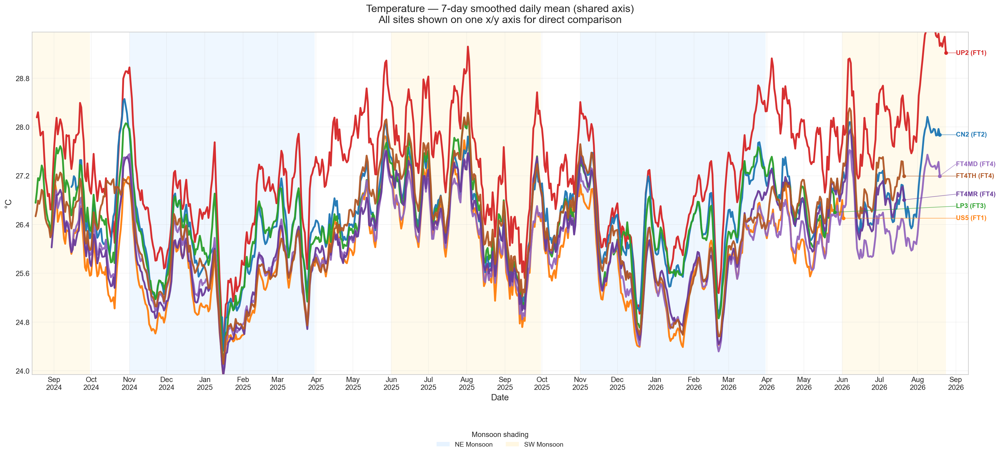

In [35]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'temperature/temperature_A_daily_mean_shared.png'
display(Markdown("**Figure 4.1a — Daily mean temperature across plots.**  \n*Source: cleaned RData aggregated by plot and day. The lines show time variation and not a fitted forecast.*"))
display(Image(filename=str(figure_path)))


**Figure 4.1b — High-temperature days by plot.**  
*Source: cleaned RData. The threshold rule is defined in the preceding analysis; it marks relative extremes, not ecological damage.*

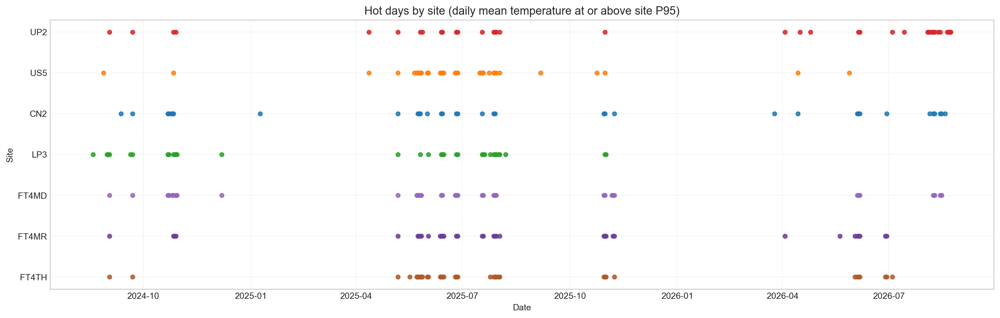

In [36]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'temperature/temperature_C_threshold_days.png'
display(Markdown("**Figure 4.1b — High-temperature days by plot.**  \n*Source: cleaned RData. The threshold rule is defined in the preceding analysis; it marks relative extremes, not ecological damage.*"))
display(Image(filename=str(figure_path)))


### Temperature across sites

#### How the comparison was calculated
- `daily_mean(t)` is the mean temperature recorded at a site on day `t`.
- `daily_range(t) = daily_max(t) - daily_min(t)` shows the within-day thermal spread, in `°C`.
- The main comparison line is `roll7(t)`, the 7-day moving mean of `daily_mean`, used to reduce day-to-day noise while keeping short seasonal shifts visible.
- `site_mean = mean_t(daily_mean(t))` is the average temperature level of each site across the study period.
- `anomaly7(t) = roll7(t) - site_mean` recentres each site around its own average, so the anomaly plot shows warmer-than-usual and cooler-than-usual periods rather than absolute level.
- `HotP95` is the 95th percentile of the site's daily-mean temperature series.
- `HotDays` counts the days where `daily_mean >= HotP95`.
- `ΔT(t) = daily_mean(t) - daily_mean(t-1)` is the first day-to-day change.
- `CoolingRate` is the mean magnitude of negative `ΔT`, and `WarmingRate` is the mean positive `ΔT`, both in `°C/day`.

#### Interpretation
The shared-axis 7-day mean plot tells the absolute temperature story most clearly. `UP2` stays above the other sites for much of the record, `US5` is often the next warmest, and the FT4 sites sit lower and closer together. With the site names placed at the right end of each line, the ranking is much easier to follow without jumping back to a legend.

The anomaly plot answers a different question: when was each site warmer or cooler than its own usual level? That separates background exposure from short-term departures. If several sites rise together in the anomaly view, that points to a shared weather signal; if one site separates strongly on its own, that is consistent with a local site or sensor-specific effect. The range and hot-day plots stay useful as support figures because they show how variable each site is and when it actually enters its warm tail.


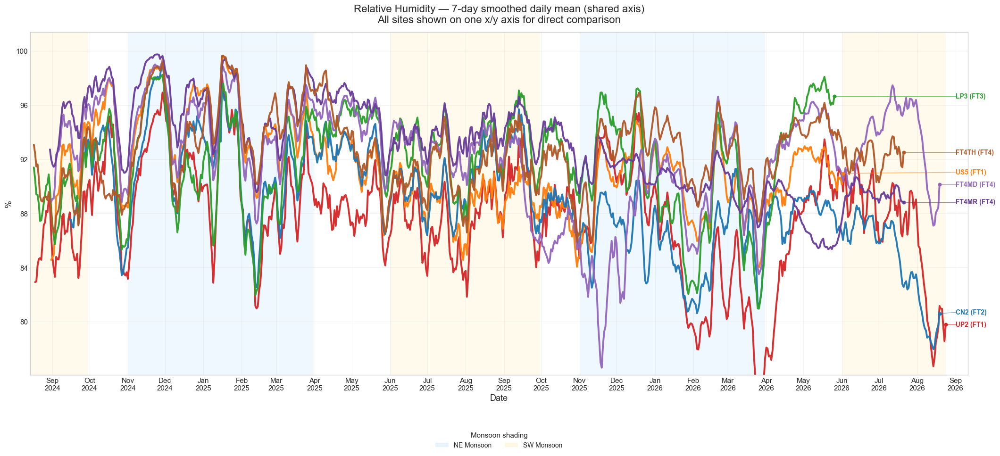

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/rh/rh_A_daily_mean_shared.png


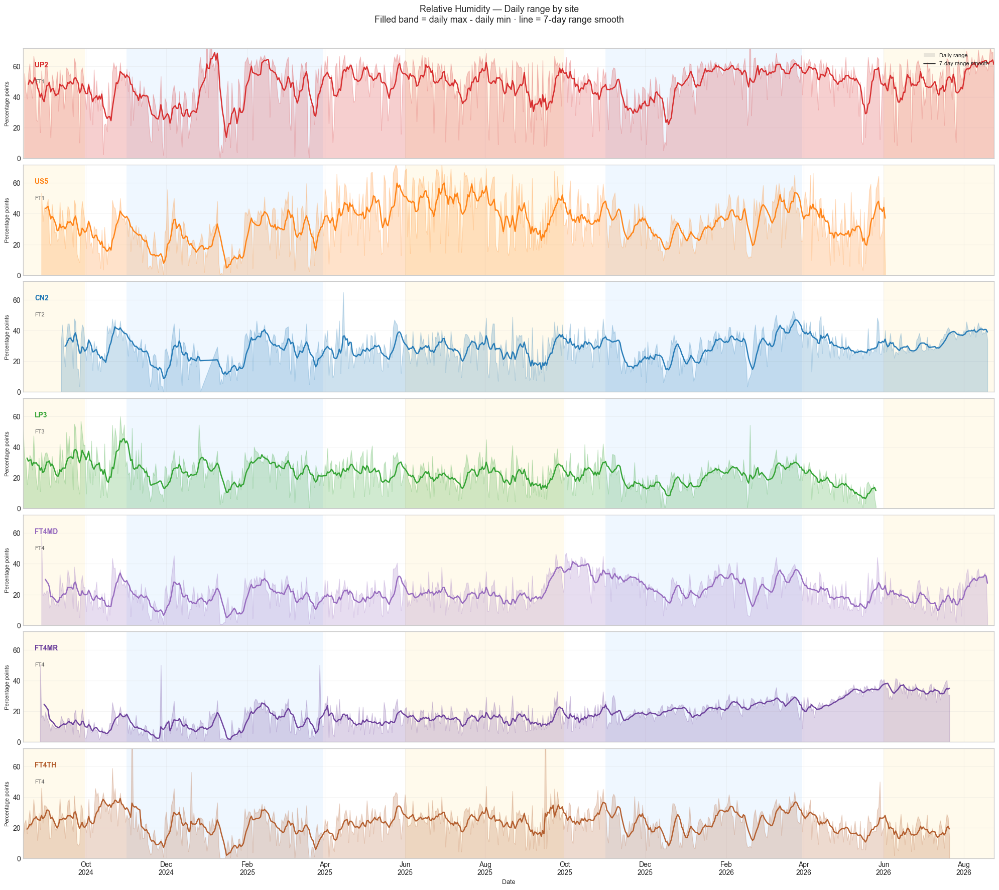

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/rh/rh_B_daily_range_faceted.png


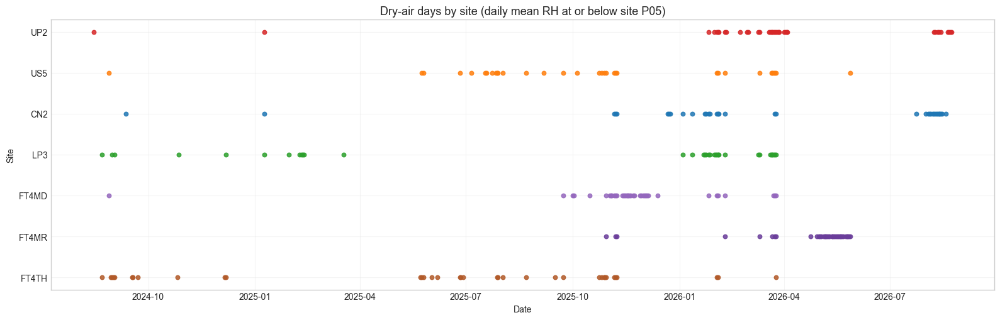

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/rh/rh_C_threshold_days.png


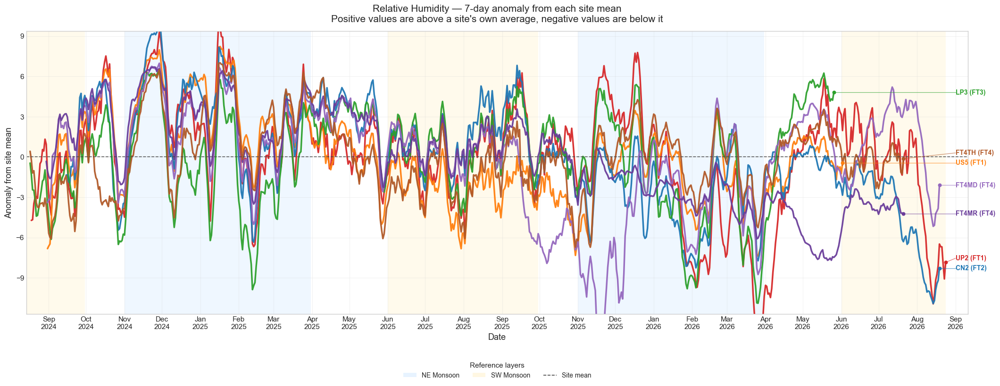

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/rh/rh_D_anomaly_shared.png

  RELATIVE HUMIDITY — COMPARATIVE SUMMARY
 Site  FT  MeanDailyMean  MeanDailyMin  MeanDailyMax  MeanDailyRange  DryAirP05  DryAirDays  HumidityLossRate_pp_per_day  HumidityGainRate_pp_per_day
  CN2 FT2        88.8780       70.6053       99.1428         28.5375    80.1705          35                       2.9202                       3.1462
FT4MD FT4        92.2543       77.7977       99.4691         21.6714    83.7491          37                       2.5388                       2.6190
FT4MR FT4        93.0482       81.1735       99.4063         18.2328    86.8475          35                       1.6989                       1.7192
FT4TH FT4        92.6465       76.6769       99.6309         22.9540    86.2225          36                       2.7967                       2.9604
  LP3 FT3        91.8439       76.3455       98.8642         22.5187    82.8766          33           

In [37]:
rh_raw = comp_df_raw[comp_df_raw['param'].str.lower() == 'rh'].copy()
rh_raw = rh_raw[(rh_raw['value'] >= 0) & (rh_raw['value'] <= 100)]
rh_comp = run_comparative_parameter(rh_raw, 'rh', 'Relative Humidity', '%', 0.05, 'low', 'DryAirP05', 'DryAirDays', 'HumidityLossRate_pp_per_day', 'HumidityGainRate_pp_per_day', 'Percentage points', 'Dry-air days by site (daily mean RH at or below site P05)', include_anomaly=True)


**Figure 4.2a — Daily mean relative humidity across plots.**  
*Source: cleaned RData aggregated by plot and day. Use this with the temperature panel because humidity is strongly coupled to temperature.*

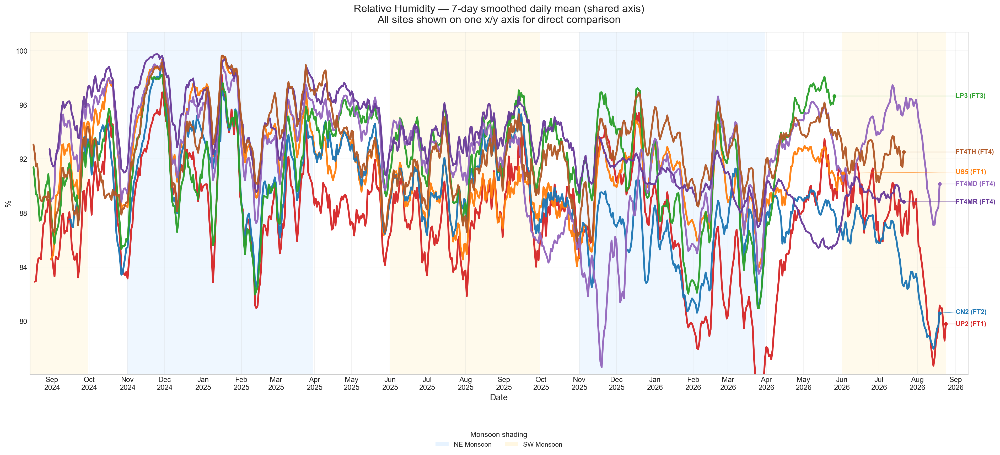

In [38]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'rh/rh_A_daily_mean_shared.png'
display(Markdown("**Figure 4.2a — Daily mean relative humidity across plots.**  \n*Source: cleaned RData aggregated by plot and day. Use this with the temperature panel because humidity is strongly coupled to temperature.*"))
display(Image(filename=str(figure_path)))


**Figure 4.2b — Low-humidity days by plot.**  
*Source: cleaned RData. These are relative dry-air days under the stated rule, not direct drought labels.*

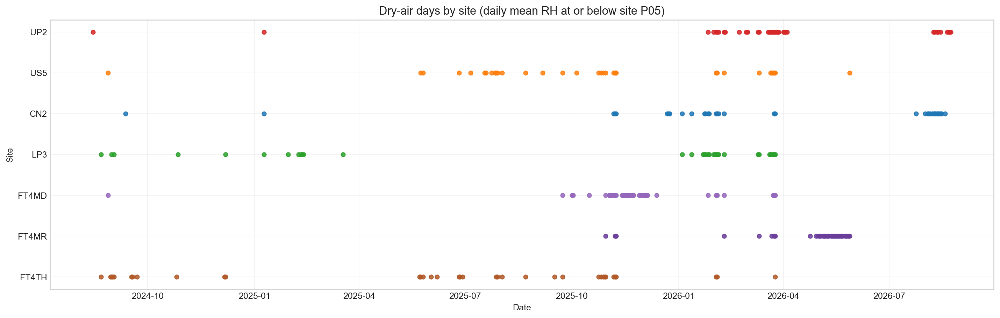

In [39]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'rh/rh_C_threshold_days.png'
display(Markdown("**Figure 4.2b — Low-humidity days by plot.**  \n*Source: cleaned RData. These are relative dry-air days under the stated rule, not direct drought labels.*"))
display(Image(filename=str(figure_path)))


### Relative humidity across sites

#### How the comparison was calculated
- `daily_mean(t)` is the mean RH for each site and day.
- `daily_range(t) = daily_max(t) - daily_min(t)` gives the within-day humidity swing, in percentage points.
- The main comparison line is `roll7(t)`, the 7-day moving mean of `daily_mean`, so site differences can be compared on one common axis.
- `site_mean = mean_t(daily_mean(t))` is the average RH level of each site across the study period.
- `anomaly7(t) = roll7(t) - site_mean` shows whether a site is sitting above or below its own usual humidity level at a given time.
- `DryAirP05` is the 5th percentile of the site's daily-mean RH series.
- `DryAirDays` counts the days where `daily_mean <= DryAirP05`.
- `ΔRH(t) = daily_mean(t) - daily_mean(t-1)` is the first day-to-day change.
- `HumidityLossRate` is the mean magnitude of negative `ΔRH`, and `HumidityGainRate` is the mean positive `ΔRH`, both in percentage points per day.

#### Interpretation
The shared-axis 7-day RH plot shows the humidity gradient very cleanly. The FT4 sites stay higher and steadier, while `UP2` drops lower and swings more strongly. That makes RH a good companion to temperature, because it shows a similar ordering across plots from the opposite side.

The anomaly plot is helpful here because it shows whether sites dry out at the same time or whether some sites lose humidity earlier and recover later. That timing view matters for later modeling because it separates baseline site wetness from shared atmospheric shifts. The range and dry-air plots then add two practical details: how large the within-day humidity swing is, and when each site actually reaches its low-humidity tail.


Converted VPD from Pa to kPa for comparative analysis.


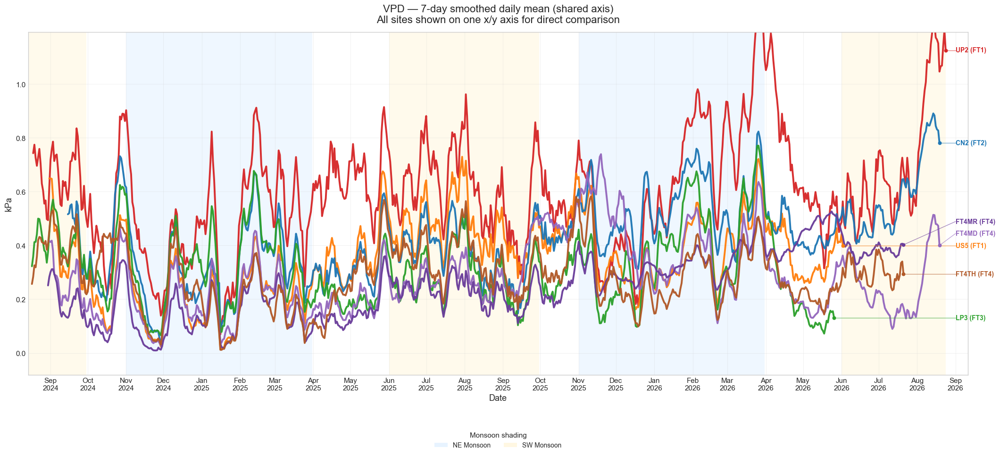

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/vpd/vpd_A_daily_mean_shared.png


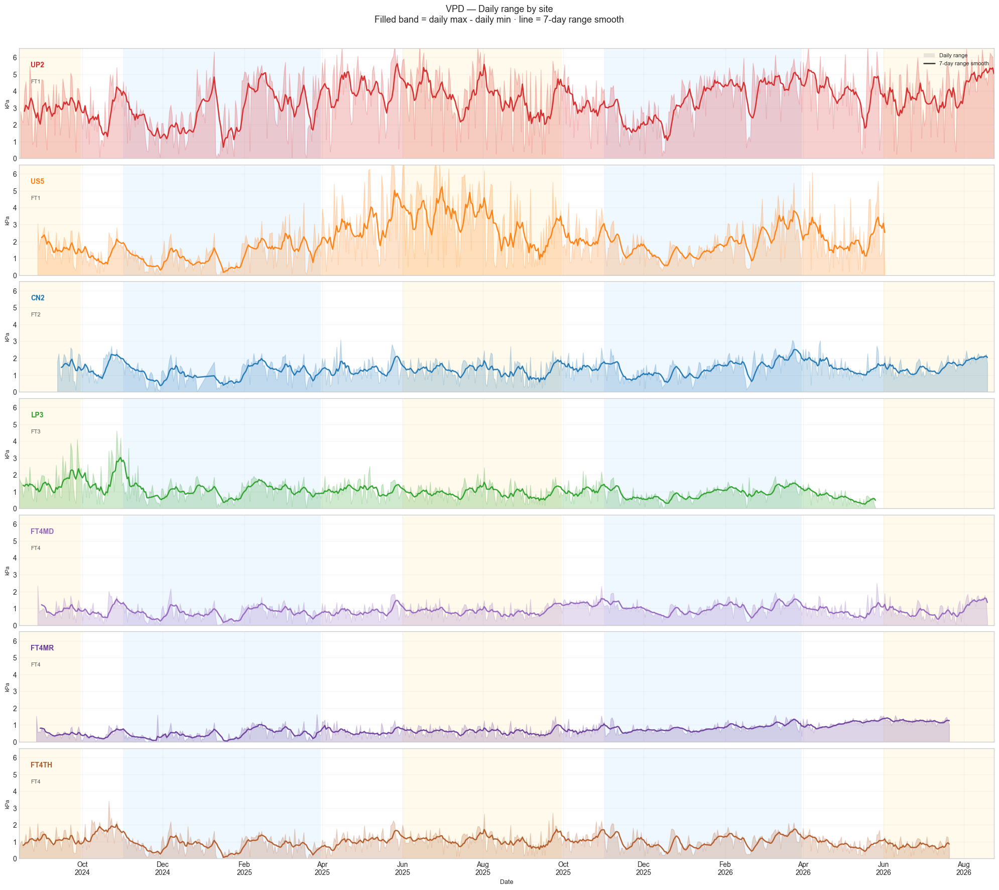

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/vpd/vpd_B_daily_range_faceted.png


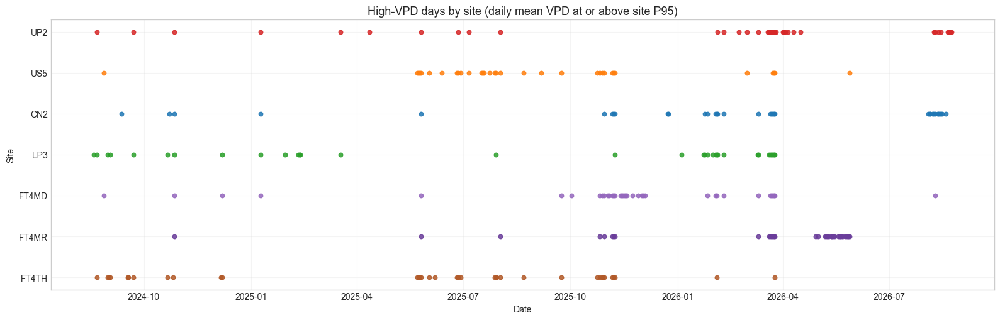

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/vpd/vpd_C_threshold_days.png


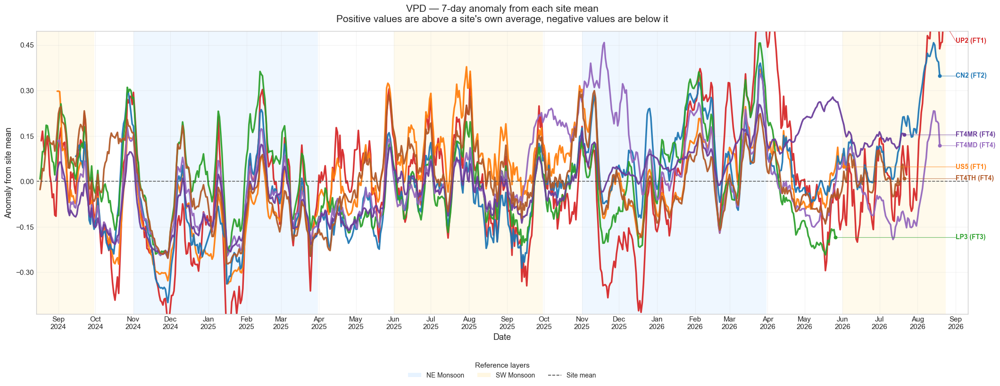

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/vpd/vpd_D_anomaly_shared.png

  VPD — COMPARATIVE SUMMARY
 Site  FT  MeanDailyMean  MeanDailyMin  MeanDailyMax  MeanDailyRange  HighVPDP95  HighVPDDays  VPDDecreaseRate_kPa_per_day  VPDIncreaseRate_kPa_per_day
  CN2 FT2         0.4331        0.0259        1.3695          1.3435      0.8041           35                       0.1441                       0.1399
FT4MD FT4         0.2810        0.0171        0.8950          0.8779      0.5992           37                       0.1060                       0.0983
FT4MR FT4         0.2478        0.0192        0.7246          0.7054      0.4735           35                       0.0670                       0.0681
FT4TH FT4         0.2836        0.0121        1.0052          0.9932      0.5598           36                       0.1229                       0.1185
  LP3 FT3         0.3142        0.0358        1.0679          1.0321      0.6715           33           

In [40]:
vpd_raw = comp_df_raw[comp_df_raw['param'].str.lower() == 'vpd'].copy()
vpd_raw = vpd_raw[vpd_raw['value'] >= 0].copy()
if vpd_raw['value'].max() > 10:
    vpd_raw['value'] = vpd_raw['value'] / 1000
    print('Converted VPD from Pa to kPa for comparative analysis.')
vpd_comp = run_comparative_parameter(vpd_raw, 'vpd', 'VPD', 'kPa', 0.95, 'high', 'HighVPDP95', 'HighVPDDays', 'VPDDecreaseRate_kPa_per_day', 'VPDIncreaseRate_kPa_per_day', 'kPa', 'High-VPD days by site (daily mean VPD at or above site P95)', include_anomaly=True)


**Figure 4.3a — Daily mean VPD across plots.**  
*Source: cleaned RData aggregated by plot and day. VPD is reported in kPa after the documented unit conversion.*

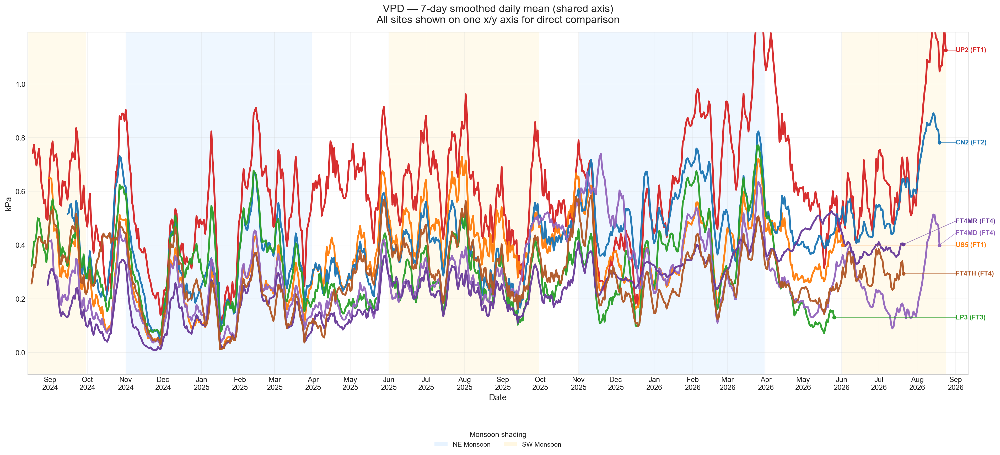

In [41]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'vpd/vpd_A_daily_mean_shared.png'
display(Markdown("**Figure 4.3a — Daily mean VPD across plots.**  \n*Source: cleaned RData aggregated by plot and day. VPD is reported in kPa after the documented unit conversion.*"))
display(Image(filename=str(figure_path)))


**Figure 4.3b — High-VPD days by plot.**  
*Source: cleaned RData. The panel highlights days of higher atmospheric moisture demand within this dataset.*

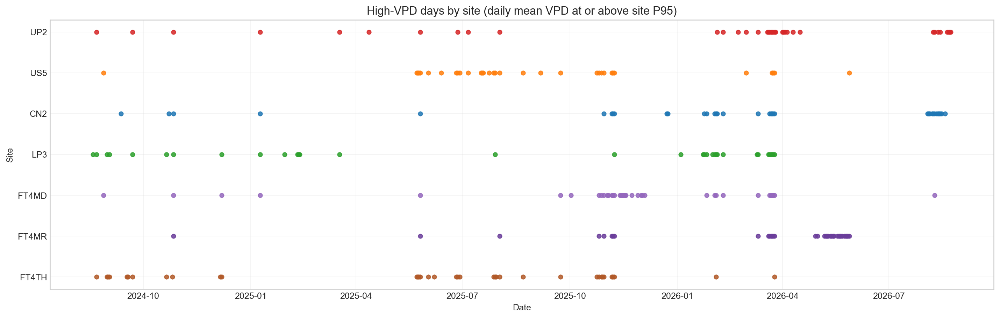

In [42]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'vpd/vpd_C_threshold_days.png'
display(Markdown("**Figure 4.3b — High-VPD days by plot.**  \n*Source: cleaned RData. The panel highlights days of higher atmospheric moisture demand within this dataset.*"))
display(Image(filename=str(figure_path)))


### VPD across sites

#### How the comparison was calculated
- `daily_mean(t)` is the mean daily VPD at each site, in `kPa`.
- `roll7(t)` is the 7-day moving mean of `daily_mean`, used as the main shared-axis comparison line.
- `site_mean = mean_t(daily_mean(t))` is the site's average VPD across the full record.
- `anomaly7(t) = roll7(t) - site_mean` shows whether the site is running above or below its own usual VPD level.
- `daily_range(t) = daily_max(t) - daily_min(t)` gives the within-day evaporative-demand spread.
- `HighVPDP95` is the 95th percentile of the site's daily-mean VPD series.
- `HighVPDDays` counts the days where `daily_mean >= HighVPDP95`. These are upper-tail VPD days, not measured tree-stress events.
- `ΔVPD(t) = daily_mean(t) - daily_mean(t-1)` is the first day-to-day change, in `kPa/day`.
- `VPDDecreaseRate` is the mean magnitude of negative `ΔVPD`, and `VPDIncreaseRate` is the mean positive `ΔVPD`.

#### Interpretation
The shared-axis 7-day VPD plot gives the clearest view of background drying demand across sites. `UP2` stays highest for much of the record, `FT4MR` stays lowest, and the other sites keep a fairly stable order between those two ends. That makes it easier to see that the site difference is not coming from one short episode, but from a repeated pattern through time.

The anomaly plot answers a slightly different question. Instead of asking which site is highest in absolute terms, it shows when each site is running above or below its own usual VPD. That makes unusual dry-air periods easier to spot, even for sites that normally sit at different baselines.

The range and high-VPD-day plots then add the short-term part of the story. The range plot shows which sites have more volatile within-day demand, while the threshold plot marks days in each site's upper tail. Taken together, VPD is a useful predictor candidate because it captures both persistent site contrast and the timing of unusually high atmospheric demand.


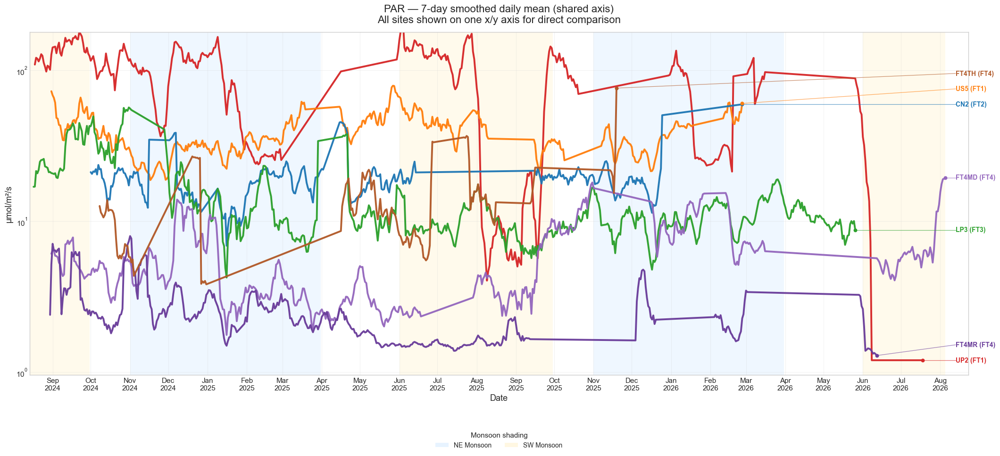

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/par/par_A_daily_mean_shared.png


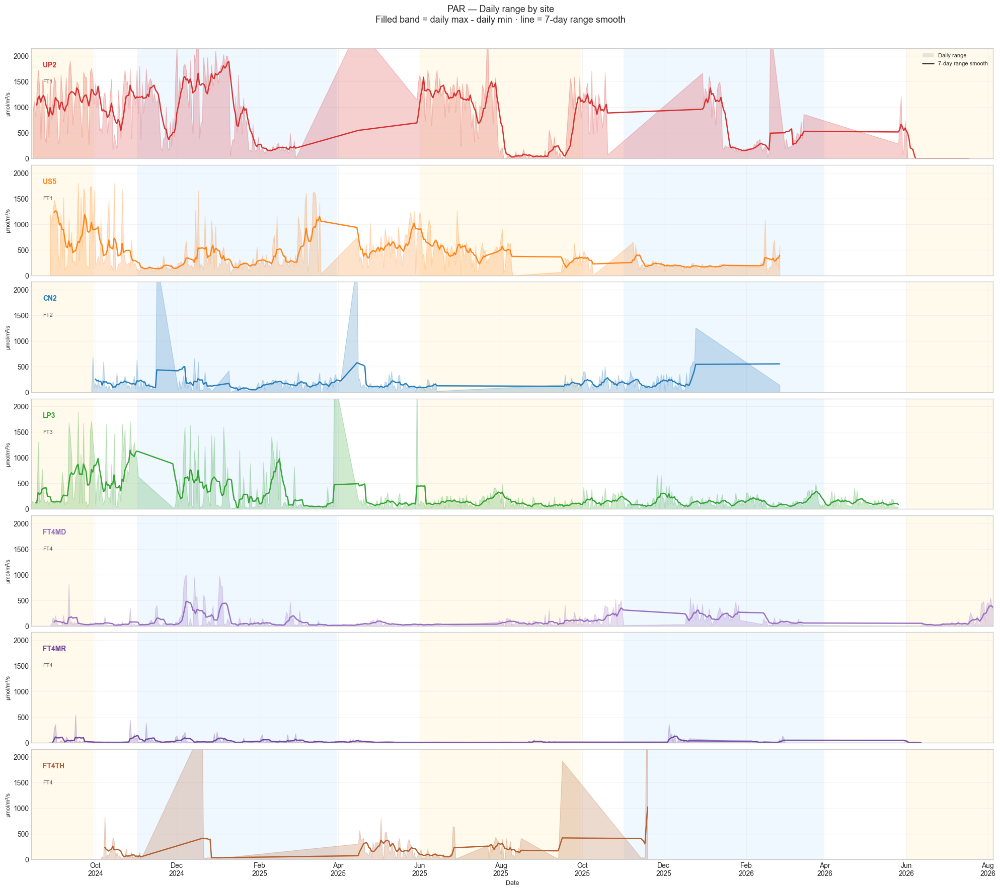

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/par/par_B_daily_range_faceted.png


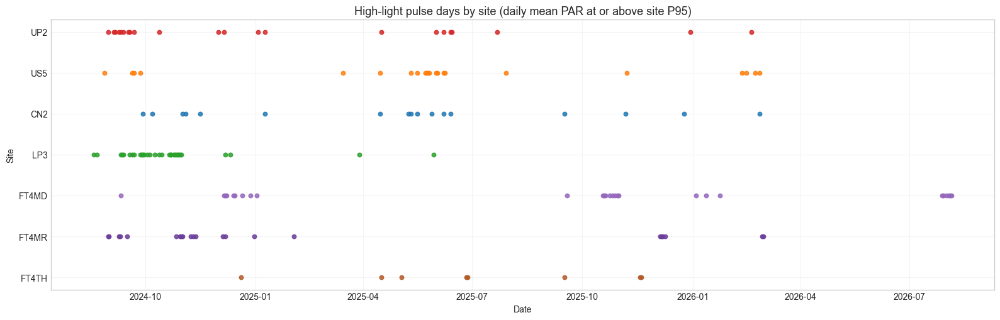

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/par/par_C_threshold_days.png


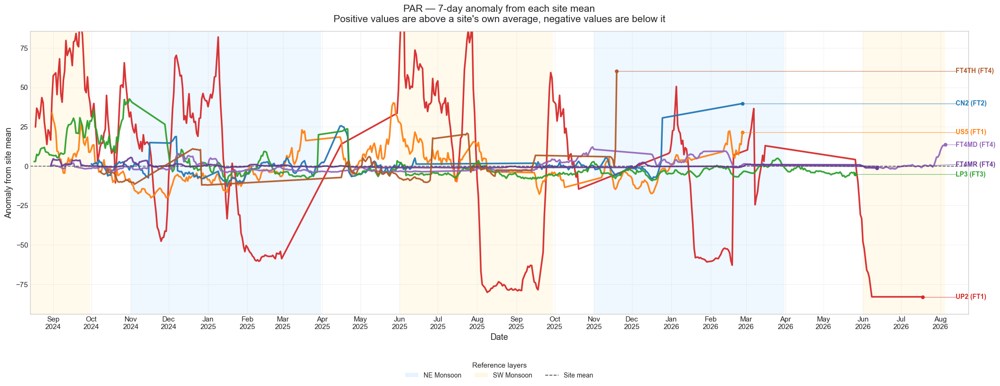

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/par/par_D_anomaly_shared.png

  PAR — COMPARATIVE SUMMARY
 Site  FT  MeanDailyMean  MeanDailyMin  MeanDailyMax  MeanDailyRange  LightPulseP95  LightPulseDays  LightDecreaseRate_umol_per_m2_s_per_day  LightIncreaseRate_umol_per_m2_s_per_day
  CN2 FT2        19.7571        1.2776      182.3180        181.0404        30.4040              17                                   9.5255                                   9.7378
FT4MD FT4         5.9085        1.2000       97.8267         96.6267        17.7625              27                                   2.5287                                   2.6826
FT4MR FT4         2.4542        1.2000       26.7677         25.5677         5.0021              22                                   1.0764                                   1.0723
FT4TH FT4        15.8376        1.2000      223.1408        221.9408        36.7062               8                                  10.

In [43]:
par_raw = comp_df_raw[comp_df_raw['param'].str.lower() == 'par'].copy()
par_raw = par_raw[par_raw['value'] >= 0].copy()
par_comp = run_comparative_parameter(par_raw, 'par', 'PAR', 'μmol/m²/s', 0.95, 'high', 'LightPulseP95', 'LightPulseDays', 'LightDecreaseRate_umol_per_m2_s_per_day', 'LightIncreaseRate_umol_per_m2_s_per_day', 'μmol/m²/s', 'High-light pulse days by site (daily mean PAR at or above site P95)', log_scale=True, include_anomaly=True)


**Figure 4.4a — Daily mean PAR across plots.**  
*Source: cleaned RData aggregated by plot and day. Interpret the series with the coverage checks because PAR availability differs by deployment.*

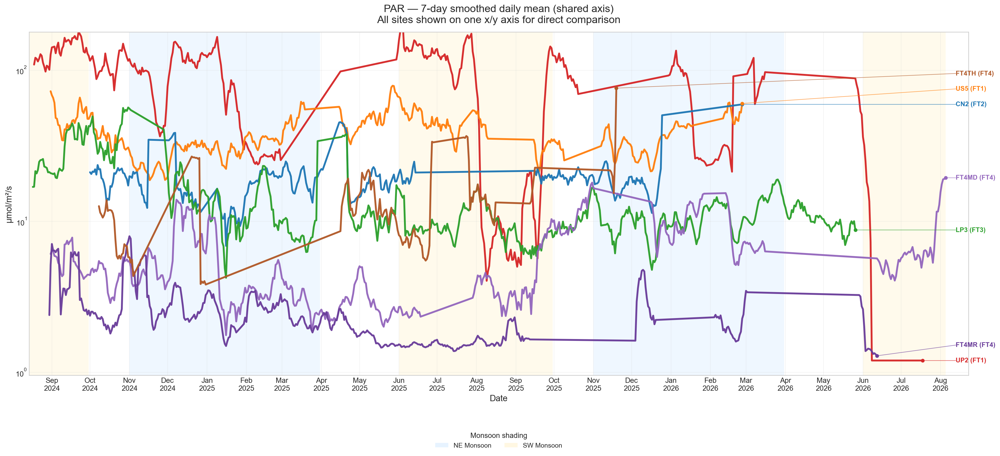

In [44]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'par/par_A_daily_mean_shared.png'
display(Markdown("**Figure 4.4a — Daily mean PAR across plots.**  \n*Source: cleaned RData aggregated by plot and day. Interpret the series with the coverage checks because PAR availability differs by deployment.*"))
display(Image(filename=str(figure_path)))


**Figure 4.4b — High-light days by plot.**  
*Source: cleaned RData. The threshold identifies high recorded light relative to the plot distribution.*

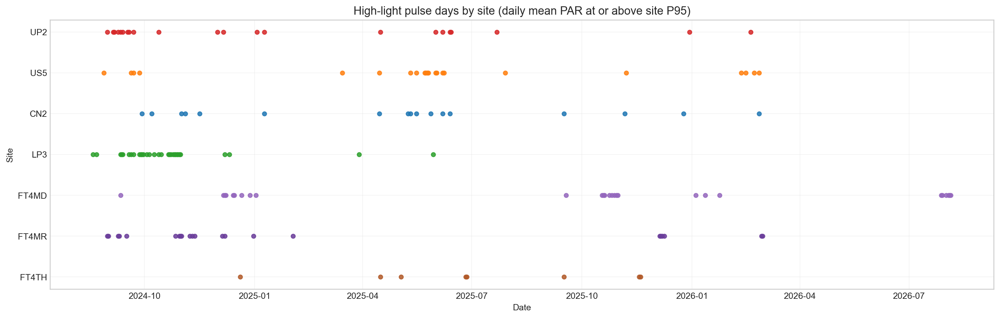

In [45]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'par/par_C_threshold_days.png'
display(Markdown("**Figure 4.4b — High-light days by plot.**  \n*Source: cleaned RData. The threshold identifies high recorded light relative to the plot distribution.*"))
display(Image(filename=str(figure_path)))


### PAR across sites

#### How the comparison was calculated
- `daily_mean(t)` is the mean daily PAR at each site.
- `roll7(t)` is the 7-day moving mean of `daily_mean`, used as the main shared-axis comparison line.
- `site_mean = mean_t(daily_mean(t))` is the site's average PAR across the full record.
- `anomaly7(t) = roll7(t) - site_mean` shows whether the site is brighter or dimmer than its own usual level.
- `daily_range(t) = daily_max(t) - daily_min(t)` gives the within-day light spread, in `μmol/m²/s`.
- The main PAR mean plot stays on a log scale so both shaded and bright sites can be read on the same axis, while the anomaly plot stays on a linear scale because it is showing departures from each site's own baseline.
- `LightPulseP95` is the 95th percentile of the site's daily-mean PAR series.
- `LightPulseDays` counts the days where `daily_mean >= LightPulseP95`.
- `ΔPAR(t) = daily_mean(t) - daily_mean(t-1)` is the first day-to-day change, in `μmol/m²/s per day`.
- `LightDecreaseRate` is the mean magnitude of negative `ΔPAR`, and `LightIncreaseRate` is the mean positive `ΔPAR`.

#### Interpretation
The shared-axis 7-day PAR plot still gives the clearest structural canopy contrast in the comparative section. `UP2` stays much brighter than the rest, `FT4MR` stays at the shaded end, and `FT4TH` stands out by behaving noticeably brighter than the other FT4 sites. With all sites on one axis, that separation is much easier to read than in the older faceted version.

The anomaly plot helps separate permanent brightness differences from temporary bright or dim periods. A site like `UP2` is expected to sit high in the raw-value graph, but the anomaly graph tells us whether it is unusually bright even relative to its own normal condition. That is more useful when we want to compare timing rather than just absolute exposure.

The range and light-pulse plots then show whether a site is steadily bright or whether its exposure comes in bursts. Together, the PAR graphs make it easier to identify light-distribution differences and sites where PAR is associated with differences in temperature, VPD, or soil response.


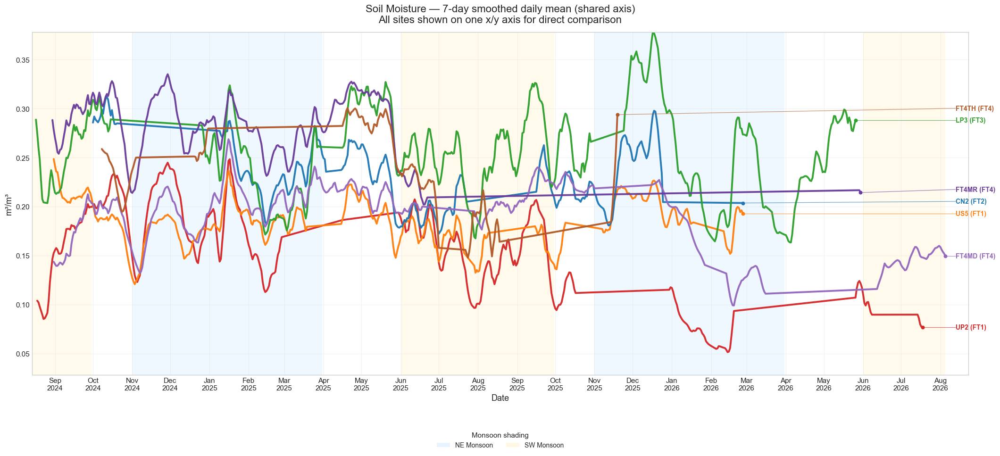

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil/soil_A_daily_mean_shared.png


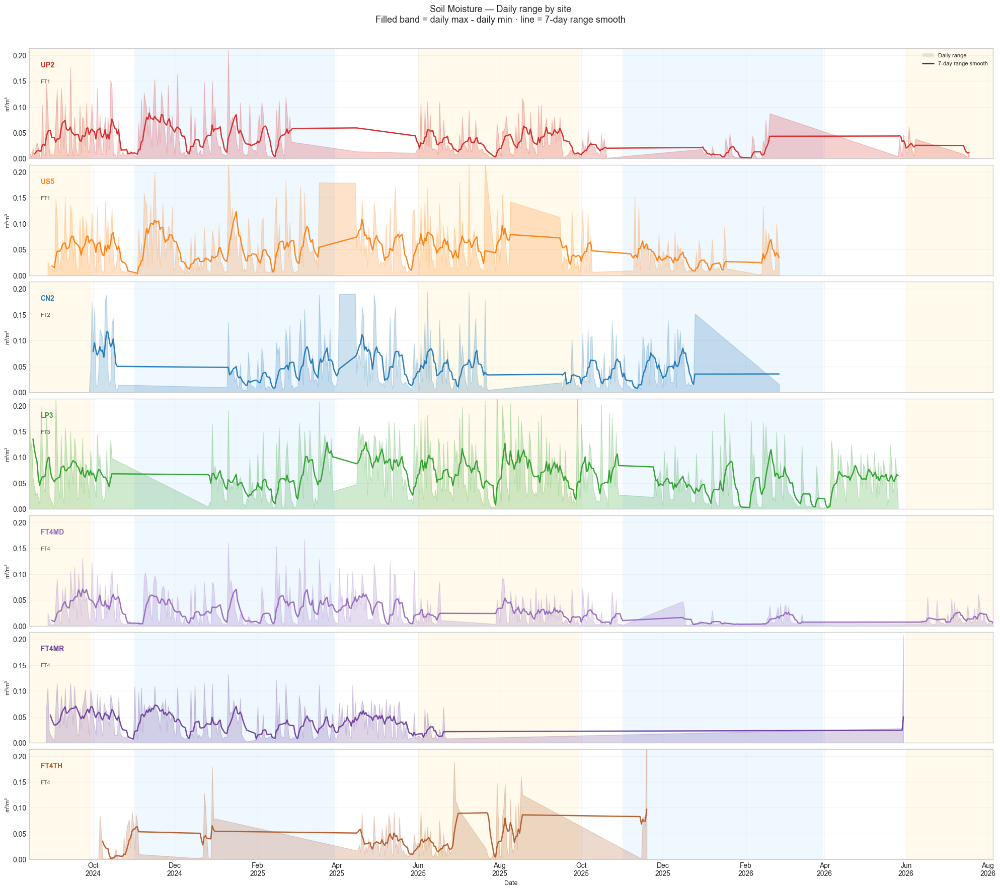

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil/soil_B_daily_range_faceted.png


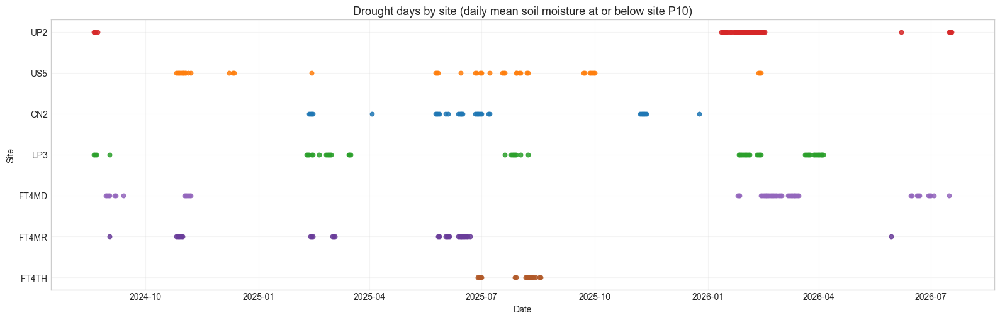

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil/soil_C_threshold_days.png


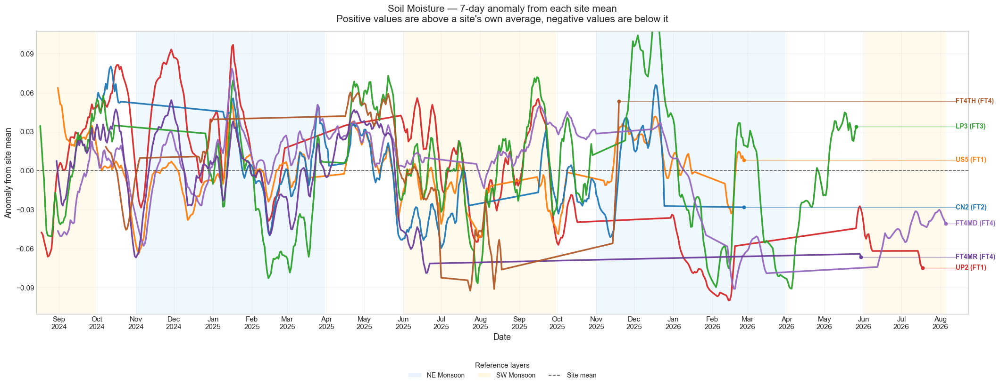

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil/soil_D_anomaly_shared.png

  SOIL MOISTURE — COMPARATIVE SUMMARY
 Site  FT  MeanDailyMean  MeanDailyMin  MeanDailyMax  MeanDailyRange  DroughtP10  DroughtDays  DryingRate_m3m3_per_day  RecoveryRate_m3m3_per_day
  CN2 FT2         0.2319        0.2155        0.2629          0.0474      0.1839           31                   0.0142                     0.0233
FT4MD FT4         0.1901        0.1811        0.2071          0.0260      0.1379           53                   0.0075                     0.0142
FT4MR FT4         0.2808        0.2658        0.3050          0.0392      0.2273           30                   0.0125                     0.0177
FT4TH FT4         0.2403        0.2229        0.2627          0.0398      0.1846           16                   0.0140                     0.0234
  LP3 FT3         0.2542        0.2294        0.2920          0.0626      0.1764           54                   0.0194    

In [46]:
soil_raw_comp = comp_df_raw[comp_df_raw['param'].str.lower() == 'soil moisture'].copy()
soil_raw_comp = soil_raw_comp[(soil_raw_comp['value'] >= 0) & (soil_raw_comp['value'] <= 0.6)]
soil_comp = run_comparative_parameter(soil_raw_comp, 'soil', 'Soil Moisture', 'm³/m³', 0.10, 'low', 'DroughtP10', 'DroughtDays', 'DryingRate_m3m3_per_day', 'RecoveryRate_m3m3_per_day', 'm³/m³', 'Drought days by site (daily mean soil moisture at or below site P10)', include_anomaly=True)


**Figure 4.5a — Daily mean soil moisture across plots.**  
*Source: cleaned RData aggregated by plot and day. This is a site comparison, not a calibrated soil-water status assessment.*

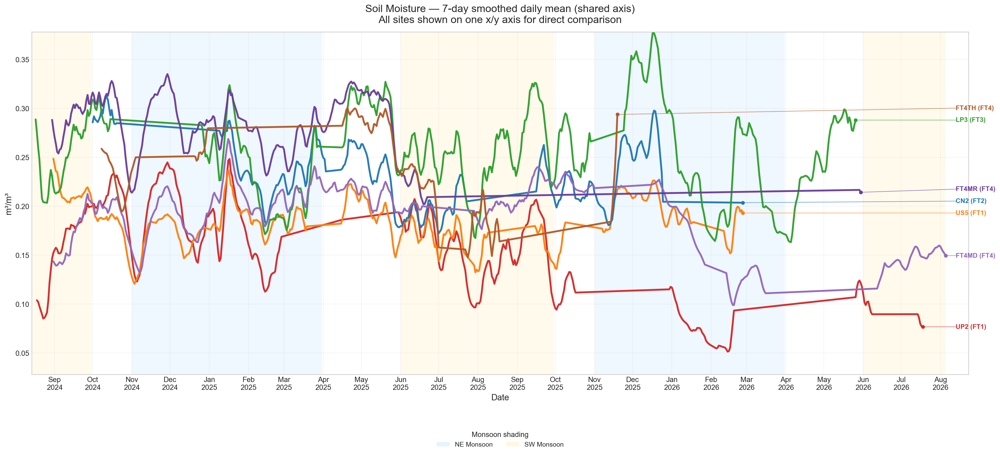

In [47]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'soil/soil_A_daily_mean_shared.png'
display(Markdown("**Figure 4.5a — Daily mean soil moisture across plots.**  \n*Source: cleaned RData aggregated by plot and day. This is a site comparison, not a calibrated soil-water status assessment.*"))
display(Image(filename=str(figure_path)))


**Figure 4.5b — Low-soil-moisture days by plot.**  
*Source: cleaned RData. Low values are interpreted relative to the observed plot distribution under the stated rule.*

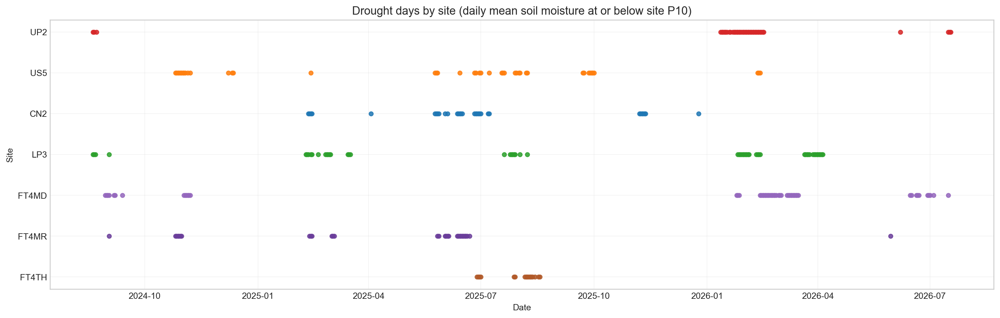

In [48]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'soil/soil_C_threshold_days.png'
display(Markdown("**Figure 4.5b — Low-soil-moisture days by plot.**  \n*Source: cleaned RData. Low values are interpreted relative to the observed plot distribution under the stated rule.*"))
display(Image(filename=str(figure_path)))


### Figures: cross-site daily patterns

Each row uses a common daily aggregation. The threshold-day panels identify relative extremes within each site and should be interpreted alongside coverage checks.

The figures below are embedded in this notebook after the analysis runs. They are also saved in `outputs/redesigned/` for use in the report.


### Cross-site figure index

Each variable's daily-mean and threshold-day figures now appear immediately after its cross-site calculation. The figures use the same cleaned full RData record as the tables in this section.


### Soil moisture across sites

#### How the comparison was calculated
- `daily_mean(t)` is the mean daily soil moisture at each site.
- `roll7(t)` is the 7-day moving mean of `daily_mean`, used as the main shared-axis comparison line.
- `site_mean = mean_t(daily_mean(t))` is the site's average soil moisture across the full record.
- `anomaly7(t) = roll7(t) - site_mean` shows whether the site is wetter or drier than its own usual level.
- `daily_range(t) = daily_max(t) - daily_min(t)` gives the within-day moisture spread, in `m³/m³`.
- `DroughtP10` is the 10th percentile of the site's daily-mean soil-moisture series.
- `DroughtDays` counts the days where `daily_mean <= DroughtP10`.
- `ΔSM(t) = daily_mean(t) - daily_mean(t-1)` is the first day-to-day change, in `m³/m³/day`.
- `DryingRate` is the mean magnitude of negative `ΔSM`, and `RecoveryRate` is the mean positive `ΔSM`.

#### Interpretation
The shared-axis 7-day soil-moisture plot shows which sites stay wetter overall and which sit lower for long stretches. `FT4MR` remains among the wettest for much of the record, `UP2` stays at the dry end, and `LP3` often combines a fairly wet baseline with stronger movement than the less variable FT4 sites. On one axis, the separation between wet, intermediate, and dry sites is much easier to read.

The anomaly plot changes the question from absolute wetness to relative condition. It shows when a site is wetter or drier than its own normal level, which helps identify common wet pulses, shared dry periods, and sites that react more strongly than others even if their baseline moisture is different.

The range and drought plots then add the stress side of the story. The range plot shows how much short-term movement each site experiences, while the threshold plot shows when each site actually enters its low-moisture tail. Together, these graphs set up the later drydown section well because they show both the background moisture state and the timing of real dry periods.


## 5. Relationships between microclimate variables

Correlation matrices align the five sensor variables by timestamp and plot. They quantify association only; correlations do not establish causation. VPD is interpreted carefully because it is physically related to temperature and humidity.


### 5.1 Correlation analysis

Overall and per-site correlation matrices for key cleaned microclimate variables (Temperature, RH, VPD, PAR, Soil Moisture).


Variables included in correlation analysis: ['Temperature (°C)', 'RH (%)', 'VPD (kPa)', 'PAR (μmol/m²/s)', 'Soil Moisture (m³/m³)']


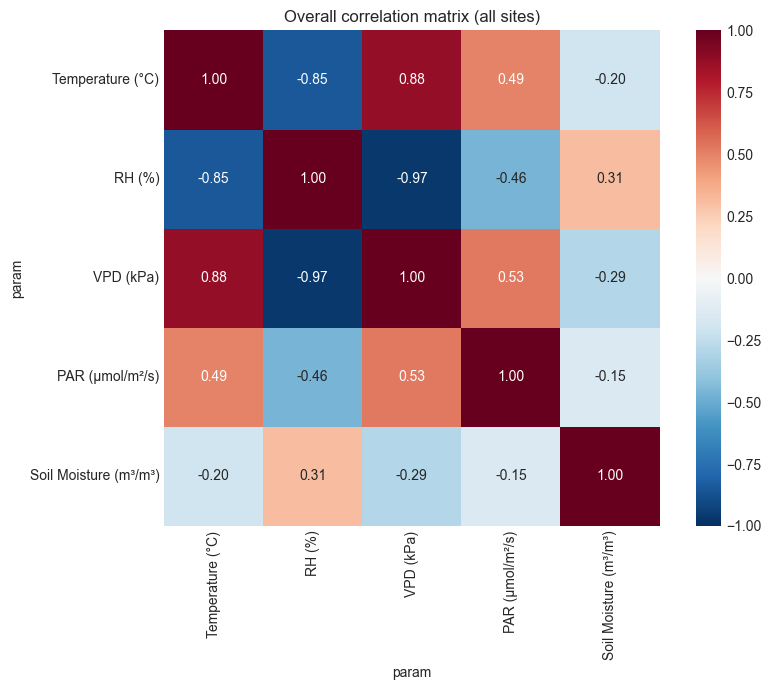


Overall correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.847  0.876  0.495         -0.201
rh            -0.847  1.000 -0.968 -0.465          0.305
vpd            0.876 -0.968  1.000  0.529         -0.291
par            0.495 -0.465  0.529  1.000         -0.149
soil moisture -0.201  0.305 -0.291 -0.149          1.000


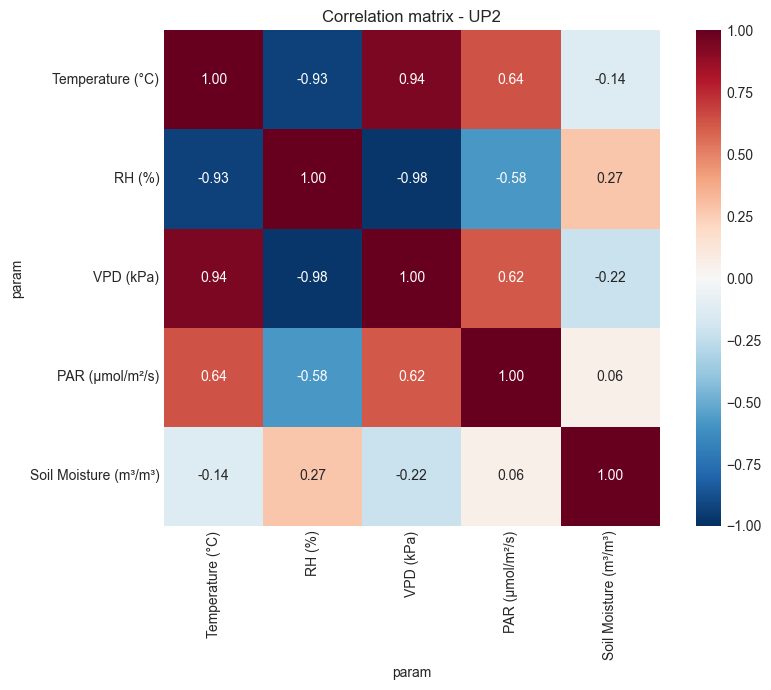


UP2 correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.933  0.938  0.638         -0.137
rh            -0.933  1.000 -0.976 -0.584          0.274
vpd            0.938 -0.976  1.000  0.618         -0.220
par            0.638 -0.584  0.618  1.000          0.057
soil moisture -0.137  0.274 -0.220  0.057          1.000


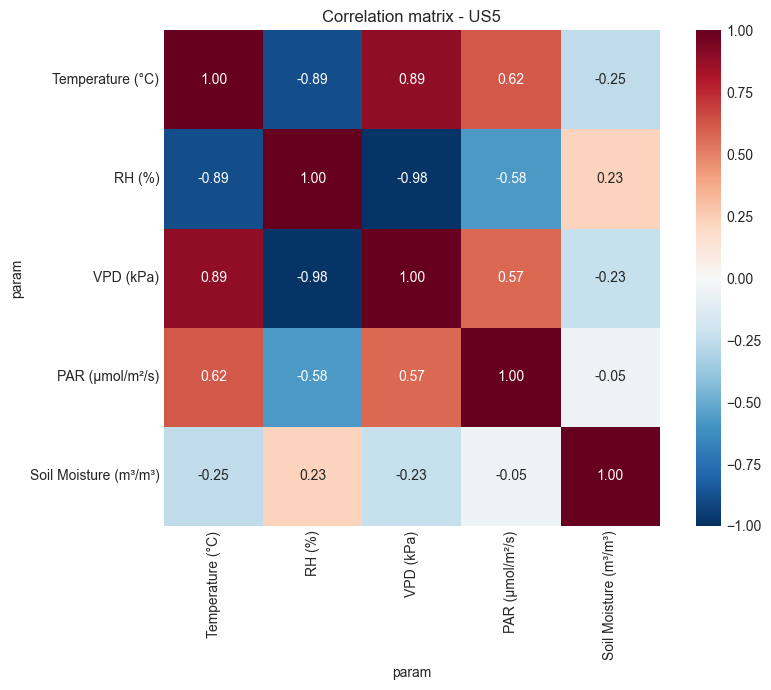


US5 correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.887  0.889  0.620         -0.251
rh            -0.887  1.000 -0.979 -0.576          0.232
vpd            0.889 -0.979  1.000  0.571         -0.231
par            0.620 -0.576  0.571  1.000         -0.053
soil moisture -0.251  0.232 -0.231 -0.053          1.000


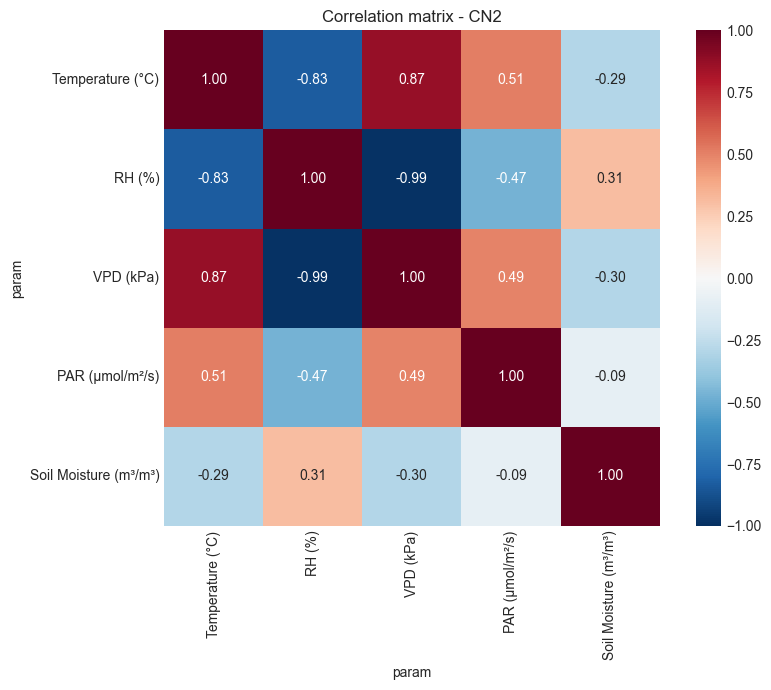


CN2 correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.830  0.870  0.513         -0.293
rh            -0.830  1.000 -0.987 -0.470          0.311
vpd            0.870 -0.987  1.000  0.492         -0.296
par            0.513 -0.470  0.492  1.000         -0.092
soil moisture -0.293  0.311 -0.296 -0.092          1.000


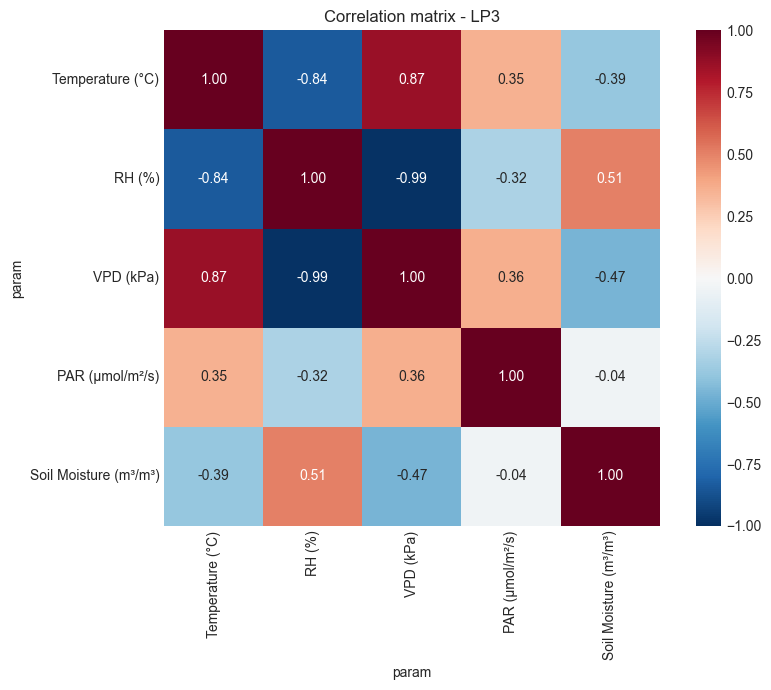


LP3 correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.844  0.867  0.354         -0.386
rh            -0.844  1.000 -0.989 -0.316          0.506
vpd            0.867 -0.989  1.000  0.360         -0.466
par            0.354 -0.316  0.360  1.000         -0.040
soil moisture -0.386  0.506 -0.466 -0.040          1.000


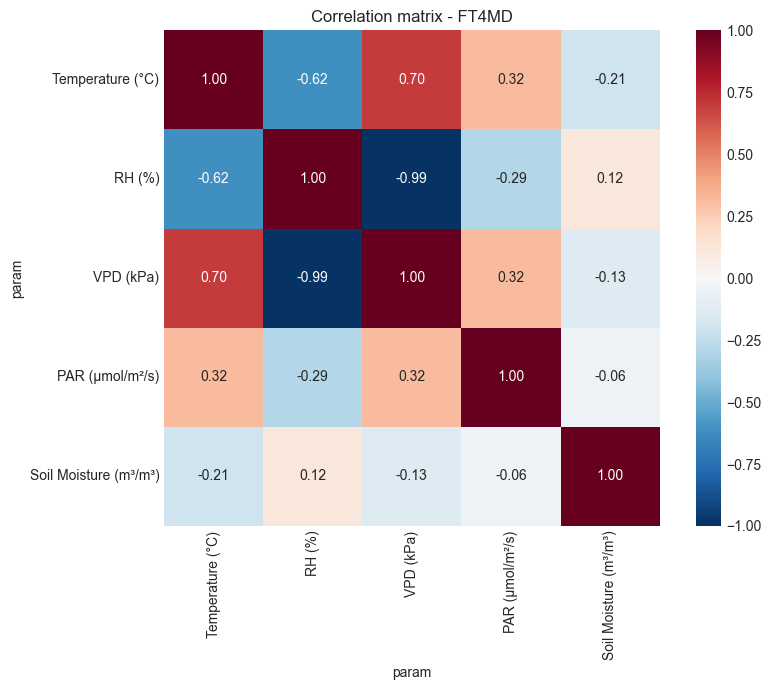


FT4MD correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.617  0.703  0.318         -0.208
rh            -0.617  1.000 -0.985 -0.290          0.117
vpd            0.703 -0.985  1.000  0.320         -0.128
par            0.318 -0.290  0.320  1.000         -0.056
soil moisture -0.208  0.117 -0.128 -0.056          1.000


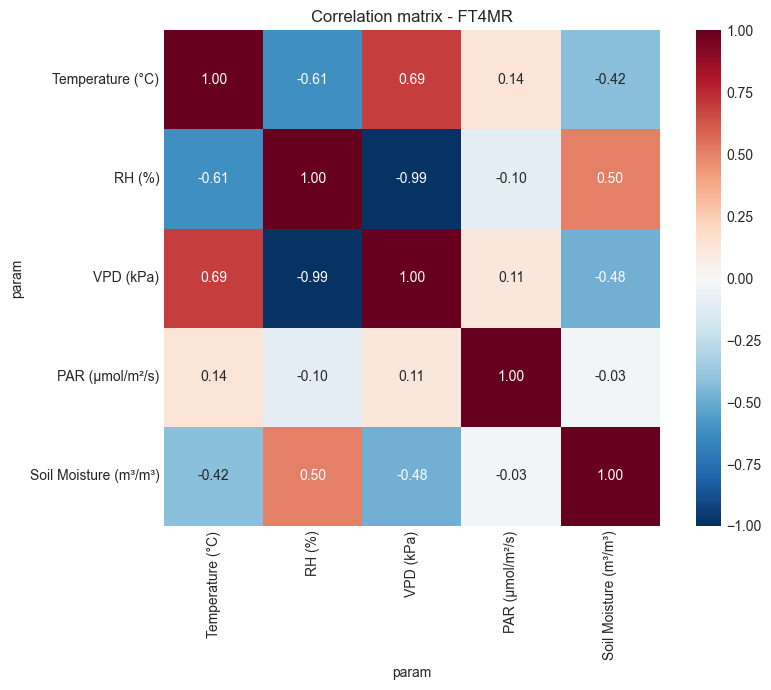


FT4MR correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.613  0.692  0.138         -0.421
rh            -0.613  1.000 -0.988 -0.102          0.501
vpd            0.692 -0.988  1.000  0.113         -0.480
par            0.138 -0.102  0.113  1.000         -0.026
soil moisture -0.421  0.501 -0.480 -0.026          1.000


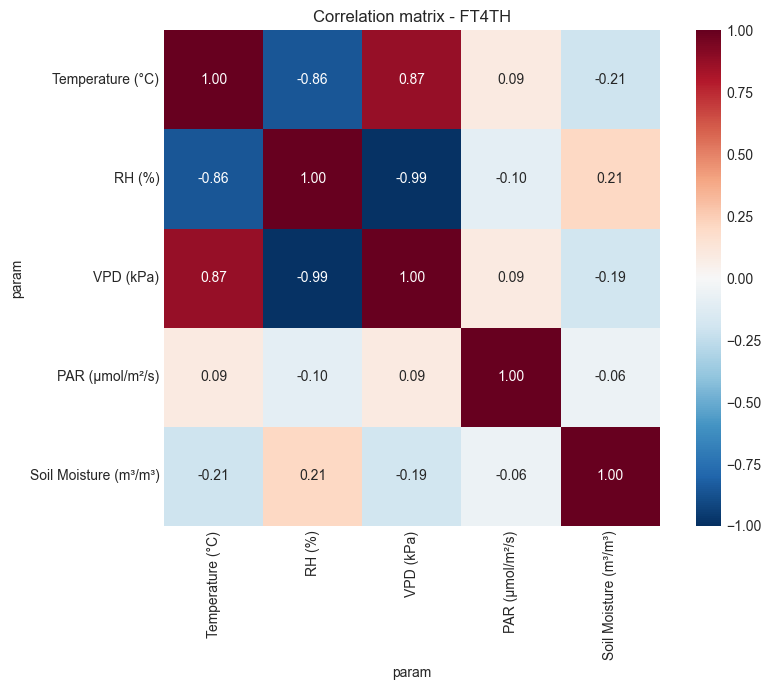


FT4TH correlation matrix:
param           temp     rh    vpd    par  soil moisture
param                                                   
temp           1.000 -0.858  0.868  0.089         -0.207
rh            -0.858  1.000 -0.989 -0.102          0.209
vpd            0.868 -0.989  1.000  0.093         -0.194
par            0.089 -0.102  0.093  1.000         -0.058
soil moisture -0.207  0.209 -0.194 -0.058          1.000


In [49]:
# Part 8: Correlation matrices (overall + per-site)
# Uses cleaned long-form data (expects columns: plot, param, value)

corr_source = df.copy() if 'df' in globals() else df_raw.copy()
required_cols = {'plot', 'param', 'value'}
if not required_cols.issubset(corr_source.columns):
    missing = required_cols - set(corr_source.columns)
    raise ValueError(f'Missing required columns for correlation analysis: {missing}')

corr_params = ['temp', 'rh', 'vpd', 'par', 'soil moisture']
label_map = {
    'temp': 'Temperature (°C)',
    'rh': 'RH (%)',
    'vpd': 'VPD (kPa)',
    'par': 'PAR (μmol/m²/s)',
    'soil moisture': 'Soil Moisture (m³/m³)'
}

corr_df = corr_source[corr_source['param'].isin(corr_params)].copy()
if corr_df.empty:
    raise ValueError('No rows found for correlation parameters in the current dataframe.')

# Align variables by timestamp + site to ensure valid pairwise comparisons
id_cols = ['datetime', 'plot'] if 'datetime' in corr_df.columns else ['time', 'plot'] if 'time' in corr_df.columns else ['plot']
df_wide = (
    corr_df
    .pivot_table(index=id_cols, columns='param', values='value', aggfunc='mean')
    .dropna(how='all')
    .reset_index()
)

value_cols = [p for p in corr_params if p in df_wide.columns]
if len(value_cols) < 2:
    raise ValueError('Not enough variables available after pivot for correlation matrix.')

print('Variables included in correlation analysis:', [label_map[p] for p in value_cols])

# Overall matrix
overall_corr = df_wide[value_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(
    overall_corr,
    annot=True,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    fmt='.2f',
    xticklabels=[label_map[c] for c in overall_corr.columns],
    yticklabels=[label_map[c] for c in overall_corr.index]
)
plt.title('Overall correlation matrix (all sites)')
plt.tight_layout()
plt.show()

print('\nOverall correlation matrix:')
print(overall_corr.round(3))

# Per-site matrices
sites = [s for s in SITE_ORDER if s in df_wide['plot'].unique()] if 'SITE_ORDER' in globals() else sorted(df_wide['plot'].dropna().unique())
for plot in sites:
    site_data = df_wide[df_wide['plot'] == plot][value_cols]
    site_data = site_data.dropna(how='all')
    if len(site_data) < 3:
        print(f'\nSkipping {plot}: insufficient rows ({len(site_data)}) for stable correlations.')
        continue

    site_corr = site_data.corr()

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        site_corr,
        annot=True,
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        fmt='.2f',
        xticklabels=[label_map[c] for c in site_corr.columns],
        yticklabels=[label_map[c] for c in site_corr.index]
    )
    plt.title(f'Correlation matrix - {plot}')
    plt.tight_layout()
    plt.show()

    print(f'\n{plot} correlation matrix:')
    print(site_corr.round(3))


### Reading the relationship results

The heatmap reports the median association calculated separately within each plot. Brackets show the 95% moving-block bootstrap interval. This reduces the false confidence that would come from treating neighbouring days and repeated observations from the same plot as independent. The values describe association only.

### Figures: variable relationships

The heatmap uses daily, plot-aligned Spearman correlations. Scatter plots provide a visual check on the strongest relationships.

The figures below are embedded in this notebook after the analysis runs. They are also saved in `outputs/redesigned/` for use in the report.


**Daily Spearman correlation heatmap**

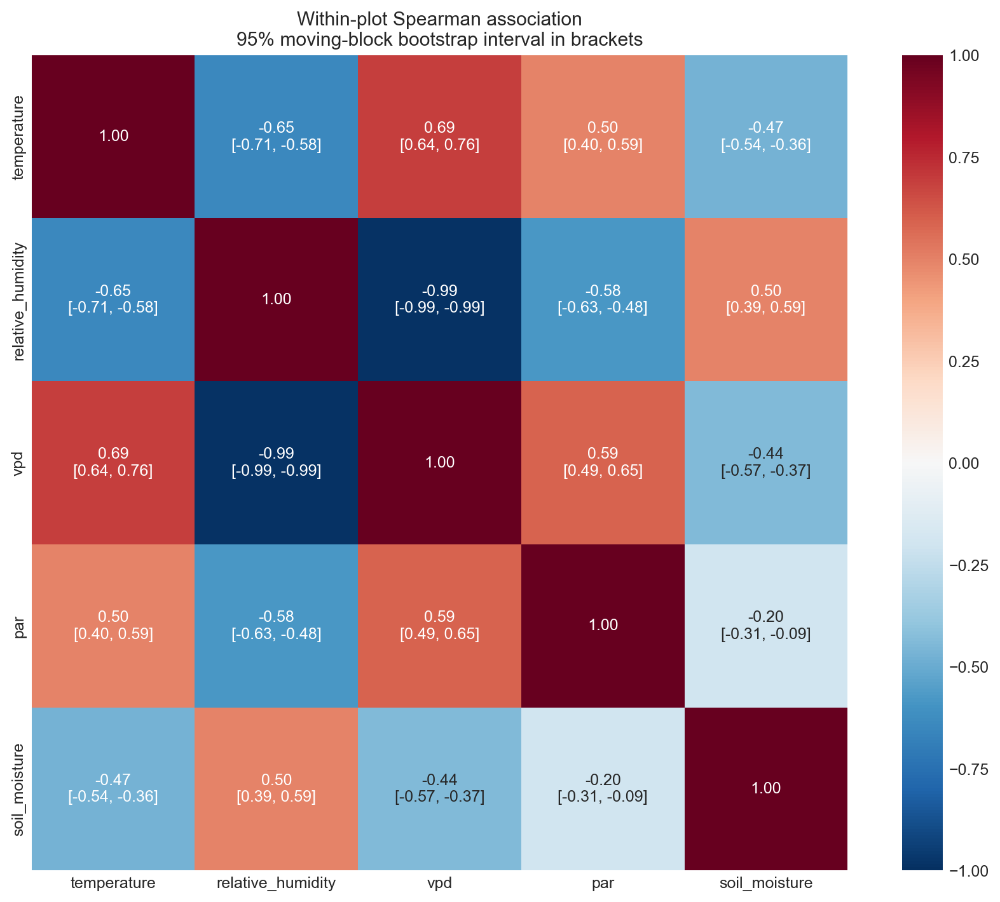

**Daily relationship scatter plots**

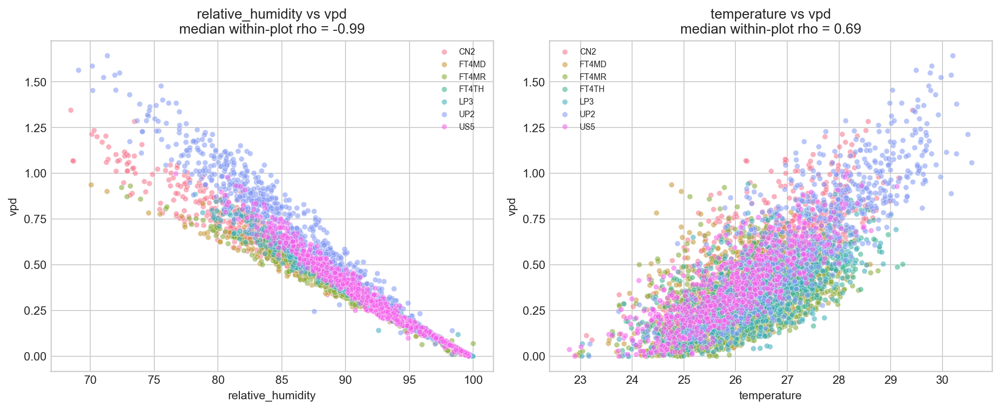

In [50]:
from IPython.display import Image, Markdown, display

_figures = [
    ('Daily Spearman correlation heatmap', 'readiness/daily_spearman_heatmap.png'),
    ('Daily relationship scatter plots', 'readiness/daily_relationship_scatter.png')
]
_missing = []
for _caption, _relative_path in _figures:
    _path = Path(OUT_ROOT) / _relative_path
    if _path.exists():
        display(Markdown(f'**{_caption}**'))
        display(Image(filename=str(_path)))
    else:
        _missing.append(_relative_path)
if _missing:
    print('Figures not found:', ', '.join(_missing))


## 6. Soil-moisture drydown analysis

This section identifies multi-day drying events, compares drying rates and half-lives, and examines whether available plot-summary traits improve held-out drydown prediction.


### 6.1 Drydown, half-life, and daily-envelope setup

The site-wise daily time-series plots used earlier in the exploratory section have been removed so the EDA now stays with the box and violin comparisons. From this point onward, the soil-moisture work is event-based: it looks at post-rain drydown behaviour, half-life, within-day moisture spread, and the links with plot-level traits.


In [51]:
# ── Soil moisture setup for drydown, half-life, and daily envelope work ──
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from IPython.display import display, Image

if 'SITE_ORDER' not in globals():
    SITE_ORDER = ['UP2', 'US5', 'CN2', 'LP3', 'FT4MD', 'FT4MR', 'FT4TH']
if 'PROJECT_ROOT' not in globals():
    PROJECT_ROOT = Path.cwd().resolve()
if 'OUT_ROOT' not in globals():
    OUT_ROOT = str(PROJECT_ROOT / 'outputs' / 'redesigned')

if 'soil_daily' not in globals():
    source_df = None
    if 'df' in globals():
        source_df = df.copy()
    elif 'df_hard_clean' in globals():
        source_df = df_hard_clean.copy()
    else:
        candidate_files = [
            PROJECT_ROOT / 'data' / 'processed' / 'microclimate_data_cleaned.csv',
            PROJECT_ROOT / 'data' / 'raw' / 'microclimate_data.csv',
            PROJECT_ROOT / 'microclimate_data_cleaned.csv',
            PROJECT_ROOT / 'microclimate_data.csv',
        ]
        for candidate in candidate_files:
            if candidate.exists():
                source_df = pd.read_csv(candidate, low_memory=False)
                print(f'Loaded source data for soil-moisture analysis: {candidate}')
                break
        if source_df is None:
            raise FileNotFoundError('No source dataframe or CSV file found for soil-moisture analysis.')

    source_df['time'] = pd.to_datetime(source_df['time'], errors='coerce')
    source_df['value'] = pd.to_numeric(source_df['value'], errors='coerce')
    source_df['plot'] = source_df['plot'].fillna('Unknown')
    source_df = source_df.dropna(subset=['time', 'value', 'plot', 'param'])

    soil_raw_local = source_df[source_df['param'].astype(str).str.lower() == 'soil moisture'].copy()
    soil_raw_local = soil_raw_local[(soil_raw_local['value'] >= 0) & (soil_raw_local['value'] <= 0.6)]

    soil_daily = (
        soil_raw_local
        .groupby(['plot', pd.Grouper(key='time', freq='D')])['value']
        .agg(daily_mean='mean', daily_min='min', daily_max='max', n_obs='count')
        .reset_index()
        .rename(columns={'time': 'date'})
    )
    if 'ft' in soil_raw_local.columns:
        plot_to_ft_local = soil_raw_local[['plot', 'ft']].drop_duplicates().set_index('plot')['ft']
        soil_daily['ft'] = soil_daily['plot'].map(plot_to_ft_local)
    else:
        soil_daily['ft'] = np.nan

soil_daily_dd = soil_daily.sort_values(['plot', 'date']).copy()
soil_daily_dd['date'] = pd.to_datetime(soil_daily_dd['date'])
soil_daily_dd['ft'] = soil_daily_dd['ft'].fillna('Unknown')
soil_daily_dd['daily_range'] = soil_daily_dd['daily_max'] - soil_daily_dd['daily_min']
soil_daily_dd['mean_roll7'] = soil_daily_dd.groupby('plot')['daily_mean'].transform(lambda s: s.rolling(7, min_periods=1).mean())
soil_daily_dd['max_roll3'] = soil_daily_dd.groupby('plot')['daily_max'].transform(lambda s: s.rolling(3, min_periods=1).mean())
soil_daily_dd['min_roll3'] = soil_daily_dd.groupby('plot')['daily_min'].transform(lambda s: s.rolling(3, min_periods=1).mean())
soil_daily_dd['range_roll7'] = soil_daily_dd.groupby('plot')['daily_range'].transform(lambda s: s.rolling(7, min_periods=1).mean())

sites_soil = [s for s in SITE_ORDER if s in soil_daily_dd['plot'].unique()] if 'SITE_ORDER' in globals() else sorted(soil_daily_dd['plot'].unique())
out_soil = os.path.join(OUT_ROOT, 'soil_moisture')
os.makedirs(out_soil, exist_ok=True)

drydown_ft_colors = {
    'FT1': '#d95f02',
    'FT2': '#1b9e77',
    'FT3': '#7570b3',
    'FT4': '#1f78b4',
    'Unknown': '#444444',
}

soil_drydown_cfg = {
    'signal_col': 'daily_max',
    'min_len': 4,
    'min_drop': 0.015,
    'max_rewet': 0.003,
    'interp_days': 10,
}
print('Drydown config:', soil_drydown_cfg)
print(f'Soil daily rows: {len(soil_daily_dd):,} | Sites: {sites_soil}')


def half_crossing(t, r):
    valid = np.isfinite(r)
    t = np.asarray(t)[valid]
    r = np.asarray(r)[valid]
    if len(r) == 0 or np.nanmin(r) > 0.5:
        return np.nan
    idx = np.where(r <= 0.5)[0]
    j = idx[0]
    if j == 0:
        return float(t[0])
    t0, t1 = t[j - 1], t[j]
    r0, r1 = r[j - 1], r[j]
    if r1 == r0:
        return float(t1)
    return float(t0 + (0.5 - r0) * (t1 - t0) / (r1 - r0))


def detect_soil_drydowns(daily_df, signal_col='daily_max', min_len=4, min_drop=0.015, max_rewet=0.003, interp_days=10):
    events = []
    curves = []
    for site, s0 in daily_df.groupby('plot'):
        s = s0.sort_values('date').reset_index(drop=True).copy()
        signal = s[signal_col].to_numpy(dtype=float)
        smooth = pd.Series(signal).rolling(3, min_periods=1).mean().to_numpy()
        dates = s['date'].to_numpy()
        ft = s['ft'].iloc[0]
        event_id = 0
        i = 1
        while i < len(s) - min_len:
            if smooth[i] >= smooth[i - 1] and smooth[i] > smooth[i + 1]:
                start = i
                j = i + 1
                neg_steps = 0
                while j < len(s):
                    step = smooth[j] - smooth[j - 1]
                    if step <= max_rewet:
                        if step < 0:
                            neg_steps += 1
                        j += 1
                    else:
                        break
                end = j - 1
                if end - start + 1 >= min_len:
                    y = signal[start:end + 1].astype(float)
                    t = np.arange(len(y), dtype=float)
                    drop = y[0] - y[-1]
                    if drop >= min_drop and neg_steps >= min_len - 1:
                        remaining = (y - y[-1]) / drop
                        empirical_half = half_crossing(t, remaining)
                        mask = (t > 0) & (remaining > 0) & (remaining < 1)
                        decay_k = np.nan
                        exp_half = np.nan
                        fit_r2 = np.nan
                        if mask.sum() >= 2:
                            coeff = np.polyfit(t[mask], np.log(remaining[mask]), 1)
                            pred = np.polyval(coeff, t[mask])
                            obs = np.log(remaining[mask])
                            ss_res = ((obs - pred) ** 2).sum()
                            ss_tot = ((obs - obs.mean()) ** 2).sum()
                            fit_r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
                            decay_k = -coeff[0]
                            if decay_k > 0:
                                exp_half = np.log(2) / decay_k
                        linear_rate = np.polyfit(t, y, 1)[0] if len(t) >= 2 else np.nan
                        mean_step = np.diff(y).mean() if len(y) >= 2 else np.nan
                        events.append({
                            'plot': site,
                            'ft': ft,
                            'event_id': event_id,
                            'signal_used': signal_col,
                            'start_date': pd.Timestamp(dates[start]),
                            'end_date': pd.Timestamp(dates[end]),
                            'duration_days': int(len(y)),
                            'start_signal': float(y[0]),
                            'end_signal': float(y[-1]),
                            'total_loss': float(drop),
                            'linear_rate': float(linear_rate),
                            'mean_daily_change': float(mean_step),
                            'empirical_half_life_days': empirical_half,
                            'exp_decay_k': float(decay_k) if pd.notna(decay_k) else np.nan,
                            'exp_half_life_days': float(exp_half) if pd.notna(exp_half) else np.nan,
                            'exp_fit_r2': float(fit_r2) if pd.notna(fit_r2) else np.nan,
                        })
                        grid = np.arange(0, interp_days + 1, 1.0)
                        curve = np.interp(grid, t, remaining, left=np.nan, right=np.nan)
                        fit_curve = np.exp(-decay_k * grid) if pd.notna(decay_k) and decay_k > 0 else np.full_like(grid, np.nan, dtype=float)
                        for gd, rv, fv in zip(grid, curve, fit_curve):
                            curves.append({
                                'plot': site,
                                'ft': ft,
                                'event_id': event_id,
                                't_day': float(gd),
                                'remaining_fraction': float(rv) if pd.notna(rv) else np.nan,
                                'fit_fraction': float(fv) if pd.notna(fv) else np.nan,
                            })
                        event_id += 1
                        i = end
            i += 1
    return pd.DataFrame(events), pd.DataFrame(curves)


Drydown config: {'signal_col': 'daily_max', 'min_len': 4, 'min_drop': 0.015, 'max_rewet': 0.003, 'interp_days': 10}
Soil daily rows: 2,662 | Sites: ['UP2', 'US5', 'CN2', 'LP3', 'FT4MD', 'FT4MR', 'FT4TH']



Detected drydown events by site:
plot
CN2      27
FT4MD    38
FT4MR    25
FT4TH    11
LP3      42
UP2      28
US5      35

Drydown summary:
 plot  ft  n_events  median_duration_days  median_total_loss  abs_median_drying_rate
  CN2 FT2        27                   6.0             0.0908                  0.0163
FT4MD FT4        38                   6.0             0.0537                  0.0084
FT4MR FT4        25                   5.0             0.0704                  0.0115
FT4TH FT4        11                   4.0             0.0639                  0.0121
  LP3 FT3        42                   5.0             0.1144                  0.0208
  UP2 FT1        28                   6.0             0.0690                  0.0117
  US5 FT1        35                   5.0             0.0777                  0.0149

Fastest median drying: LP3 (FT3) at 0.0208 m3/m3/day
Slowest median drying: FT4MD (FT4) at 0.0084 m3/m3/day
Most detected drydown events: LP3 with 42 events


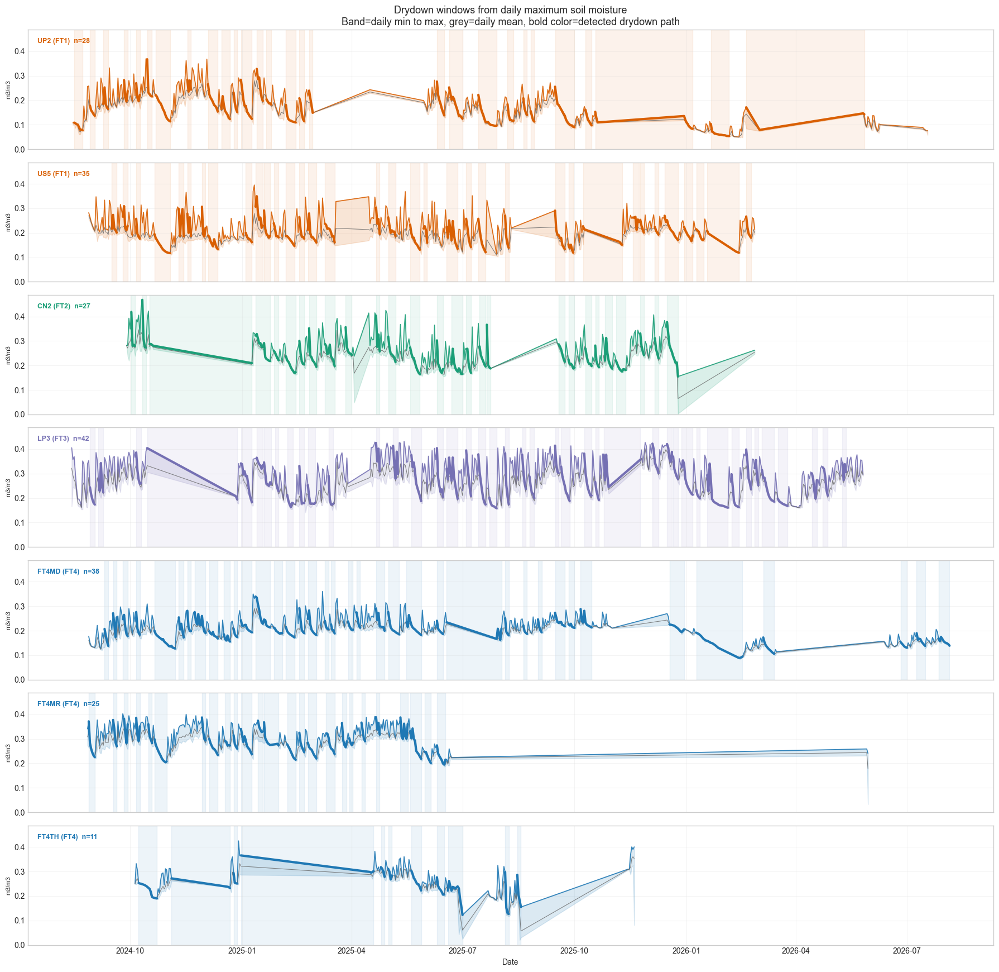

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_D_drydown_event_timeline.png


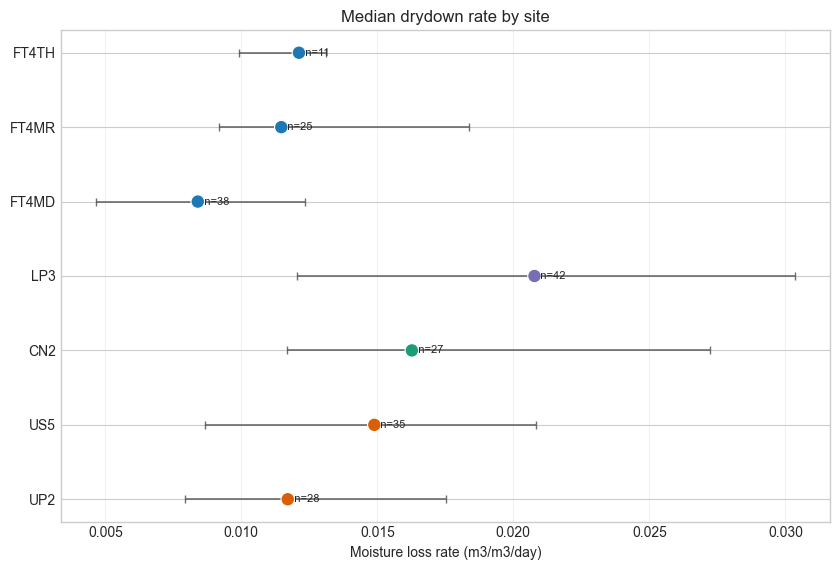

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_E_drying_rate_summary.png


In [52]:
# ── Drydown-rate analysis and drydown figures ────────────────────────────
soil_drydown_events, soil_drydown_curves = detect_soil_drydowns(soil_daily_dd, **soil_drydown_cfg)
if soil_drydown_events.empty:
    raise ValueError('No soil drydown events detected with the current thresholds.')

soil_drydown_summary = (
    soil_drydown_events.groupby(['plot', 'ft'])
    .agg(
        n_events=('event_id', 'nunique'),
        median_duration_days=('duration_days', 'median'),
        median_total_loss=('total_loss', 'median'),
        median_linear_drying_rate=('linear_rate', 'median'),
        median_daily_step=('mean_daily_change', 'median'),
        median_empirical_half_life_days=('empirical_half_life_days', 'median'),
        median_exp_half_life_days=('exp_half_life_days', 'median'),
        median_exp_decay_k=('exp_decay_k', 'median'),
        median_exp_fit_r2=('exp_fit_r2', 'median'),
    )
    .reset_index()
)
soil_drydown_summary['abs_median_drying_rate'] = -soil_drydown_summary['median_linear_drying_rate']
soil_drydown_summary.to_csv(os.path.join(out_soil, 'soil_drydown_summary.csv'), index=False)
soil_drydown_events.to_csv(os.path.join(out_soil, 'soil_drydown_events.csv'), index=False)

fastest_row = soil_drydown_summary.loc[soil_drydown_summary['abs_median_drying_rate'].idxmax()]
slowest_row = soil_drydown_summary.loc[soil_drydown_summary['abs_median_drying_rate'].idxmin()]
most_events_row = soil_drydown_summary.loc[soil_drydown_summary['n_events'].idxmax()]

print('\nDetected drydown events by site:')
print(soil_drydown_events.groupby('plot').size().to_string())
print('\nDrydown summary:')
print(soil_drydown_summary[['plot', 'ft', 'n_events', 'median_duration_days', 'median_total_loss', 'abs_median_drying_rate']].round(4).to_string(index=False))
print(f"\nFastest median drying: {fastest_row['plot']} ({fastest_row['ft']}) at {fastest_row['abs_median_drying_rate']:.4f} m3/m3/day")
print(f"Slowest median drying: {slowest_row['plot']} ({slowest_row['ft']}) at {slowest_row['abs_median_drying_rate']:.4f} m3/m3/day")
print(f"Most detected drydown events: {most_events_row['plot']} with {int(most_events_row['n_events'])} events")

fig, axes = plt.subplots(len(sites_soil), 1, figsize=(18, 2.5 * len(sites_soil)), sharex=True, sharey=True)
if len(sites_soil) == 1:
    axes = [axes]
ymin = max(0, soil_daily_dd['daily_min'].min() - 0.02)
ymax = min(0.6, soil_daily_dd['daily_max'].max() + 0.02)
for ax, site in zip(axes, sites_soil):
    s = soil_daily_dd[soil_daily_dd['plot'] == site].sort_values('date')
    ft = s['ft'].iloc[0]
    col = drydown_ft_colors.get(ft, '#333333')
    ev = soil_drydown_events[soil_drydown_events['plot'] == site]
    ax.fill_between(s['date'], s['daily_min'], s['daily_max'], color=col, alpha=0.16, zorder=1)
    ax.plot(s['date'], s['daily_max'], color=col, lw=1.2, alpha=0.9, zorder=2)
    ax.plot(s['date'], s['daily_mean'], color='#666666', lw=0.8, alpha=0.8, zorder=2)
    for _, row in ev.iterrows():
        mask = (s['date'] >= row['start_date']) & (s['date'] <= row['end_date'])
        ax.plot(s.loc[mask, 'date'], s.loc[mask, 'daily_max'], color=col, lw=3.0, zorder=3)
        ax.axvspan(row['start_date'], row['end_date'], color=col, alpha=0.08, zorder=0)
    ax.text(0.01, 0.93, f'{site} ({ft})  n={len(ev)}', transform=ax.transAxes, va='top', fontsize=9, color=col, fontweight='bold')
    ax.set_ylim(ymin, ymax)
    ax.grid(alpha=0.2)
    ax.set_ylabel('m3/m3', fontsize=8)
axes[0].set_title('Drydown windows from daily maximum soil moisture\nBand=daily min to max, grey=daily mean, bold color=detected drydown path', fontsize=13)
axes[-1].set_xlabel('Date')
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_D_drydown_event_timeline.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_D_drydown_event_timeline.png')}")

plot_df = soil_drydown_summary.copy()
plot_df['plot'] = pd.Categorical(plot_df['plot'], categories=sites_soil, ordered=True)
plot_df = plot_df.sort_values('plot')
fig, ax = plt.subplots(figsize=(8.5, 5.8))
lower = []
upper = []
for _, row in plot_df.iterrows():
    ev = soil_drydown_events[soil_drydown_events['plot'] == row['plot']]
    series = -ev['linear_rate']
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    med = series.median()
    lower.append(max(0, med - q1))
    upper.append(max(0, q3 - med))
colors = [drydown_ft_colors.get(ft, '#333333') for ft in plot_df['ft']]
ax.errorbar(plot_df['abs_median_drying_rate'], plot_df['plot'], xerr=[lower, upper], fmt='none', ecolor='#555555', elinewidth=1.2, alpha=0.85, capsize=3)
ax.scatter(plot_df['abs_median_drying_rate'], plot_df['plot'], s=95, c=colors, edgecolor='white', linewidth=0.8, zorder=3)
for _, row in plot_df.iterrows():
    ax.text(row['abs_median_drying_rate'], row['plot'], f"  n={int(row['n_events'])}", va='center', fontsize=8)
ax.set_title('Median drydown rate by site')
ax.set_xlabel('Moisture loss rate (m3/m3/day)')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_E_drying_rate_summary.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_E_drying_rate_summary.png')}")


### What stands out in the drying rates?

#### How the drying rate was calculated
- A drydown event starts at a local daily-max peak and follows the decline that comes after it.
- For each event, daily maximum soil moisture is fitted with `M_max(t) = a + bt`.
- `b` is the event slope. Because drydown slopes are negative, the summary plot shows `abs_drying_rate = -b`.
- Site values are the median across all detected events.

#### Interpretation
This figure gives the cleanest ranking of post-rain drying. `LP3` stands out as the fastest-drying site, while `FT4MD` is the slowest. The difference is not coming from one unusual event; it shows up repeatedly across events.

This graph is better for modelling because it isolates the actual loss phase after recharge. It tells us how sharply each site gives up water once drying begins.


### How long does the wet pulse last at each site?

Drying rate tells us how steep the drop is. Half-life tells us how long the wet signal lasts.

To compare events fairly, each one is normalized to a remaining-water fraction:
`R(t) = (M_max(t) - M_max(t1)) / (M_max(t0) - M_max(t1))`

Then we ask when that normalized event reaches half of its starting value.



Half-life summary:
 plot  ft  n_events  median_empirical_half_life_days  median_exp_half_life_days  median_exp_fit_r2
  UP2 FT1        28                           1.5000                     1.2296             0.9545
  US5 FT1        35                           1.5062                     1.5286             0.9306
  CN2 FT2        27                           1.3097                     1.3155             0.9721
  LP3 FT3        42                           1.0044                     1.0211             0.9775
FT4MD FT4        38                           1.2209                     1.8971             0.9735
FT4MR FT4        25                           0.8720                     1.0782             0.9798
FT4TH FT4        11                           0.9902                     1.3004             1.0000

Longest empirical half-life: US5 (FT1) at 1.51 days
Shortest empirical half-life: FT4MR (FT4) at 0.87 days
Strongest exponential fit: FT4TH with median R2 = 1.000


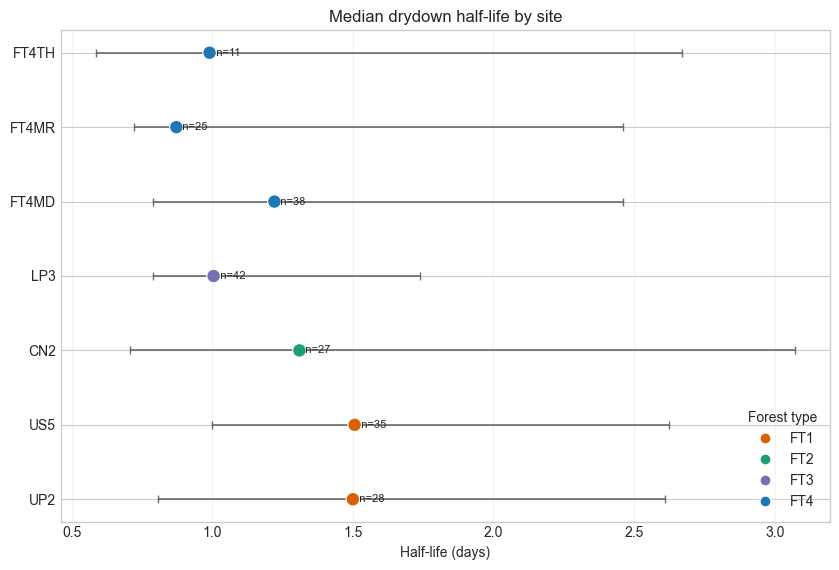

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_F_half_life_summary.png


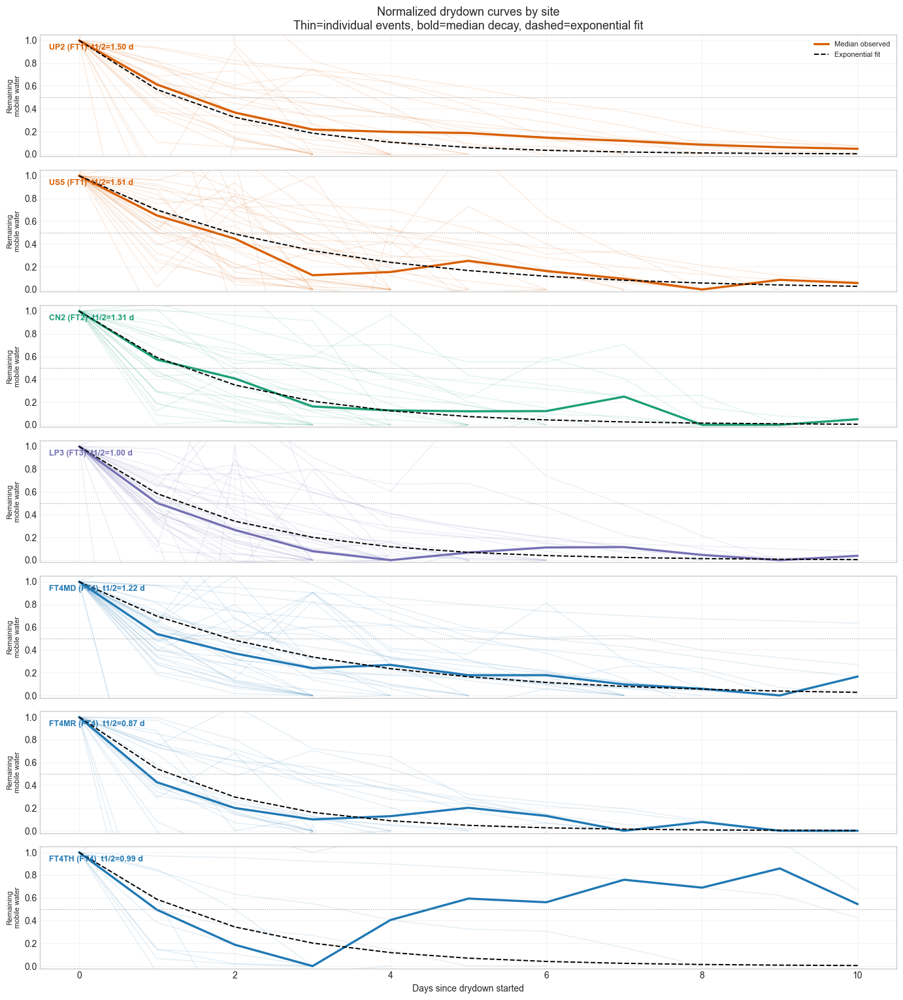

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_G_normalized_drydown_curves.png


In [53]:
# ── Half-life analysis and normalized drydown curves ─────────────────────
plot_df = soil_drydown_summary.copy()
plot_df['plot'] = pd.Categorical(plot_df['plot'], categories=sites_soil, ordered=True)
plot_df = plot_df.sort_values('plot')

longest_half_row = plot_df.loc[plot_df['median_empirical_half_life_days'].idxmax()]
shortest_half_row = plot_df.loc[plot_df['median_empirical_half_life_days'].idxmin()]
best_fit_row = plot_df.loc[plot_df['median_exp_fit_r2'].idxmax()]

print('\nHalf-life summary:')
print(plot_df[['plot', 'ft', 'n_events', 'median_empirical_half_life_days', 'median_exp_half_life_days', 'median_exp_fit_r2']].round(4).to_string(index=False))
print(f"\nLongest empirical half-life: {longest_half_row['plot']} ({longest_half_row['ft']}) at {longest_half_row['median_empirical_half_life_days']:.2f} days")
print(f"Shortest empirical half-life: {shortest_half_row['plot']} ({shortest_half_row['ft']}) at {shortest_half_row['median_empirical_half_life_days']:.2f} days")
print(f"Strongest exponential fit: {best_fit_row['plot']} with median R2 = {best_fit_row['median_exp_fit_r2']:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 5.8))
lower = []
upper = []
for _, row in plot_df.iterrows():
    ev = soil_drydown_events[soil_drydown_events['plot'] == row['plot']]
    series = ev['empirical_half_life_days']
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    med = series.median()
    lower.append(max(0, med - q1))
    upper.append(max(0, q3 - med))
colors = [drydown_ft_colors.get(ft, '#333333') for ft in plot_df['ft']]
ax.errorbar(plot_df['median_empirical_half_life_days'], plot_df['plot'], xerr=[lower, upper], fmt='none', ecolor='#555555', elinewidth=1.2, alpha=0.85, capsize=3)
ax.scatter(plot_df['median_empirical_half_life_days'], plot_df['plot'], s=95, c=colors, edgecolor='white', linewidth=0.8, zorder=3)
for _, row in plot_df.iterrows():
    ax.text(row['median_empirical_half_life_days'], row['plot'], f"  n={int(row['n_events'])}", va='center', fontsize=8)
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=drydown_ft_colors[ft], label=ft, markersize=8) for ft in ['FT1', 'FT2', 'FT3', 'FT4'] if ft in plot_df['ft'].values]
if handles:
    ax.legend(handles=handles, title='Forest type', loc='lower right', frameon=False)
ax.set_title('Median drydown half-life by site')
ax.set_xlabel('Half-life (days)')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_F_half_life_summary.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_F_half_life_summary.png')}")

fig, axes = plt.subplots(len(sites_soil), 1, figsize=(14, 2.2 * len(sites_soil)), sharex=True, sharey=True)
if len(sites_soil) == 1:
    axes = [axes]
for ax, site in zip(axes, sites_soil):
    c = soil_drydown_curves[soil_drydown_curves['plot'] == site]
    if c.empty:
        ax.axis('off')
        continue
    ft = c['ft'].iloc[0]
    col = drydown_ft_colors.get(ft, '#333333')
    site_k = plot_df.loc[plot_df['plot'] == site, 'median_exp_decay_k'].iloc[0]
    site_half = plot_df.loc[plot_df['plot'] == site, 'median_empirical_half_life_days'].iloc[0]
    for _, g in c.groupby('event_id'):
        ax.plot(g['t_day'], g['remaining_fraction'], color=col, alpha=0.12, lw=1)
    med = c.groupby('t_day')['remaining_fraction'].median().reset_index()
    fit = np.exp(-site_k * med['t_day']) if pd.notna(site_k) else np.full(len(med), np.nan)
    ax.plot(med['t_day'], med['remaining_fraction'], color=col, lw=2.4, label='Median observed')
    ax.plot(med['t_day'], fit, color='black', ls='--', lw=1.4, label='Exponential fit')
    ax.axhline(0.5, color='#999999', ls=':', lw=0.8)
    ax.text(0.01, 0.93, f'{site} ({ft})  t1/2={site_half:.2f} d', transform=ax.transAxes, va='top', fontsize=9, color=col, fontweight='bold')
    ax.set_ylim(-0.02, 1.05)
    ax.grid(alpha=0.2)
    ax.set_ylabel('Remaining\nmobile water', fontsize=8)
axes[0].legend(loc='upper right', frameon=False, fontsize=8)
axes[0].set_title('Normalized drydown curves by site\nThin=individual events, bold=median decay, dashed=exponential fit', fontsize=13)
axes[-1].set_xlabel('Days since drydown started')
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_G_normalized_drydown_curves.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_G_normalized_drydown_curves.png')}")


### Which sites hold onto moisture for longer?

#### How half-life was calculated
- Each event is normalized to a common scale using
  `R(t) = (M_max(t) - M_max(t1)) / (M_max(t0) - M_max(t1))`,
  so every event starts near `1` and ends near `0`.
- Empirical half-life is the first time when `R(t) = 0.5`.
- An exponential fit is also applied: `R(t) = exp(-k t)`.
- From that fit, exponential half-life is `t_half = ln(2) / k`.
- Site values are the median across events.

#### Interpretation
Drying rate tells us how steep the decline is; half-life tells us how long the wet signal persists. `US5` and `UP2` hold water for longer, while `FT4MR` drops to half-remaining water sooner.

The normalized curves matter because some sites lose water quickly at the start and then flatten out, while others decline more evenly. So half-life adds shape and persistence, not just speed.


### How wide is the moisture band within a day?

The last soil-moisture figure is not about multi-day drydown. It is about the **within-day spread** between the wettest and driest readings.

That spread is:
`Daily range(t) = M_max(t) - M_min(t)`

So this part tells us how dynamically each site moves within a day, which is different from how quickly it dries across an event.



Daily max/min envelope summary:
 plot  ft  median_daily_mean  median_daily_min  median_daily_max  median_daily_range  p90_daily_max  p10_daily_min
  CN2 FT2             0.2280            0.2153            0.2523              0.0225         0.3526         0.1702
FT4MD FT4             0.1966            0.1884            0.2058              0.0102         0.2719         0.1318
FT4MR FT4             0.2845            0.2698            0.3068              0.0283         0.3685         0.2193
FT4TH FT4             0.2407            0.2254            0.2545              0.0210         0.3311         0.1601
  LP3 FT3             0.2557            0.2280            0.2974              0.0443         0.3869         0.1673
  UP2 FT1             0.1525            0.1368            0.1681              0.0189         0.2668         0.0729
  US5 FT1             0.1861            0.1706            0.2109              0.0313         0.2938         0.1287

Widest median daily range: LP3 (FT3) at 0.0443

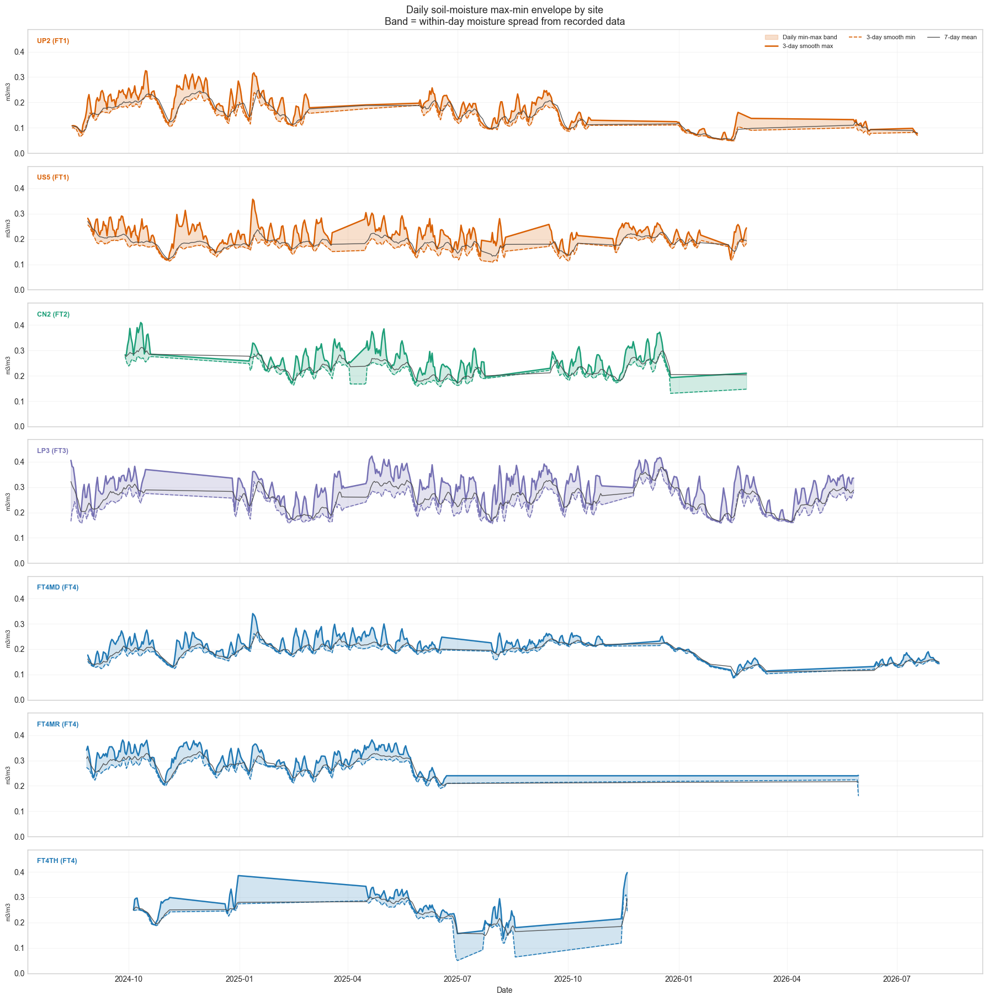

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_H_daily_max_min_envelope.png


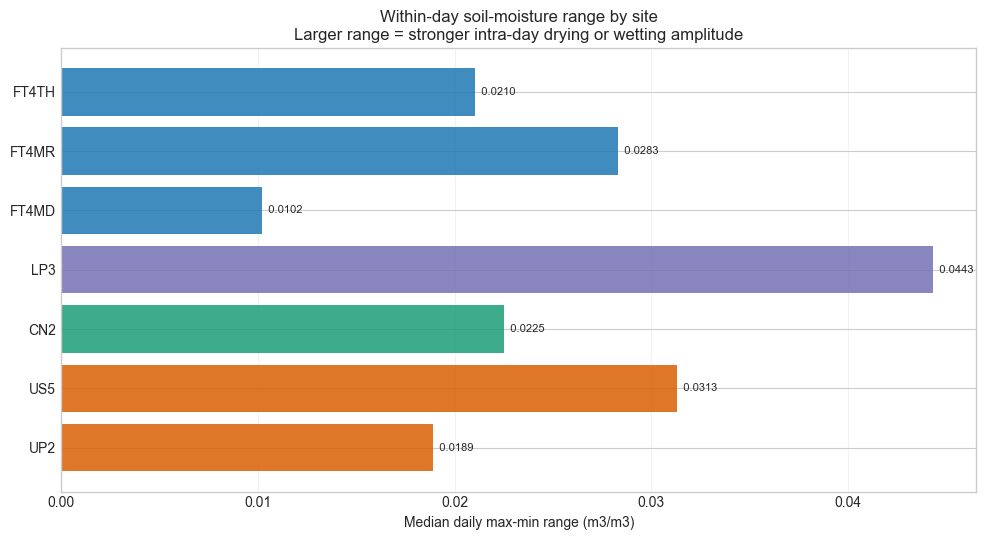

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_I_daily_range_summary.png


In [54]:
# ── Daily max/min envelope and daily range figures ───────────────────────
soil_daily_extremes_summary = (
    soil_daily_dd.groupby(['plot', 'ft'])
    .agg(
        median_daily_mean=('daily_mean', 'median'),
        median_daily_min=('daily_min', 'median'),
        median_daily_max=('daily_max', 'median'),
        median_daily_range=('daily_range', 'median'),
        p90_daily_max=('daily_max', lambda s: s.quantile(0.90)),
        p10_daily_min=('daily_min', lambda s: s.quantile(0.10)),
    )
    .reset_index()
)
soil_daily_extremes_summary.to_csv(os.path.join(out_soil, 'soil_daily_extremes_summary.csv'), index=False)

widest_range_row = soil_daily_extremes_summary.loc[soil_daily_extremes_summary['median_daily_range'].idxmax()]
narrowest_range_row = soil_daily_extremes_summary.loc[soil_daily_extremes_summary['median_daily_range'].idxmin()]
highest_max_row = soil_daily_extremes_summary.loc[soil_daily_extremes_summary['median_daily_max'].idxmax()]

print('\nDaily max/min envelope summary:')
print(soil_daily_extremes_summary.round(4).to_string(index=False))
print(f"\nWidest median daily range: {widest_range_row['plot']} ({widest_range_row['ft']}) at {widest_range_row['median_daily_range']:.4f} m3/m3")
print(f"Narrowest median daily range: {narrowest_range_row['plot']} ({narrowest_range_row['ft']}) at {narrowest_range_row['median_daily_range']:.4f} m3/m3")
print(f"Highest median daily maximum: {highest_max_row['plot']} ({highest_max_row['ft']}) at {highest_max_row['median_daily_max']:.4f} m3/m3")

ymin = max(0, soil_daily_dd['daily_min'].min() - 0.02)
ymax = min(0.6, soil_daily_dd['daily_max'].max() + 0.02)
fig, axes = plt.subplots(len(sites_soil), 1, figsize=(18, 2.6 * len(sites_soil)), sharex=True, sharey=True)
if len(sites_soil) == 1:
    axes = [axes]
for ax, site in zip(axes, sites_soil):
    s = soil_daily_dd[soil_daily_dd['plot'] == site].sort_values('date')
    ft = s['ft'].iloc[0]
    col = drydown_ft_colors.get(ft, '#333333')
    ax.fill_between(s['date'], s['min_roll3'], s['max_roll3'], color=col, alpha=0.20, label='Daily min-max band')
    ax.plot(s['date'], s['max_roll3'], color=col, lw=1.8, label='3-day smooth max')
    ax.plot(s['date'], s['min_roll3'], color=col, lw=1.2, ls='--', label='3-day smooth min')
    ax.plot(s['date'], s['mean_roll7'], color='#444444', lw=1.0, alpha=0.9, label='7-day mean')
    ax.text(0.01, 0.93, f'{site} ({ft})', transform=ax.transAxes, va='top', fontsize=9, color=col, fontweight='bold')
    ax.set_ylim(ymin, ymax)
    ax.grid(alpha=0.2)
    ax.set_ylabel('m3/m3', fontsize=8)
axes[0].legend(loc='upper right', frameon=False, fontsize=8, ncol=3)
axes[0].set_title('Daily soil-moisture max-min envelope by site\nBand = within-day moisture spread from recorded data', fontsize=13)
axes[-1].set_xlabel('Date')
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_H_daily_max_min_envelope.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_H_daily_max_min_envelope.png')}")

range_plot_df = soil_daily_extremes_summary.copy()
range_plot_df['plot'] = pd.Categorical(range_plot_df['plot'], categories=sites_soil, ordered=True)
range_plot_df = range_plot_df.sort_values('plot')
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [drydown_ft_colors.get(ft, '#333333') for ft in range_plot_df['ft']]
ax.barh(range_plot_df['plot'], range_plot_df['median_daily_range'], color=colors, alpha=0.85)
for _, row in range_plot_df.iterrows():
    ax.text(row['median_daily_range'], row['plot'], f"  {row['median_daily_range']:.4f}", va='center', fontsize=8)
ax.set_xlabel('Median daily max-min range (m3/m3)')
ax.set_title('Within-day soil-moisture range by site\nLarger range = stronger intra-day drying or wetting amplitude')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_I_daily_range_summary.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_I_daily_range_summary.png')}")


### What does the max-min spread tell us?

#### How the daily envelope was calculated
- The envelope uses the recorded daily minimum and daily maximum soil moisture directly.
- `Daily range(t) = M_max(t) - M_min(t)`.
- Short rolling smooths of daily max and min are used in the plot so the band is easier to read.
- Site summaries use the median daily range.

#### Interpretation
This graph shows the within-day side of the soil story. `LP3` has the widest daily spread, so it is not only fast-drying across events but also the most dynamic within a day. `FT4MD` stays narrow, which matches its less variable drydown record.

A useful contrast is `FT4MR`: it reaches a high daily maximum, but that does not automatically mean a long half-life. Peak wetness, drying slope and persistence are related, but they are not the same thing.


### Do the plot-level forest traits relate to these drydowns?

Up to this point, the drydown story is based on microclimate and soil data only. In this last step, we add `plot_summary.csv` so each drydown event also carries site context: growth, stem density, basal area, mortality, recruitment and diversity.

This lets us ask two simple questions:
1. do these site traits improve prediction of drying rate and half-life?
2. even if prediction does not improve, do they help explain why the sites differ?


### What this comparison is testing and how to read the scores

This section asks a simple modelling question: do the site traits from `plot_summary.csv` improve prediction of drydown behaviour beyond the event information alone? The test is strict leave-one-site-out validation, so each model is asked to predict a site that was left out of training.

#### What the prediction scores mean
- `MAE = (1/n) * Σ |y_i - ŷ_i|` is the average absolute miss. Lower means the prediction is closer on average.
- `RMSE = sqrt((1/n) * Σ (y_i - ŷ_i)^2)` is similar but penalizes large misses more strongly. Lower is better.
- `R² = 1 - [Σ (y_i - ŷ_i)^2 / Σ (y_i - ȳ)^2]` shows how much variance is explained relative to just using the mean. Values near `1` are strong, values near `0` are weak, and negative values mean the model did worse than the mean.
- `Change vs baseline (%) = 100 * (baseline - new) / baseline` compares the plot-summary model against the event-only baseline. Positive means improvement, negative means worse prediction.

#### What the correlation plot means
The trait-correlation figure is not a prediction test. It uses the site-level correlation
`r = cov(X, Y) / (sd(X) * sd(Y))`
to ask whether sites with higher mortality, diversity, growth or stem density tend to sit at one end of the drydown ranking. So one plot is about predictive gain, and the other is about ecological interpretation.


Plot summary loaded from: /Users/siddharthchoudhary09/Desktop/fyp_project/data/metadata/plot_summary.csv
Matched sites for plot-summary merge: ['CN2', 'FT4MD', 'FT4MR', 'FT4TH', 'LP3', 'UP2', 'US5']
Total matched drydown events: 206

Prediction comparison (leave-one-site-out):
                  target target_label                 model_name    mae   rmse      r2  mae_change_vs_baseline_pct  rmse_change_vs_baseline_pct
         abs_drying_rate  Drying rate           Event-onset only 0.0059 0.0082  0.5258                      0.0000                       0.0000
         abs_drying_rate  Drying rate Event-onset + plot summary 0.0068 0.0092  0.4017                    -14.2589                     -12.3227
empirical_half_life_days    Half-life           Event-onset only 1.1887 1.7881  0.0854                      0.0000                       0.0000
empirical_half_life_days    Half-life Event-onset + plot summary 1.4640 1.9970 -0.1408                    -23.1595                     -11.6855

S

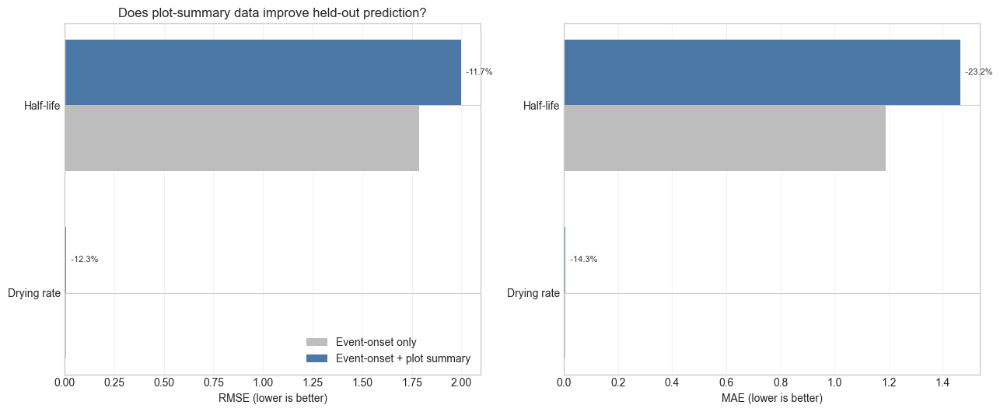

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_J_plot_summary_model_comparison.png


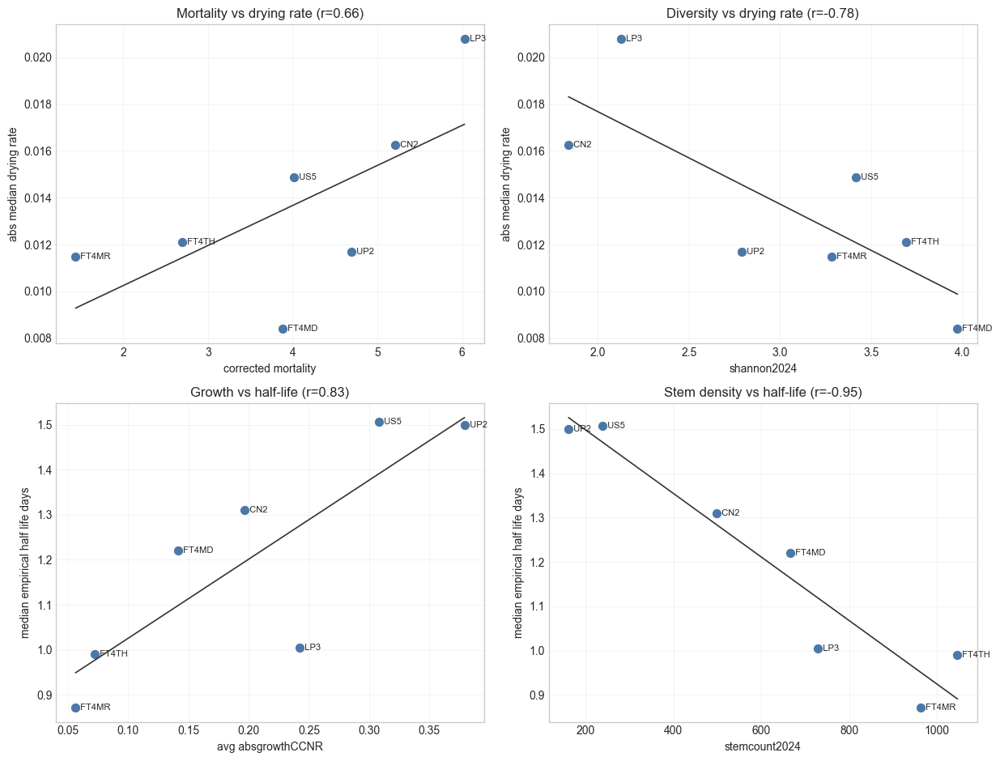

  Saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/soil_moisture/soil_K_plot_summary_trait_links.png


In [55]:
# ── Plot-summary integration for drydown interpretation and prediction ───
from pathlib import Path
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

if 'PROJECT_ROOT' not in globals():
    PROJECT_ROOT = Path.cwd().resolve()

plot_summary_candidates = [
    PROJECT_ROOT / 'data' / 'metadata' / 'plot_summary.csv',
    PROJECT_ROOT / 'plot_summary.csv',
    Path.home() / 'Downloads' / 'plot_summary.csv',
]
plot_summary_path = next((p for p in plot_summary_candidates if p.exists()), None)
if plot_summary_path is None:
    raise FileNotFoundError('plot_summary.csv was not found in data/metadata or the fallback paths.')

plot_summary = pd.read_csv(plot_summary_path)
plot_name_map = {'MRFT4': 'FT4MR', 'THFT4': 'FT4TH'}
plot_summary['plot_key'] = plot_summary['plot'].replace(plot_name_map)

site_trait_cols = [
    'avg_absgrowthCCNR',
    'stemcount2024',
    'basal_area2024',
    'corrected_mortality',
    'corrected_recruitment',
    'shannon2024',
]
site_traits = plot_summary[['plot_key'] + site_trait_cols].rename(columns={'plot_key': 'plot'})

start_day_features = (
    soil_daily_dd[
        ['plot', 'date', 'daily_mean', 'daily_min', 'daily_max', 'daily_range', 'mean_roll7', 'max_roll3', 'min_roll3', 'range_roll7']
    ]
    .rename(
        columns={
            'date': 'start_date',
            'daily_mean': 'start_daily_mean',
            'daily_min': 'start_daily_min',
            'daily_max': 'start_daily_max',
            'daily_range': 'start_daily_range',
        }
    )
)

soil_drydown_model_df = (
    soil_drydown_events.copy()
    .assign(abs_drying_rate=lambda d: -d['linear_rate'])
    .merge(start_day_features, on=['plot', 'start_date'], how='left')
    .merge(site_traits, on='plot', how='left')
)
soil_drydown_model_df['start_month'] = soil_drydown_model_df['start_date'].dt.month
soil_drydown_model_df['month_sin'] = np.sin(2 * np.pi * soil_drydown_model_df['start_month'] / 12)
soil_drydown_model_df['month_cos'] = np.cos(2 * np.pi * soil_drydown_model_df['start_month'] / 12)

matched_site_mask = soil_drydown_model_df[site_trait_cols].notna().all(axis=1)
matched_sites = sorted(soil_drydown_model_df.loc[matched_site_mask, 'plot'].dropna().unique())
soil_drydown_model_df = soil_drydown_model_df[soil_drydown_model_df['plot'].isin(matched_sites)].copy()

baseline_features = ['start_signal', 'start_daily_range', 'mean_roll7', 'max_roll3', 'month_sin', 'month_cos']
augmented_features = baseline_features + site_trait_cols


def evaluate_logo_regression(df, target_col, feature_cols, alpha=2.0):
    df = df.dropna(subset=[target_col]).copy()
    X = df[feature_cols]
    y = df[target_col]
    groups = df['plot']
    model = Pipeline([
        ('prep', ColumnTransformer([
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
            ]), feature_cols),
        ])),
        ('reg', Ridge(alpha=alpha)),
    ])

    logo = LeaveOneGroupOut()
    preds = []
    obs = []
    heldout_sites = []
    for train_idx, test_idx in logo.split(X, y, groups):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        fold_pred = model.predict(X.iloc[test_idx])
        preds.extend(fold_pred)
        obs.extend(y.iloc[test_idx])
        heldout_sites.extend(groups.iloc[test_idx])

    preds = np.asarray(preds)
    obs = np.asarray(obs)
    result = {
        'mae': mean_absolute_error(obs, preds),
        'rmse': np.sqrt(mean_squared_error(obs, preds)),
        'r2': r2_score(obs, preds),
    }
    pred_df = pd.DataFrame({
        'plot': heldout_sites,
        'target': target_col,
        'observed': obs,
        'predicted': preds,
        'feature_set': ' + '.join(feature_cols),
    })
    return result, pred_df


comparison_rows = []
prediction_frames = []
for target_col, target_label in [
    ('abs_drying_rate', 'Drying rate'),
    ('empirical_half_life_days', 'Half-life'),
]:
    baseline_metrics, baseline_preds = evaluate_logo_regression(soil_drydown_model_df, target_col, baseline_features)
    augmented_metrics, augmented_preds = evaluate_logo_regression(soil_drydown_model_df, target_col, augmented_features)
    prediction_frames.extend([
        baseline_preds.assign(model_name='Event-onset only', target_label=target_label),
        augmented_preds.assign(model_name='Event-onset + plot summary', target_label=target_label),
    ])
    comparison_rows.extend([
        {
            'target': target_col,
            'target_label': target_label,
            'model_name': 'Event-onset only',
            **baseline_metrics,
        },
        {
            'target': target_col,
            'target_label': target_label,
            'model_name': 'Event-onset + plot summary',
            **augmented_metrics,
        },
    ])

soil_model_comparison = pd.DataFrame(comparison_rows)
soil_model_predictions = pd.concat(prediction_frames, ignore_index=True)
soil_model_comparison['mae_change_vs_baseline_pct'] = soil_model_comparison.groupby('target')['mae'].transform(lambda s: 100 * (s.iloc[0] - s) / s.iloc[0])
soil_model_comparison['rmse_change_vs_baseline_pct'] = soil_model_comparison.groupby('target')['rmse'].transform(lambda s: 100 * (s.iloc[0] - s) / s.iloc[0])

soil_trait_links = (
    soil_drydown_summary[['plot', 'ft', 'abs_median_drying_rate', 'median_empirical_half_life_days']]
    .merge(site_traits, on='plot', how='inner')
)
trait_corr = soil_trait_links[
    ['abs_median_drying_rate', 'median_empirical_half_life_days'] + site_trait_cols
].corr().loc[site_trait_cols, ['abs_median_drying_rate', 'median_empirical_half_life_days']]

soil_drydown_model_df.to_csv(os.path.join(out_soil, 'soil_drydown_events_with_plot_summary.csv'), index=False)
soil_model_comparison.to_csv(os.path.join(out_soil, 'soil_plot_summary_model_comparison.csv'), index=False)
soil_model_predictions.to_csv(os.path.join(out_soil, 'soil_plot_summary_predictions.csv'), index=False)
trait_corr.to_csv(os.path.join(out_soil, 'soil_plot_summary_trait_correlations.csv'))

print(f'Plot summary loaded from: {plot_summary_path}')
print(f'Matched sites for plot-summary merge: {matched_sites}')
print(f'Total matched drydown events: {len(soil_drydown_model_df):,}')
print('\nPrediction comparison (leave-one-site-out):')
print(soil_model_comparison.round(4).to_string(index=False))
print('\nSite-trait correlations with drydown metrics:')
print(trait_corr.round(3).to_string())

comp_plot = soil_model_comparison.copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=False)
metric_specs = [
    ('rmse', 'RMSE (lower is better)'),
    ('mae', 'MAE (lower is better)'),
]
for ax, (metric, xlabel) in zip(axes, metric_specs):
    pivot = comp_plot.pivot(index='target_label', columns='model_name', values=metric).loc[['Drying rate', 'Half-life']]
    y = np.arange(len(pivot.index))
    h = 0.35
    ax.barh(y - h/2, pivot['Event-onset only'], height=h, color='#bdbdbd', label='Event-onset only')
    ax.barh(y + h/2, pivot['Event-onset + plot summary'], height=h, color='#4c78a8', label='Event-onset + plot summary')
    for row_idx, target_label in enumerate(pivot.index):
        base = pivot.loc[target_label, 'Event-onset only']
        aug = pivot.loc[target_label, 'Event-onset + plot summary']
        delta = 100 * (base - aug) / base if base != 0 else np.nan
        ax.text(max(base, aug), row_idx + h/2, f'  {delta:+.1f}%', va='center', fontsize=8, color='#333333')
    ax.set_yticks(y)
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', alpha=0.25)
axes[0].legend(frameon=False, loc='lower right')
axes[0].set_title('Does plot-summary data improve held-out prediction?')
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_J_plot_summary_model_comparison.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_J_plot_summary_model_comparison.png')}")

trait_plot_cols = [
    ('corrected_mortality', 'abs_median_drying_rate', 'Mortality vs drying rate'),
    ('shannon2024', 'abs_median_drying_rate', 'Diversity vs drying rate'),
    ('avg_absgrowthCCNR', 'median_empirical_half_life_days', 'Growth vs half-life'),
    ('stemcount2024', 'median_empirical_half_life_days', 'Stem density vs half-life'),
]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.5))
axes = axes.ravel()
for ax, (xcol, ycol, title) in zip(axes, trait_plot_cols):
    x = soil_trait_links[xcol]
    y = soil_trait_links[ycol]
    ax.scatter(x, y, s=80, color='#4c78a8', edgecolor='white', linewidth=0.8)
    if len(soil_trait_links) >= 2:
        coef = np.polyfit(x, y, 1)
        xx = np.linspace(x.min(), x.max(), 100)
        ax.plot(xx, coef[0] * xx + coef[1], color='#333333', lw=1.2)
        corr_val = np.corrcoef(x, y)[0, 1]
    else:
        corr_val = np.nan
    for _, row in soil_trait_links.iterrows():
        ax.text(row[xcol], row[ycol], f"  {row['plot']}", fontsize=8, va='center')
    ax.set_title(f"{title} (r={corr_val:.2f})")
    ax.set_xlabel(xcol.replace('_', ' '))
    ax.set_ylabel(ycol.replace('_', ' '))
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(os.path.join(out_soil, 'soil_K_plot_summary_trait_links.png'), dpi=180, bbox_inches='tight')
plt.show()
print(f"  Saved -> {os.path.join(out_soil, 'soil_K_plot_summary_trait_links.png')}")


### What changed once the plot summary table was added?

#### Interpretation
The prediction result is quite direct: adding `plot_summary.csv` did not improve held-out performance in this notebook. The event-only model stayed better for both drying rate and half-life, which means the trait table alone is not enough to predict a new site more accurately.

The trait table still adds descriptive context. Across these seven plots, faster-drying rankings appeared alongside higher mortality and lower diversity, while longer half-life appeared alongside stronger growth and lower stem density. These patterns help form hypotheses, but they did not improve held-out prediction and cannot establish a biological relationship from this sample.


Only seven plots are available for the trait comparison. The plotted relationships are descriptive hypotheses and are not treated as statistically confirmed effects.

Only seven plots are available for the trait comparison. The plotted relationships are descriptive hypotheses and are not treated as statistically confirmed effects.

Only seven plots are available for the trait comparison. The plotted relationships are descriptive hypotheses and are not treated as statistically confirmed effects.

Only seven plots are available for the trait comparison. The plotted relationships are descriptive hypotheses and are not treated as statistically confirmed effects.

### Figures: soil-moisture drydown behaviour

Drydown results compare event timing, rate, half-life, daily envelopes, and the held-out model using the available plot-summary traits.

The figures below are embedded in this notebook after the analysis runs. They are also saved in `outputs/redesigned/` for use in the report.


**Drydown event timeline**

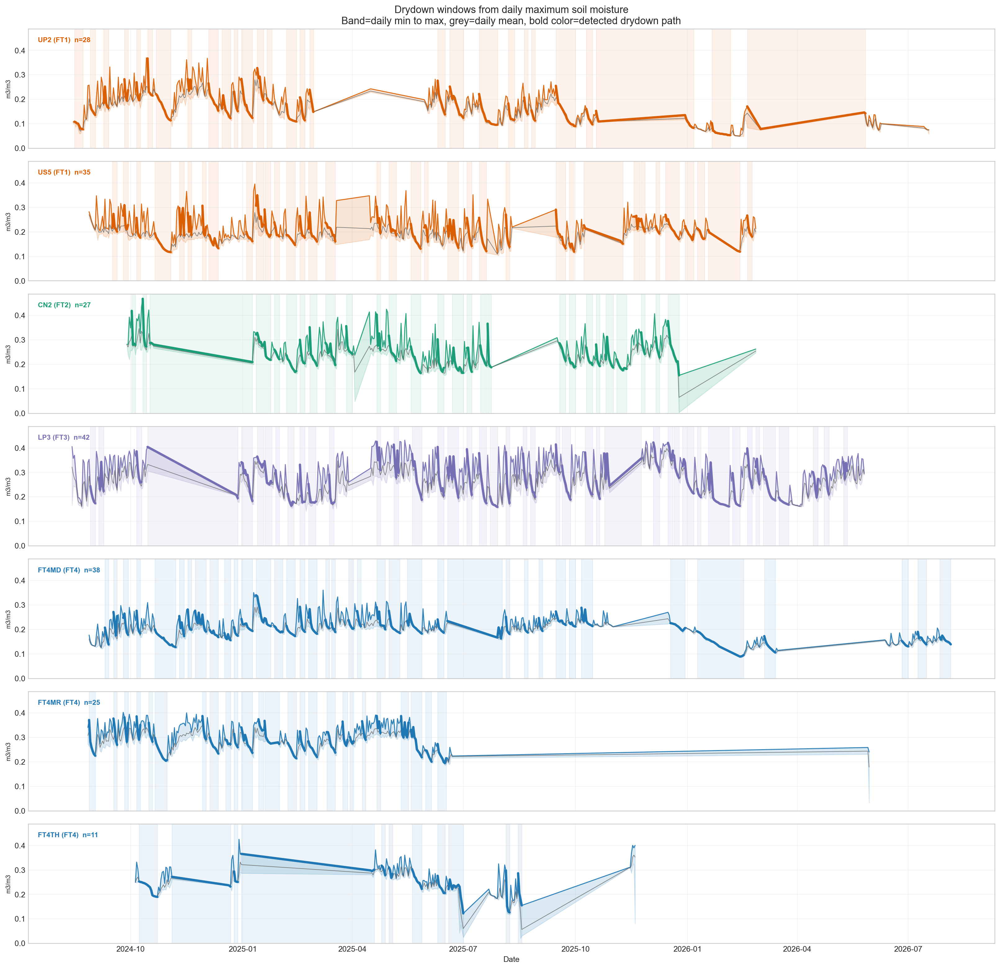

**Drying-rate summary**

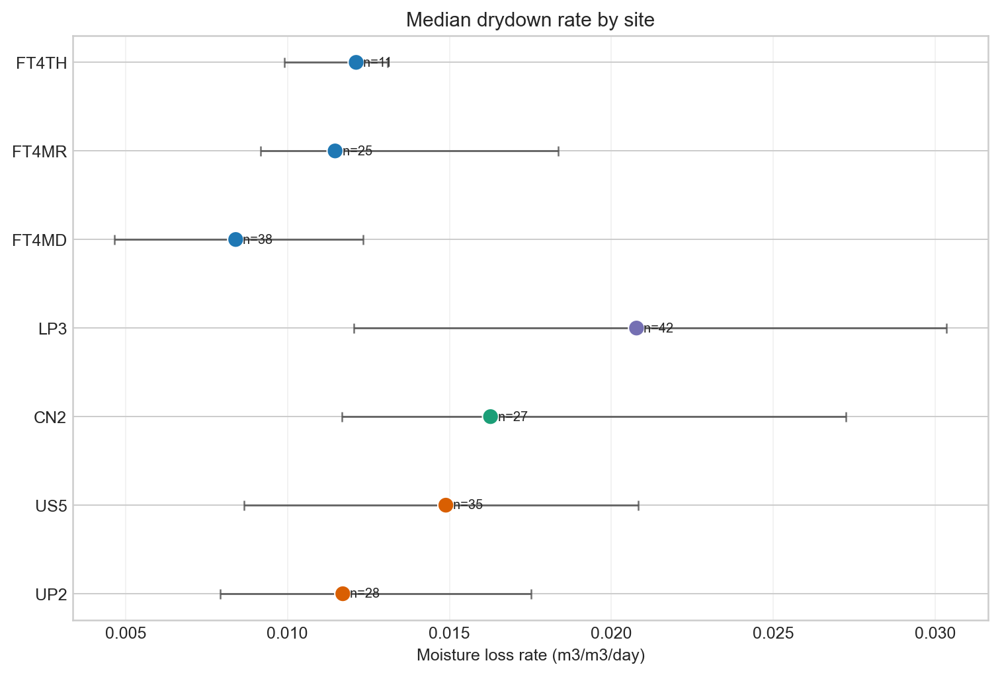

**Drydown half-life summary**

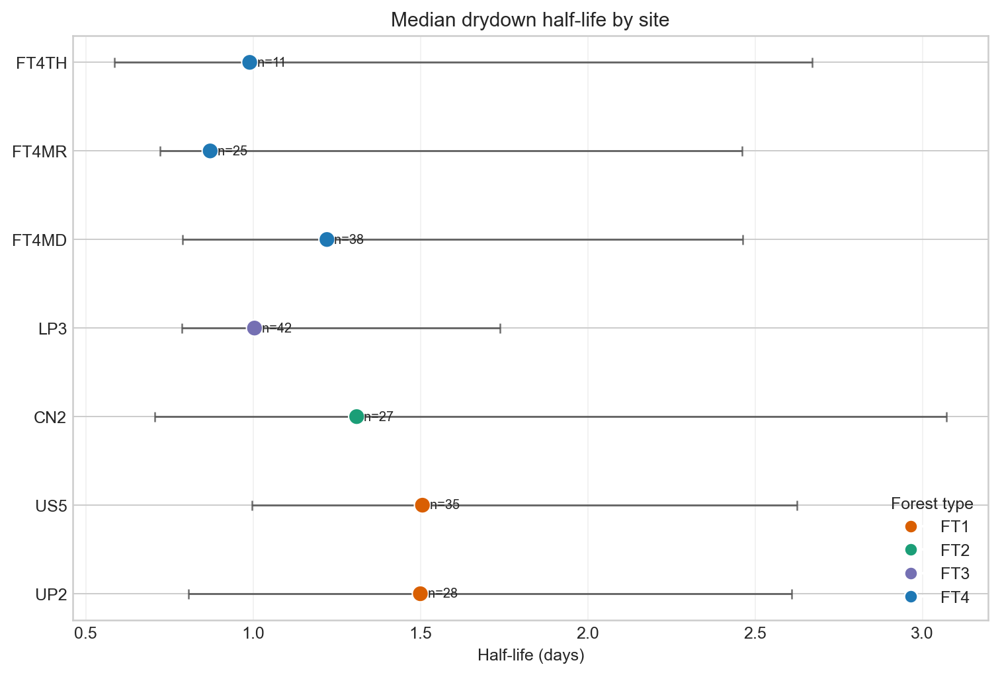

**Normalised drydown curves**

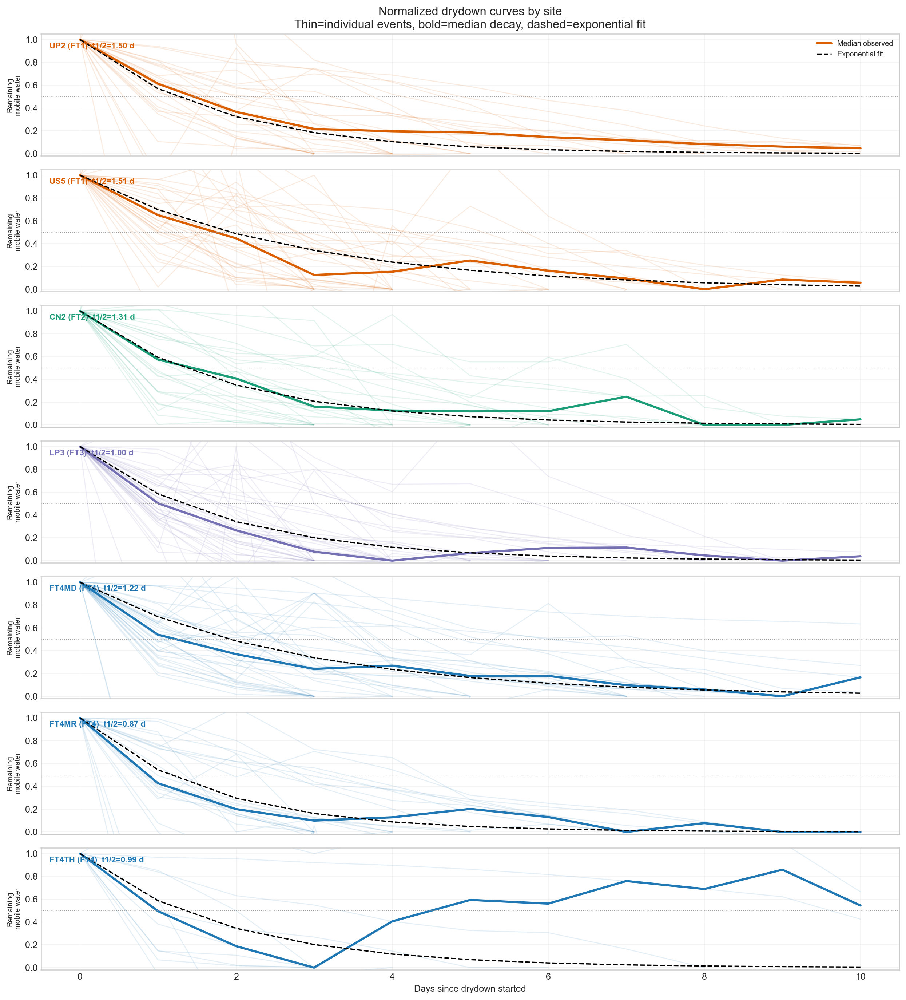

**Daily soil-moisture envelope**

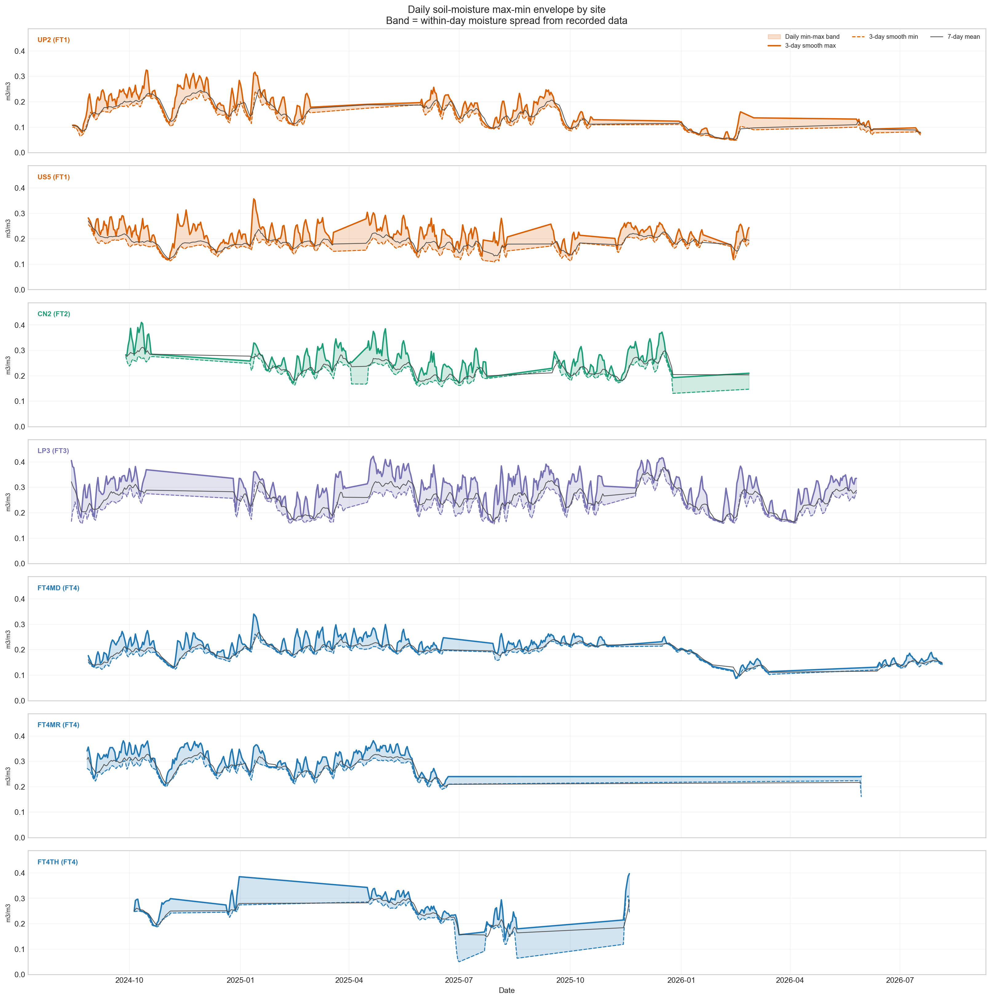

**Daily soil-moisture range summary**

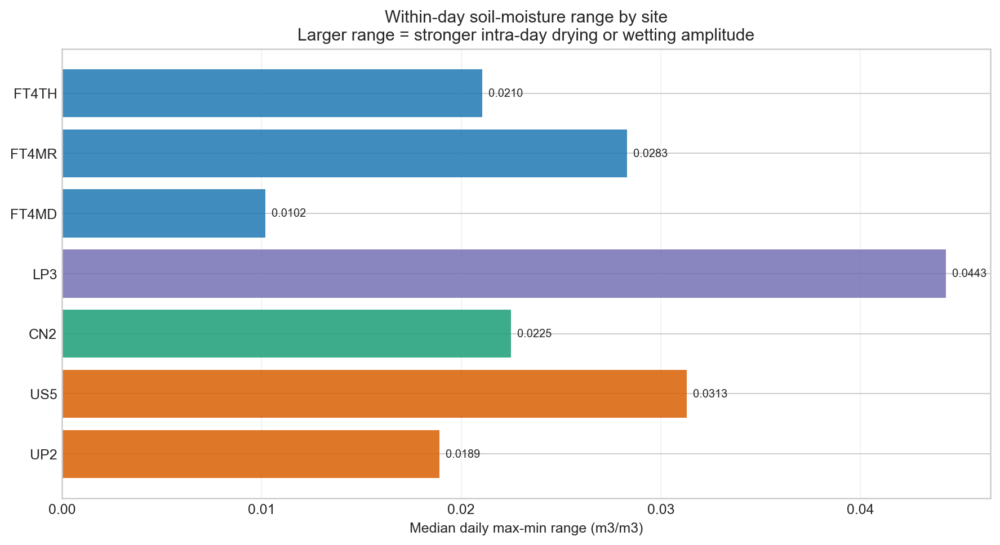

**Plot-summary model comparison**

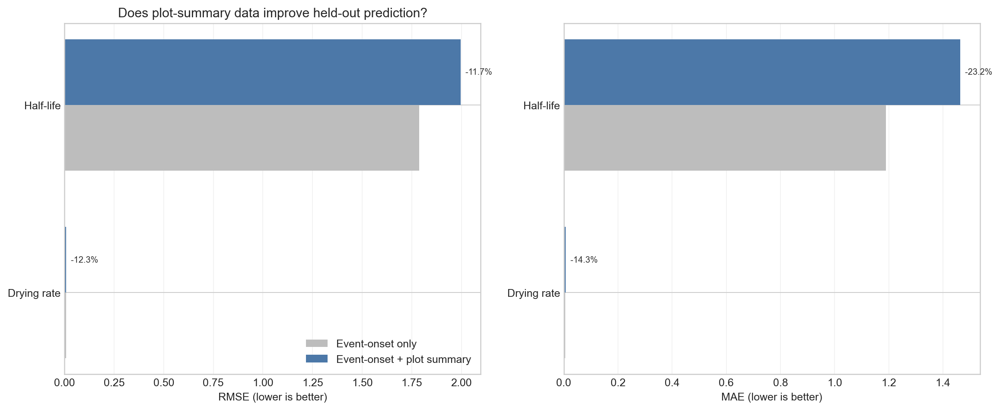

**Held-out feature importance**

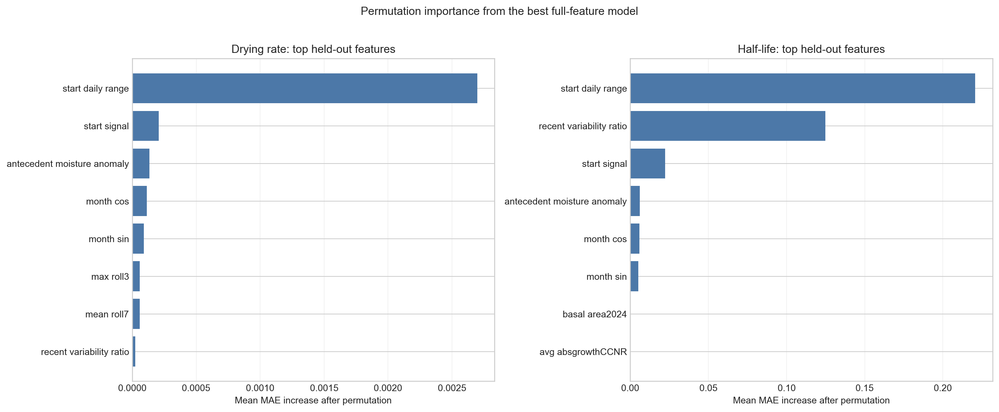

In [56]:
from IPython.display import Image, Markdown, display

_figures = [
    ('Drydown event timeline', 'soil_moisture/soil_D_drydown_event_timeline.png'),
    ('Drying-rate summary', 'soil_moisture/soil_E_drying_rate_summary.png'),
    ('Drydown half-life summary', 'soil_moisture/soil_F_half_life_summary.png'),
    ('Normalised drydown curves', 'soil_moisture/soil_G_normalized_drydown_curves.png'),
    ('Daily soil-moisture envelope', 'soil_moisture/soil_H_daily_max_min_envelope.png'),
    ('Daily soil-moisture range summary', 'soil_moisture/soil_I_daily_range_summary.png'),
    ('Plot-summary model comparison', 'soil_moisture/soil_J_plot_summary_model_comparison.png'),
    ('Held-out feature importance', 'soil_moisture/soil_L_logo_permutation_importance.png')
]
_missing = []
for _caption, _relative_path in _figures:
    _path = Path(OUT_ROOT) / _relative_path
    if _path.exists():
        display(Markdown(f'**{_caption}**'))
        display(Image(filename=str(_path)))
    else:
        _missing.append(_relative_path)
if _missing:
    print('Figures not found:', ', '.join(_missing))


## 7. Forecasting and model evaluation

This section reports two different checks. The daily regression suite uses leave-one-site-out validation to ask whether a model transfers to an unseen monitored plot. The VPD-state task later uses a chronological 60/20/20 split to ask whether recent conditions predict a later period. Their scores answer different questions and should not be compared directly. Both targets are measured microclimate variables, not tree-health outcomes.


### 7.1 Drydown-model comparison and feature importance

This section extends the soil-moisture drydown task after the correlation analysis. It compares Ridge, Random Forest, and Histogram Gradient Boosting under leave-one-site-out evaluation, with and without plot traits. Permutation importance is calculated only on held-out sites, so it identifies variables that help prediction at a new site.


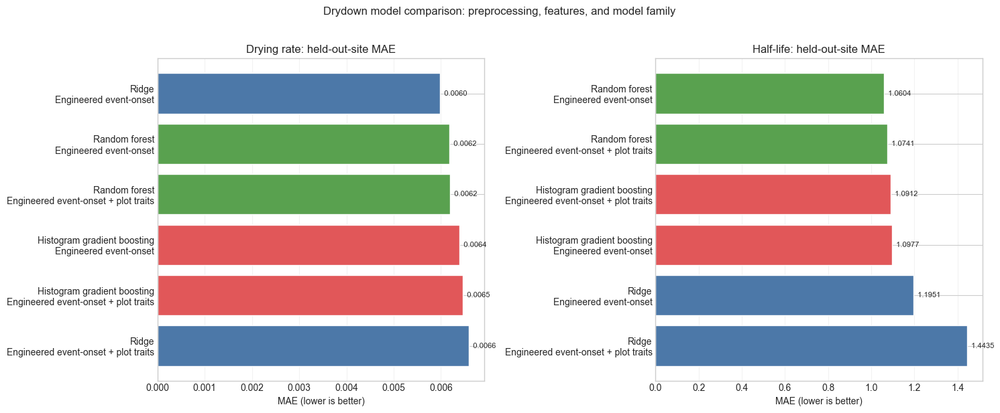

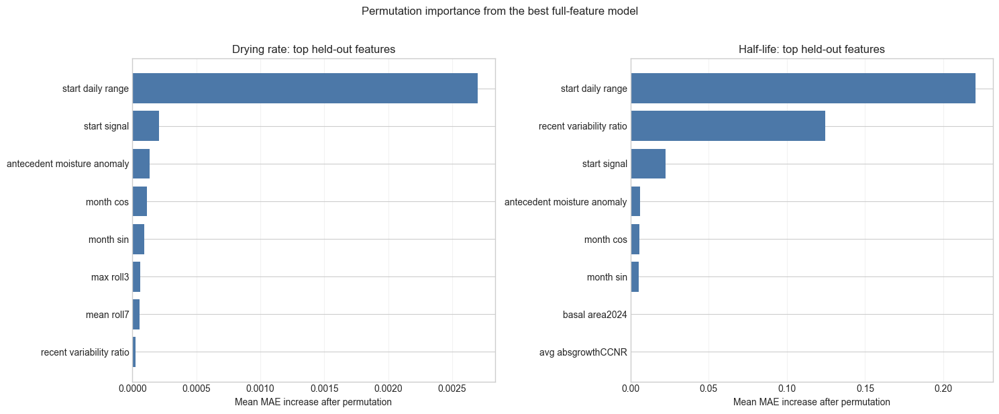


Extended model comparison (leave-one-site-out):
                  target target_label                  model_name                       preprocessing                          feature_set    mae   rmse      r2  mae_change_vs_baseline_pct  rmse_change_vs_baseline_pct
         abs_drying_rate  Drying rate                       Ridge Median imputation + standardization               Engineered event-onset 0.0060 0.0083  0.5093                      0.0000                       0.0000
         abs_drying_rate  Drying rate               Random forest                   Median imputation               Engineered event-onset 0.0062 0.0085  0.4815                     -3.3154                      -2.7952
         abs_drying_rate  Drying rate Histogram gradient boosting                   Median imputation               Engineered event-onset 0.0064 0.0089  0.4306                     -6.7180                      -7.7162
         abs_drying_rate  Drying rate                       Ridge Median imputa

In [57]:
# Extended suite: Ridge, RandomForestRegressor, and HistGradientBoostingRegressor
# use preprocessing variants and held-out permutation_importance values.
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.drydown_modeling import run_drydown_model_suite

(
    soil_drydown_model_df,
    soil_model_comparison,
    soil_model_predictions,
    soil_logo_permutation_importance,
    soil_logo_feature_importance_summary,
    soil_logo_feature_importance_focus,
) = run_drydown_model_suite(
    soil_drydown_model_df,
    site_trait_cols,
    out_soil,
)

print('\nExtended model comparison (leave-one-site-out):')
print(soil_model_comparison.round(4).to_string(index=False))
print('\nTop held-out features for the best full-feature model:')
print(
    soil_logo_feature_importance_focus.groupby('target_label').head(5)[
        ['target_label', 'model_name', 'feature', 'mae_increase_mean']
    ].round(4).to_string(index=False)
)
print("  Saved -> soil_logo_permutation_importance.csv")
print("  Saved -> soil_logo_feature_importance_summary.csv")


### 7.2 Daily microclimate forecasting suite

This benchmark predicts the next daily mean of temperature, RH, VPD, PAR and soil moisture using information available by the end of the current day. It compares persistence with learned regressions on a held-out plot. This is a transfer test across the monitored plots; it is not a prediction for an uninstrumented location.


In [58]:
# Daily forecasting: compare models first, then refit one selected model per target.
import sys
from pathlib import Path

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.microclimate_forecasting import (
    run_forecasting_workflow,
    run_hourly_demonstration,
    save_forecasting_figures,
)

forecast_out = Path(OUT_ROOT) / 'forecasting'
forecasting_result = run_forecasting_workflow(
    df,
    forecast_out,
    targets=['temperature', 'relative_humidity', 'vpd', 'par', 'soil_moisture'],
    min_daily_observations=18,
    importance_repeats=5,
)
hourly_forecast_frame, hourly_forecast_predictions, hourly_demo_plot = run_hourly_demonstration(
    df, forecasting_result['selected_models']
)
save_forecasting_figures(forecasting_result, hourly_forecast_predictions)

daily_forecast_coverage = (
    forecasting_result['daily_frame']
    .groupby('plot')[[
        'target_temperature', 'target_relative_humidity', 'target_vpd', 'target_par', 'target_soil_moisture'
    ]]
    .count()
)
daily_forecast_coverage.index.name = 'plot'
daily_forecast_coverage.reset_index().to_csv(
    forecast_out / 'daily_forecast_target_coverage.csv', index=False
)
print('Daily next-day target coverage by plot:')
print(daily_forecast_coverage.to_string())
print('Coverage table saved ->', forecast_out / 'daily_forecast_target_coverage.csv')
print('\nPAR has weaker coverage than the other targets; interpret its held-out scores with that limitation.')
print('\nRegression-model comparison (macro-average leave-one-site-out):')
print(forecasting_result['comparison'].round(4).to_string(index=False))
print('\nSelected final daily model per target:')
print(forecasting_result['selected_models'].round(4).to_string(index=False))
print('\nSoil-moisture performance by next-day drying state:')
print(forecasting_result['soil_drydown_metrics'].round(4).to_string(index=False))
print('\nTop held-out predictors for each selected daily model:')
print(
    forecasting_result['importance'].groupby('target').head(5)[
        ['target', 'model_name', 'feature', 'mae_increase_mean', 'heldout_sites']
    ].round(4).to_string(index=False)
)
print(f'\nHourly demonstration plot: {hourly_demo_plot} (illustrative only; daily models remain the formal final models).')
print(f'Saved forecasts, model files, tables and figures -> {forecast_out}')


Daily next-day target coverage by plot:
signal  target_temperature  target_relative_humidity  target_vpd  target_par  target_soil_moisture
plot                                                                                              
CN2                    692                       692         692         316                   304
FT4MD                  721                       721         721         518                   511
FT4MR                  693                       693         693         434                   292
FT4TH                  705                       705         705         149                   147
LP3                    641                       641         641         605                   528
UP2                    739                       739         739         417                   395
US5                    643                       643         643         425                   419
Coverage table saved -> /Users/siddharthchoudhary09/Desktop/fyp_proje

### 7.3 Interpreting the forecasting suite

This section is the project’s site-transfer regression benchmark. It writes trained pipelines, held-out-site predictions, tables and figures under `outputs/redesigned/forecasting/`.

#### What the code cell above does

1. **Builds the forecasting dataset.** Cleaned hourly records are aggregated to daily means. Each row contains information known by the end of day *t* and a target value for day *t + 1*. Features include seasonality, forest type, same-day measurements, and 1-, 3- and 7-day summaries.
2. **Trains several candidate models.** For each target—temperature, RH, VPD, PAR and soil moisture—the workflow compares a persistence baseline with Ridge, Elastic Net, Random Forest, Extra Trees and Histogram Gradient Boosting. This comparison is important because no single regression approach should be assumed to be best for every microclimate variable.
3. **Tests every candidate on unseen sites.** It stores held-out-site predictions and calculates MAE, RMSE and R². It then selects the best evaluated regression per target and refits it on all valid daily records for the separate illustrative demonstration.
4. **Explains the selected models.** Held-out permutation importance identifies which inputs most affect forecast error. The soil-moisture analysis also separates next-day drying from recharge/stable days, linking the forecasts to the earlier drydown work.

#### How models are tested

Testing uses **leave-one-site-out** validation. In each of seven folds, the model trains on six plots and is evaluated only on the seventh held-out plot. The held-out site is never used to fit preprocessing or model parameters. This is a spatial/site-transfer check, not a chronological future-period test. The same seven folds are used to compare candidates and summarise their site-transfer scores, so this is an exploratory benchmark rather than an independent final estimate. The exported SD, minimum and maximum describe variation across seven held-out sites; they are not confidence intervals. Section 8.7 supplies the separate chronological final-period check.

#### Results

- **The persistence baseline.** It predicts that tomorrow equals today. A regression model is meaningful only when its held-out performance improves on this simple reference.
- **MAE as the main comparison.** Lower MAE means smaller average next-day error across held-out sites. RMSE gives more weight to large errors, while R² shows how much variation is explained.
- **Choose models by target.** Temperature, humidity, VPD, PAR and soil moisture behave differently, so their best evaluated regressions can differ.
- **Read feature importance as evidence.** A high positive importance means that shuffling the feature makes held-out forecasts worse; it does not alone prove an ecological cause.
- **Interpret PAR cautiously.** PAR has lower and less consistent sensor coverage, so its held-out results are less reliable than the other targets.

#### Scope of the current result

The daily models are tested for transfer across the seven measured plots. The hourly plot is an illustrative 24-hour demonstration using the selected daily model family; it is not a separately selected final model. The chronological VPD-state baseline later in the notebook keeps the existing 60% train, 20% validation and 20% final-test design. Remote-sensing, canopy-structure and tree-health prediction are outside the current data.


### 7.4 Forecasting figures

The four key forecasting figures are embedded below for quick viewing in a supervisor meeting. They are loaded from the saved analysis outputs, so this cell is fast to rerun and does not retrain the models.


#### 1. Daily model comparison

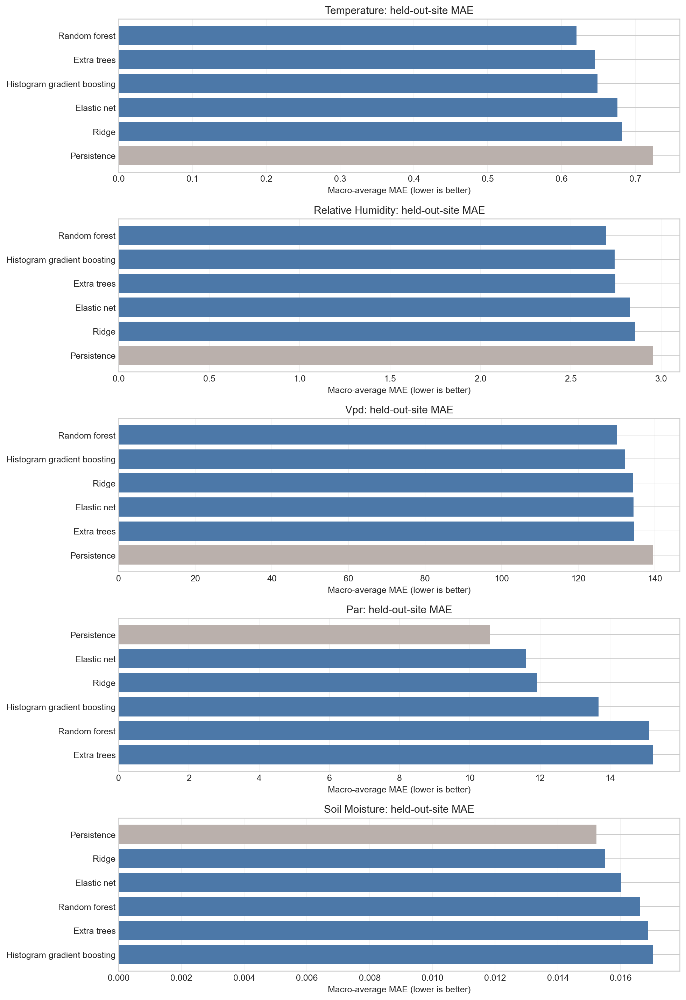

#### 2. Feature importance for the selected daily models

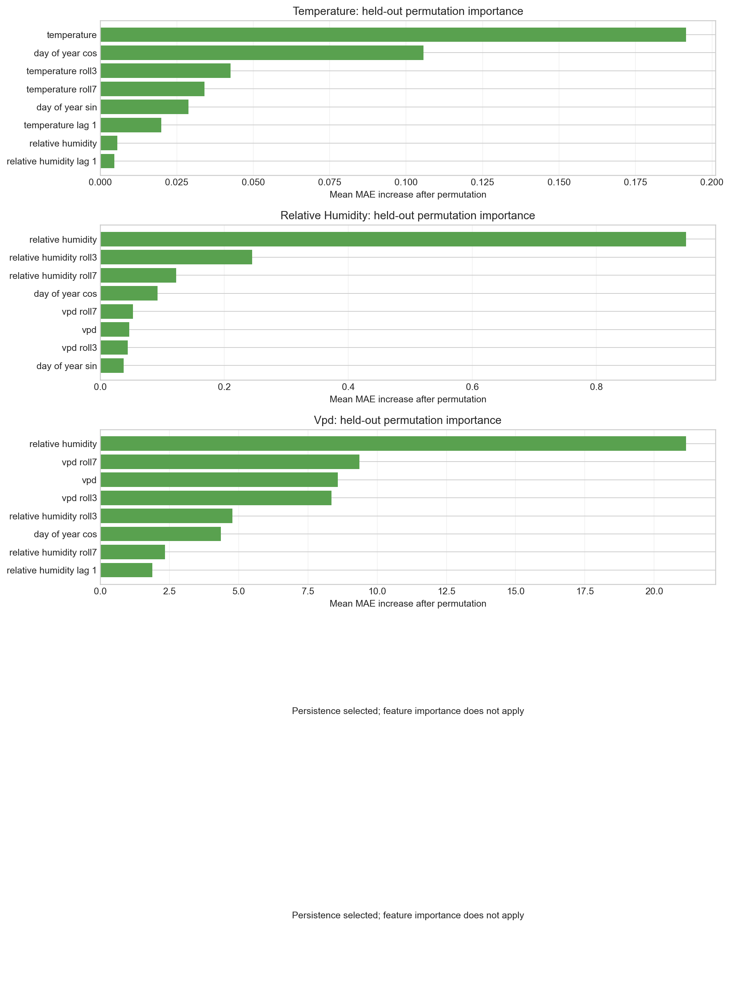

#### 3. Soil-moisture drydown forecast performance

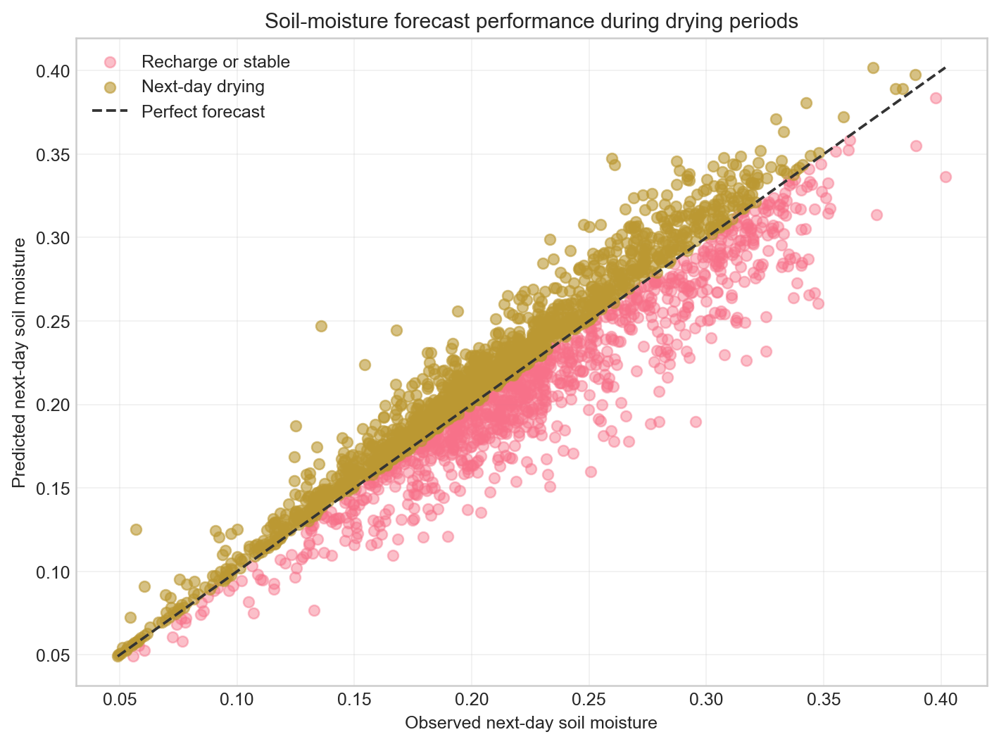

#### 4. Illustrative hourly forecast demonstration

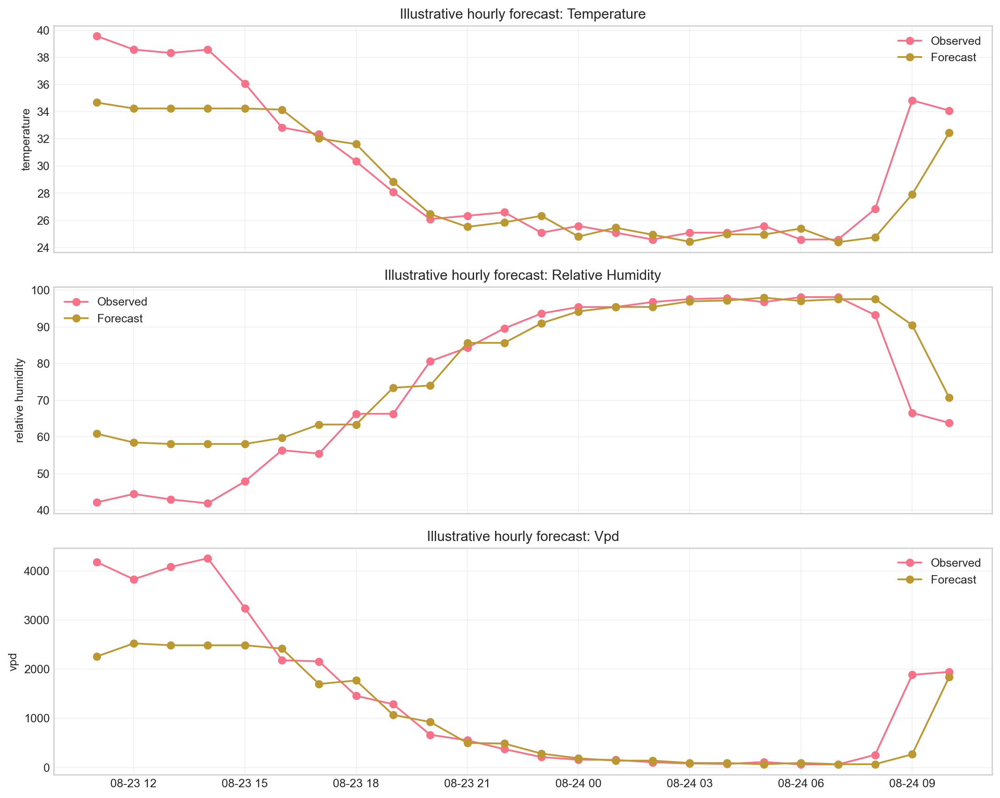

All four saved figures loaded from: /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/forecasting


In [59]:
# Load the saved forecasting figures without retraining the models.
from IPython.display import Image, display
from IPython.display import Markdown

forecast_figure_dir = Path(OUT_ROOT) / 'forecasting'
forecast_figures = [
    ('1. Daily model comparison', 'daily_model_comparison.png'),
    ('2. Feature importance for the selected daily models', 'daily_feature_importance.png'),
    ('3. Soil-moisture drydown forecast performance', 'daily_soil_moisture_drydown_forecast.png'),
    ('4. Illustrative hourly forecast demonstration', 'hourly_forecast_demonstration.png'),
]

missing_figures = []
for figure_title, filename in forecast_figures:
    figure_path = forecast_figure_dir / filename
    if figure_path.exists():
        display(Markdown(f'#### {figure_title}'))
        display(Image(filename=str(figure_path)))
    else:
        missing_figures.append(filename)

if missing_figures:
    print('Missing figure(s):', ', '.join(missing_figures))
    print('Run the forecasting cell above to regenerate them.')
else:
    print('All four saved figures loaded from:', forecast_figure_dir)


## 8. Labels, recurring regimes and next-day VPD states

This section turns the daily records into transparent environmental labels, checks for recurring multi-sensor regimes and evaluates a next-day VPD-state baseline. The labels describe the measured microclimate only. They are not evidence about tree health or ecological condition.


### 8.1 Build the daily readiness dataset

This section turns the cleaned sensor record into a reproducible daily analysis dataset. It identifies associations, creates transparent **microclimate** labels, finds recurring regimes, and evaluates a small next-day baseline. These labels describe environmental conditions only: they are **not** tree-health labels or evidence of tree condition.


In [60]:
# Build a quality-screened, plot-aligned daily dataset for the analyses below.
# Candidate sensor-fault rows remain in df_clean for auditability, but are excluded here so
# they do not dominate relationships or clusters. No raw data are changed.
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

READINESS_OUT = Path(OUT_ROOT) / 'readiness'
READINESS_OUT.mkdir(parents=True, exist_ok=True)

readiness_params = ['temp', 'rh', 'vpd', 'par', 'soil moisture']
daily_value_columns = ['temperature', 'relative_humidity', 'vpd', 'par', 'soil_moisture']
daily_long = df.loc[
    df['param'].isin(readiness_params),
    ['time', 'plot', 'ft', 'param', 'value']
].copy()
daily_long['date'] = pd.to_datetime(daily_long['time'], errors='coerce').dt.floor('D')
daily_microclimate = (
    daily_long.pivot_table(
        index=['date', 'plot', 'ft'], columns='param', values='value', aggfunc='mean'
    )
    .rename(columns={'temp': 'temperature', 'rh': 'relative_humidity', 'soil moisture': 'soil_moisture'})
    .reset_index()
    .sort_values(['plot', 'date'])
    .reset_index(drop=True)
)
if daily_microclimate['vpd'].quantile(0.99) > 10:
    daily_microclimate['vpd'] = daily_microclimate['vpd'] / 1000
    print('Converted daily VPD from Pa to kPa for this section.')

print(f'Quality-screened daily frame: {len(daily_microclimate):,} plot-days across {daily_microclimate["plot"].nunique()} plots.')
print('Daily non-missing counts:')
print(daily_microclimate[daily_value_columns].notna().sum().to_string())
display(daily_microclimate[daily_value_columns].describe().T.round(3))


Converted daily VPD from Pa to kPa for this section.
Quality-screened daily frame: 4,853 plot-days across 7 plots.
Daily non-missing counts:
param
temperature          4852
relative_humidity    4852
vpd                  4852
par                  2898
soil_moisture        2662


,count,mean,std,min,25%,50%,75%,max
param,,,,,,,,
temperature,4852.0,26.396,1.165,22.788,25.569,26.352,27.179,30.568
relative_humidity,4852.0,91.068,5.142,68.463,87.780,91.438,95.073,100.000
vpd,4852.0,0.362,0.243,0.000,0.181,0.324,0.493,1.657
par,2898.0,28.987,95.932,1.200,3.908,11.322,27.033,2558.700
soil_moisture,2662.0,0.214,0.061,0.049,0.177,0.211,0.254,0.402


### 8.2 Daily relationships

Variables are aligned by plot and date before comparison. The table reports the median within-plot Spearman association and a 95% moving-block bootstrap interval. Fourteen-day blocks retain short-term temporal dependence, so the interval is more appropriate than treating every plot-day as independent. These are descriptive associations; VPD is calculated from temperature and humidity and should be interpreted accordingly.

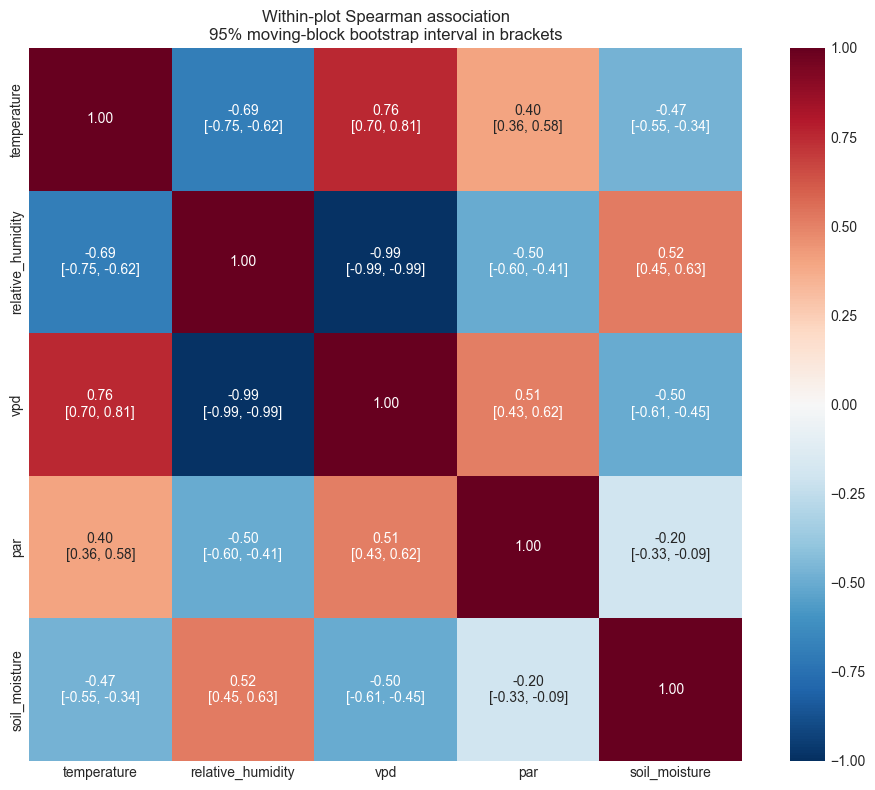

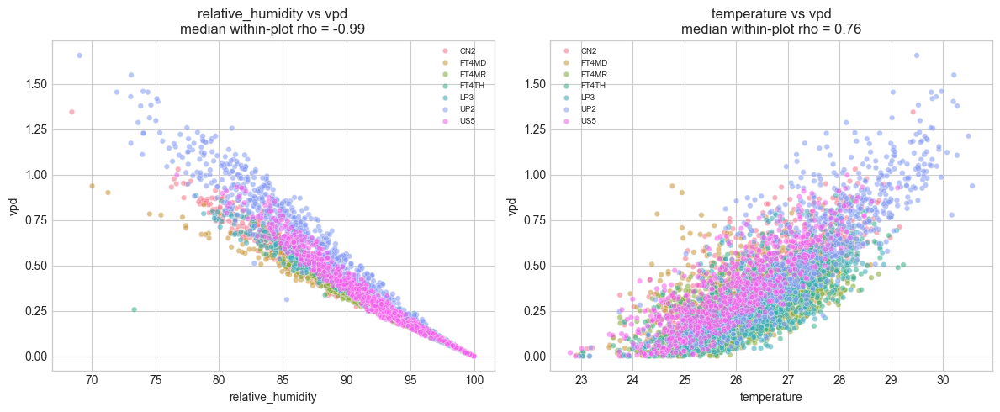

Distribution checks:


,variable,n,sample_skew,normaltest_p_value,normal_at_alpha_0_05
0,temperature,4852,0.2367,0.000,False
1,relative_humidity,4852,-0.5200,0.000,False
2,vpd,4852,1.0154,0.000,False
3,par,2898,20.6039,0.000,False
4,soil_moisture,2662,0.0339,0.415,True


Time-aware within-plot associations:


,variable_1,variable_2,paired_plot_days,plots,pooled_rho,within_plot_median_rho,within_plot_min_rho,within_plot_max_rho,ci_low,ci_high,block_days,bootstrap_repeats,interval_excludes_zero
4,relative_humidity,vpd,4852,7,-0.9851,-0.9914,-0.9954,-0.9759,-0.9941,-0.9870,14,500,True
1,temperature,vpd,4852,7,0.7388,0.7571,0.5250,0.8515,0.7003,0.8054,14,500,True
0,temperature,relative_humidity,4852,7,-0.6715,-0.6950,-0.7755,-0.4518,-0.7524,-0.6202,14,500,True
6,relative_humidity,soil_moisture,2661,7,0.4592,0.5216,0.1759,0.7108,0.4534,0.6316,14,500,True
7,vpd,par,2897,7,0.5126,0.5107,0.0960,0.6717,0.4305,0.6220,14,500,True
8,vpd,soil_moisture,2661,7,-0.4803,-0.5014,-0.7103,-0.2006,-0.6125,-0.4459,14,500,True
5,relative_humidity,par,2897,7,-0.4661,-0.5006,-0.6298,-0.0897,-0.5970,-0.4127,14,500,True
3,temperature,soil_moisture,2661,7,-0.2949,-0.4728,-0.5488,-0.2580,-0.5529,-0.3354,14,500,True
2,temperature,par,2897,7,0.3116,0.4037,0.0076,0.6348,0.3604,0.5822,14,500,True
9,par,soil_moisture,2617,7,-0.4009,-0.1970,-0.3271,0.2023,-0.3280,-0.0928,14,500,True


In [61]:
# Daily distributions and time-aware, within-plot associations.
from scipy import stats
from scripts.microclimate_statistics import block_spearman_table

normality_rows = []
for column in daily_value_columns:
    values = daily_microclimate[column].dropna()
    sample = values.sample(min(5000, len(values)), random_state=42)
    statistic, p_value = stats.normaltest(sample)
    normality_rows.append({
        'variable': column, 'n': len(values), 'sample_skew': sample.skew(),
        'normaltest_p_value': p_value, 'normal_at_alpha_0_05': bool(p_value > 0.05),
    })
normality_summary = pd.DataFrame(normality_rows)
normality_summary.to_csv(READINESS_OUT / 'daily_normality_checks.csv', index=False)

correlation_summary = block_spearman_table(
    daily_microclimate,
    daily_value_columns,
    plot_column='plot',
    date_column='date',
    block_days=14,
    n_bootstrap=500,
    random_state=42,
)
correlation_summary['interval_excludes_zero'] = (
    (correlation_summary['ci_low'] > 0) | (correlation_summary['ci_high'] < 0)
)
correlation_summary.to_csv(READINESS_OUT / 'daily_block_spearman_correlations.csv', index=False)

rho_matrix = pd.DataFrame(np.eye(len(daily_value_columns)), index=daily_value_columns, columns=daily_value_columns)
annotations = pd.DataFrame('', index=daily_value_columns, columns=daily_value_columns)
for variable in daily_value_columns:
    annotations.loc[variable, variable] = '1.00'
for row in correlation_summary.to_dict('records'):
    left, right = row['variable_1'], row['variable_2']
    rho_matrix.loc[left, right] = rho_matrix.loc[right, left] = row['within_plot_median_rho']
    label = f"{row['within_plot_median_rho']:.2f}\n[{row['ci_low']:.2f}, {row['ci_high']:.2f}]"
    annotations.loc[left, right] = annotations.loc[right, left] = label

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(rho_matrix, annot=annotations, fmt='', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Within-plot Spearman association\n95% moving-block bootstrap interval in brackets')
fig.tight_layout()
fig.savefig(READINESS_OUT / 'daily_spearman_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

strongest_pairs = correlation_summary.head(2)
fig, axes = plt.subplots(1, len(strongest_pairs), figsize=(6 * len(strongest_pairs), 5))
axes = np.atleast_1d(axes)
for axis, row in zip(axes, strongest_pairs.to_dict('records')):
    sns.scatterplot(data=daily_microclimate, x=row['variable_1'], y=row['variable_2'], hue='plot', s=22, alpha=0.55, ax=axis)
    axis.set_title(f"{row['variable_1']} vs {row['variable_2']}\nmedian within-plot rho = {row['within_plot_median_rho']:.2f}")
    axis.legend(fontsize=7)
fig.tight_layout()
fig.savefig(READINESS_OUT / 'daily_relationship_scatter.png', dpi=180, bbox_inches='tight')
plt.show()

print('Distribution checks:')
display(normality_summary.round(4))
print('Time-aware within-plot associations:')
display(correlation_summary.round(4))

### 8.3 Interpretable microclimate labels

The labels below are analysis aids, not ground truth ecological outcomes. VPD, temperature and PAR thresholds are stated in their physical units; soil-water states are relative to each plot's own 20th and 80th percentiles so that different sensor locations are not falsely compared as a single absolute soil-health scale.


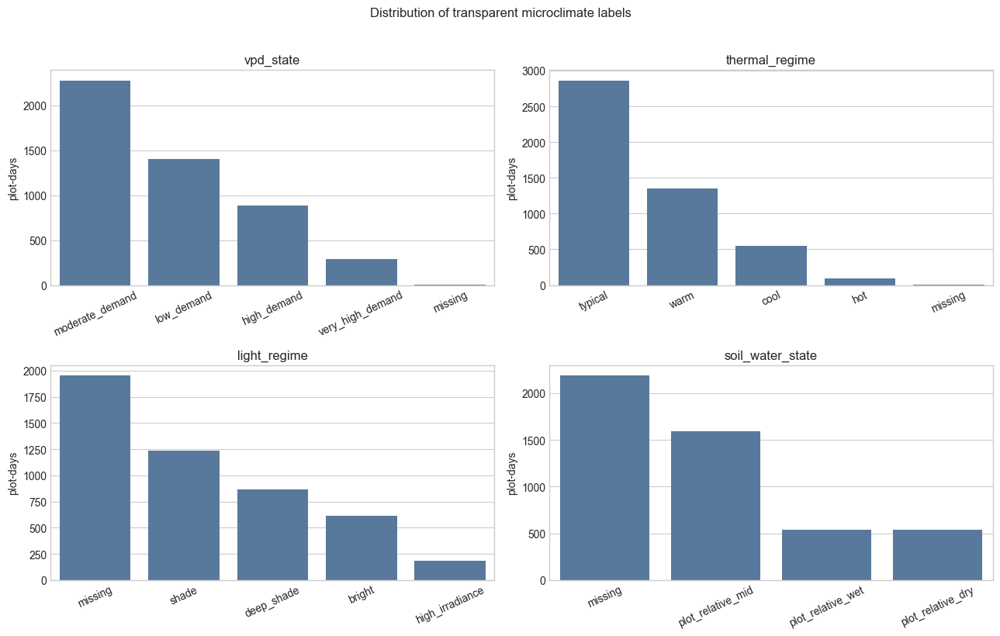

,label,rule,meaning
0,vpd_state,"<0.2, 0.2–<0.5, 0.5–<0.8, >=0.8 kPa",increasing atmospheric moisture demand; not tr...
1,thermal_regime,"<25, 25–<27, 27–<29, >=29 °C","cool, typical, warm, hot daily conditions"
2,light_regime,"<5, 5–<25, 25–<100, >=100 µmol m-2 s-1",deep shade through high irradiance
3,soil_water_state,"within-plot <=20th, middle, >=80th percentile",relative dry/mid/wet state; not an absolute mo...


,class,days,label
0,moderate_demand,2275,vpd_state
1,low_demand,1400,vpd_state
2,high_demand,887,vpd_state
3,very_high_demand,290,vpd_state
4,NaN,1,vpd_state
5,typical,2862,thermal_regime
6,warm,1352,thermal_regime
7,cool,547,thermal_regime
8,hot,91,thermal_regime
9,NaN,1,thermal_regime


In [62]:
# Environmental-state labels. Thresholds are explicit so they can be reviewed or changed with the supervisor.
label_rationale = pd.DataFrame([
    {'label': 'vpd_state', 'rule': '<0.2, 0.2–<0.5, 0.5–<0.8, >=0.8 kPa', 'meaning': 'increasing atmospheric moisture demand; not tree stress'},
    {'label': 'thermal_regime', 'rule': '<25, 25–<27, 27–<29, >=29 °C', 'meaning': 'cool, typical, warm, hot daily conditions'},
    {'label': 'light_regime', 'rule': '<5, 5–<25, 25–<100, >=100 µmol m-2 s-1', 'meaning': 'deep shade through high irradiance'},
    {'label': 'soil_water_state', 'rule': 'within-plot <=20th, middle, >=80th percentile', 'meaning': 'relative dry/mid/wet state; not an absolute moisture threshold'},
])
daily_microclimate['vpd_state'] = pd.cut(daily_microclimate['vpd'], [-np.inf, 0.2, 0.5, 0.8, np.inf], labels=['low_demand', 'moderate_demand', 'high_demand', 'very_high_demand'])
daily_microclimate['thermal_regime'] = pd.cut(daily_microclimate['temperature'], [-np.inf, 25, 27, 29, np.inf], labels=['cool', 'typical', 'warm', 'hot'])
daily_microclimate['light_regime'] = pd.cut(daily_microclimate['par'], [-np.inf, 5, 25, 100, np.inf], labels=['deep_shade', 'shade', 'bright', 'high_irradiance'])
soil_q20 = daily_microclimate.groupby('plot')['soil_moisture'].transform(lambda x: x.quantile(0.20))
soil_q80 = daily_microclimate.groupby('plot')['soil_moisture'].transform(lambda x: x.quantile(0.80))
daily_microclimate['soil_water_state'] = np.select(
    [daily_microclimate['soil_moisture'] <= soil_q20, daily_microclimate['soil_moisture'] >= soil_q80],
    ['plot_relative_dry', 'plot_relative_wet'], default='plot_relative_mid'
)
daily_microclimate.loc[daily_microclimate['soil_moisture'].isna(), 'soil_water_state'] = np.nan

label_columns = ['vpd_state', 'thermal_regime', 'light_regime', 'soil_water_state']
label_counts = pd.concat([
    daily_microclimate[label].value_counts(dropna=False).rename_axis('class').reset_index(name='days').assign(label=label)
    for label in label_columns
], ignore_index=True)
label_rationale.to_csv(READINESS_OUT / 'label_rationale.csv', index=False)
label_counts.to_csv(READINESS_OUT / 'label_counts.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, label in zip(axes.flat, label_columns):
    counts = daily_microclimate[label].astype('object').fillna('missing').value_counts()
    sns.barplot(x=counts.index, y=counts.values, color='#4C78A8', ax=ax)
    ax.set_title(label)
    ax.set_xlabel('')
    ax.set_ylabel('plot-days')
    ax.tick_params(axis='x', rotation=25)
fig.suptitle('Distribution of transparent microclimate labels', y=1.02)
fig.tight_layout()
fig.savefig(READINESS_OUT / 'microclimate_label_distribution.png', dpi=180, bbox_inches='tight')
plt.show()
display(label_rationale)
display(label_counts)


### 8.4 Pattern discovery: daily microclimate regimes

K-means is used only to summarise recurring multi-sensor patterns. The number of regimes is selected from 2–5 by the highest silhouette score, and the seed is fixed for reproducibility. PCA is a visual summary of the same standardized inputs, not a classifier.


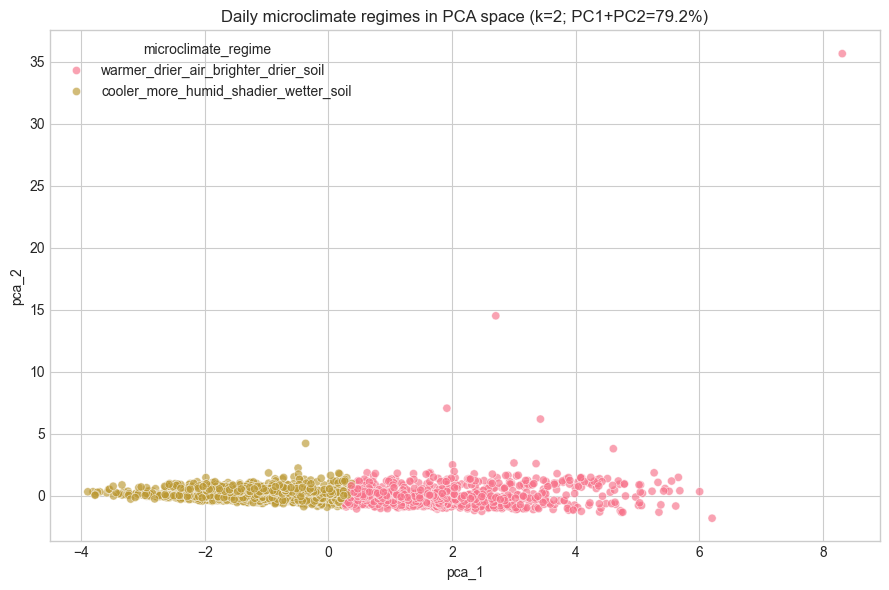

Silhouette selection:


,n_clusters,silhouette_score
0,2,0.3818
1,3,0.2898
2,4,0.2912
3,5,0.2847


Regime profiles in original units:


,cluster_id,temperature,relative_humidity,vpd,par,soil_moisture,profile_name
0,0,27.280,86.738,0.570,48.816,0.178,warmer_drier_air_brighter_drier_soil
1,1,25.706,94.918,0.187,14.986,0.238,cooler_more_humid_shadier_wetter_soil


,microclimate_regime,plot_days
0,cooler_more_humid_shadier_wetter_soil,1597
1,warmer_drier_air_brighter_drier_soil,1019


In [63]:
# Cluster only complete daily rows so every regime uses the same five signals.
cluster_input = daily_microclimate.dropna(subset=daily_value_columns).copy()
cluster_scaler = StandardScaler()
cluster_features = cluster_scaler.fit_transform(cluster_input[daily_value_columns])
silhouette_rows = []
for n_clusters in range(2, min(6, len(cluster_input))):
    candidate = KMeans(n_clusters=n_clusters, random_state=42, n_init=20)
    candidate_labels = candidate.fit_predict(cluster_features)
    silhouette_rows.append({'n_clusters': n_clusters, 'silhouette_score': silhouette_score(cluster_features, candidate_labels)})
silhouette_summary = pd.DataFrame(silhouette_rows)
chosen_k = int(silhouette_summary.loc[silhouette_summary['silhouette_score'].idxmax(), 'n_clusters'])
cluster_model = KMeans(n_clusters=chosen_k, random_state=42, n_init=20)
cluster_input['cluster_id'] = cluster_model.fit_predict(cluster_features)
cluster_profiles = pd.DataFrame(cluster_scaler.inverse_transform(cluster_model.cluster_centers_), columns=daily_value_columns)
cluster_profiles.insert(0, 'cluster_id', cluster_profiles.index)

profile_medians = cluster_profiles[daily_value_columns].median()
def describe_regime(row):
    temperature_word = 'warmer' if row['temperature'] >= profile_medians['temperature'] else 'cooler'
    air_word = 'drier_air' if row['relative_humidity'] < profile_medians['relative_humidity'] else 'more_humid'
    light_word = 'brighter' if row['par'] >= profile_medians['par'] else 'shadier'
    soil_word = 'drier_soil' if row['soil_moisture'] < profile_medians['soil_moisture'] else 'wetter_soil'
    return f'{temperature_word}_{air_word}_{light_word}_{soil_word}'
cluster_profiles['profile_name'] = cluster_profiles.apply(describe_regime, axis=1)
cluster_name_map = cluster_profiles.set_index('cluster_id')['profile_name'].to_dict()
cluster_input['microclimate_regime'] = cluster_input['cluster_id'].map(cluster_name_map)

pca_model = PCA(n_components=2, random_state=42)
pca_values = pca_model.fit_transform(cluster_features)
cluster_input['pca_1'] = pca_values[:, 0]
cluster_input['pca_2'] = pca_values[:, 1]
cluster_sizes = cluster_input['microclimate_regime'].value_counts().rename_axis('microclimate_regime').reset_index(name='plot_days')
silhouette_summary.to_csv(READINESS_OUT / 'cluster_silhouette_scores.csv', index=False)
cluster_profiles.to_csv(READINESS_OUT / 'cluster_profiles.csv', index=False)
cluster_sizes.to_csv(READINESS_OUT / 'cluster_sizes.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=cluster_input, x='pca_1', y='pca_2', hue='microclimate_regime', alpha=0.65, s=35, ax=ax)
ax.set_title(f'Daily microclimate regimes in PCA space (k={chosen_k}; PC1+PC2={pca_model.explained_variance_ratio_.sum():.1%})')
fig.tight_layout()
fig.savefig(READINESS_OUT / 'daily_regime_pca.png', dpi=180, bbox_inches='tight')
plt.show()
print('Silhouette selection:')
display(silhouette_summary.round(4))
print('Regime profiles in original units:')
display(cluster_profiles.round(3))
display(cluster_sizes)


### 8.5 Leakage-safe next-day VPD-state baseline

The target is the **next calendar day's** VPD label. The first 60% of dates train candidate models, the next 20% select a model, and the last 20% are held out for the final report. Persistence is included because it is a meaningful time-series baseline.

#### Feature dictionary and leakage safeguards

| Feature group | What it contains | Available when? |
|---|---|---|
| Lag 1 | Previous day's value for each sensor variable | End of day *t* |
| Rolling 3 / 7 day mean | Means of earlier days after a one-day shift | End of day *t* |
| Seasonal terms | Sine and cosine of calendar day | Known on day *t* |
| Target | VPD state on day *t + 1* | Never used as a feature |

The code removes targets when the next recorded date is not exactly one day later. Scaling and imputation are fitted inside each candidate-model pipeline using the training split only. Same-day temperature and RH are not used to predict same-day VPD, and the final 20% test period is not used to choose the model.


Plot is kept for split auditing and reporting but is deliberately excluded from the classifier feature matrix.

Plot is kept for split auditing and reporting but is deliberately excluded from the classifier feature matrix.

Plot is kept for split auditing and reporting but is deliberately excluded from the classifier feature matrix.

Plot is kept for split auditing and reporting but is deliberately excluded from the classifier feature matrix.

In [64]:
# Make strictly historical features and a true next-calendar-day target.
forecast_frame = daily_microclimate.copy().sort_values(['plot', 'date']).reset_index(drop=True)
for column in daily_value_columns:
    grouped = forecast_frame.groupby('plot')[column]
    forecast_frame[f'{column}_lag1'] = grouped.shift(1)
    forecast_frame[f'{column}_roll3'] = grouped.transform(lambda x: x.shift(1).rolling(3, min_periods=2).mean())
    forecast_frame[f'{column}_roll7'] = grouped.transform(lambda x: x.shift(1).rolling(7, min_periods=4).mean())
forecast_frame['day_of_year_sin'] = np.sin(2 * np.pi * forecast_frame['date'].dt.dayofyear / 365.25)
forecast_frame['day_of_year_cos'] = np.cos(2 * np.pi * forecast_frame['date'].dt.dayofyear / 365.25)
plot_groups = forecast_frame.groupby('plot')
forecast_frame['target_vpd_state'] = plot_groups['vpd_state'].shift(-1)
next_date = plot_groups['date'].shift(-1)
forecast_frame.loc[(next_date - forecast_frame['date']) != pd.Timedelta(days=1), 'target_vpd_state'] = np.nan

lag_features = [column for column in forecast_frame.columns if column.endswith(('_lag1', '_roll3', '_roll7'))]
model_features = lag_features + ['day_of_year_sin', 'day_of_year_cos']
model_data = forecast_frame.dropna(subset=['target_vpd_state']).copy()
model_dates = np.sort(model_data['date'].unique())
train_cutoff = model_dates[int(len(model_dates) * 0.60)]
validation_cutoff = model_dates[int(len(model_dates) * 0.80)]
train_data = model_data[model_data['date'] <= train_cutoff]
validation_data = model_data[(model_data['date'] > train_cutoff) & (model_data['date'] <= validation_cutoff)]
test_data = model_data[model_data['date'] > validation_cutoff]

def metric_row(split, model_name, observed, predicted):
    return {'split': split, 'model': model_name, 'n_days': len(observed),
            'accuracy': accuracy_score(observed, predicted),
            'balanced_accuracy': balanced_accuracy_score(observed, predicted),
            'macro_f1': f1_score(observed, predicted, average='macro')}

model_factories = {
    'logistic_regression': lambda: Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('model', LogisticRegression(max_iter=2000, class_weight='balanced', C=0.2, random_state=42))]),
    'hist_gradient_boosting': lambda: Pipeline([('impute', SimpleImputer(strategy='median')), ('model', HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, l2_regularization=1, class_weight='balanced', random_state=42))]),
}
validation_metrics = [metric_row('validation', 'persistence', validation_data['target_vpd_state'].astype(str), validation_data['vpd_state'].astype(str))]
for model_name, factory in model_factories.items():
    candidate_model = factory()
    candidate_model.fit(train_data[model_features], train_data['target_vpd_state'].astype(str))
    validation_metrics.append(metric_row('validation', model_name, validation_data['target_vpd_state'].astype(str), candidate_model.predict(validation_data[model_features])))
validation_metrics = pd.DataFrame(validation_metrics).sort_values('macro_f1', ascending=False)
selected_model_name = validation_metrics.iloc[0]['model']

if selected_model_name == 'persistence':
    final_prediction = test_data['vpd_state'].astype(str)
else:
    selected_model = model_factories[selected_model_name]()
    train_and_validation = pd.concat([train_data, validation_data], ignore_index=True)
    selected_model.fit(train_and_validation[model_features], train_and_validation['target_vpd_state'].astype(str))
    final_prediction = selected_model.predict(test_data[model_features])
test_metrics = pd.DataFrame([metric_row('held_out_test', selected_model_name, test_data['target_vpd_state'].astype(str), final_prediction)])
class_metrics = pd.DataFrame(classification_report(test_data['target_vpd_state'].astype(str), final_prediction, output_dict=True, zero_division=0)).T.reset_index().rename(columns={'index': 'class'})
prediction_export = test_data[['date', 'plot', 'target_vpd_state', 'vpd_state']].copy()
prediction_export['predicted_vpd_state'] = final_prediction
prediction_export.rename(columns={'vpd_state': 'current_vpd_state'}, inplace=True)

validation_metrics.to_csv(READINESS_OUT / 'vpd_state_validation_metrics.csv', index=False)
test_metrics.to_csv(READINESS_OUT / 'vpd_state_heldout_metrics.csv', index=False)
class_metrics.to_csv(READINESS_OUT / 'vpd_state_heldout_class_metrics.csv', index=False)
prediction_export.to_csv(READINESS_OUT / 'vpd_state_heldout_predictions.csv', index=False)
daily_microclimate.to_csv(READINESS_OUT / 'daily_microclimate_labels.csv', index=False)
cluster_input.to_csv(READINESS_OUT / 'daily_microclimate_regimes.csv', index=False)

print(f'Time split: train through {pd.Timestamp(train_cutoff).date()}, validation through {pd.Timestamp(validation_cutoff).date()}, held-out test after that.')
print('Validation comparison used for model selection:')
display(validation_metrics.round(4))
print(f'Selected model: {selected_model_name}')
print('Held-out next-day performance:')
display(test_metrics.round(4))
print('Held-out class metrics:')
display(class_metrics.round(4))
print('Limitation: these are microclimate-state forecasts only. They do not estimate tree health, survival, growth, or causal effects.')


Time split: train through 2025-11-01, validation through 2026-03-29, held-out test after that.
Validation comparison used for model selection:


,split,model,n_days,accuracy,balanced_accuracy,macro_f1
1,validation,logistic_regression,1035,0.5043,0.5351,0.4915
0,validation,persistence,1035,0.6454,0.6116,0.4897
2,validation,hist_gradient_boosting,1035,0.4232,0.3471,0.3352


Selected model: logistic_regression
Held-out next-day performance:


,split,model,n_days,accuracy,balanced_accuracy,macro_f1
0,held_out_test,logistic_regression,778,0.5013,0.5939,0.5048


Held-out class metrics:


,class,precision,recall,f1-score,support
0,high_demand,0.3347,0.5694,0.4216,144.0000
1,low_demand,0.5185,0.7044,0.5973,159.0000
2,moderate_demand,0.7696,0.3594,0.4900,409.0000
3,very_high_demand,0.3889,0.7424,0.5104,66.0000
4,accuracy,0.5013,0.5013,0.5013,0.5013
5,macro avg,0.5029,0.5939,0.5048,778.0000
6,weighted avg,0.6055,0.5013,0.5010,778.0000


Limitation: these are microclimate-state forecasts only. They do not estimate tree health, survival, growth, or causal effects.


### 8.6 Formal chronological VPD-state evaluation

Candidate models are fitted on the first 60% of valid dates and compared only on the following 20%. After that choice, the selected learned model may be refitted on train plus validation data; the final 20% remains untouched until this report. The tables below show the exact date ranges and representation by class and plot.

The final report includes accuracy, balanced accuracy, macro-F1, a confusion matrix and per-class precision, recall and F1. Macro one-vs-rest AUC is reported only when the chosen model supplies probabilities and the final test period contains every VPD-state class.


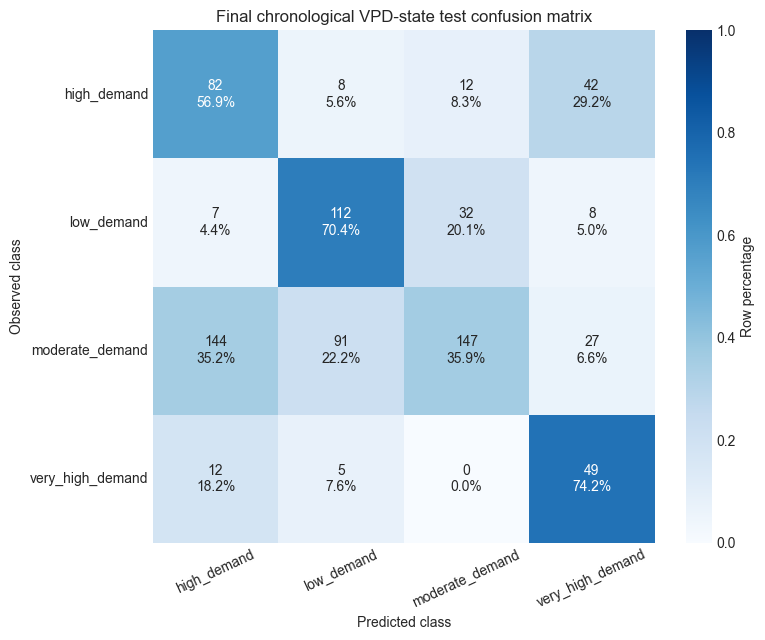

Chronological split audit:


,split,rows,unique_dates,start_date,end_date,plots
0,train,3031,445,2024-08-14,2025-11-01,7
1,validation,1035,148,2025-11-02,2026-03-29,7
2,final_test,778,147,2026-03-30,2026-08-23,7


Target-state rows by split:


,split,vpd_state,rows
0,train,high_demand,492
1,train,low_demand,1079
2,train,moderate_demand,1317
3,train,very_high_demand,143
4,validation,high_demand,250
5,validation,low_demand,160
6,validation,moderate_demand,548
7,validation,very_high_demand,77
8,final_test,high_demand,144
9,final_test,low_demand,159


Rows by plot and split:


,split,plot,rows
0,train,CN2,403
1,train,FT4MD,431
2,train,FT4MR,432
3,train,FT4TH,445
4,train,LP3,445
5,train,UP2,444
6,train,US5,431
7,validation,CN2,148
8,validation,FT4MD,148
9,validation,FT4MR,148


Untouched final-test summary:


,model,evaluation,rows,accuracy,balanced_accuracy,macro_f1,macro_ovr_auc,macro_ovr_auc_note
0,logistic_regression,untouched chronological final 20%,778,0.5013,0.5939,0.5048,0.8159,Reported: selected model provides probabilitie...


Final-test per-class metrics:


,class,precision,recall,f1,support
0,high_demand,0.3347,0.5694,0.4216,144
1,low_demand,0.5185,0.7044,0.5973,159
2,moderate_demand,0.7696,0.3594,0.4900,409
3,very_high_demand,0.3889,0.7424,0.5104,66


Macro OVR AUC: Reported: selected model provides probabilities and every class occurs in the final test.


In [65]:
# Audit the existing chronological split and report final-test performance.
# This cell depends on the leakage-safe split and model selection in the previous cell.
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support, roc_auc_score

split_frames = {'train': train_data, 'validation': validation_data, 'final_test': test_data}
split_audit_rows = []
for split_name, split_frame in split_frames.items():
    split_audit_rows.append({
        'split': split_name,
        'rows': len(split_frame),
        'unique_dates': split_frame['date'].nunique(),
        'start_date': split_frame['date'].min().date().isoformat(),
        'end_date': split_frame['date'].max().date().isoformat(),
        'plots': split_frame['plot'].nunique(),
    })
split_audit = pd.DataFrame(split_audit_rows)
split_class_counts = pd.concat([
    frame.assign(split=split_name, vpd_state=frame['target_vpd_state'].astype(str))
    .groupby(['split', 'vpd_state'], as_index=False).size().rename(columns={'size': 'rows'})
    for split_name, frame in split_frames.items()
], ignore_index=True)
split_plot_counts = pd.concat([
    frame.assign(split=split_name).groupby(['split', 'plot'], as_index=False).size().rename(columns={'size': 'rows'})
    for split_name, frame in split_frames.items()
], ignore_index=True)

y_test = test_data['target_vpd_state'].astype(str).to_numpy()
y_pred = np.asarray(final_prediction, dtype=str)
all_vpd_classes = sorted(model_data['target_vpd_state'].astype(str).unique())
test_confusion = confusion_matrix(y_test, y_pred, labels=all_vpd_classes)
confusion_export = pd.DataFrame(test_confusion, index=all_vpd_classes, columns=all_vpd_classes)
confusion_export.index.name = 'observed'
confusion_export.columns.name = 'predicted'
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=all_vpd_classes, zero_division=0
)
final_class_metrics = pd.DataFrame({
    'class': all_vpd_classes, 'precision': precision, 'recall': recall, 'f1': f1, 'support': support
})
final_summary = pd.DataFrame([{
    'model': selected_model_name,
    'evaluation': 'untouched chronological final 20%',
    'rows': len(y_test),
    'accuracy': accuracy_score(y_test, y_pred),
    'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
    'macro_f1': f1_score(y_test, y_pred, labels=all_vpd_classes, average='macro', zero_division=0),
}])

auc_note = 'Omitted: the selected persistence baseline has no probability output.'
final_estimator = None if selected_model_name == 'persistence' else selected_model
if final_estimator is not None and hasattr(final_estimator, 'predict_proba') and set(all_vpd_classes).issubset(set(y_test)):
    probabilities = final_estimator.predict_proba(test_data[model_features])
    probability_classes = list(final_estimator.classes_)
    if set(all_vpd_classes).issubset(set(probability_classes)):
        final_summary['macro_ovr_auc'] = roc_auc_score(
            y_test, probabilities, labels=probability_classes, multi_class='ovr', average='macro'
        )
        auc_note = 'Reported: selected model provides probabilities and every class occurs in the final test.'
    else:
        auc_note = 'Omitted: the fitted model has no probability column for every observed class.'
elif final_estimator is not None and hasattr(final_estimator, 'predict_proba'):
    auc_note = 'Omitted: at least one VPD-state class is absent from the final test period.'
final_summary['macro_ovr_auc_note'] = auc_note

split_audit.to_csv(READINESS_OUT / 'vpd_state_split_audit.csv', index=False)
split_class_counts.to_csv(READINESS_OUT / 'vpd_state_split_class_counts.csv', index=False)
split_plot_counts.to_csv(READINESS_OUT / 'vpd_state_split_plot_counts.csv', index=False)
final_summary.to_csv(READINESS_OUT / 'vpd_state_final_test_summary.csv', index=False)
final_class_metrics.to_csv(READINESS_OUT / 'vpd_state_final_test_per_class_metrics.csv', index=False)
confusion_export.to_csv(READINESS_OUT / 'vpd_state_final_test_confusion_matrix.csv')

short_labels = [label.replace(' atmosphere', '').replace(' demand', '') for label in all_vpd_classes]
row_totals = test_confusion.sum(axis=1, keepdims=True)
row_pct = np.divide(test_confusion, row_totals, out=np.zeros_like(test_confusion, dtype=float), where=row_totals != 0)
confusion_annotations = np.array([
    [f'{count}\n{100 * pct:.1f}%' for count, pct in zip(count_row, pct_row)]
    for count_row, pct_row in zip(test_confusion, row_pct)
])
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(row_pct, annot=confusion_annotations, fmt='', cmap='Blues', vmin=0, vmax=1,
            xticklabels=short_labels, yticklabels=short_labels, cbar_kws={'label': 'Row percentage'}, ax=ax)
ax.set_xlabel('Predicted class')
ax.set_ylabel('Observed class')
ax.set_title('Final chronological VPD-state test confusion matrix')
ax.tick_params(axis='x', rotation=25)
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
fig.savefig(READINESS_OUT / 'vpd_state_final_test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

print('Chronological split audit:')
display(split_audit)
print('Target-state rows by split:')
display(split_class_counts)
print('Rows by plot and split:')
display(split_plot_counts)
print('Untouched final-test summary:')
display(final_summary.round(4))
print('Final-test per-class metrics:')
display(final_class_metrics.round(4))
print(f'Macro OVR AUC: {auc_note}')


**Figure 8.3 — Final-test VPD-state confusion matrix.**  
*Source: untouched final 20% of dates after model selection on earlier dates. Read this with the per-class precision, recall and F1 table immediately above.*

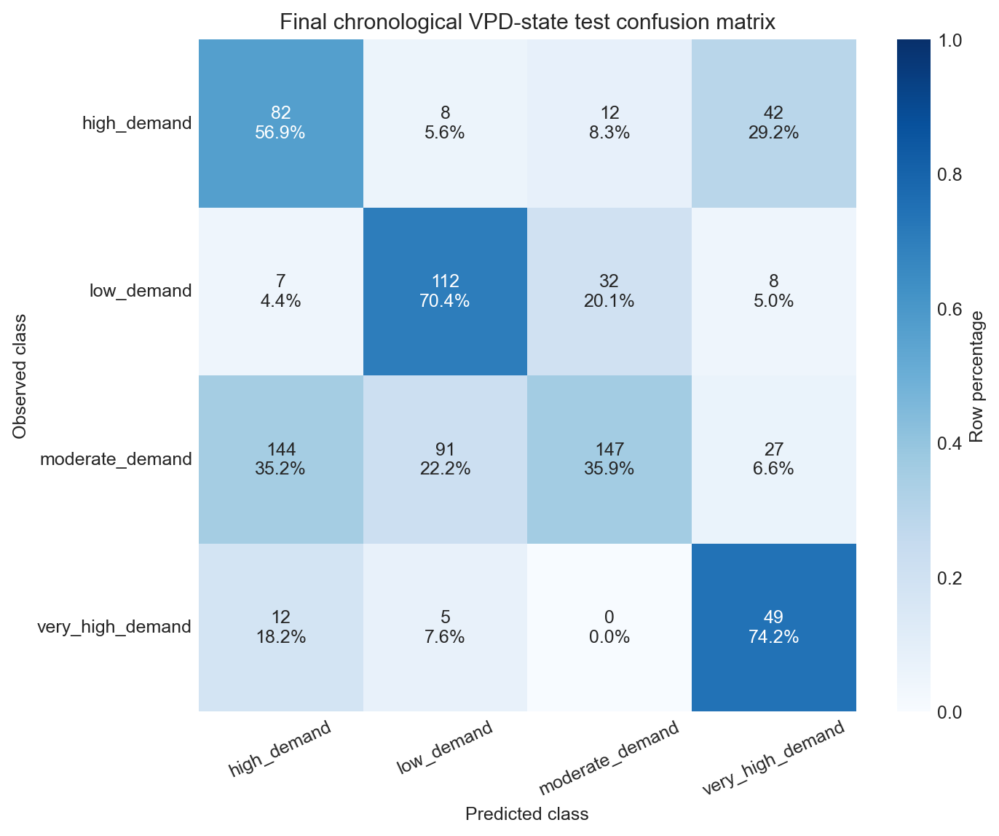

In [66]:
# Show the saved full-resolution figure next to the result it supports.
from pathlib import Path
from IPython.display import Image, Markdown, display

figure_path = Path(OUT_ROOT) / 'readiness/vpd_state_final_test_confusion_matrix.png'
display(Markdown("**Figure 8.3 — Final-test VPD-state confusion matrix.**  \n*Source: untouched final 20% of dates after model selection on earlier dates. Read this with the per-class precision, recall and F1 table immediately above.*"))
display(Image(filename=str(figure_path)))


### 8.7 Supplemental chronological regression holdout

This check asks whether current conditions predict a later period. For each target, all candidates, including persistence, are compared on the middle 20% of dates after fitting on the first 60%. The winning validation method is then reported once on the final 20%. A persistence result is a valid outcome: it means the learned models did not improve the next-day forecast.

In [67]:
# Independent chronological holdout for the existing daily forecasting frame.
# It preserves the separate LOSO site-transfer workflow above.
from scripts.microclimate_forecasting import MODEL_ORDER, MODEL_SELECTION_ORDER, _fold_metrics, _regression_pipeline

if 'forecasting_result' not in globals():
    raise RuntimeError('Run the daily forecasting suite first so this cell uses its RData-derived daily frame.')

temporal_daily = forecasting_result['daily_frame'].copy()
temporal_features = forecasting_result['feature_columns']
temporal_targets = forecasting_result['selected_models']['target'].tolist()
temporal_validation_rows = []
temporal_final_rows = []
temporal_split_rows = []

for target in temporal_targets:
    target_column = f'target_{target}'
    target_frame = temporal_daily.dropna(subset=[target, target_column]).sort_values('date').copy()
    target_dates = np.sort(target_frame['date'].unique())
    if len(target_dates) < 15:
        raise ValueError(f'Not enough dates for a chronological split of {target}.')
    target_train_cutoff = target_dates[int(len(target_dates) * 0.60)]
    target_validation_cutoff = target_dates[int(len(target_dates) * 0.80)]
    target_train = target_frame[target_frame['date'] <= target_train_cutoff]
    target_validation = target_frame[(target_frame['date'] > target_train_cutoff) & (target_frame['date'] <= target_validation_cutoff)]
    target_test = target_frame[target_frame['date'] > target_validation_cutoff]
    for split_name, split_frame in {'train': target_train, 'validation': target_validation, 'final_test': target_test}.items():
        temporal_split_rows.append({
            'target': target, 'split': split_name, 'rows': len(split_frame),
            'start_date': split_frame['date'].min().date().isoformat(),
            'end_date': split_frame['date'].max().date().isoformat(),
            'plots': split_frame['plot'].nunique(),
        })

    validation_candidates = []
    persistence_validation = _fold_metrics(target_validation[target_column], target_validation[target])
    validation_candidates.append({'target': target, 'model_name': 'Persistence', **persistence_validation})
    for model_name in MODEL_ORDER:
        candidate = _regression_pipeline(model_name, temporal_features, target_train)
        candidate.fit(target_train[temporal_features], target_train[target_column])
        candidate_prediction = candidate.predict(target_validation[temporal_features])
        validation_candidates.append({
            'target': target, 'model_name': model_name,
            **_fold_metrics(target_validation[target_column], candidate_prediction)
        })
    target_validation_metrics = pd.DataFrame(validation_candidates)
    temporal_validation_rows.extend(target_validation_metrics.assign(split='validation').to_dict('records'))
    best_mae = target_validation_metrics['mae'].min()
    finalists = target_validation_metrics[target_validation_metrics['mae'] <= best_mae * 1.01].copy()
    finalists['complexity_order'] = finalists['model_name'].map(MODEL_SELECTION_ORDER)
    selected_regression = finalists.sort_values(['complexity_order', 'mae']).iloc[0]['model_name']

    persistence_test_metrics = _fold_metrics(target_test[target_column], target_test[target])
    train_validation = pd.concat([target_train, target_validation], ignore_index=True)
    if selected_regression == 'Persistence':
        selected_test_prediction = target_test[target].to_numpy()
    else:
        selected_pipeline = _regression_pipeline(selected_regression, temporal_features, train_validation)
        selected_pipeline.fit(train_validation[temporal_features], train_validation[target_column])
        selected_test_prediction = selected_pipeline.predict(target_test[temporal_features])
    selected_test_metrics = _fold_metrics(target_test[target_column], selected_test_prediction)
    temporal_final_rows.append({
        'target': target, 'selected_model': selected_regression,
        'evaluation': 'untouched chronological final 20%',
        'persistence_mae': persistence_test_metrics['mae'],
        'persistence_rmse': persistence_test_metrics['rmse'],
        'persistence_r2': persistence_test_metrics['r2'],
        'mae': selected_test_metrics['mae'],
        'rmse': selected_test_metrics['rmse'],
        'r2': selected_test_metrics['r2'],
        'persistence_minus_model_mae': persistence_test_metrics['mae'] - selected_test_metrics['mae'],
        'mae_improvement_vs_persistence_pct': 100 * (persistence_test_metrics['mae'] - selected_test_metrics['mae']) / persistence_test_metrics['mae'] if persistence_test_metrics['mae'] else np.nan,
        'final_test_rows': len(target_test),
    })

temporal_validation_metrics = pd.DataFrame(temporal_validation_rows)
temporal_final_metrics = pd.DataFrame(temporal_final_rows)
temporal_split_audit = pd.DataFrame(temporal_split_rows)
temporal_validation_metrics.to_csv(forecast_out / 'daily_temporal_validation_comparison.csv', index=False)
temporal_final_metrics.to_csv(forecast_out / 'daily_temporal_final_test_metrics.csv', index=False)
temporal_split_audit.to_csv(forecast_out / 'daily_temporal_split_audit.csv', index=False)

print('Chronological regression split audit:')
display(temporal_split_audit)
print('Validation comparison used for model selection:')
display(temporal_validation_metrics.round(4))
print('Final chronological regression results (positive MAE delta favours the selected model):')
display(temporal_final_metrics.round(4))


Chronological regression split audit:


,target,split,rows,start_date,end_date,plots
0,temperature,train,3026,2024-08-14,2025-11-01,7
1,temperature,validation,1025,2025-11-02,2026-03-29,7
2,temperature,final_test,776,2026-03-30,2026-08-23,7
3,relative_humidity,train,3026,2024-08-14,2025-11-01,7
4,relative_humidity,validation,1025,2025-11-02,2026-03-29,7
5,relative_humidity,final_test,776,2026-03-30,2026-08-23,7
6,vpd,train,3026,2024-08-14,2025-11-01,7
7,vpd,validation,1025,2025-11-02,2026-03-29,7
8,vpd,final_test,776,2026-03-30,2026-08-23,7
9,par,train,2186,2024-08-14,2025-10-20,7


Validation comparison used for model selection:


,target,model_name,mae,rmse,r2,split
0,temperature,Persistence,0.5121,0.6781,0.5469,validation
1,temperature,Ridge,0.5259,0.6663,0.5626,validation
2,temperature,Elastic net,0.5239,0.6641,0.5655,validation
3,temperature,Histogram gradient boosting,0.5653,0.7317,0.4725,validation
4,temperature,Random forest,0.5425,0.7228,0.4852,validation
5,temperature,Extra trees,0.5428,0.6992,0.5183,validation
6,relative_humidity,Persistence,2.4648,3.2442,0.6098,validation
7,relative_humidity,Ridge,2.5939,3.3421,0.5859,validation
8,relative_humidity,Elastic net,2.6101,3.3461,0.5850,validation
9,relative_humidity,Histogram gradient boosting,3.0748,4.1302,0.3676,validation


Final chronological regression results (positive MAE delta favours the selected model):


,target,selected_model,evaluation,persistence_mae,persistence_rmse,persistence_r2,mae,rmse,r2,persistence_minus_model_mae,mae_improvement_vs_persistence_pct,final_test_rows
0,temperature,Persistence,untouched chronological final 20%,0.7550,0.9658,0.1916,0.7550,0.9658,0.1916,0.0000,0.0000,776
1,relative_humidity,Persistence,untouched chronological final 20%,2.6065,3.5646,0.4846,2.6065,3.5646,0.4846,0.0000,0.0000,776
2,vpd,Persistence,untouched chronological final 20%,137.5000,198.2280,0.4106,137.5000,198.2280,0.4106,0.0000,0.0000,776
3,par,Random forest,untouched chronological final 20%,4.5292,10.0746,0.5072,6.9789,12.9960,0.1800,-2.4497,-54.0858,160
4,soil_moisture,Persistence,untouched chronological final 20%,0.0121,0.0174,0.9247,0.0121,0.0174,0.9247,0.0000,0.0000,152


### 8.9 Reproducibility manifest

The cell below records the exact RData file, cleaning policy, features, labels, models, split boundaries and output paths used in this run. It is written at the end so it reflects the refreshed tables rather than the old embedded notebook outputs.


### 8.8 Do the screening rules change the main conclusions?

The first sensitivity check compared daily means. This stricter check repeats the VPD labels, time-aware correlations, VPD-state classification, and chronological regression on both the hard-cleaned and analysis-screened tiers. It is included because saturated RH and zero VPD can be real humid conditions as well as possible sensor issues.

The comparison is descriptive: close results support robustness to the screening policy, while changes identify conclusions that should be reported with caution. Eligible row counts differ slightly between tiers (RH: 776 versus 779; VPD: 776 versus 782), so metric differences reflect both screening and small coverage changes rather than a pure causal screening effect. The review thresholds were not externally calibrated, and sensor maintenance or calibration logs were not available; saturated RH and zero VPD may therefore be genuine observations.

VPD-state agreement after screening: 83.5% of paired plot-days.
Largest absolute change in a within-plot Spearman effect: 0.095.
Values close to the main result indicate robustness; larger differences should be reported as screening-sensitive.
VPD label agreement:


,paired_plot_days,matching_labels,changed_labels,agreement_rate
0,4846,4048,798,0.8353


Correlation comparison:


data_tier,variable_1,variable_2,analysis_screened,hard_cleaned,screened_minus_hard_cleaned
0,par,soil_moisture,-0.1987,-0.1970,-0.0017
1,relative_humidity,par,-0.5784,-0.5006,-0.0779
2,relative_humidity,soil_moisture,0.4969,0.5216,-0.0247
3,relative_humidity,vpd,-0.9920,-0.9914,-0.0005
4,temperature,par,0.4989,0.4037,0.0951
5,temperature,relative_humidity,-0.6458,-0.6950,0.0492
6,temperature,soil_moisture,-0.4705,-0.4728,0.0022
7,temperature,vpd,0.6922,0.7571,-0.0648
8,vpd,par,0.5878,0.5107,0.0771
9,vpd,soil_moisture,-0.4385,-0.5014,0.0628


Final-period VPD classifier comparison:


,model_name,rows,accuracy,balanced_accuracy,macro_f1,selected_model,data_tier
0,logistic_regression,778,0.5013,0.5939,0.5048,logistic_regression,hard_cleaned
1,persistence,778,0.5977,0.5827,0.5837,persistence,analysis_screened


Final-period regression comparison:


,target,selected_model,persistence_mae,mae,rmse,r2,mae_improvement_vs_persistence_pct,final_test_rows,data_tier
0,temperature,Persistence,0.7550,0.7550,0.9658,0.1916,0.0000,776,hard_cleaned
1,relative_humidity,Persistence,2.6065,2.6065,3.5646,0.4846,0.0000,776,hard_cleaned
2,vpd,Persistence,137.5000,137.5000,198.2280,0.4106,0.0000,776,hard_cleaned
3,par,Random forest,4.5292,6.9789,12.9960,0.1800,-54.0858,160,hard_cleaned
4,soil_moisture,Persistence,0.0121,0.0121,0.0174,0.9247,0.0000,152,hard_cleaned
5,temperature,Persistence,0.7532,0.7532,0.9649,0.1883,0.0000,776,analysis_screened
6,relative_humidity,Persistence,3.2196,3.2196,4.2948,0.6274,0.0000,779,analysis_screened
7,vpd,Persistence,156.6522,156.6522,224.4467,0.5244,0.0000,782,analysis_screened
8,par,Elastic net,5.3555,5.6042,10.8173,0.7846,-4.6431,161,analysis_screened
9,soil_moisture,Persistence,0.0122,0.0122,0.0175,0.9237,0.0000,152,analysis_screened


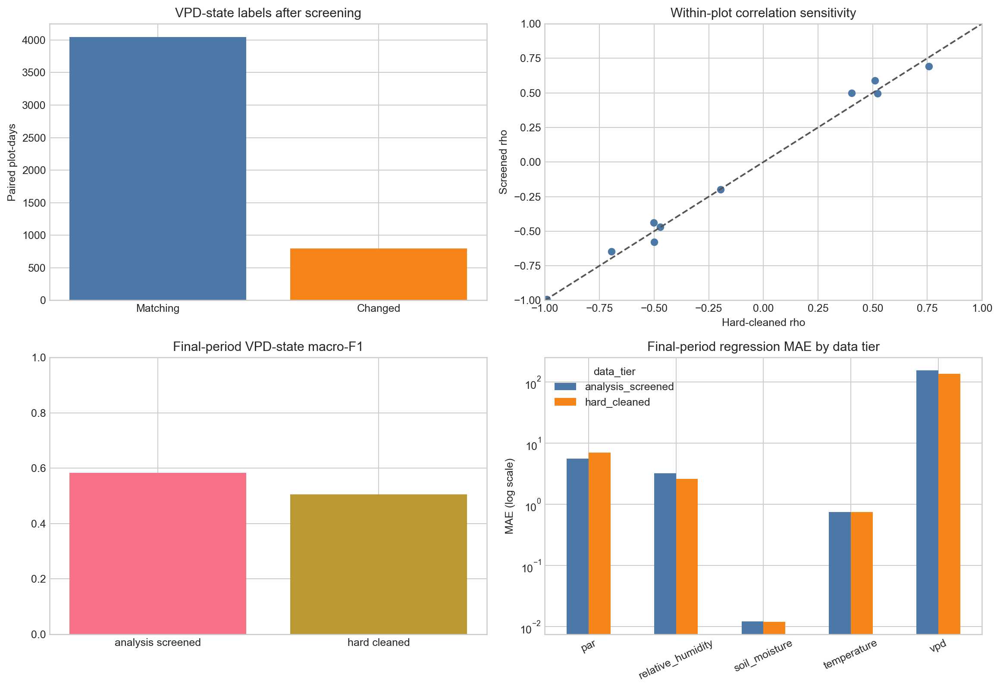

In [68]:
# Repeat the principal readiness analyses on both data tiers.
from scripts.microclimate_sensitivity import run_screening_robustness

ROBUSTNESS_OUT = Path(OUT_ROOT) / 'screening_robustness'
screening_robustness = run_screening_robustness(
    df_hard_clean,
    df_analysis_screened,
    ROBUSTNESS_OUT,
    n_bootstrap=300,
)

label_check = screening_robustness['label_summary']
correlation_check = screening_robustness['correlation_comparison']
classifier_check = screening_robustness['classifier_metrics']
regression_check = screening_robustness['regression_metrics']

agreement_pct = 100 * label_check.loc[0, 'agreement_rate']
largest_rho_change = correlation_check['screened_minus_hard_cleaned'].abs().max()
print(f'VPD-state agreement after screening: {agreement_pct:.1f}% of paired plot-days.')
print(f'Largest absolute change in a within-plot Spearman effect: {largest_rho_change:.3f}.')
print('Values close to the main result indicate robustness; larger differences should be reported as screening-sensitive.')

print('VPD label agreement:')
display(label_check.round(4))
print('Correlation comparison:')
display(correlation_check.round(4))
print('Final-period VPD classifier comparison:')
display(classifier_check.round(4))
print('Final-period regression comparison:')
display(regression_check.round(4))
display(Image(filename=str(screening_robustness['figure_path'])))

In [69]:
# Save a compact record of this run after all analysis and evaluation cells have finished.
import json
import platform
import sklearn

manifest_path = Path(OUT_ROOT) / 'reproducibility_manifest.json'
manifest_markdown_path = Path(OUT_ROOT) / 'reproducibility_manifest.md'
quality_flag_counts = (
    df_clean.loc[df_clean['quality_flag'], 'quality_reason'].value_counts().sort_index().to_dict()
)

run_manifest = {
    'data': {
        'source_file': str(RDATA_PATH.relative_to(PROJECT_ROOT)),
        'sha256': raw_checksum,
        'raw_rows': int(len(df_raw)),
        'hard_clean_rows': int(len(df_hard_clean)),
        'analysis_screened_rows': int(len(df_analysis_screened)),
        'columns': list(df_raw.columns),
    },
    'cleaning': {
        'hard_removal_rules': [
            'Remove rows with a missing required timestamp, value, sensor identifier, plot, parameter, sensor, forest type or stage.',
            'Remove soil-moisture readings above 0.6 m3/m3.',
        ],
        'removed_rows_by_rule': {key: int(value) for key, value in removed_counts.items()},
        'quality_flag_policy': 'Candidate anomalies remain in df_hard_clean for audit. The primary EDA and modelling tier excludes all flagged rows; sensitivity outputs compare both tiers.',
        'quality_flag_counts': {key: int(value) for key, value in quality_flag_counts.items()},
    },
    'reproducibility': {
        'random_seed': 42,
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'scikit_learn': sklearn.__version__,
    },
    'labels': label_rationale.to_dict(orient='records'),
    'vpd_state_evaluation': {
        'target': 'next-calendar-day VPD state',
        'features': model_features,
        'candidate_models': ['persistence', *model_factories.keys()],
        'selection_metric': 'validation macro-F1',
        'split_audit': split_audit.to_dict(orient='records'),
        'final_test_metrics': final_summary.to_dict(orient='records'),
        'final_test_per_class_metrics': final_class_metrics.to_dict(orient='records'),
    },
    'regression_evaluation': {
        'targets': temporal_targets,
        'features': temporal_features,
        'candidate_models': ['Persistence', *MODEL_ORDER.keys()],
        'site_transfer_metric_set': ['MAE', 'RMSE', 'R2'],
        'temporal_selection_metric': 'validation MAE',
        'temporal_split_audit': temporal_split_audit.to_dict(orient='records'),
        'temporal_final_test_metrics': temporal_final_metrics.to_dict(orient='records'),
    },
    'screening_robustness': {
        'vpd_label_agreement': label_check.to_dict(orient='records'),
        'classifier_metrics': classifier_check.to_dict(orient='records'),
        'temporal_regression_metrics': regression_check.to_dict(orient='records'),
    },
    'outputs': {
        'manifest_json': str(manifest_path.relative_to(PROJECT_ROOT)),
        'manifest_markdown': str(manifest_markdown_path.relative_to(PROJECT_ROOT)),
        'data_tier_summary': 'outputs/redesigned/quality/data_tier_summary.csv',
        'screening_sensitivity': 'outputs/redesigned/quality/screening_sensitivity_daily_means.csv',
        'screening_sensitivity_figure': 'outputs/redesigned/quality/screening_sensitivity_daily_means.png',
        'block_correlation_summary': 'outputs/redesigned/readiness/daily_block_spearman_correlations.csv',
        'data_tier_summary': 'outputs/redesigned/quality/data_tier_summary.csv',
        'screening_sensitivity': 'outputs/redesigned/quality/screening_sensitivity_daily_means.csv',
        'screening_sensitivity_figure': 'outputs/redesigned/quality/screening_sensitivity_daily_means.png',
        'block_correlation_summary': 'outputs/redesigned/readiness/daily_block_spearman_correlations.csv',
        'forecast_target_coverage': 'outputs/redesigned/forecasting/daily_forecast_target_coverage.csv',
        'data_tier_summary': 'outputs/redesigned/quality/data_tier_summary.csv',
        'screening_sensitivity': 'outputs/redesigned/quality/screening_sensitivity_daily_means.csv',
        'screening_sensitivity_figure': 'outputs/redesigned/quality/screening_sensitivity_daily_means.png',
        'block_correlation_summary': 'outputs/redesigned/readiness/daily_block_spearman_correlations.csv',
        'forecast_target_coverage': 'outputs/redesigned/forecasting/daily_forecast_target_coverage.csv',
        'data_tier_summary': 'outputs/redesigned/quality/data_tier_summary.csv',
        'screening_sensitivity': 'outputs/redesigned/quality/screening_sensitivity_daily_means.csv',
        'screening_sensitivity_figure': 'outputs/redesigned/quality/screening_sensitivity_daily_means.png',
        'block_correlation_summary': 'outputs/redesigned/readiness/daily_block_spearman_correlations.csv',
        'forecast_target_coverage': 'outputs/redesigned/forecasting/daily_forecast_target_coverage.csv',
        'vpd_split_audit': 'outputs/redesigned/readiness/vpd_state_split_audit.csv',
        'vpd_split_class_counts': 'outputs/redesigned/readiness/vpd_state_split_class_counts.csv',
        'vpd_split_plot_counts': 'outputs/redesigned/readiness/vpd_state_split_plot_counts.csv',
        'vpd_final_summary': 'outputs/redesigned/readiness/vpd_state_final_test_summary.csv',
        'vpd_per_class_metrics': 'outputs/redesigned/readiness/vpd_state_final_test_per_class_metrics.csv',
        'vpd_confusion_matrix': 'outputs/redesigned/readiness/vpd_state_final_test_confusion_matrix.csv',
        'vpd_confusion_figure': 'outputs/redesigned/readiness/vpd_state_final_test_confusion_matrix.png',
        'regression_site_transfer': 'outputs/redesigned/forecasting/daily_model_comparison.csv',
        'regression_site_transfer_figure': 'outputs/redesigned/forecasting/daily_model_comparison.png',
        'regression_temporal_validation': 'outputs/redesigned/forecasting/daily_temporal_validation_comparison.csv',
        'regression_temporal_split_audit': 'outputs/redesigned/forecasting/daily_temporal_split_audit.csv',
        'regression_temporal_final_test': 'outputs/redesigned/forecasting/daily_temporal_final_test_metrics.csv',
        'regression_heldout_site_metrics': 'outputs/redesigned/forecasting/daily_heldout_site_metrics.csv',
        'regression_site_variation': 'outputs/redesigned/forecasting/daily_model_site_variation.csv',
        'screening_label_agreement': 'outputs/redesigned/screening_robustness/tier_vpd_label_agreement.csv',
        'screening_correlation_comparison': 'outputs/redesigned/screening_robustness/tier_correlation_comparison.csv',
        'screening_classifier_comparison': 'outputs/redesigned/screening_robustness/tier_vpd_classifier_metrics.csv',
        'screening_regression_comparison': 'outputs/redesigned/screening_robustness/tier_temporal_regression_metrics.csv',
        'screening_robustness_figure': 'outputs/redesigned/screening_robustness/screening_robustness_summary.png',
    },
}
manifest_path.write_text(json.dumps(run_manifest, indent=2, default=str) + '\n')
manifest_markdown_path.write_text(
    '\n'.join([
        '# Microclimate run manifest',
        '',
        f"- Source: `{run_manifest['data']['source_file']}`",
        f"- SHA-256: `{run_manifest['data']['sha256']}`",
        f"- Rows: {run_manifest['data']['raw_rows']:,} raw; {run_manifest['data']['hard_clean_rows']:,} hard-cleaned; {run_manifest['data']['analysis_screened_rows']:,} analysis-screened.",
        '- The primary EDA and modelling dataset excludes review-flagged rows; sensitivity outputs compare it with the hard-cleaned tier.',
        '- Seed: 42. Classification uses chronological 60/20/20; regression reports separate LOSO site-transfer and chronological results.',
        '',
        'See `reproducibility_manifest.json` for split boundaries, feature lists, label rules, model choices, metrics and exact output paths.',
    ]) + '\n'
)
print(f'Reproducibility manifest saved -> {manifest_path}')
print(f'Reproducibility summary saved -> {manifest_markdown_path}')


Reproducibility manifest saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/reproducibility_manifest.json
Reproducibility summary saved -> /Users/siddharthchoudhary09/Desktop/fyp_project/outputs/redesigned/reproducibility_manifest.md


### 8.10 Saved outputs and limits

The readiness tables are saved in `outputs/redesigned/readiness/`, while regression results are saved in `outputs/redesigned/forecasting/`. The reproducibility manifest lists the source file, cleaning rules, features, splits, models and output paths used for this run.

PAR and soil-moisture coverage vary across deployments. Quality flags and class imbalance should be considered whenever these outputs are interpreted.


### Figures: labels and microclimate regimes

These figures show the distribution of transparent environmental labels and the PCA view of unsupervised daily regimes. They support exploration and readiness rather than any claim of biological ground truth.

The figures below are embedded in this notebook after the analysis runs. They are also saved in `outputs/redesigned/` for use in the report.


**Environmental-label distribution**

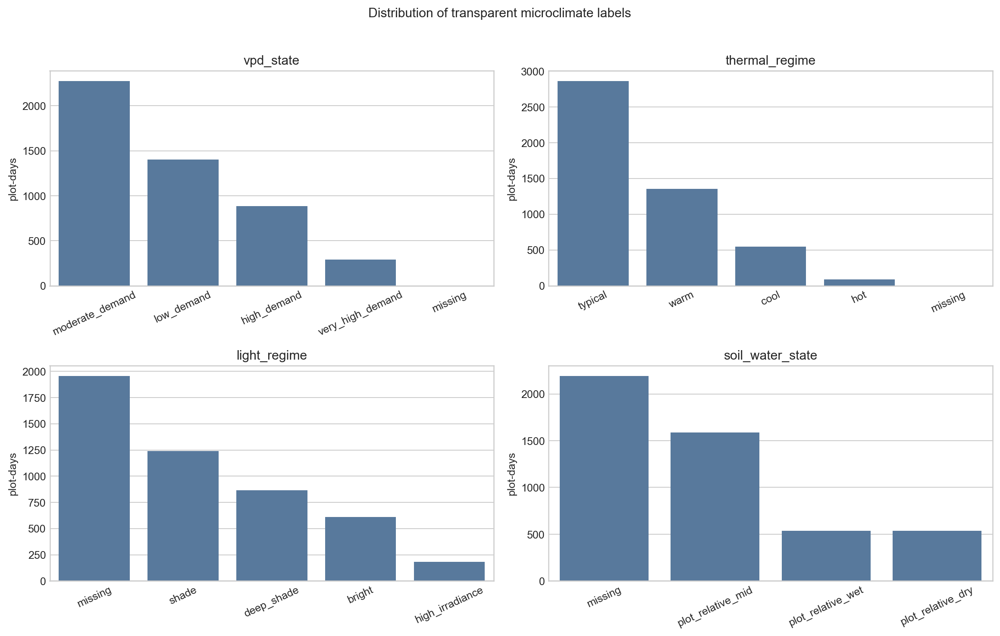

**Daily microclimate regimes in PCA space**

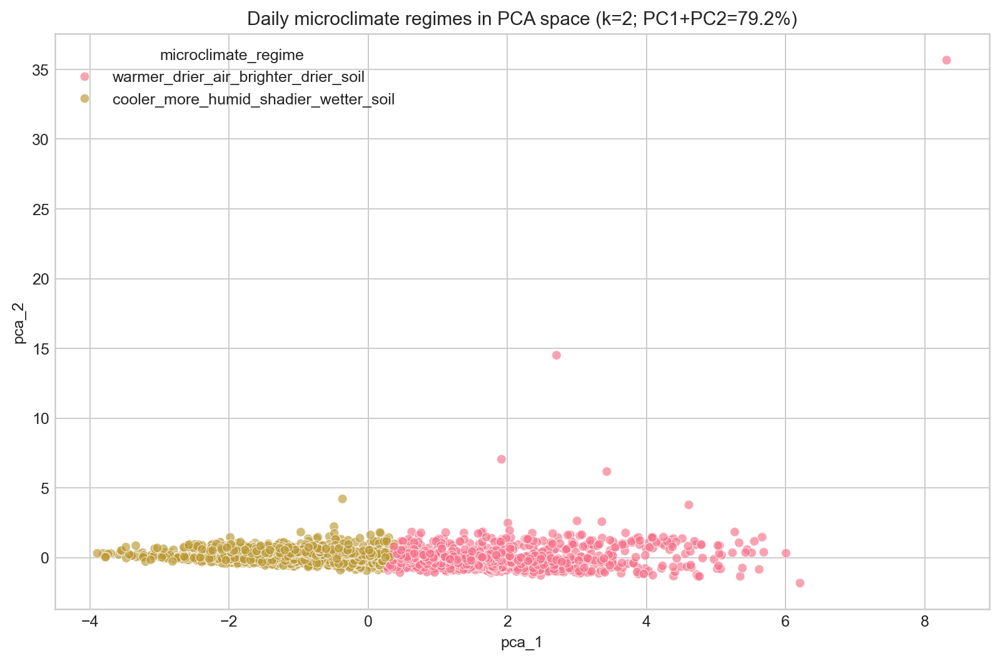

In [70]:
from IPython.display import Image, Markdown, display

_figures = [
    ('Environmental-label distribution', 'readiness/microclimate_label_distribution.png'),
    ('Daily microclimate regimes in PCA space', 'readiness/daily_regime_pca.png')
]
_missing = []
for _caption, _relative_path in _figures:
    _path = Path(OUT_ROOT) / _relative_path
    if _path.exists():
        display(Markdown(f'**{_caption}**'))
        display(Image(filename=str(_path)))
    else:
        _missing.append(_relative_path)
if _missing:
    print('Figures not found:', ', '.join(_missing))


## 9. Conclusions and next steps

The notebook uses the hard-cleaned dataset for EDA and modelling, retaining traceably flagged readings that can be physically plausible. The stricter analysis-screened dataset is reported only as a sensitivity check. It reports descriptive site patterns, time-aware relationship intervals, soil-moisture drydowns, site-transfer benchmarks and chronological next-day tests.

The results describe the seven monitored plots and the observed period. They do not establish causal canopy effects or tree health. Those questions require matched biological measurements and a study design built around them.

## Appendix: supplementary project figures

The figures below are generated by the same raw-data run as the main analysis. They are included in the saved submission notebook so that every exported project figure can be reviewed without opening the output folders.

**par/par_B_daily_range_faceted.png**

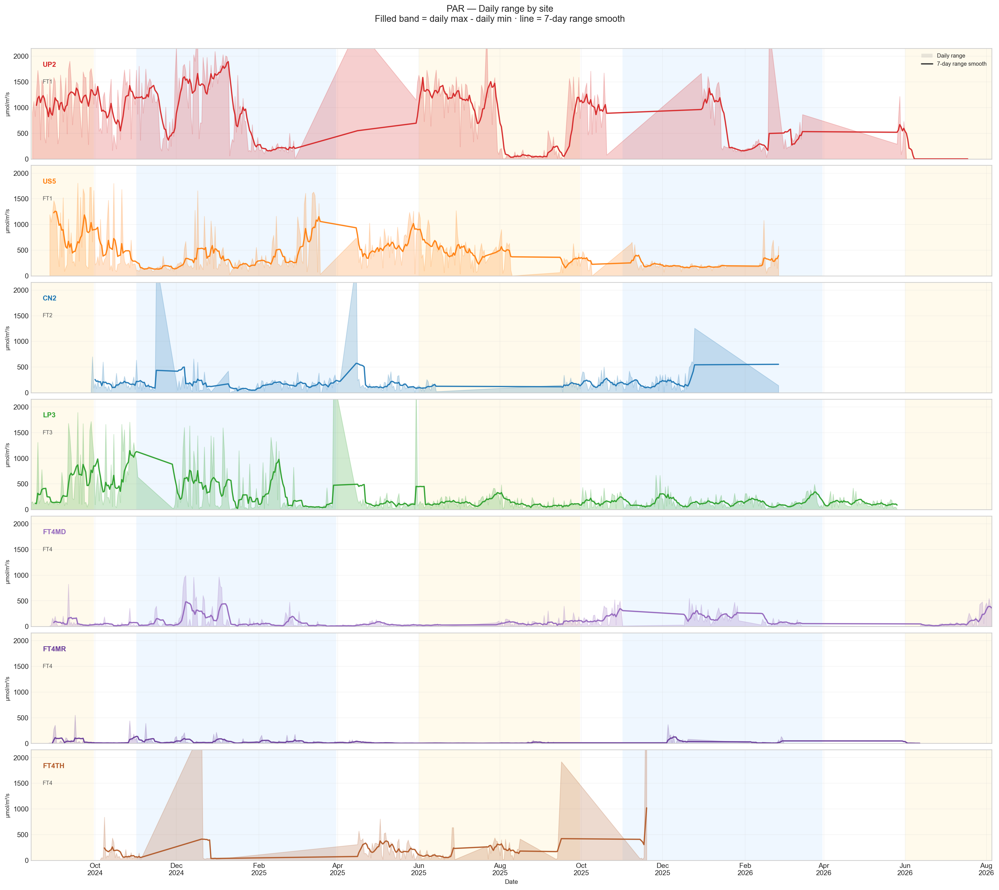

**par/par_D_anomaly_shared.png**

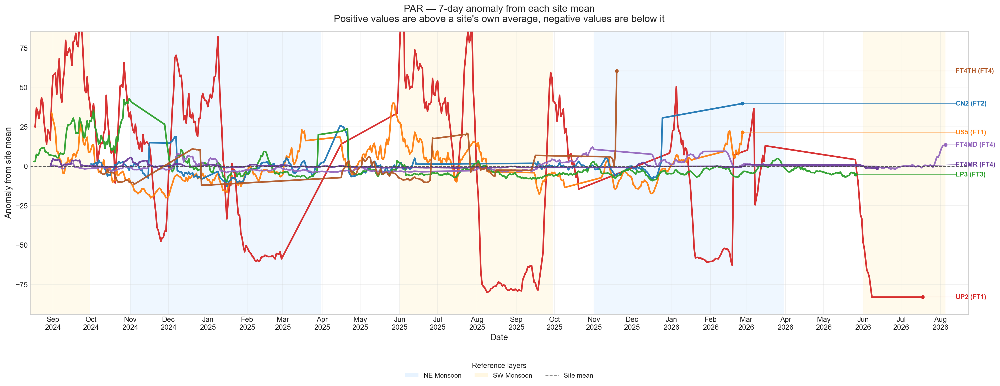

**quality/screening_sensitivity_daily_means.png**

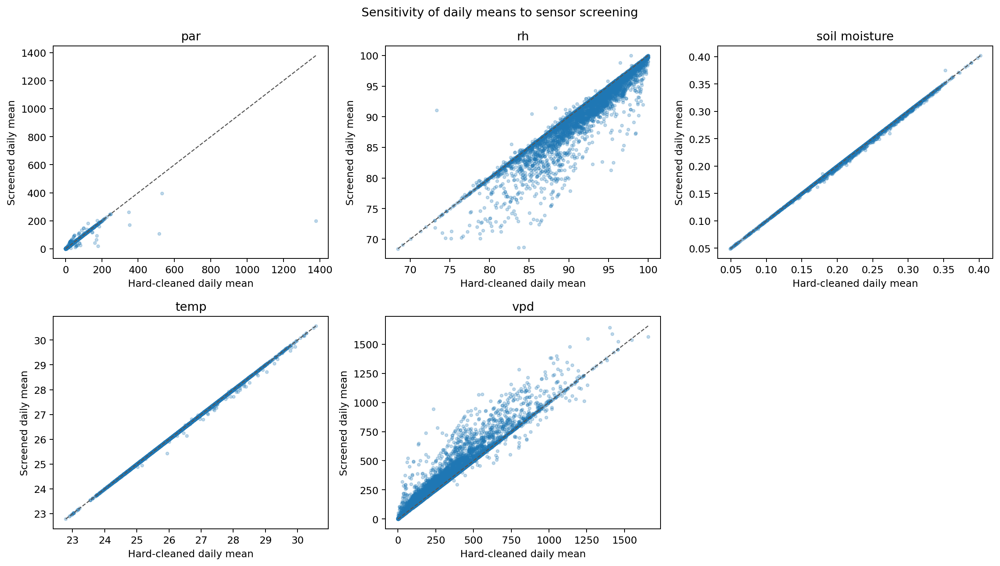

**readiness/daily_relationship_scatter.png**

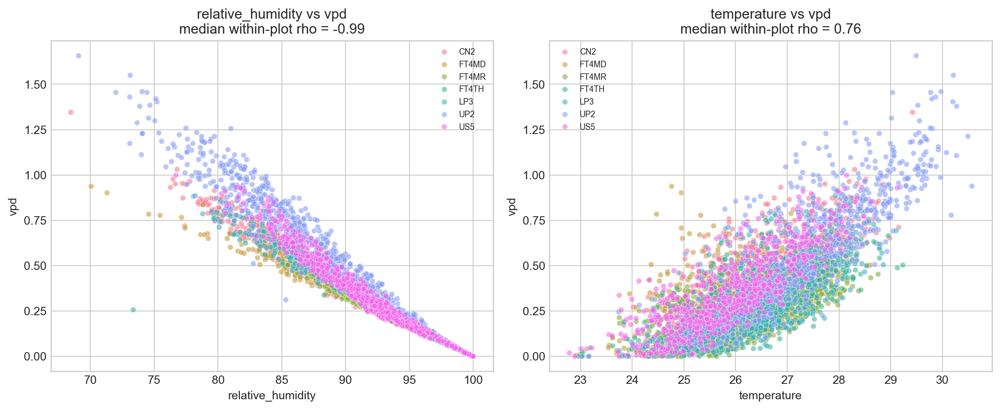

**readiness/daily_spearman_heatmap.png**

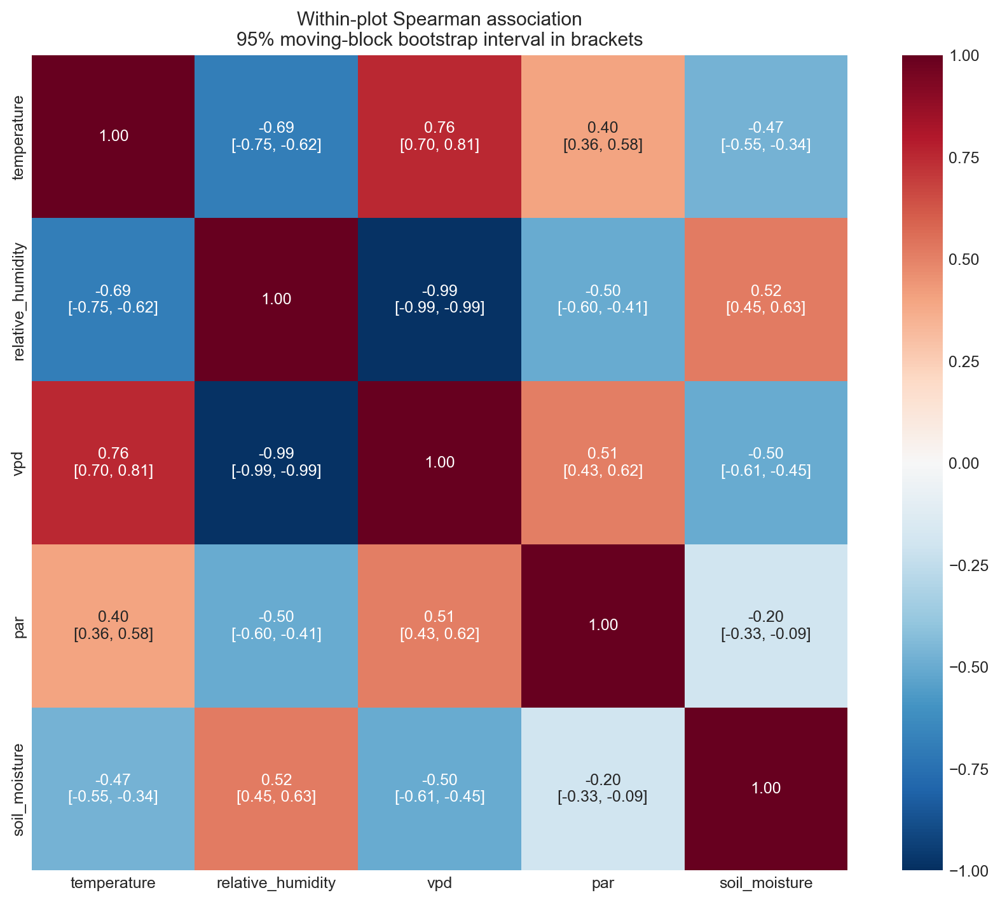

**rh/rh_B_daily_range_faceted.png**

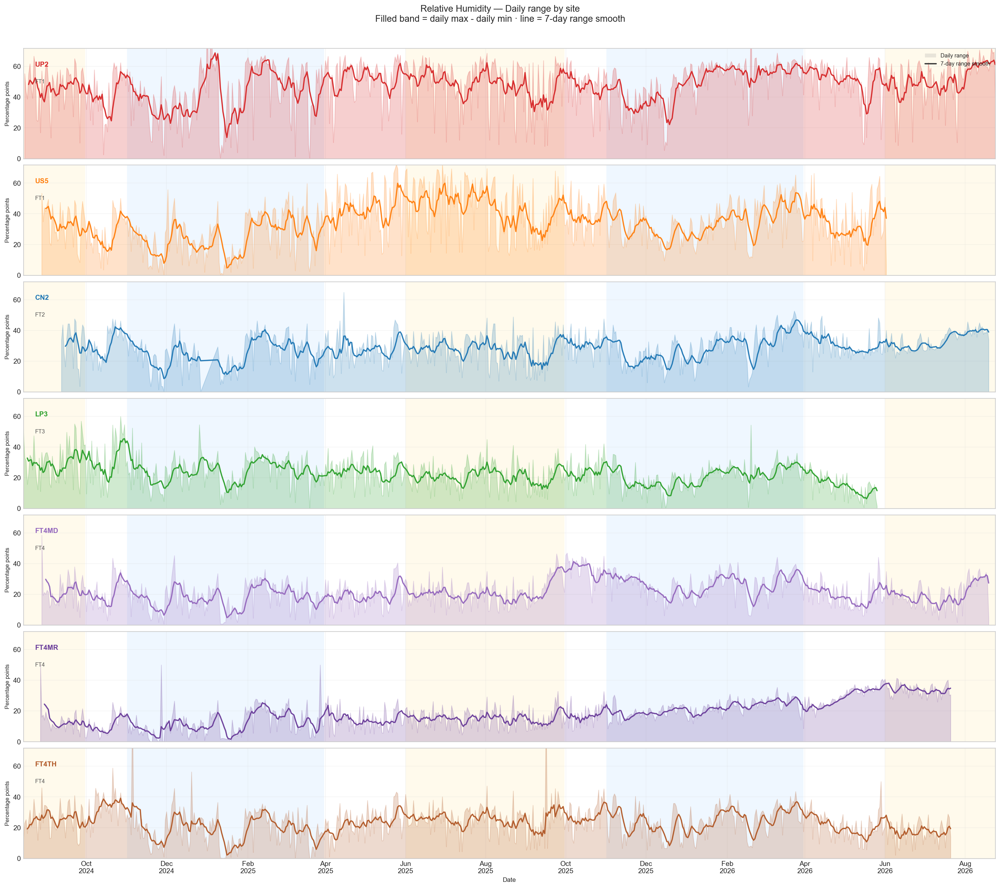

**rh/rh_D_anomaly_shared.png**

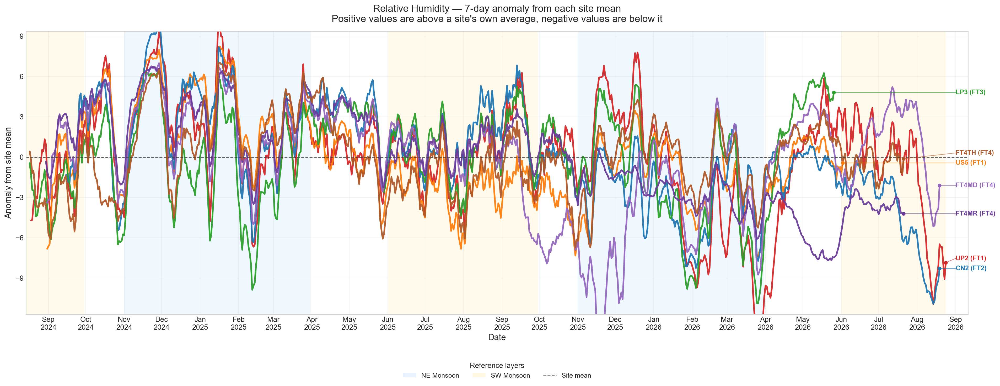

**soil/soil_B_daily_range_faceted.png**

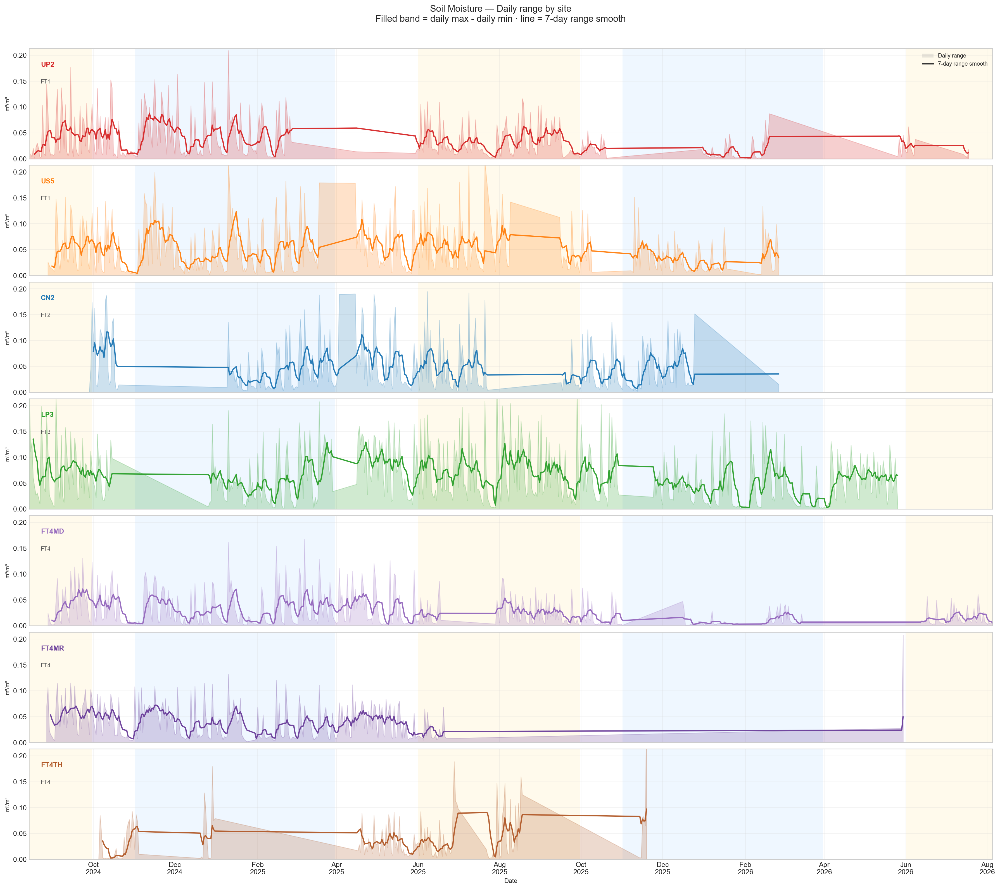

**soil/soil_D_anomaly_shared.png**

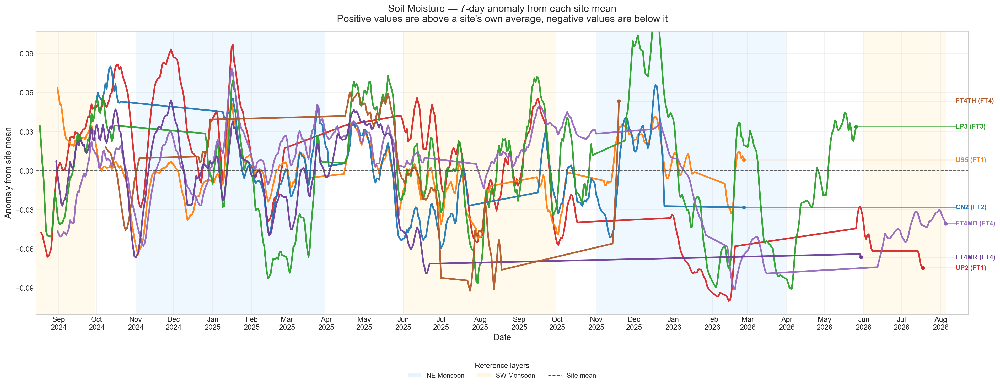

**soil_moisture/soil_J_plot_summary_model_comparison.png**

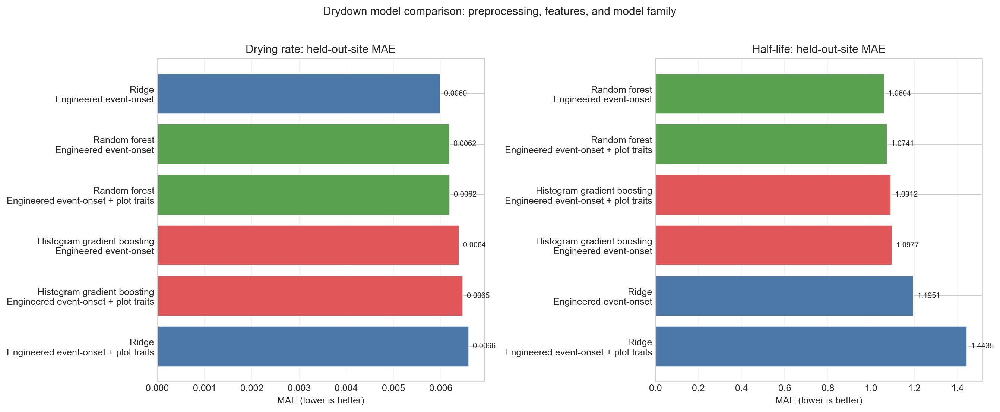

**soil_moisture/soil_K_plot_summary_trait_links.png**

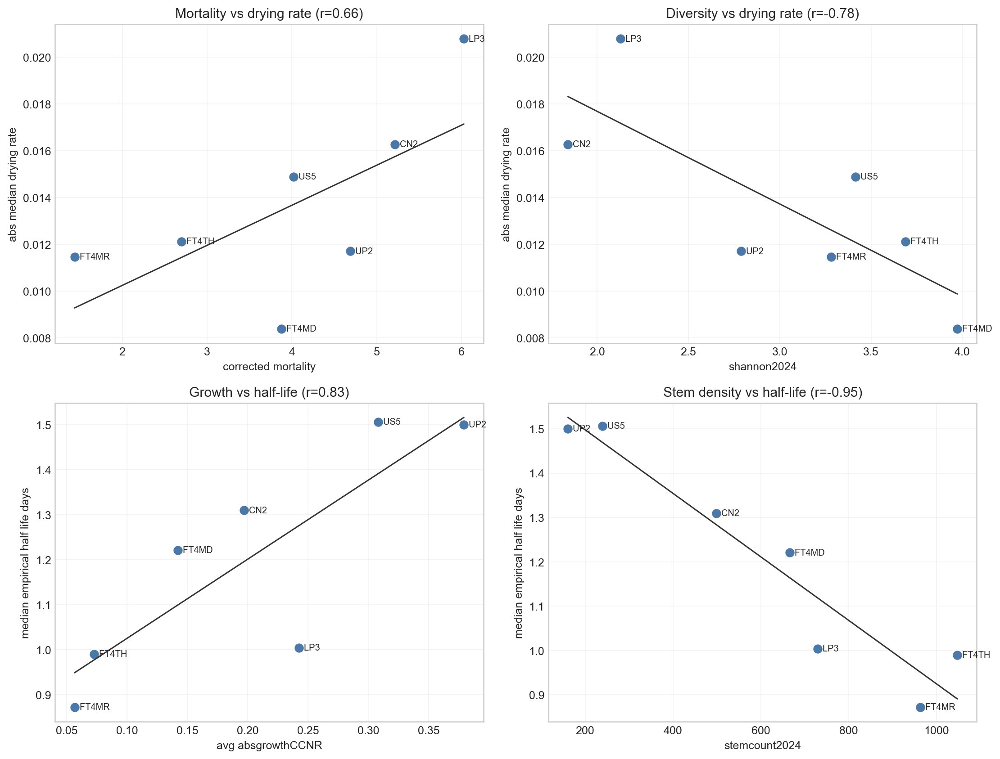

**soil_moisture/soil_L_logo_permutation_importance.png**

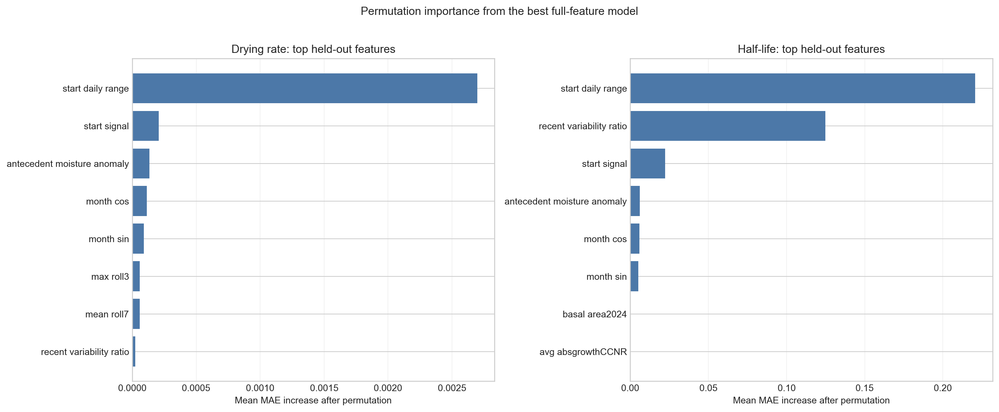

**temperature/temperature_B_daily_range_faceted.png**

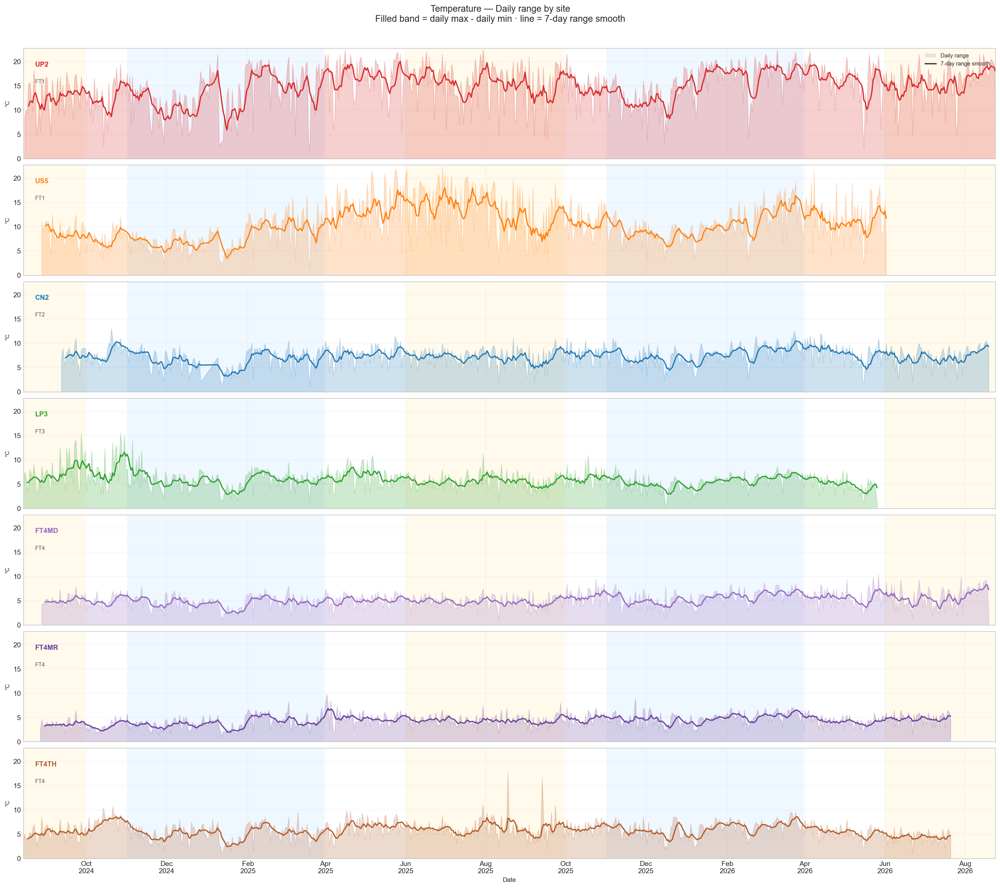

**temperature/temperature_D_anomaly_shared.png**

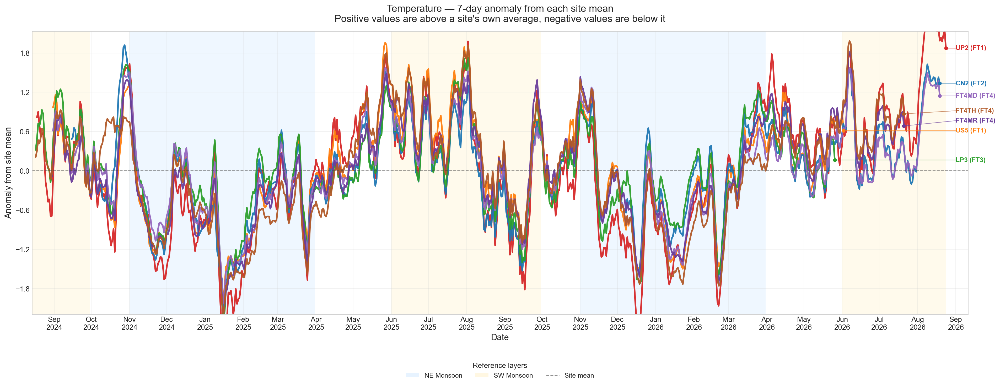

**vpd/vpd_B_daily_range_faceted.png**

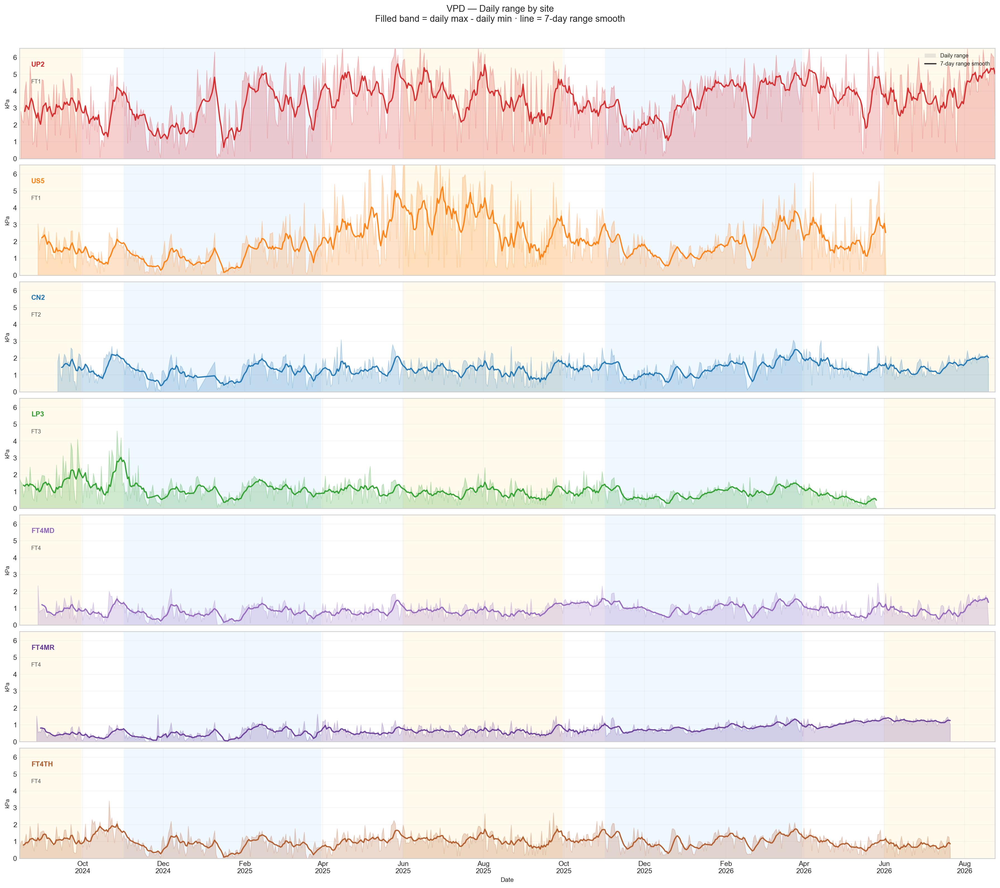

**vpd/vpd_D_anomaly_shared.png**

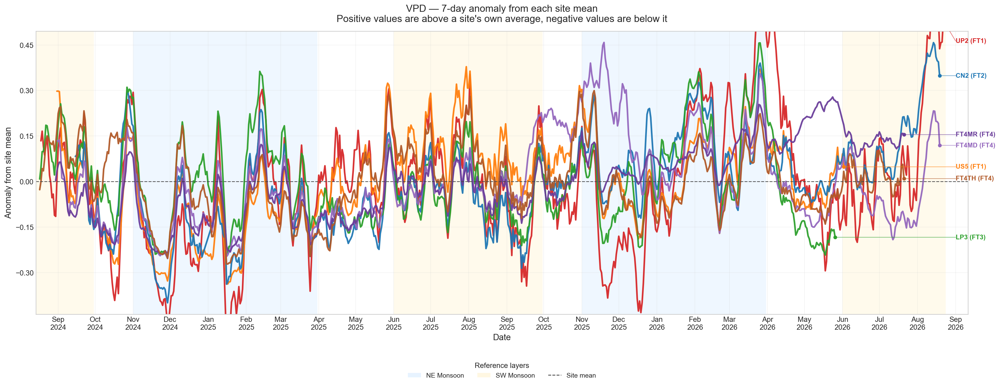

In [71]:
# Display each exported figure that is supplementary to the main narrative.
from IPython.display import Image, Markdown, display

supplementary_figures = ['par/par_B_daily_range_faceted.png', 'par/par_D_anomaly_shared.png', 'quality/screening_sensitivity_daily_means.png', 'readiness/daily_relationship_scatter.png', 'readiness/daily_spearman_heatmap.png', 'rh/rh_B_daily_range_faceted.png', 'rh/rh_D_anomaly_shared.png', 'soil/soil_B_daily_range_faceted.png', 'soil/soil_D_anomaly_shared.png', 'soil_moisture/soil_J_plot_summary_model_comparison.png', 'soil_moisture/soil_K_plot_summary_trait_links.png', 'soil_moisture/soil_L_logo_permutation_importance.png', 'temperature/temperature_B_daily_range_faceted.png', 'temperature/temperature_D_anomaly_shared.png', 'vpd/vpd_B_daily_range_faceted.png', 'vpd/vpd_D_anomaly_shared.png']
for relative_path in supplementary_figures:
    figure_path = Path(OUT_ROOT) / relative_path
    if not figure_path.exists():
        raise FileNotFoundError(f'Supplementary figure is missing: {figure_path}')
    display(Markdown(f'**{relative_path}**'))
    display(Image(filename=str(figure_path)))